# Практические работы № 8–9. Прогнозирование финансовых временных рядов

**Дисциплина:** Анализ данных и машинное обучение (АДиМО).

**Команда:** № 2.

**Финансовый инструмент:** EUR/USD.

## 0. Приёмка и проверка исходных данных

### 0.1. Ответственный за подготовку данных

**Александр Васильев** — сбор исторических котировок,
преобразование H1 в D1, контроль качества данных
и документирование принятых решений.

Результаты данного этапа переданы ответственному за
построение прогнозного решения Владимиру Павлову.

### 0.2. Выполненная работа

Источником исходных котировок выбран Dukascopy.

Выгрузка выполнена через инструмент `dukascopy-node`.

Список используемых параметров:

- Инструмент: EUR/USD.
- Тип котировки: Bid.
- Исходная частота: H1.
- Итоговая частота: D1.
- Часовой пояс исходных меток: UTC.
- Граница торгового дня: 17:00 America/New_York.
- Период выгрузки: 01.10.2025–01.10.2026.

Дневные свечи сформированы путём агрегации
часовых наблюдений с учётом торговой сессии
и переходов на летнее и зимнее время.

Правила агрегации:

$$
Open_d=Open_{\mathrm{first\ H1}},
$$

$$
High_d=\max_{t\in d}High_t,
$$

$$
Low_d=\min_{t\in d}Low_t,
$$

$$
Close_d=Close_{\mathrm{last\ H1}}.
$$

Из результата исключены неполные крайние сессии
и праздничная запись 01.01.2026.

Исходные данные сохранены отдельно
от подготовленного дневного ряда.

### 0.3. Переданные материалы

1. `eurusd-h1-bid-2025-10-01-2026-10-01.csv` — исходные часовые котировки.
2. `eurusd_d1_bid_final.csv` — подготовленный дневной набор.
3. `prepare_eurusd.py` — воспроизводимый алгоритм агрегации.
4. `eurusd_d1_bid_паспорт_данных.docx` — описание источника, процедур и решений.

### 0.4. Результаты независимого аудита

Исходный набор содержит 8700 часовых записей. Итоговый набор содержит 259 торговых дней за период с 02.10.2025 по 30.09.2026.

Подтвержденые для итогового набора факты:

- отсутствие пропущенных значений;
- отсутствие дублирующихся дат;
- отсутствие дат субботы и воскресенья;
- отсутствие нарушений согласованности OHLC;
- наличие 24 часовых записей в каждой сохранённой сессии;
- непрерывность часовых меток внутри сохранённых сессий;
- отсутствие полностью плоских дневных свечей.

Отдельно выполнена независимая агрегация исходного H1 и запуск переданного скрипта.

**Числовые значения всех 259 дневных записей совпали.**

### 0.5. Замечания и ограничения

Во-первых, количество часовых записей
не является непосредственной мерой торговой активности.

Во-вторых, исключение праздничного дня
является документированным решением предобработки.

В-третьих, точная дата выдачи задания
не представлена в переданных материалах,
поэтому соответствие выбранного периода
формулировке «последние 12 месяцев
на дату выдачи задания» требует подтверждения.

В-четвёртых, отдельные числовые движения курса
не следует автоматически считать ошибками данных.

Наконец, итоговый набор является результатом
собственной H1-агрегации, а не исходным D1-экспортом.

### 0.6. Решение о приёмке

**Результат этапа 1 принят для построения
прогнозных моделей.**

Структурные ошибки и противоречия
в процедуре агрегации не выявлены.

Обнаруженные ограничения подлежат документированию,
но не препятствуют использованию `eurusd_d1_bid_final.csv`
в последующем исследовании.

## 1. Постановка задачи прогнозирования EUR/USD

### 1.1. Цель исследования

Проведение сравнительного исследования методов прогнозирования дневной цены закрытия EUR/USD на горизонтах 1 и 5 торговых дней. В процессе исследования необходимо определить, действительно ли сложные методы обеспечивают
статистически и практически значимое улучшение относительно наивного прогноза.

### 1.2. Исходные данные

Используется подготовленный набор `eurusd_final.csv`.

Основная целевая переменная — $C_t=Close_t$, где $t$ — номер торгового дня.

Дата обозначает торговую сессию, заканчивающуюся
в 17:00 по времени Нью-Йорка.

В исследовании задействованы только исторические наблюдения,
известные к моменту формирования прогноза.

### 1.3. Горизонты прогнозирования

Для горизонта 1 торговый день:

$$
\hat C_{t+1}=f_1(\mathcal H_t).
$$

Для горизонта 5 торговых дней:

$$
\hat C_{t+5}=f_5(\mathcal H_t).
$$

Здесь $\mathcal H_t$ — вся разрешённая историческая информация до конца сессии $t$. Прогноз формируется после закрытия сессии $t$. Таким образом, признаки текущего дня могут использовать его Open, High, Low и Close, но не показатели будущих торговых дней.

### 1.4. Сравниваемые семейства методов

В ходе исследования задействовано 4 подхода:

1. Наивный прогноз (Persistence).
2. Классический статистический метод (ARIMA).
3. Метод машинного обучения (Gradient Boosting).
4. Нейросетевой метод (компактная GRU или LSTM).

Окончательная конфигурация моделей
будет обоснована после разведочного анализа данных.

### 1.5. Метрики качества

**Mean Absolute Error:**

$$
MAE=\frac{1}{N}\sum_{i=1}^{N}
|y_i-\hat y_i|.
$$

**Root Mean Squared Error:**

$$
RMSE=
\sqrt{
\frac{1}{N}\sum_{i=1}^{N}
(y_i-\hat y_i)^2
}.
$$

**Symmetric Mean Absolute Percentage Error:**

$$
sMAPE=
\frac{100}{N}\sum_{i=1}^{N}
\frac{2|y_i-\hat y_i|}
{|y_i|+|\hat y_i|}.
$$

**Точность прогнозирования направления:**

$$
DA_h=
\frac{1}{N}
\sum_{i=1}^{N}
\mathbb{I}
\left[
\operatorname{sign}(\hat C_{t+h}-C_t)
=
\operatorname{sign}(C_{t+h}-C_t)
\right].
$$

Обработка нулевого прогнозируемого изменения
для наивного метода будет определена
единым правилом до расчёта метрик.

### 1.6. Исследовательские гипотезы

**H1.** Методы машинного обучения могут улучшить
прогноз относительно наивного подхода.

**H2.** Увеличение горизонта с одного
до пяти торговых дней изменяет качество прогноза.

**H3.** Увеличение сложности модели
не гарантирует улучшение точности
на ограниченном годовом наборе данных.

**H4.** Результаты зависят от временного периода
проверки и могут быть неустойчивыми.

Данные гипотезы подлежат экспериментальной проверке,
а не принимаются заранее как истинные.

### 1.7. Требования к вычислительному эксперименту

- Хронологическое разделение данных.
- Единые контрольные даты для всех моделей.
- Отсутствие утечек будущей информации.
- Подбор гиперпараметров только по обучению
  и валидационным периодам.
- Отдельная оценка для горизонтов 1 и 5 дней.
- Сравнение всех моделей с наивным прогнозом.
- Анализ устойчивости и вычислительных затрат.
- Обоснование результатов и ограничений.

Основной результат — воспроизводимый Google Collaboratory-ноутбук
с таблицами, графиками и комплексным аналитическим выводом.

In [ ]:
# ============================================================
# БЛОК 2. ИМПОРТ ОСНОВНЫХ БИБЛИОТЕК
# ============================================================

# Импорт класса Path для универсальной работы с каталогами и файлами.
from pathlib import Path

# Импорт модуля os для чтения переменных окружения.
import os

# Импорт библиотеки NumPy для численных вычислений.
import numpy as np

# Импорт библиотеки Pandas для обработки финансовых временных рядов.
import pandas as pd

# Импорт Matplotlib для построения исследовательских графиков.
import matplotlib.pyplot as plt

# Импорт Seaborn для статистической визуализации.
import seaborn as sns

# Импорт display и Markdown для оформления результатов в Google Colab.
from IPython.display import display, Markdown


# Определение общего значения random_state для воспроизводимости.
RANDOM_STATE = 42


# Установка формата отображения чисел в таблицах.
pd.options.display.float_format = "{:.6f}".format


# Определение базовых параметров визуализации.
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


# Вывод версий основных библиотек.
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


# Вывод сообщения об успешной инициализации.
print("Базовые библиотеки успешно импортированы.")

NumPy: 2.4.6
Pandas: 2.2.3
Базовые библиотеки успешно импортированы.


In [ ]:
# ============================================================
# БЛОК 3. УНИВЕРСАЛЬНОЕ ПОДКЛЮЧЕНИЕ EUR/USD DATASET
# ============================================================

# Импорт класса Path для независимой от операционной системы работы с путями.
from pathlib import Path

# Импорт модуля os для чтения необязательного пути из переменной окружения.
import os


# Определение относительного пути к подготовленному датасету внутри репозитория.
DATASET_RELATIVE_PATH = Path("data") / "eurusd_d1_bid_final.csv"

# Определение точного имени итогового набора данных.
DATASET_FILENAME = DATASET_RELATIVE_PATH.name

# Определение рабочего каталога Jupyter/VS Code/Google Colab.
LOCAL_DIRECTORY = Path.cwd().resolve()

# Определение стандартного имени папки репозитория после распаковки архива.
# Название служит только подсказкой: после переименования поиск также работает из папки проекта.
REPOSITORY_DIRECTORY_NAME = "ПР 8-9"

# Определение корня Google Drive без зависимости от структуры личных папок преподавателя.
GOOGLE_DRIVE_SEARCH_DIRECTORY = Path("/content/drive/MyDrive")

# Определение необязательной пользовательской папки проекта или data либо полного пути CSV.
# Значение None обеспечивает автоматический поиск в стандартных сценариях.
CUSTOM_DATA_DIRECTORY = None

# Получение необязательного каталога из переменной окружения EURUSD_PROJECT_DIRECTORY.
ENVIRONMENT_PROJECT_DIRECTORY = os.environ.get("EURUSD_PROJECT_DIRECTORY")


# Определение функции выбора корректного CSV из конкретной папки или файлового пути.
def resolve_dataset_from_location(location):

    # Преобразование пользовательского значения в абсолютный путь.
    location_path = Path(location).expanduser().resolve()

    # Если указали именно CSV, то проверяем его имя и существование.
    if location_path.is_file():

        # Возврат файла, только когда имя соответствует согласованному датасету.
        return location_path if location_path.name == DATASET_FILENAME else None

    # Если указанный каталог отсутствует, то файл найти невозможно.
    if not location_path.is_dir():

        # Возврат признака отсутствия подходящего датасета.
        return None

    # Формирование двух вариантов: путь к корню проекта и путь к папке data.
    expected_paths = [
        location_path / DATASET_RELATIVE_PATH,
        location_path / DATASET_FILENAME,
    ]

    # Последовательная проверка только двух ожидаемых вариантов без глобального обхода.
    for expected_path in expected_paths:

        # Если ожидаемый файл присутствует, то возвращаем его абсолютный путь.
        if expected_path.is_file():

            # Возврат найденного CSV.
            return expected_path.resolve()

    # Возврат отсутствующего результата при неподходящей структуре папки.
    return None


# Создание списка мест, в которых найден подходящий файл.
dataset_candidates = []

# Создание списка уже проверенных директорий для устранения повторного поиска.
checked_directories = set()

# Формирование приоритетного списка явных путей, если они заданы пользователем.
explicit_locations = [
    location
    for location in [CUSTOM_DATA_DIRECTORY, ENVIRONMENT_PROJECT_DIRECTORY]
    if location is not None and str(location).strip()
]

# Последовательная проверка явных пользовательских настроек до автоматического поиска.
for explicit_location in explicit_locations:

    # Проверка наличия CSV в явно указанном местоположении.
    explicit_dataset_path = resolve_dataset_from_location(explicit_location)

    # Если путь задан некорректно, то не подменяем его скрытым автоматическим выбором.
    if explicit_dataset_path is None:

        # Формирование диагностического исключения с указанным пользователем путём.
        raise FileNotFoundError(
            f"В явно указанном пути не найден {DATASET_RELATIVE_PATH}: "
            f"{explicit_location}"
        )

    # Сохранение однозначно найденного файла из явной настройки.
    dataset_candidates.append(explicit_dataset_path)

# Если пользователь не указал путь, то ищем проект рядом с рабочим каталогом.
if not dataset_candidates:

    # Формирование последовательности: текущая папка и все её родители.
    local_ancestors = [LOCAL_DIRECTORY, *LOCAL_DIRECTORY.parents]

    # Последовательный поиск без сканирования всего диска C или D.
    for ancestor_directory in local_ancestors:

        # Формирование альтернатив для открытого репозитория и его родительской папки.
        nearby_locations = [
            ancestor_directory,
            ancestor_directory / REPOSITORY_DIRECTORY_NAME,
        ]

        # Проверка обоих расположений проекта.
        for nearby_location in nearby_locations:

            # Разрешение пути для удаления дублей при поиске.
            resolved_location = nearby_location.resolve()

            # Если директория уже проверялась, то повторная проверка не требуется.
            if resolved_location in checked_directories:

                # Переход к следующему кандидату.
                continue

            # Запоминание ранее рассмотренного пути.
            checked_directories.add(resolved_location)

            # Поиск только по фиксированной структуре проекта data/CSV.
            nearby_dataset_path = resolve_dataset_from_location(resolved_location)

            # Если файл найден, то дальнейший обход родительских каталогов не нужен.
            if nearby_dataset_path is not None:

                # Добавление найденного CSV.
                dataset_candidates.append(nearby_dataset_path)

        # Если путь определён на текущем уровне, то останавливаем поиск по родителям.
        if dataset_candidates:

            # Выход из цикла по родительским папкам.
            break

# Если локальный поиск неуспешен, то пробуем получить доступ к Google Drive.
if not dataset_candidates:

    # Проверка наличия модуля Google Colab в текущей среде.
    try:

        # Импорт штатного механизма подключения Google Drive в Colab.
        from google.colab import drive

    # Если запущен локальный Python/VS Code, то переходить к Google Drive не нужно.
    except ModuleNotFoundError:

        # Пропуск подключения, недоступного в локальном Jupyter.
        pass

    # Если среда Google Colab обнаружена, то подключаем пользовательский диск.
    else:

        # Монтирование Google Drive с подтверждением пользователя при необходимости.
        drive.mount("/content/drive")

        # Проверка существования пользовательского диска после монтирования.
        if GOOGLE_DRIVE_SEARCH_DIRECTORY.is_dir():

            # Поиск CSV во вложенных папках независимо от расположения архива на Drive.
            for drive_dataset_path in GOOGLE_DRIVE_SEARCH_DIRECTORY.rglob(DATASET_FILENAME):

                # Принимаем только файл из каталога с точным именем data.
                if drive_dataset_path.is_file() and drive_dataset_path.parent.name == "data":

                    # Получение корня проекта из стандартной структуры data/CSV.
                    candidate_project_directory = drive_dataset_path.parent.parent

                    # Проверка наличия папки notebooks, подтверждающей принадлежность проекту.
                    if (candidate_project_directory / "notebooks").is_dir():

                        # Сохранение подходящего файла без дублирования путей.
                        dataset_candidates.append(drive_dataset_path.resolve())

# Удаление повторений, которые могут возникнуть из эквивалентных путей.
dataset_candidates = sorted(set(dataset_candidates))

# Если CSV не обнаружен, то прекращаем выполнение с объяснением возможных причин.
if not dataset_candidates:

    # Генерация ошибки, позволяющей пользователю выбрать явный путь.
    raise FileNotFoundError(
        f"Не найден файл {DATASET_RELATIVE_PATH}.\n"
        f"Текущий рабочий каталог: {LOCAL_DIRECTORY}\n"
        f"Корень Google Drive: {GOOGLE_DRIVE_SEARCH_DIRECTORY}\n"
        "Откройте папку распакованного репозитория в VS Code; "
        "в Colab подключите Google Drive и убедитесь, что на нём есть папка data; "
        "либо укажите CUSTOM_DATA_DIRECTORY / EURUSD_PROJECT_DIRECTORY."
    )

# Если на Google Drive лежит несколько копий репозитория, то не выбираем CSV произвольно.
if len(dataset_candidates) > 1:

    # Генерация сообщения о неоднозначности, чтобы исключить незаметную подмену данных.
    raise RuntimeError(
        "Найдено несколько копий датасета:\n"
        + "\n".join(str(candidate) for candidate in dataset_candidates)
        + "\nУкажите точный путь через CUSTOM_DATA_DIRECTORY."
    )

# Получение абсолютного пути к однозначно выбранному CSV.
dataset_path = dataset_candidates[0]

# Получение корня репозитория: каталог, содержащий папки data и notebooks.
project_directory = dataset_path.parent.parent

# Определение каталога ноутбуков, используемого в блоке экспорта подробного паспорта.
notebook_directory = project_directory / "notebooks"

# Определение существующего каталога итоговых отчётов.
research_results_directory = project_directory / "results"

# Проверка размещения исходного набора в каталоге data.
assert dataset_path.parent.name == "data", "Нарушена структура проекта data/<CSV>."

# Проверка наличия папки с исполняемым ноутбуком.
assert notebook_directory.is_dir(), "Не найдена папка notebooks в корне проекта."

# Чтение исходного подготовленного дневного набора без изменения кодировки CSV.
df_raw = pd.read_csv(dataset_path, encoding="utf-8-sig")

# Вывод абсолютного пути к найденному файлу, полезного для проверки воспроизводимости.
print("Источник:", dataset_path)

# Вывод абсолютного пути к корню распакованного репозитория.
print("Каталог проекта:", project_directory)

# Вывод размерности подготовленной таблицы.
print("Размерность:", df_raw.shape)

# Вывод имён столбцов исходного набора.
print("Столбцы:", df_raw.columns.tolist())

# Отображение первых пяти наблюдений для первичного контроля импорта.
display(df_raw.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Источник: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/data/eurusd_d1_bid_final.csv
Каталог проекта: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9
Размерность: (259, 7)
Столбцы: ['date', 'open', 'high', 'low', 'close', 'hourly_bars', 'quality_flag']


,date,open,high,low,close,hourly_bars,quality_flag
0,2025-10-02,1.172680,1.175830,1.168290,1.171540,24,complete
1,2025-10-03,1.171540,1.175910,1.171300,1.173820,24,complete
2,2025-10-06,1.172090,1.173070,1.165160,1.171040,24,complete
3,2025-10-07,1.171040,1.171440,1.164740,1.165630,24,complete
4,2025-10-08,1.165590,1.166100,1.159830,1.162740,24,complete


In [ ]:
# ============================================================
# БЛОК 4. АВТОМАТИЗИРОВАННЫЙ АУДИТ EUR/USD D1 BID
# ============================================================

# Определение ожидаемой схемы подготовленного набора.
EXPECTED_COLUMNS = [
    "date",
    "open",
    "high",
    "low",
    "close",
    "hourly_bars",
    "quality_flag"
]


# Определение количественных рыночных характеристик.
PRICE_COLUMNS = [
    "open",
    "high",
    "low",
    "close"
]


# Проверка исходного состава столбцов.
if df_raw.columns.tolist() != EXPECTED_COLUMNS:

    # Генерация исключения при неожиданной структуре CSV.
    raise ValueError(
        "Структура CSV не соответствует согласованному паспорту.\n"
        f"Ожидалось: {EXPECTED_COLUMNS}\n"
        f"Получено: {df_raw.columns.tolist()}"
    )


# Создание рабочей копии без изменения исходных данных.
df = df_raw.copy()


# Преобразование строковых дат в тип datetime.
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m-%d",
    errors="coerce"
)


# Последовательное преобразование ценовых характеристик.
for column_name in PRICE_COLUMNS:

    # Преобразование текущего столбца в числовой тип.
    df[column_name] = pd.to_numeric(
        df[column_name],
        errors="coerce"
    )


# Преобразование количества часовых записей в числовой тип.
df["hourly_bars"] = pd.to_numeric(
    df["hourly_bars"],
    errors="coerce"
)


# Нормализация текстовых значений служебного флага.
df["quality_flag"] = (
    df["quality_flag"]
    .astype("string")
    .str.strip()
)


# ============================================================
# 1. ПРОВЕРКА ВРЕМЕННОГО ИНДЕКСА
# ============================================================

# Подсчёт некорректных дат.
invalid_date_count = int(
    df["date"].isna().sum()
)


# Подсчёт повторяющихся дат.
duplicate_date_count = int(
    df["date"].duplicated().sum()
)


# Проверка исходного хронологического порядка.
dates_are_sorted = bool(
    df["date"].is_monotonic_increasing
)


# Подсчёт записей, приходящихся на субботу или воскресенье.
weekend_count = int(
    (df["date"].dt.dayofweek >= 5).sum()
)


# ============================================================
# 2. ПРОВЕРКА ЦЕНОВЫХ ПОЛЕЙ
# ============================================================

# Подсчёт всех отсутствующих значений.
missing_value_count = int(
    df.isna().sum().sum()
)


# Проверка конечности числовых значений OHLC.
finite_prices = bool(
    np.isfinite(
        df[PRICE_COLUMNS].to_numpy(dtype=float)
    ).all()
)


# Проверка положительности всех ценовых значений.
positive_prices = bool(
    df[PRICE_COLUMNS].gt(0).all().all()
)


# Проверка, что High не меньше остальных цен свечи.
valid_high = df["high"].ge(
    df[["open", "close", "low"]].max(axis=1)
)


# Проверка, что Low не больше остальных цен свечи.
valid_low = df["low"].le(
    df[["open", "close", "high"]].min(axis=1)
)


# Подсчёт нарушений структуры OHLC.
ohlc_violation_count = int(
    (~(valid_high & valid_low)).sum()
)


# Подсчёт дневных свечей без какого-либо изменения цены.
flat_candle_count = int(
    df[PRICE_COLUMNS].nunique(axis=1).eq(1).sum()
)


# ============================================================
# 3. ПРОВЕРКА СЛУЖЕБНЫХ ПОЛЕЙ
# ============================================================

# Подсчёт строк с количеством H1, отличным от 24.
invalid_hourly_bar_count = int(
    df["hourly_bars"].ne(24).sum()
)


# Подсчёт строк с флагом, отличным от complete.
invalid_quality_flag_count = int(
    df["quality_flag"].ne("complete").sum()
)


# ============================================================
# 4. ФОРМИРОВАНИЕ ТАБЛИЦЫ КОНТРОЛЬНЫХ ПРОВЕРОК
# ============================================================

# Создание перечня независимых контрольных условий.
audit_checks = [
    ("Количество наблюдений = 259", len(df) == 259),
    ("Корректные даты", invalid_date_count == 0),
    ("Отсутствие дубликатов дат", duplicate_date_count == 0),
    ("Хронологический порядок", dates_are_sorted),
    ("Отсутствие выходных", weekend_count == 0),
    ("Отсутствие пропусков", missing_value_count == 0),
    ("Конечные числовые значения", finite_prices),
    ("Положительные котировки", positive_prices),
    ("Корректные соотношения OHLC", ohlc_violation_count == 0),
    ("Отсутствие полностью плоских D1", flat_candle_count == 0),
    ("24 записи H1 в каждой D1", invalid_hourly_bar_count == 0),
    ("Все флаги качества complete", invalid_quality_flag_count == 0)
]


# Формирование итоговой таблицы контрольных проверок.
data_audit_table = pd.DataFrame(
    audit_checks,
    columns=[
        "Контрольный критерий",
        "Условие выполнено"
    ]
)


# Вывод таблицы приёмки данных.
print("Повторный аудит подготовленного дневного набора:")
display(
    data_audit_table
)


# ============================================================
# 5. ДОПОЛНИТЕЛЬНАЯ ХАРАКТЕРИСТИКА ВРЕМЕННОГО РЯДА
# ============================================================

# Формирование перечня рабочих дней между границами набора.
calendar_weekdays = pd.bdate_range(
    start=df["date"].min(),
    end=df["date"].max()
)


# Определение отсутствующих дат среди понедельников–пятниц.
missing_weekdays = calendar_weekdays.difference(
    pd.DatetimeIndex(df["date"])
)


# Вывод диапазона наблюдений.
print(
    "Период:",
    df["date"].min().date(),
    "—",
    df["date"].max().date()
)


# Вывод числа наблюдений.
print(
    "Количество торговых дней:",
    len(df)
)


# Вывод будних дат, отсутствующих в итоговом наборе.
print(
    "Отсутствующие будние даты:",
    missing_weekdays.strftime("%Y-%m-%d").tolist()
)


# Вывод диапазона котировок.
print(
    "Минимальный Low:",
    round(df["low"].min(), 5)
)

print(
    "Максимальный High:",
    round(df["high"].max(), 5)
)


# ============================================================
# 6. ИТОГОВАЯ ПРОВЕРКА ГОТОВНОСТИ
# ============================================================

# Определение критериев, которые не были выполнены.
failed_checks = data_audit_table.loc[
    ~data_audit_table["Условие выполнено"],
    "Контрольный критерий"
].tolist()


# Если обнаружены нарушения, то останавливаем исследование.
if failed_checks:

    # Генерация ошибки с перечислением выявленных нарушений.
    raise AssertionError(
        "Датасет не прошёл аудит:\n"
        +
        "\n".join(failed_checks)
    )


# Установка даты в качестве временного индекса после успешных проверок.
df = df.set_index(
    "date"
)


# Создание отдельного DataFrame с рыночными характеристиками.
market_data = df[
    PRICE_COLUMNS
].copy()


# Вывод сообщения о готовности набора к исследованию.
print(
    "\nАудит успешно завершён. "
    "Дневной ряд EUR/USD готов к разведочному анализу."
)


# Вывод первых строк подготовленных котировок.
display(
    market_data.head()
)

Повторный аудит подготовленного дневного набора:


,Контрольный критерий,Условие выполнено
0,Количество наблюдений = 259,True
1,Корректные даты,True
2,Отсутствие дубликатов дат,True
3,Хронологический порядок,True
4,Отсутствие выходных,True
5,Отсутствие пропусков,True
6,Конечные числовые значения,True
7,Положительные котировки,True
8,Корректные соотношения OHLC,True
9,Отсутствие полностью плоских D1,True


Период: 2025-10-02 — 2026-09-30
Количество торговых дней: 259
Отсутствующие будние даты: ['2026-01-01']
Минимальный Low: 1.13118
Максимальный High: 1.20822

Аудит успешно завершён. Дневной ряд EUR/USD готов к разведочному анализу.


,open,high,low,close
date,,,,
2025-10-02,1.172680,1.175830,1.168290,1.171540
2025-10-03,1.171540,1.175910,1.171300,1.173820
2025-10-06,1.172090,1.173070,1.165160,1.171040
2025-10-07,1.171040,1.171440,1.164740,1.165630
2025-10-08,1.165590,1.166100,1.159830,1.162740


## 2. Разведочный анализ финансового временного ряда

### 2.1. Цель EDA

Разведочный анализ (Exploratory Data Analysis, EDA)
предназначен для исследования статистических и временных
характеристик дневного ряда EUR/USD.

Основные направления анализа:

1. Изменение абсолютного уровня курса.
2. Распределение дневных доходностей.
3. Изменчивость курса и оценка волатильности.
4. Выявление значительных однодневных движений.
5. Автокорреляционные зависимости.
6. Предварительная оценка свойств ряда,
   важных для последующего прогнозирования.

### 2.2. Простая дневная доходность

Для последовательных торговых дней:

$$
r_t=\frac{C_t-C_{t-1}}{C_{t-1}}.
$$

Здесь $C_t$ — цена закрытия EUR/USD.

Простая доходность характеризует относительное
изменение курса между двумя соседними
доступными торговыми наблюдениями.

### 2.3. Логарифмическая доходность

$$
g_t=\ln\left(\frac{C_t}{C_{t-1}}\right)
=\ln(C_t)-\ln(C_{t-1}).
$$

Логарифмические доходности обладают свойством
аддитивности по времени:

$$
\sum_{i=1}^{h}g_{t+i}
=
\ln\left(\frac{C_{t+h}}{C_t}\right).
$$

Данный факт делает их удобными для анализа
финансовых временных рядов.

### 2.4. Дневной ценовой диапазон

Абсолютный диапазон дневной свечи:

$$
R_t=High_t-Low_t.
$$

Относительный диапазон:

$$
R_t^{(\%)}=
\frac{High_t-Low_t}{Open_t}\cdot100\%.
$$

Данный показатель описывает внутрисессионную
амплитуду изменения котировки. Он не является прямой заменой
реализованной высокочастотной волатильности.

### 2.5. Скользящие характеристики

Скользящая средняя цены закрытия:

$$
SMA_t^{(w)}=
\frac1w\sum_{i=0}^{w-1}C_{t-i}.
$$

Скользящая оценка годовой волатильности:

$$
\sigma_{t,ann}^{(w)}
=
\operatorname{Std}
(g_{t-w+1},\ldots,g_t)\sqrt{252}.
$$

Здесь число 252 — стандартное приближение
количества торговых дней в году.

В работе рассматривается окно
из 20 торговых наблюдений.

### 2.6. Ограничения интерпретации

Разведочный анализ описывает исторические
наблюдения и сам по себе не доказывает
наличие прогнозируемой закономерности.

Необычно большие доходности не удаляются
без подтверждения ошибки исходных котировок.

Все скользящие характеристики вычисляются
только по текущему и предшествующим наблюдениям.

При построении моделей статистические
преобразования будут настраиваться
исключительно по обучающей части.

Финальный тестовый период нельзя использовать
для подбора гиперпараметров или выбора
наиболее выгодной конфигурации модели.

In [ ]:
# ============================================================
# БЛОК 5. ФОРМИРОВАНИЕ АНАЛИТИЧЕСКИХ ХАРАКТЕРИСТИК EUR/USD
# ============================================================

# Создание независимой копии рыночных данных для EDA.
eda_data = market_data.copy()


# Определение стандартного окна краткосрочного анализа.
SHORT_WINDOW = 20


# Определение окна среднесрочного анализа динамики курса.
LONG_WINDOW = 60


# Определение условного количества торговых дней в году.
TRADING_DAYS_PER_YEAR = 252


# Проверка положительности цен закрытия перед логарифмированием.
assert eda_data["close"].gt(0).all(), (
    "Цена закрытия должна быть положительной."
)


# Расчёт простой дневной доходности в долях единицы.
eda_data["simple_return"] = (
    eda_data["close"]
    .div(eda_data["close"].shift(1))
    .sub(1.0)
)


# Расчёт логарифмической дневной доходности.
eda_data["log_return"] = (
    np.log(eda_data["close"]).diff()
)


# Расчёт изменения цены закрытия в единицах котировки.
eda_data["close_change"] = (
    eda_data["close"].diff()
)


# Расчёт абсолютного внутридневного диапазона.
eda_data["daily_range"] = (
    eda_data["high"] - eda_data["low"]
)


# Расчёт относительного внутридневного диапазона в процентах.
eda_data["daily_range_pct"] = (
    eda_data["daily_range"]
    .div(eda_data["open"])
    .mul(100.0)
)


# Расчёт абсолютной величины логарифмической доходности.
eda_data["abs_log_return"] = (
    eda_data["log_return"].abs()
)


# Расчёт 20-дневной скользящей средней цены закрытия.
eda_data["sma_20"] = (
    eda_data["close"]
    .rolling(
        window=SHORT_WINDOW,
        min_periods=SHORT_WINDOW
    )
    .mean()
)


# Расчёт 60-дневной скользящей средней цены закрытия.
eda_data["sma_60"] = (
    eda_data["close"]
    .rolling(
        window=LONG_WINDOW,
        min_periods=LONG_WINDOW
    )
    .mean()
)


# Расчёт 20-дневного скользящего стандартного отклонения доходностей.
eda_data["rolling_volatility_20"] = (
    eda_data["log_return"]
    .rolling(
        window=SHORT_WINDOW,
        min_periods=SHORT_WINDOW
    )
    .std()
)


# Годовая нормировка скользящей волатильности в процентах.
eda_data["rolling_volatility_annual_pct"] = (
    eda_data["rolling_volatility_20"]
    .mul(np.sqrt(TRADING_DAYS_PER_YEAR))
    .mul(100.0)
)


# Проверка неизменности количества исходных наблюдений.
assert len(eda_data) == len(market_data)


# Проверка ожидаемых пропусков первой доходности.
assert eda_data["log_return"].isna().sum() == 1


# Проверка отсутствия неожиданных бесконечных значений.
assert np.isfinite(
    eda_data["log_return"].dropna()
).all()


# Вывод размерности аналитической таблицы.
print("Размер аналитического набора:", eda_data.shape)


# Вывод количества наблюдений с рассчитанной доходностью.
print(
    "Количество дневных доходностей:",
    eda_data["log_return"].notna().sum()
)


# Вывод первых строк аналитического набора.
display(
    eda_data.head(8).round(6)
)


# Вывод последних строк аналитического набора.
display(
    eda_data.tail(5).round(6)
)

Размер аналитического набора: (259, 14)
Количество дневных доходностей: 258


,open,high,low,close,simple_return,log_return,close_change,daily_range,daily_range_pct,abs_log_return,sma_20,sma_60,rolling_volatility_20,rolling_volatility_annual_pct
date,,,,,,,,,,,,,,
2025-10-02,1.172680,1.175830,1.168290,1.171540,NaN,NaN,NaN,0.007540,0.642972,NaN,NaN,NaN,NaN,NaN
2025-10-03,1.171540,1.175910,1.171300,1.173820,0.001946,0.001944,0.002280,0.004610,0.393499,0.001944,NaN,NaN,NaN,NaN
2025-10-06,1.172090,1.173070,1.165160,1.171040,-0.002368,-0.002371,-0.002780,0.007910,0.674863,0.002371,NaN,NaN,NaN,NaN
2025-10-07,1.171040,1.171440,1.164740,1.165630,-0.004620,-0.004631,-0.005410,0.006700,0.572141,0.004631,NaN,NaN,NaN,NaN
2025-10-08,1.165590,1.166100,1.159830,1.162740,-0.002479,-0.002482,-0.002890,0.006270,0.537925,0.002482,NaN,NaN,NaN,NaN
2025-10-09,1.162750,1.164800,1.154200,1.156350,-0.005496,-0.005511,-0.006390,0.010600,0.911632,0.005511,NaN,NaN,NaN,NaN
2025-10-10,1.156340,1.163050,1.155510,1.161490,0.004445,0.004435,0.005140,0.007540,0.652057,0.004435,NaN,NaN,NaN,NaN
2025-10-13,1.161380,1.162970,1.155740,1.156910,-0.003943,-0.003951,-0.004580,0.007230,0.622535,0.003951,NaN,NaN,NaN,NaN


,open,high,low,close,simple_return,log_return,close_change,daily_range,daily_range_pct,abs_log_return,sma_20,sma_60,rolling_volatility_20,rolling_volatility_annual_pct
date,,,,,,,,,,,,,,
2026-09-24,1.138120,1.139910,1.135900,1.137980,-0.000132,-0.000132,-0.000150,0.004010,0.352335,0.000132,1.154458,1.151682,0.002753,4.370779
2026-09-25,1.137970,1.141100,1.136820,1.139040,0.000931,0.000931,0.001060,0.004280,0.376108,0.000931,1.153496,1.151610,0.002545,4.040402
2026-09-28,1.138110,1.139120,1.135310,1.137030,-0.001765,-0.001766,-0.002010,0.003810,0.334766,0.001766,1.152262,1.151492,0.002388,3.791108
2026-09-29,1.137020,1.137400,1.131180,1.134140,-0.002542,-0.002545,-0.002890,0.006220,0.547044,0.002545,1.151006,1.151375,0.002399,3.808999
2026-09-30,1.134110,1.138030,1.132220,1.132900,-0.001093,-0.001094,-0.001240,0.005810,0.512296,0.001094,1.149712,1.151230,0.002394,3.799870


In [ ]:
# ============================================================
# БЛОК 6. ОПИСАТЕЛЬНАЯ СТАТИСТИКА ФИНАНСОВОГО РЯДА
# ============================================================

# Получение цены закрытия первого торгового наблюдения.
first_close = float(
    eda_data["close"].iloc[0]
)


# Получение цены закрытия последнего торгового наблюдения.
last_close = float(
    eda_data["close"].iloc[-1]
)


# Расчёт общего относительного изменения курса за период.
total_return_pct = (
    last_close / first_close - 1.0
) * 100.0


# Получение ряда простых доходностей без первого пропуска.
simple_returns = (
    eda_data["simple_return"].dropna()
)


# Получение ряда логарифмических доходностей.
log_returns = (
    eda_data["log_return"].dropna()
)


# Расчёт среднего значения простой дневной доходности.
mean_daily_return_pct = (
    float(simple_returns.mean()) * 100.0
)


# Расчёт стандартного отклонения простой дневной доходности.
std_daily_return_pct = (
    float(simple_returns.std()) * 100.0
)


# Расчёт условной годовой волатильности логарифмических доходностей.
annual_volatility_pct = (
    float(log_returns.std())
    * np.sqrt(TRADING_DAYS_PER_YEAR)
    * 100.0
)


# Формирование таблицы основных описательных показателей.
eda_statistics_table = pd.DataFrame(
    [
        ("Начальная цена Close", first_close, "USD за 1 EUR"),
        ("Конечная цена Close", last_close, "USD за 1 EUR"),
        ("Минимальная цена Close", eda_data["close"].min(), "USD за 1 EUR"),
        ("Максимальная цена Close", eda_data["close"].max(), "USD за 1 EUR"),
        ("Изменение Close за период", total_return_pct, "%"),
        ("Средняя дневная доходность", mean_daily_return_pct, "%"),
        ("Стандартное отклонение дневной доходности", std_daily_return_pct, "%"),
        ("Условная годовая волатильность", annual_volatility_pct, "%"),
        ("Средний дневной ценовой диапазон", eda_data["daily_range"].mean(), "USD за 1 EUR"),
        ("Средний относительный диапазон", eda_data["daily_range_pct"].mean(), "%")
    ],
    columns=[
        "Показатель",
        "Значение",
        "Единица измерения"
    ]
)


# Вывод таблицы ключевых статистических характеристик.
print("Основные статистические характеристики EUR/USD:")
display(
    eda_statistics_table.round(6)
)


# Расчёт квантилей дневных доходностей.
return_quantiles_table = (
    simple_returns
    .quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .mul(100.0)
    .to_frame("Доходность, %")
)


# Вывод таблицы квантилей доходности.
print("\nКвантили дневной доходности:")
display(
    return_quantiles_table.round(4)
)


# Подсчёт торговых дней с положительным изменением курса.
positive_return_days = int(
    simple_returns.gt(0).sum()
)


# Подсчёт торговых дней с отрицательным изменением курса.
negative_return_days = int(
    simple_returns.lt(0).sum()
)


# Подсчёт торговых дней с нулевым изменением курса.
zero_return_days = int(
    simple_returns.eq(0).sum()
)


# Формирование таблицы направлений исторических изменений.
return_direction_table = pd.DataFrame(
    {
        "Направление": [
            "Повышение курса",
            "Понижение курса",
            "Без изменения"
        ],
        "Количество": [
            positive_return_days,
            negative_return_days,
            zero_return_days
        ]
    }
)


# Расчёт относительной частоты направлений.
return_direction_table["Доля, %"] = (
    return_direction_table["Количество"]
    .div(len(simple_returns))
    .mul(100.0)
)


# Вывод распределения направлений.
print("\nРаспределение направлений изменения курса:")
display(
    return_direction_table.round(3)
)

Основные статистические характеристики EUR/USD:


,Показатель,Значение,Единица измерения
0,Начальная цена Close,1.171540,USD за 1 EUR
1,Конечная цена Close,1.132900,USD за 1 EUR
2,Минимальная цена Close,1.132900,USD за 1 EUR
3,Максимальная цена Close,1.203750,USD за 1 EUR
4,Изменение Close за период,-3.298223,%
5,Средняя дневная доходность,-0.012436,%
6,Стандартное отклонение дневной доходности,0.336013,%
7,Условная годовая волатильность,5.332176,%
8,Средний дневной ценовой диапазон,0.006113,USD за 1 EUR
9,Средний относительный диапазон,0.526034,%



Квантили дневной доходности:


,"Доходность, %"
0.010000,-0.867800
0.050000,-0.502800
0.250000,-0.211100
0.500000,-0.030800
0.750000,0.160400
0.950000,0.512700
0.990000,0.869800



Распределение направлений изменения курса:


,Направление,Количество,"Доля, %"
0,Повышение курса,119,46.124000
1,Понижение курса,138,53.488000
2,Без изменения,1,0.388000


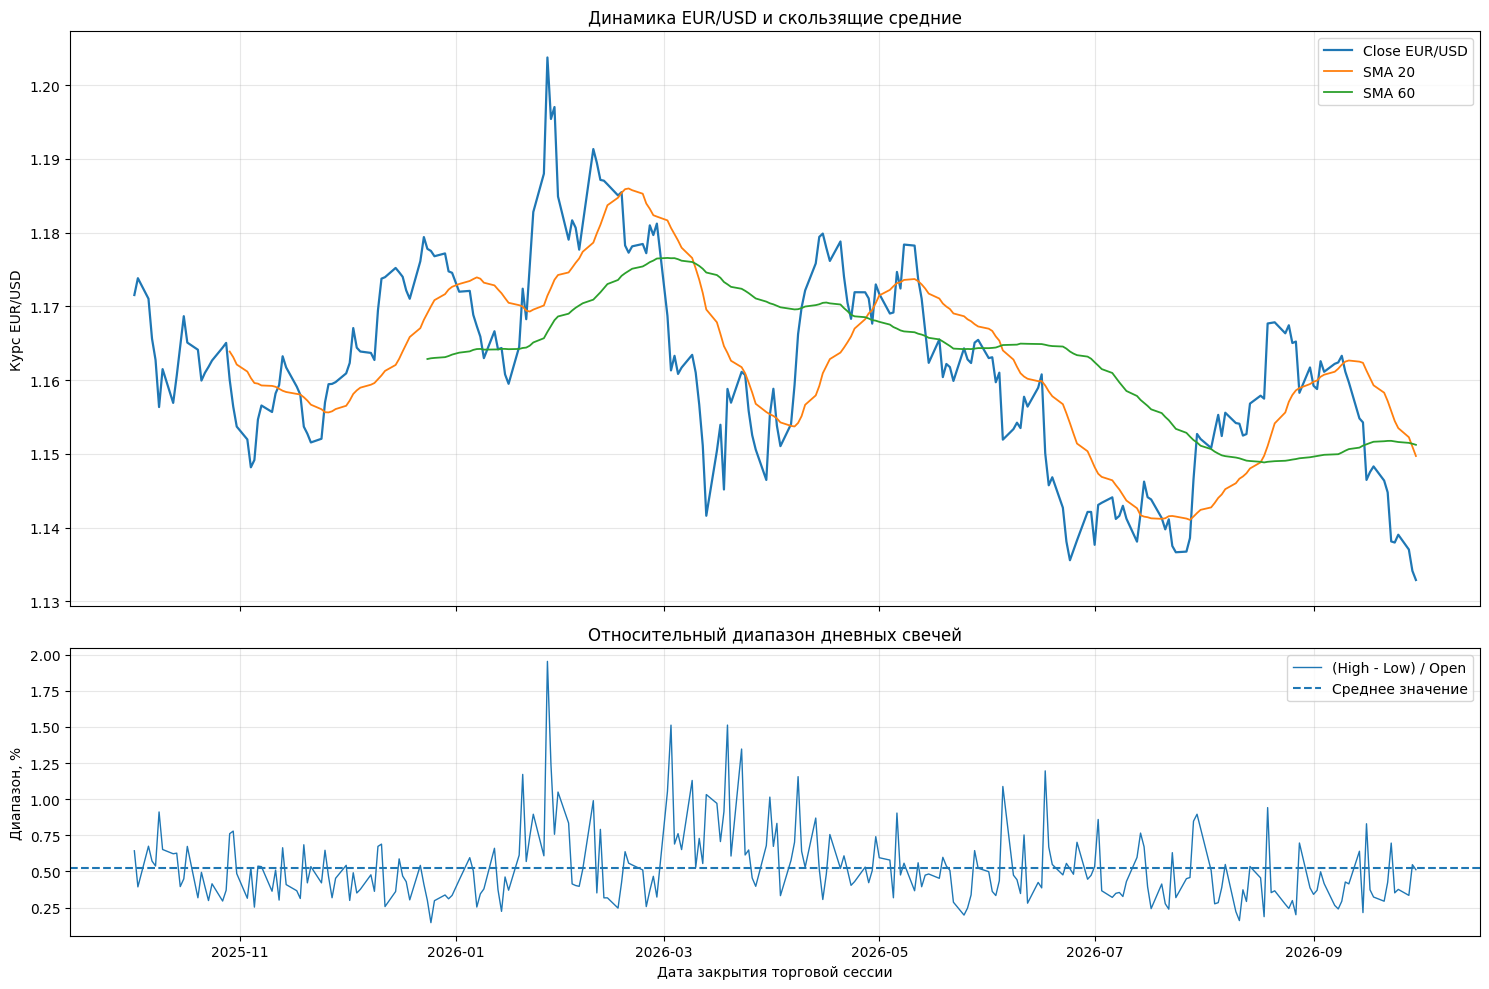

In [ ]:
# ============================================================
# БЛОК 7. ВИЗУАЛИЗАЦИЯ КУРСА И СКОЛЬЗЯЩИХ ХАРАКТЕРИСТИК
# ============================================================

# Создание фигуры с двумя вертикальными графиками.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)


# ============================================================
# 1. ДИНАМИКА ЦЕНЫ ЗАКРЫТИЯ
# ============================================================

# Отображение исторических значений цены закрытия.
axes[0].plot(
    eda_data.index,
    eda_data["close"],
    linewidth=1.6,
    label="Close EUR/USD"
)


# Отображение 20-дневной скользящей средней.
axes[0].plot(
    eda_data.index,
    eda_data["sma_20"],
    linewidth=1.3,
    label="SMA 20"
)


# Отображение 60-дневной скользящей средней.
axes[0].plot(
    eda_data.index,
    eda_data["sma_60"],
    linewidth=1.3,
    label="SMA 60"
)


# Установка заголовка первого графика.
axes[0].set_title(
    "Динамика EUR/USD и скользящие средние"
)


# Установка подписи вертикальной оси.
axes[0].set_ylabel(
    "Курс EUR/USD"
)


# Добавление легенды.
axes[0].legend()


# Добавление вспомогательной координатной сетки.
axes[0].grid(
    True,
    alpha=0.3
)


# ============================================================
# 2. ВНУТРИДНЕВНОЙ ЦЕНОВОЙ ДИАПАЗОН
# ============================================================

# Построение графика относительного дневного диапазона.
axes[1].plot(
    eda_data.index,
    eda_data["daily_range_pct"],
    linewidth=1.0,
    label="(High - Low) / Open"
)


# Отображение среднего относительного диапазона.
axes[1].axhline(
    eda_data["daily_range_pct"].mean(),
    linestyle="--",
    label="Среднее значение"
)


# Установка заголовка второго графика.
axes[1].set_title(
    "Относительный диапазон дневных свечей"
)


# Установка подписи вертикальной оси.
axes[1].set_ylabel(
    "Диапазон, %"
)


# Установка подписи горизонтальной оси.
axes[1].set_xlabel(
    "Дата закрытия торговой сессии"
)


# Добавление легенды и сетки.
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# Автоматическое выравнивание графиков.
plt.tight_layout()


# Отображение итоговой фигуры.
plt.show()

## 3. Распределение доходностей и анализ волатильности

### 3.1. Анализ распределения

Для логарифмических доходностей исследуются следующие показатели:

- среднее значение;
- стандартное отклонение;
- асимметрия (Skewness);
- эксцесс (Excess Kurtosis);
- квантили;
- наиболее значительные изменения.

Асимметрия характеризует несимметричность распределения. Положительный эксцесс относительно нормального распределения может указывать на более выраженные хвосты распределения.

### 3.2. Проверка нормальности

Для дополнительной диагностики применяется тест Жарка—Бера (Jarque–Bera).

Нулевая гипотеза:

$$
H_0:\text{ распределение имеет нулевую асимметрию и нормальный эксцесс}.
$$

Альтернативная гипотеза:

$$
H_1:\text{ хотя бы одна из характеристик отличается}.
$$

Уровень значимости:

$$
\alpha=0.05.
$$

При $p<0.05$ нулевая гипотеза отклоняется.

Результаты рассматриваются как статистическая
диагностика, поскольку последовательные
финансовые доходности могут обладать зависимостями,
а классический тест предполагает независимость наблюдений.

### 3.3. Изменение волатильности

Для изучения локальной изменчивости используется 20-дневное скользящее стандартное отклонение логарифмических доходностей.

Дополнительно исследуется абсолютная величина доходности $|g_t|$.

Последовательные периоды повышенной волатильности
могут указывать на кластеризацию изменчивости.

Однако визуального анализа недостаточно
для статистического подтверждения этого эффекта.

### 3.4. Анализ экстремальных движений

Самые значительные абсолютные дневные доходности
рассматриваются отдельно.

Такие наблюдения сохраняются в наборе,
если отсутствуют подтверждённые ошибки
исходных котировок.

Удаление крупных рыночных движений
без обоснования может искусственно улучшить
результаты прогнозирования.

Диагностика распределения логарифмических доходностей:


,Показатель,Значение
0,Асимметрия,0.279635
1,Эксцесс,1.653513
2,Jarque–Bera statistic,30.790950
3,Jarque–Bera p-value,0.000000


Тест Жарка — Бера: нулевая гипотеза отклоняется.

Восемь наиболее значительных дневных изменений:


,close,"Доходность, %","Абсолютная доходность, %",daily_range_pct
date,,,,
2026-01-27,1.203800,1.326600,1.326600,1.952900
2026-03-19,1.158800,1.191100,1.191100,1.512500
2026-03-02,1.168700,-1.059900,1.059900,1.053900
2026-01-30,1.184900,-1.013300,1.013300,1.049300
2026-06-17,1.150100,-0.921800,0.921800,1.195800
2026-08-19,1.167700,0.880400,0.880400,0.941700
2026-02-09,1.191300,0.861900,0.861900,0.989800
2026-03-13,1.141600,-0.827000,0.827000,1.032100


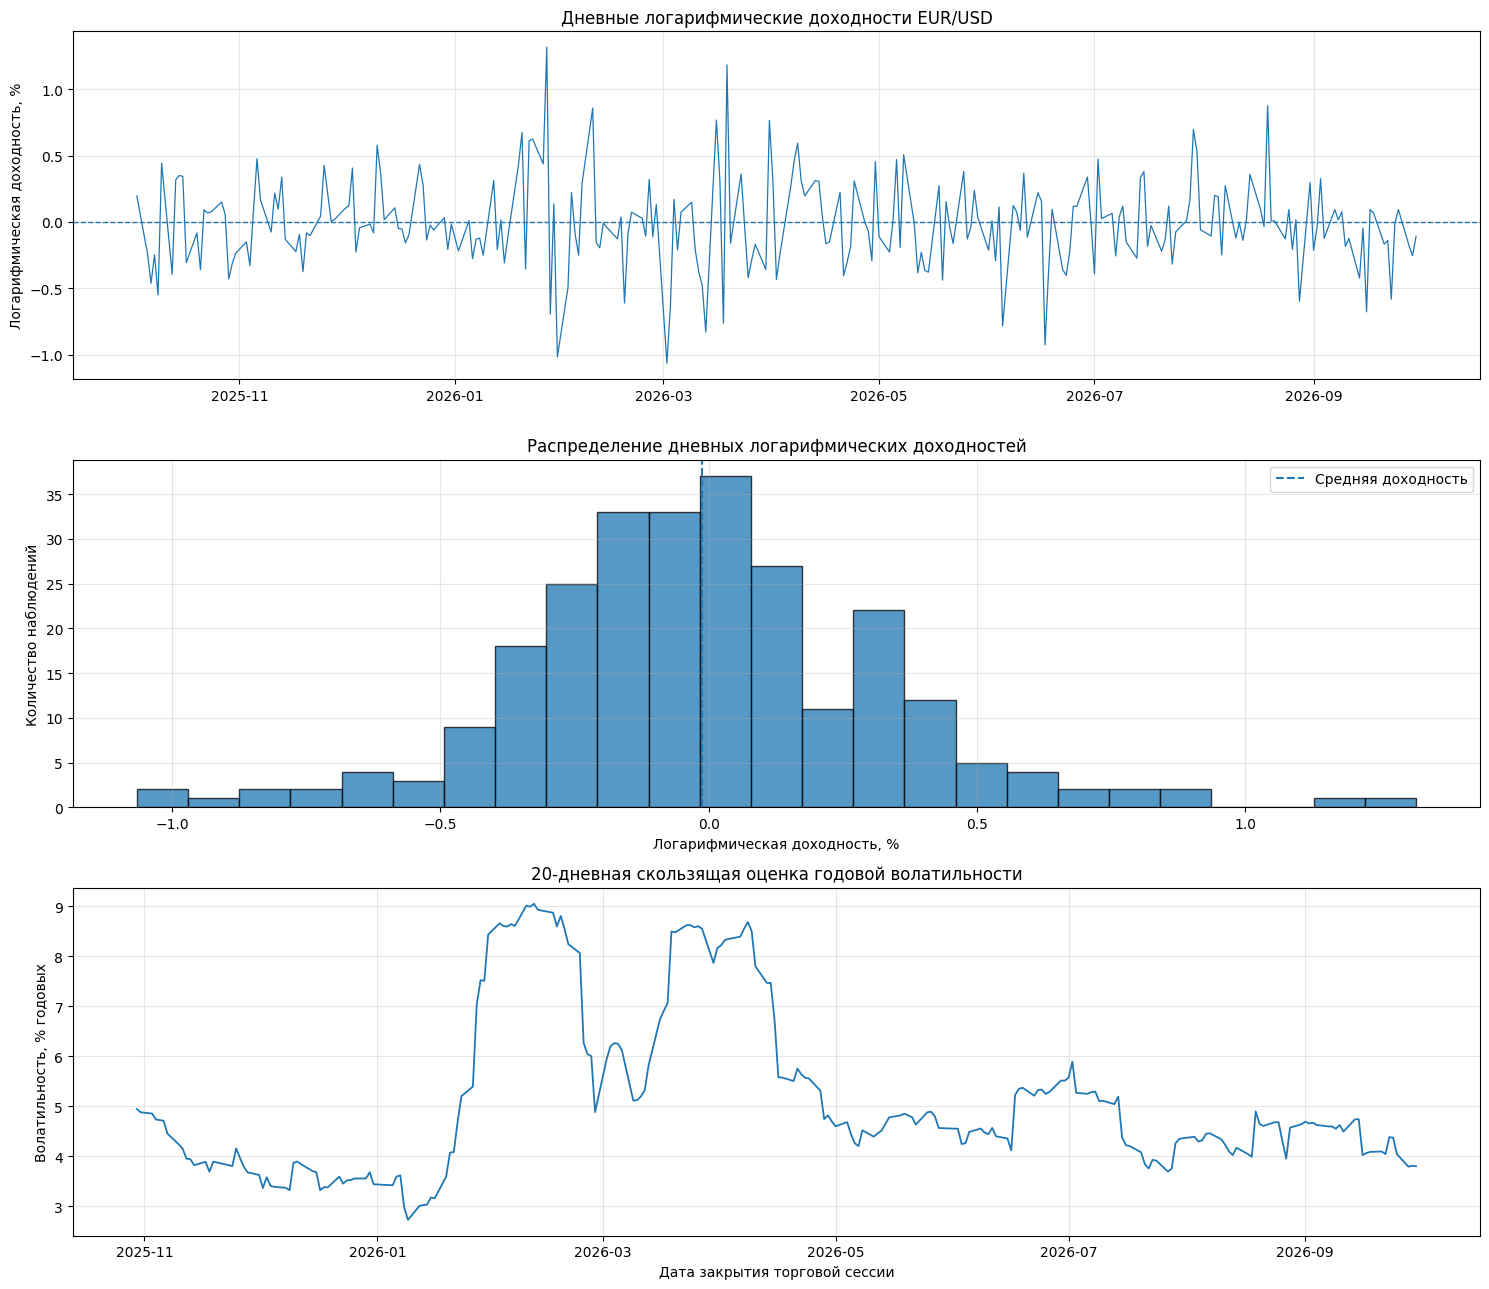

In [ ]:
# ============================================================
# БЛОК 8. АНАЛИЗ ДОХОДНОСТЕЙ И ВОЛАТИЛЬНОСТИ
# ============================================================

# Импорт статистического теста нормальности Jarque–Bera.
from scipy.stats import jarque_bera


# ============================================================
# 1. ЧИСЛОВАЯ ДИАГНОСТИКА РАСПРЕДЕЛЕНИЯ
# ============================================================

# Расчёт асимметрии логарифмических доходностей.
return_skewness = float(
    log_returns.skew()
)


# Расчёт выборочного эксцесса логарифмических доходностей.
return_excess_kurtosis = float(
    log_returns.kurt()
)


# Выполнение теста Жарка — Бера.
jarque_bera_result = jarque_bera(
    log_returns.to_numpy()
)


# Получение статистики теста.
jb_statistic = float(
    jarque_bera_result.statistic
)


# Получение p-value теста.
jb_pvalue = float(
    jarque_bera_result.pvalue
)


# Формирование сводной таблицы характеристик распределения.
return_distribution_table = pd.DataFrame(
    [
        ("Асимметрия", return_skewness),
        ("Эксцесс", return_excess_kurtosis),
        ("Jarque–Bera statistic", jb_statistic),
        ("Jarque–Bera p-value", jb_pvalue)
    ],
    columns=[
        "Показатель",
        "Значение"
    ]
)


# Вывод характеристик распределения доходностей.
print("Диагностика распределения логарифмических доходностей:")
display(
    return_distribution_table.round(6)
)


# Определение уровня статистической значимости.
SIGNIFICANCE_LEVEL = 0.05


# Проверка результата теста на нормальность.
if jb_pvalue < SIGNIFICANCE_LEVEL:

    # Вывод результата отклонения нулевой гипотезы.
    print(
        "Тест Жарка — Бера: нулевая гипотеза отклоняется."
    )

# Если p-value не меньше уровня значимости, то оснований отклонять H0 недостаточно.
else:

    # Вывод осторожной интерпретации результата.
    print(
        "Тест Жарка — Бера: недостаточно оснований "
        "отклонить нулевую гипотезу."
    )


# ============================================================
# 2. НАИБОЛЕЕ ЗНАЧИТЕЛЬНЫЕ ДНЕВНЫЕ ИЗМЕНЕНИЯ
# ============================================================

# Создание таблицы дневных изменений курса.
daily_movements_table = eda_data[
    ["close", "simple_return", "daily_range_pct"]
].copy()


# Перевод простой доходности в проценты.
daily_movements_table["Доходность, %"] = (
    daily_movements_table["simple_return"] * 100.0
)


# Расчёт абсолютной доходности для сортировки.
daily_movements_table["Абсолютная доходность, %"] = (
    daily_movements_table["Доходность, %"].abs()
)


# Отбор восьми наиболее значительных дневных движений.
largest_movements_table = (
    daily_movements_table
    .nlargest(
        8,
        "Абсолютная доходность, %"
    )
    [
        [
            "close",
            "Доходность, %",
            "Абсолютная доходность, %",
            "daily_range_pct"
        ]
    ]
)


# Вывод таблицы экстремальных движений.
print("\nВосемь наиболее значительных дневных изменений:")
display(
    largest_movements_table.round(4)
)


# ============================================================
# 3. ВИЗУАЛИЗАЦИЯ ДОХОДНОСТЕЙ И ВОЛАТИЛЬНОСТИ
# ============================================================

# Создание фигуры с тремя графиками.
figure, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 13)
)


# Отображение дневных логарифмических доходностей.
axes[0].plot(
    eda_data.index,
    eda_data["log_return"] * 100.0,
    linewidth=0.9
)


# Отображение нулевой линии доходности.
axes[0].axhline(
    0.0,
    linestyle="--",
    linewidth=1.0
)


# Установка заголовка первого графика.
axes[0].set_title(
    "Дневные логарифмические доходности EUR/USD"
)


# Подпись вертикальной оси первого графика.
axes[0].set_ylabel(
    "Логарифмическая доходность, %"
)


# Построение гистограммы логарифмических доходностей.
axes[1].hist(
    log_returns * 100.0,
    bins=25,
    edgecolor="black",
    alpha=0.75
)


# Выделение среднего значения логарифмической доходности.
axes[1].axvline(
    log_returns.mean() * 100.0,
    linestyle="--",
    label="Средняя доходность"
)


# Установка заголовка гистограммы.
axes[1].set_title(
    "Распределение дневных логарифмических доходностей"
)


# Подпись горизонтальной оси гистограммы.
axes[1].set_xlabel(
    "Логарифмическая доходность, %"
)


# Подпись вертикальной оси гистограммы.
axes[1].set_ylabel(
    "Количество наблюдений"
)


# Добавление легенды гистограммы.
axes[1].legend()


# Построение скользящей годовой волатильности.
axes[2].plot(
    eda_data.index,
    eda_data["rolling_volatility_annual_pct"],
    linewidth=1.3
)


# Установка заголовка графика волатильности.
axes[2].set_title(
    "20-дневная скользящая оценка годовой волатильности"
)


# Подпись вертикальной оси.
axes[2].set_ylabel(
    "Волатильность, % годовых"
)


# Подпись горизонтальной оси.
axes[2].set_xlabel(
    "Дата закрытия торговой сессии"
)


# Добавление координатной сетки на все графики.
for axis in axes:

    # Настройка прозрачности координатной сетки.
    axis.grid(
        True,
        alpha=0.3
    )


# Автоматическое выравнивание элементов фигуры.
plt.tight_layout()


# Вывод графиков.
plt.show()

## 4. Автокорреляция и временная зависимость доходностей

### 4.1. Автокорреляционная функция

Автокорреляционная функция (ACF) характеризует
связь временного ряда с его предыдущими значениями.

Задержка $k$:

$$
\rho(k)=
\frac{\operatorname{Cov}(g_t,g_{t-k})}
{\operatorname{Var}(g_t)}.
$$

Параметры для изучения:

1. Автокорреляция логарифмических доходностей.
2. Автокорреляция квадратов логарифмических доходностей.
3. Частичная автокорреляция доходностей (PACF).

ACF доходностей позволяет исследовать
линейную временную зависимость изменения курса.

ACF квадратов доходностей используется
для предварительной диагностики
кластеризации волатильности.

PACF помогает оценить зависимость текущего
наблюдения от отдельных задержек с учётом
промежуточных лагов.

### 4.2. Тест Льюнга — Бокса

Нулевая гипотеза:

$$
H_0:\rho(1)=\rho(2)=\ldots=\rho(m)=0.
$$

Альтернативная гипотеза:

$$
H_1:\text{ хотя бы одна автокорреляция ненулевая}.
$$

Используемые значения:

$$
m\in\{5,10,20\}.
$$

При $p<0.05$ нулевая гипотеза отклоняется
для соответствующего набора лагов.

Тест не доказывает наличие устойчивого
прогнозного преимущества модели.

### 4.3. Хронологическое разделение

Для будущего вычислительного эксперимента
предварительно устанавливаются следующие параметры:

- 70% — обучающий период;
- 15% — валидационный период;
- оставшиеся наблюдения — тестовый период.

Диагностика автокорреляции проводится только на обучающем периоде.

Границы будут сохранены для следующих этапов.

При формировании целевых значений для горизонтов
1 и 5 торговых дней дополнительно исключим
обучающие примеры, целевые значения которых
попадают в будущие контрольные периоды.

### 4.4. Ограничения интерпретации

Статистически значимая автокорреляция
не обязательно означает экономически полезную
или устойчивую прогнозируемость.

Зависимость квадратов доходностей
характеризует изменчивость ряда, но сама по себе
не гарантирует прогнозируемость направления курса.

Из-за ограниченного размера выборки
результаты тестов необходимо интерпретировать
с учётом количества наблюдений
и чувствительности к выбранным лагам.

Предварительное разделение финансового ряда:


,Выборка,Наблюдений,Начало,Конец
0,Train,181,2025-10-02,2026-06-12
1,Validation,38,2026-06-15,2026-08-05
2,Test,40,2026-08-06,2026-09-30


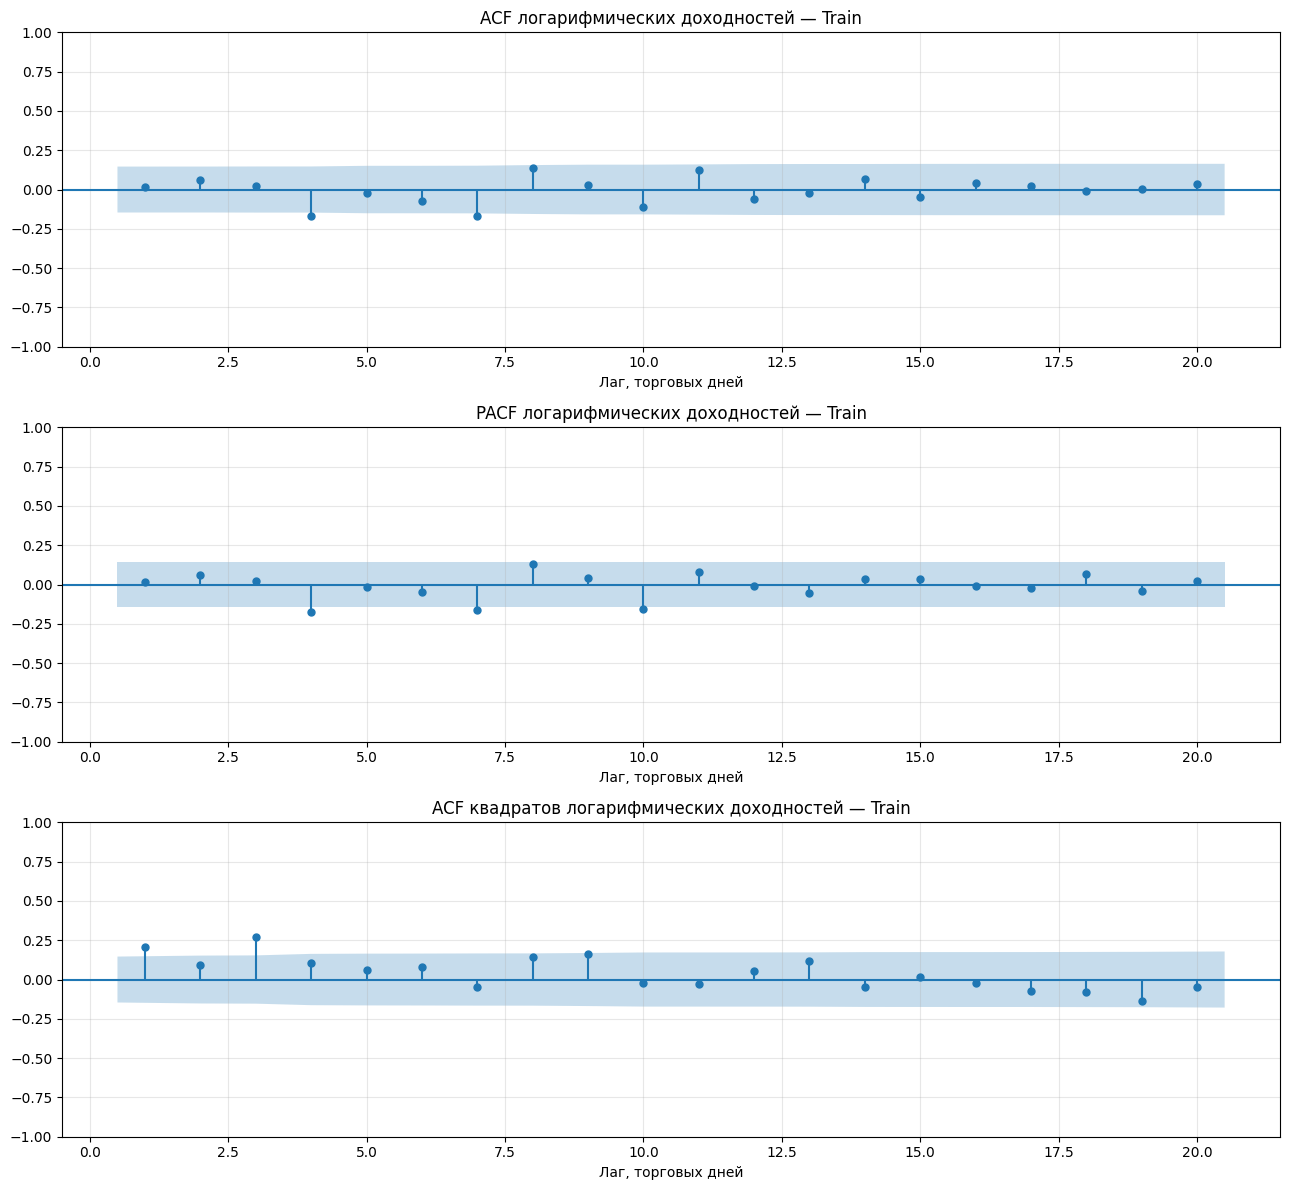

Диагностика автокорреляционных зависимостей:


,Лаг,LB statistic — доходности,p-value — доходности,LB statistic — квадраты,p-value — квадраты,Значимость доходностей,Значимость квадратов
0,5,6.328715,0.275534,25.693321,0.000102,False,True
1,10,18.522819,0.046759,36.452915,0.000070,True,True
2,20,24.466185,0.222621,47.024782,0.000582,False,True


In [ ]:
# ============================================================
# БЛОК 9. АВТОКОРРЕЛЯЦИЯ И ТЕСТ ЛЬЮНГА — БОКСА
# ============================================================

# Импорт функций визуализации ACF и PACF.
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Импорт статистического теста Льюнга — Бокса.
from statsmodels.stats.diagnostic import acorr_ljungbox


# ============================================================
# 1. ФИКСАЦИЯ ВРЕМЕННОГО РАЗДЕЛЕНИЯ
# ============================================================

# Определение доли обучающего периода.
TRAIN_SHARE = 0.70


# Определение доли валидационного периода.
VALIDATION_SHARE = 0.15


# Получение количества исходных торговых дней.
total_observations = len(eda_data)


# Расчёт количества обучающих наблюдений.
train_observations_count = int(
    np.floor(total_observations * TRAIN_SHARE)
)


# Расчёт количества валидационных наблюдений.
validation_observations_count = int(
    np.floor(total_observations * VALIDATION_SHARE)
)


# Расчёт количества тестовых наблюдений.
test_observations_count = (
    total_observations
    - train_observations_count
    - validation_observations_count
)


# Формирование обучающего временного фрагмента.
eda_train = eda_data.iloc[
    :train_observations_count
].copy()


# Формирование валидационного временного фрагмента.
eda_validation = eda_data.iloc[
    train_observations_count:
    train_observations_count + validation_observations_count
].copy()


# Формирование тестового временного фрагмента.
eda_test = eda_data.iloc[
    train_observations_count + validation_observations_count:
].copy()


# Проверка сохранения общего количества наблюдений.
assert (
    len(eda_train)
    + len(eda_validation)
    + len(eda_test)
    ==
    total_observations
)


# Проверка хронологического порядка разделённых частей.
assert (
    eda_train.index.max()
    <
    eda_validation.index.min()
    <
    eda_test.index.min()
)


# Создание таблицы временного разделения.
temporal_split_table = pd.DataFrame(
    [
        (
            "Train",
            len(eda_train),
            eda_train.index.min().date(),
            eda_train.index.max().date()
        ),
        (
            "Validation",
            len(eda_validation),
            eda_validation.index.min().date(),
            eda_validation.index.max().date()
        ),
        (
            "Test",
            len(eda_test),
            eda_test.index.min().date(),
            eda_test.index.max().date()
        )
    ],
    columns=[
        "Выборка",
        "Наблюдений",
        "Начало",
        "Конец"
    ]
)


# Вывод хронологического разделения.
print("Предварительное разделение финансового ряда:")
display(
    temporal_split_table
)


# ============================================================
# 2. ПОДГОТОВКА ОБУЧАЮЩИХ ДОХОДНОСТЕЙ
# ============================================================

# Получение логарифмических доходностей обучающего периода.
train_log_returns = (
    eda_train["log_return"].dropna()
)


# Определение числа исследуемых лагов.
MAX_ACF_LAG = 20


# Проверка достаточности обучающих наблюдений.
assert len(train_log_returns) > 2 * MAX_ACF_LAG


# Формирование квадратов обучающих доходностей.
train_squared_returns = (
    train_log_returns ** 2
)


# ============================================================
# 3. ВИЗУАЛИЗАЦИЯ АВТОКОРРЕЛЯЦИИ
# ============================================================

# Создание фигуры с тремя графиками.
figure, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 12)
)


# Построение ACF логарифмических доходностей.
plot_acf(
    train_log_returns,
    lags=MAX_ACF_LAG,
    zero=False,
    alpha=0.05,
    ax=axes[0]
)


# Установка заголовка ACF доходностей.
axes[0].set_title(
    "ACF логарифмических доходностей — Train"
)


# Построение PACF логарифмических доходностей.
plot_pacf(
    train_log_returns,
    lags=MAX_ACF_LAG,
    zero=False,
    method="ywm",
    alpha=0.05,
    ax=axes[1]
)


# Установка заголовка PACF доходностей.
axes[1].set_title(
    "PACF логарифмических доходностей — Train"
)


# Построение ACF квадратов доходностей.
plot_acf(
    train_squared_returns,
    lags=MAX_ACF_LAG,
    zero=False,
    alpha=0.05,
    ax=axes[2]
)


# Установка заголовка ACF квадратов доходностей.
axes[2].set_title(
    "ACF квадратов логарифмических доходностей — Train"
)


# Добавление подписей горизонтальной оси.
for axis in axes:

    # Установка названия горизонтальной оси.
    axis.set_xlabel(
        "Лаг, торговых дней"
    )


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Вывод графиков.
plt.show()


# ============================================================
# 4. ТЕСТ ЛЬЮНГА — БОКСА
# ============================================================

# Определение набора проверяемых временных задержек.
LJUNG_BOX_LAGS = [
    5,
    10,
    20
]


# Проверка автокорреляции логарифмических доходностей.
ljung_box_returns = acorr_ljungbox(
    train_log_returns,
    lags=LJUNG_BOX_LAGS,
    return_df=True
)


# Проверка автокорреляции квадратов доходностей.
ljung_box_squared_returns = acorr_ljungbox(
    train_squared_returns,
    lags=LJUNG_BOX_LAGS,
    return_df=True
)


# Формирование общей диагностической таблицы.
ljung_box_table = pd.DataFrame(
    {
        "Лаг": LJUNG_BOX_LAGS,
        "LB statistic — доходности": (
            ljung_box_returns["lb_stat"].to_numpy()
        ),
        "p-value — доходности": (
            ljung_box_returns["lb_pvalue"].to_numpy()
        ),
        "LB statistic — квадраты": (
            ljung_box_squared_returns["lb_stat"].to_numpy()
        ),
        "p-value — квадраты": (
            ljung_box_squared_returns["lb_pvalue"].to_numpy()
        )
    }
)


# Определение значимости автокорреляции доходностей.
ljung_box_table["Значимость доходностей"] = (
    ljung_box_table["p-value — доходности"]
    <
    SIGNIFICANCE_LEVEL
)


# Определение значимости автокорреляции квадратов доходностей.
ljung_box_table["Значимость квадратов"] = (
    ljung_box_table["p-value — квадраты"]
    <
    SIGNIFICANCE_LEVEL
)


# Вывод результатов теста Льюнга — Бокса.
print("Диагностика автокорреляционных зависимостей:")
display(
    ljung_box_table.round(6)
)

## 5. Проверка стационарности финансового временного ряда

### 5.1. Понятие стационарности

Слабая стационарность предполагает, что основные статистические характеристики временного ряда не зависят от абсолютного положения во времени.

Для слабостационарного процесса характерно следующее поведение:

$$
\mathbb{E}[X_t]=\mu=\mathrm{const},
$$

$$
\operatorname{Var}(X_t)=\sigma^2=\mathrm{const},
$$

$$
\operatorname{Cov}(X_t,X_{t-k})=\gamma(k).
$$

Таким образом, автоковариация зависит от временного сдвига, но не от конкретного момента наблюдения.

### 5.2. Тест ADF

Тест Дики—Фуллера в расширенной форме используется для проверки наличия единичного корня.

Нулевая гипотеза:

$$
H_0:\text{ ряд содержит единичный корень}.
$$

Альтернативная гипотеза:

$$
H_1:\text{ единичный корень отсутствует}.
$$

При $p<0.05$ нулевая гипотеза отклоняется.

Это свидетельствует против модели с единичным корнем, но само по себе не доказывает стационарность в широком статистическом смысле.

### 5.3. Тест KPSS

Тест KPSS проверяет противоположную гипотезу.

При `regression="c"` возможны следующие исходы:

$$
H_0:\text{ ряд стационарен относительно постоянного уровня}.
$$

$$
H_1:\text{ ряд не является стационарным относительно постоянного уровня}.
$$

При $p<0.05$ нулевая гипотеза отклоняется.

### 5.4. Исследуемые последовательности

Проверка 3 представлений EUR/USD:

1. Цена закрытия $C_t$.
2. Логарифм цены закрытия $\ln(C_t)$.
3. Логарифмическая доходность $g_t$.

Исследование проводится исключительно на обучающей части временного ряда.
Для всех 3 последовательностей используется модель теста с постоянной составляющей.

### 5.5. Интерпретация результатов

| ADF: единичный корень отвергнут | KPSS: стационарность отвергнута | Предварительная интерпретация |
|---|---|---|
| Да | Нет | Свидетельства согласуются со стационарностью относительно уровня |
| Нет | Да | Свидетельства согласуются с нестационарностью |
| Да | Да | Противоречивые результаты, требуется осторожная интерпретация |
| Нет | Нет | Недостаточно статистических свидетельств для однозначного решения |

Тесты рассматриваются как диагностические процедуры.

Решение о порядке дифференцирования ARIMA позднее будет определяться не только результатами ADF/KPSS, но и проверкой качества прогнозирования на временной валидации.

In [ ]:
# ============================================================
# БЛОК 10. ПРОВЕРКА СТАЦИОНАРНОСТИ ПО ADF И KPSS
# ============================================================

# Импорт функций статистических тестов ADF и KPSS.
from statsmodels.tsa.stattools import adfuller, kpss

# Импорт модуля warnings для обработки предупреждений KPSS.
import warnings


# Определение уровня статистической значимости.
STATIONARITY_ALPHA = 0.05


# Формирование словаря обучающих временных рядов.
stationarity_series = {
    "Цена закрытия Close": eda_train["close"],
    "Логарифм Close": np.log(eda_train["close"]),
    "Логарифмическая доходность": eda_train["log_return"]
}


# Определение функции проведения двух тестов стационарности.
def evaluate_stationarity(series_name, series_values):

    # Преобразование ряда в одномерный числовой массив.
    observations = (
        pd.Series(series_values)
        .dropna()
        .to_numpy(dtype=np.float64)
    )


    # Проверка достаточного количества наблюдений.
    if len(observations) < 30:

        # Генерация исключения при недостаточном объёме данных.
        raise ValueError(
            f"Недостаточно наблюдений для ряда: {series_name}"
        )


    # Проверка конечности всех числовых значений.
    assert np.isfinite(observations).all()


    # Выполнение расширенного теста Дики — Фуллера.
    adf_result = adfuller(
        observations,
        regression="c",
        autolag="AIC"
    )


    # Получение статистики ADF.
    adf_statistic = float(
        adf_result[0]
    )


    # Получение p-value теста ADF.
    adf_pvalue = float(
        adf_result[1]
    )


    # Получение использованного количества лагов ADF.
    adf_lags = int(
        adf_result[2]
    )


    # Перехват предупреждений, возникающих при выполнении KPSS.
    with warnings.catch_warnings(record=True) as captured_warnings:

        # Включение регистрации всех предупреждений в данном контексте.
        warnings.simplefilter("always")


        # Выполнение KPSS с автоматическим выбором количества лагов.
        kpss_result = kpss(
            observations,
            regression="c",
            nlags="auto"
        )


    # Получение статистики KPSS.
    kpss_statistic = float(
        kpss_result[0]
    )


    # Получение p-value теста KPSS.
    kpss_pvalue = float(
        kpss_result[1]
    )


    # Получение количества лагов KPSS.
    kpss_lags = int(
        kpss_result[2]
    )


    # Проверка отклонения гипотезы единичного корня.
    adf_rejects_unit_root = (
        adf_pvalue < STATIONARITY_ALPHA
    )


    # Проверка отклонения гипотезы стационарности относительно уровня.
    kpss_rejects_stationarity = (
        kpss_pvalue < STATIONARITY_ALPHA
    )


    # Определение предварительной интерпретации двух тестов.
    if adf_rejects_unit_root and not kpss_rejects_stationarity:

        # Формирование результата, согласующегося со стационарностью.
        interpretation = "Согласуется со стационарностью"

    elif not adf_rejects_unit_root and kpss_rejects_stationarity:

        # Формирование результата, согласующегося с нестационарностью.
        interpretation = "Согласуется с нестационарностью"

    else:

        # Формирование результата при недостаточно согласованных тестах.
        interpretation = "Неоднозначный результат"


    # Формирование итоговой строки статистической диагностики.
    return {
        "Временной ряд": series_name,
        "Наблюдений": len(observations),
        "ADF statistic": adf_statistic,
        "ADF p-value": adf_pvalue,
        "ADF lags": adf_lags,
        "KPSS statistic": kpss_statistic,
        "KPSS p-value": kpss_pvalue,
        "KPSS lags": kpss_lags,
        "ADF отвергает H0": adf_rejects_unit_root,
        "KPSS отвергает H0": kpss_rejects_stationarity,
        "Предварительный вывод": interpretation,
        "Предупреждения KPSS": len(captured_warnings)
    }


# Создание списка результатов проверки стационарности.
stationarity_results = []


# Последовательный перебор исследуемых представлений курса.
for series_name, series_values in stationarity_series.items():

    # Выполнение тестов для текущего ряда.
    result = evaluate_stationarity(
        series_name,
        series_values
    )


    # Добавление результата в общую таблицу.
    stationarity_results.append(result)


# Формирование таблицы статистических результатов.
stationarity_results_table = pd.DataFrame(
    stationarity_results
)


# Вывод таблицы ADF/KPSS.
print("Результаты проверки стационарности на обучающей выборке:")

display(
    stationarity_results_table.round(6)
)


# Получение строк с предупреждениями KPSS.
stationarity_warning_rows = stationarity_results_table.loc[
    stationarity_results_table["Предупреждения KPSS"] > 0,
    "Временной ряд"
]


# Если предупреждения зарегистрированы, то выводим пояснение.
if not stationarity_warning_rows.empty:

    # Вывод названий рядов с предупреждениями.
    print(
        "\nВнимание: KPSS сообщил об ограниченности "
        "табличного диапазона p-value для рядов:"
    )

    # Вывод названий соответствующих рядов.
    print(
        stationarity_warning_rows.tolist()
    )

    # Вывод методологического пояснения.
    print(
        "Значения p-value в этих строках следует "
        "рассматривать как граничные оценки."
    )

Результаты проверки стационарности на обучающей выборке:


/tmp/ipykernel_615/2980424816.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_615/2980424816.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_615/2980424816.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0

,Временной ряд,Наблюдений,ADF statistic,ADF p-value,ADF lags,KPSS statistic,KPSS p-value,KPSS lags,ADF отвергает H0,KPSS отвергает H0,Предварительный вывод,Предупреждения KPSS
0,Цена закрытия Close,181,-2.530868,0.108143,0,0.188425,0.100000,8,False,False,Неоднозначный результат,2
1,Логарифм Close,181,-2.532898,0.107674,0,0.187709,0.100000,8,False,False,Неоднозначный результат,2
2,Логарифмическая доходность,180,-7.459635,0.000000,3,0.043926,0.100000,3,True,False,Согласуется со стационарностью,2



Внимание: KPSS сообщил об ограниченности табличного диапазона p-value для рядов:
['Цена закрытия Close', 'Логарифм Close', 'Логарифмическая доходность']
Значения p-value в этих строках следует рассматривать как граничные оценки.


## 6. Формирование признаков и целевых переменных

### 6.1. Принцип формирования признаков

Каждой завершённой торговой сессии $t$ соответствует вектор доступных признаков:

$$
\mathbf{x}_t=
f(OHLC_t,OHLC_{t-1},\ldots).
$$

Все признаки вычисляются только из наблюдений, доступных не позднее окончания сессии $t$.

В набор включаются следующие критерии:

- цены Open, High, Low, Close;
- дневные и многодневные логарифмические изменения;
- относительный диапазон дневной свечи;
- относительный размер тела свечи;
- положение Close внутри диапазона High–Low;
- скользящие средние доходностей;
- скользящие стандартные отклонения доходностей;
- относительное отклонение Close от скользящей средней.

Технические признаки рассматриваются как кандидаты для последующего обучения.
Их наличие не означает, что все они обязательно окажутся информативными или улучшат прогноз.

### 6.2. Целевые переменные

Для горизонта $h$ получается

$$
y_t^{(h)}=C_{t+h},
$$

рассматриваются

$$
h\in\{1,5\},
$$

а также пополнительно учитываются

$$
g_{t,h}^{future}
=
\ln\left(\frac{C_{t+h}}{C_t}\right).
$$

Формируются также даты целевых наблюдений.

Это необходимо для предотвращения ситуаций, когда дата формирования прогноза находится в обучении, а фактическая цель находится уже в валидационном или тестовом периоде.

### 6.3. Правило доступности информации

После завершения торговой сессии $t$ допускается использовать её OHLC.

Фактические значения $C_{t+1}$ и $C_{t+5}$ могут выступать только целевыми переменными при обучении или проверке качества. Они никогда не должны попадать
в признаки того же наблюдения.

### 6.4. Ограничения

Используемый набор содержит около года дневных данных, поэтому количество признаков и сложность моделей должны быть ограничены для предотвращения переобучения. Масштабирование и иные преобразования, требующие оценки статистических параметров, будут выполняться только на обучающих данных.

Скользящие статистики строятся как причинные преобразования, использующие текущую и предыдущие завершённые торговые сессии.

In [ ]:
# ============================================================
# БЛОК 11. ПРИЧИННО КОРРЕКТНЫЕ ПРИЗНАКИ И ЦЕЛИ EUR/USD
# ============================================================

# Определение исследуемых горизонтов прогнозирования.
FORECAST_HORIZONS = [1, 5]


# Создание DataFrame для признаков и целевых переменных.
forecasting_data = pd.DataFrame(
    index=market_data.index
)


# ============================================================
# 1. ИСХОДНЫЕ РЫНОЧНЫЕ ПРИЗНАКИ
# ============================================================

# Последовательное добавление четырёх характеристик OHLC.
for price_column in PRICE_COLUMNS:

    # Сохранение текущего ценового признака.
    forecasting_data[price_column] = market_data[price_column]


# Расчёт логарифма цены закрытия.
log_close = np.log(
    market_data["close"]
)


# Расчёт дневного логарифмического изменения цены.
forecasting_data["log_return_1"] = (
    log_close.diff(1)
)


# Расчёт логарифмического изменения за предыдущие пять торговых дней.
forecasting_data["log_return_5"] = (
    log_close.diff(5)
)


# Расчёт относительного дневного диапазона.
forecasting_data["range_pct"] = (
    (market_data["high"] - market_data["low"])
    / market_data["open"]
    * 100.0
)


# Расчёт относительного размера тела дневной свечи.
forecasting_data["body_pct"] = (
    (market_data["close"] - market_data["open"])
    / market_data["open"]
    * 100.0
)


# Расчёт ширины диапазона High–Low.
daily_high_low_range = (
    market_data["high"] - market_data["low"]
)


# Исключение деления на ноль при полностью плоской свече.
safe_daily_range = daily_high_low_range.replace(
    0.0,
    np.nan
)


# Расчёт относительного положения Close внутри дневного диапазона.
forecasting_data["close_location"] = (
    (market_data["close"] - market_data["low"])
    / safe_daily_range
).fillna(0.5)


# ============================================================
# 2. СКОЛЬЗЯЩИЕ ХАРАКТЕРИСТИКИ
# ============================================================

# Расчёт среднего логарифмического изменения за пять торговых дней.
forecasting_data["rolling_return_mean_5"] = (
    forecasting_data["log_return_1"]
    .rolling(window=5, min_periods=5)
    .mean()
)


# Расчёт краткосрочной волатильности за пять торговых дней.
forecasting_data["rolling_volatility_5"] = (
    forecasting_data["log_return_1"]
    .rolling(window=5, min_periods=5)
    .std()
)


# Расчёт волатильности за двадцать торговых дней.
forecasting_data["rolling_volatility_20"] = (
    forecasting_data["log_return_1"]
    .rolling(window=20, min_periods=20)
    .std()
)


# Расчёт 20-дневной скользящей средней цены закрытия.
forecasting_sma_20 = (
    market_data["close"]
    .rolling(window=20, min_periods=20)
    .mean()
)


# Расчёт относительного отклонения Close от скользящей средней.
forecasting_data["close_sma_gap_20"] = (
    market_data["close"]
    / forecasting_sma_20
    - 1.0
)


# ============================================================
# 3. ФИКСАЦИЯ РАЗРЕШЁННЫХ ПРИЗНАКОВ
# ============================================================

# Формирование точного списка столбцов, доступных моделям.
MODEL_FEATURE_COLUMNS = [
    "open",
    "high",
    "low",
    "close",
    "log_return_1",
    "log_return_5",
    "range_pct",
    "body_pct",
    "close_location",
    "rolling_return_mean_5",
    "rolling_volatility_5",
    "rolling_volatility_20",
    "close_sma_gap_20"
]


# ============================================================
# 4. ЦЕЛЕВЫЕ ПЕРЕМЕННЫЕ И ДАТЫ ПРОГНОЗОВ
# ============================================================

# Формирование последовательности торговых дат с сохранением индекса.
trading_dates_series = pd.Series(
    market_data.index,
    index=market_data.index
)


# Последовательное создание целей для каждого горизонта.
for horizon in FORECAST_HORIZONS:

    # Определение имени будущей цены закрытия.
    target_close_column = f"target_close_h{horizon}"

    # Определение имени даты будущей цены закрытия.
    target_date_column = f"target_date_h{horizon}"

    # Определение имени будущего логарифмического изменения.
    target_log_return_column = f"target_log_return_h{horizon}"


    # Получение фактического Close через horizon торговых наблюдений.
    forecasting_data[target_close_column] = (
        market_data["close"].shift(-horizon)
    )


    # Получение соответствующей даты будущей торговой сессии.
    forecasting_data[target_date_column] = (
        trading_dates_series.shift(-horizon)
    )


    # Расчёт будущего логарифмического изменения курса.
    forecasting_data[target_log_return_column] = (
        np.log(
            forecasting_data[target_close_column]
            / market_data["close"]
        )
    )


# ============================================================
# 5. КОНТРОЛЬ КОРРЕКТНОСТИ
# ============================================================

# Проверка сохранения полного числа исходных торговых дат.
assert len(forecasting_data) == len(market_data)


# Проверка отсутствия будущих целевых столбцов среди признаков.
assert not any(
    column_name.startswith("target_")
    for column_name in MODEL_FEATURE_COLUMNS
)


# Проверка, что все прогнозные признаки реально существуют.
assert set(MODEL_FEATURE_COLUMNS).issubset(
    forecasting_data.columns
)


# Проверка отсутствия бесконечных значений в сформированных признаках.
assert np.isfinite(
    forecasting_data[MODEL_FEATURE_COLUMNS]
    .dropna()
    .to_numpy(dtype=np.float64)
).all()


# Вывод списка признаков.
print("Число доступных прогнозных признаков:")
print(len(MODEL_FEATURE_COLUMNS))


# Вывод имён прогнозных признаков.
print("\nСписок признаков:")
print(MODEL_FEATURE_COLUMNS)


# Вывод размера подготовленной таблицы.
print("\nРазмерность таблицы:")
print(forecasting_data.shape)


# Вывод последних восьми наблюдений для проверки будущих целей.
print("\nПоследние наблюдения с целевыми переменными:")
display(
    forecasting_data[
        [
            "close",
            "target_date_h1",
            "target_close_h1",
            "target_date_h5",
            "target_close_h5"
        ]
    ].tail(8)
)

Число доступных прогнозных признаков:
13

Список признаков:
['open', 'high', 'low', 'close', 'log_return_1', 'log_return_5', 'range_pct', 'body_pct', 'close_location', 'rolling_return_mean_5', 'rolling_volatility_5', 'rolling_volatility_20', 'close_sma_gap_20']

Размерность таблицы:
(259, 19)

Последние наблюдения с целевыми переменными:


,close,target_date_h1,target_close_h1,target_date_h5,target_close_h5
date,,,,,
2026-09-21,1.146380,2026-09-22,1.144780,2026-09-28,1.137030
2026-09-22,1.144780,2026-09-23,1.138130,2026-09-29,1.134140
2026-09-23,1.138130,2026-09-24,1.137980,2026-09-30,1.132900
2026-09-24,1.137980,2026-09-25,1.139040,NaT,NaN
2026-09-25,1.139040,2026-09-28,1.137030,NaT,NaN
2026-09-28,1.137030,2026-09-29,1.134140,NaT,NaN
2026-09-29,1.134140,2026-09-30,1.132900,NaT,NaN
2026-09-30,1.132900,NaT,NaN,NaT,NaN


## 7. Окончательная схема формирования выборок

### 7.1. Принцип разделения

Обычного хронологического разделения по дате исходной строки недостаточно для многогоризонтного прогнозирования, т.к. для каждого наблюдения существуют 2 временные точки:

- $t$ — дата формирования прогноза;
- $t+h$ — дата целевого наблюдения.

Для обучающего периода необходимо одновременно использовать

$$
t\le T_{train,end}\text{   и   }t+h\le T_{train,end}.
$$

Для валидационного периода необходимо одновременно использовать

$$
T_{val,start}\le t\le T_{val,end}\text{   и   }t+h\le T_{val,end}.
$$

Для тестового периода необходимо одновременно использовать

$$
T_{test,start}\le t\le T_{test,end}\text{   и   }t+h\le T_{test,end}.
$$

Здесь прибавление $h$ означает переход на $h$ последовательных торговых наблюдений, а не календарных суток.

### 7.2. Удаление пересекающих границы целей

Если признаки относятся к одному периоду, а целевая дата находится за его пределами, пример исключается из соответствующей выборки.

Таким образом предотвращается использование будущих целевых значений при обучении, подборе параметров и оценке.

### 7.3. Использование исторического контекста

На валидационном и тестовом периодах разрешается использовать ранее наблюдавшиеся рыночные значения.

Например, при формировании прогноза в середине тестового периода могут использоваться фактические котировки предшествующих тестовых дней,
если к моменту прогноза они уже известны.

Такой протокол соответствует последовательному прогнозированию с обновлением доступных наблюдений (rolling-origin evaluation).

Это не означает повторного подбора параметров модели по тестовым ошибкам.

### 7.4. Финальное обучение

После выбора гиперпараметров на Validation допускается повторное обучение модели
на объединённом периоде Train + Validation.

При этом целевые значения всех обучающих примеров должны быть известны
до начала финального теста.

Тестовый период сохраняется независимым источником итоговой оценки качества.

In [ ]:
# ============================================================
# БЛОК 12. РАЗДЕЛЕНИЕ ПО ДАТАМ ПРИЗНАКОВ И ЦЕЛЕВЫХ ЗНАЧЕНИЙ
# ============================================================

# Получение последней даты обучающего периода.
TRAIN_END_DATE = eda_train.index.max()


# Получение первой даты валидационного периода.
VALIDATION_START_DATE = eda_validation.index.min()


# Получение последней даты валидационного периода.
VALIDATION_END_DATE = eda_validation.index.max()


# Получение первой даты тестового периода.
TEST_START_DATE = eda_test.index.min()


# Получение последней даты тестового периода.
TEST_END_DATE = eda_test.index.max()


# Создание словаря итоговых выборок для каждого горизонта.
forecast_splits = {}


# Создание списка строк диагностической таблицы разделения.
forecast_split_rows = []


# Определение функции проверки временных границ выборки.
def validate_forecast_partition(
    partition,
    target_date_column,
    earliest_origin,
    latest_origin,
    latest_target
):

    # Проверка наличия хотя бы одного примера.
    assert len(partition) > 0, (
        "Одна из временных выборок оказалась пустой."
    )


    # Проверка нижней границы даты формирования прогноза.
    assert partition.index.min() >= earliest_origin


    # Проверка верхней границы даты формирования прогноза.
    assert partition.index.max() <= latest_origin


    # Проверка верхней границы всех целевых дат.
    assert partition[target_date_column].max() <= latest_target


    # Проверка, что каждая целевая дата позже даты прогноза.
    assert np.all(
        partition[target_date_column].to_numpy()
        >
        partition.index.to_numpy()
    )


    # Проверка отсутствия некорректных входных числовых значений.
    assert np.isfinite(
        partition[MODEL_FEATURE_COLUMNS].to_numpy(
            dtype=np.float64
        )
    ).all()


# Последовательное формирование выборок для двух горизонтов.
for horizon in FORECAST_HORIZONS:

    # Формирование имени столбца фактической будущей цены.
    target_close_column = f"target_close_h{horizon}"


    # Формирование имени даты целевого наблюдения.
    target_date_column = f"target_date_h{horizon}"


    # Формирование имени будущей логарифмической доходности.
    target_return_column = f"target_log_return_h{horizon}"


    # Определение всех обязательных столбцов текущей постановки.
    required_columns = (
        MODEL_FEATURE_COLUMNS
        +
        [
            target_close_column,
            target_date_column,
            target_return_column
        ]
    )


    # Исключение строк с неизвестными признаками или целевыми значениями.
    horizon_data = forecasting_data.dropna(
        subset=required_columns
    ).copy()


    # ========================================================
    # 1. ОБУЧАЮЩИЙ ПЕРИОД
    # ========================================================

    # Отбор примеров с датами прогноза и целей внутри Train.
    train_partition = horizon_data.loc[
        (horizon_data.index <= TRAIN_END_DATE)
        &
        (horizon_data[target_date_column] <= TRAIN_END_DATE)
    ].copy()


    # ========================================================
    # 2. ВАЛИДАЦИОННЫЙ ПЕРИОД
    # ========================================================

    # Отбор примеров с датами прогноза и целей внутри Validation.
    validation_partition = horizon_data.loc[
        (horizon_data.index >= VALIDATION_START_DATE)
        &
        (horizon_data.index <= VALIDATION_END_DATE)
        &
        (horizon_data[target_date_column] <= VALIDATION_END_DATE)
    ].copy()


    # ========================================================
    # 3. ТЕСТОВЫЙ ПЕРИОД
    # ========================================================

    # Отбор примеров с датами прогноза и целей внутри Test.
    test_partition = horizon_data.loc[
        (horizon_data.index >= TEST_START_DATE)
        &
        (horizon_data.index <= TEST_END_DATE)
        &
        (horizon_data[target_date_column] <= TEST_END_DATE)
    ].copy()


    # ========================================================
    # 4. ОБЪЕДИНЁННЫЙ ПЕРИОД TRAIN + VALIDATION
    # ========================================================

    # Формирование выборки для финального обучения после настройки.
    train_validation_partition = horizon_data.loc[
        (horizon_data.index <= VALIDATION_END_DATE)
        &
        (horizon_data[target_date_column] <= VALIDATION_END_DATE)
    ].copy()


    # ========================================================
    # 5. ПРОВЕРКА ВРЕМЕННОЙ КОРРЕКТНОСТИ
    # ========================================================

    # Проверка границ Train.
    validate_forecast_partition(
        train_partition,
        target_date_column,
        eda_train.index.min(),
        TRAIN_END_DATE,
        TRAIN_END_DATE
    )


    # Проверка границ Validation.
    validate_forecast_partition(
        validation_partition,
        target_date_column,
        VALIDATION_START_DATE,
        VALIDATION_END_DATE,
        VALIDATION_END_DATE
    )


    # Проверка границ Test.
    validate_forecast_partition(
        test_partition,
        target_date_column,
        TEST_START_DATE,
        TEST_END_DATE,
        TEST_END_DATE
    )


    # Проверка границ объединённой обучающей выборки.
    validate_forecast_partition(
        train_validation_partition,
        target_date_column,
        eda_train.index.min(),
        VALIDATION_END_DATE,
        VALIDATION_END_DATE
    )


    # Проверка отсутствия пересечений дат прогнозов Train и Validation.
    assert train_partition.index.intersection(
        validation_partition.index
    ).empty


    # Проверка отсутствия пересечений дат прогнозов Validation и Test.
    assert validation_partition.index.intersection(
        test_partition.index
    ).empty


    # ========================================================
    # 6. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
    # ========================================================

    # Сохранение всех выборок текущего горизонта.
    forecast_splits[horizon] = {
        "train": train_partition,
        "validation": validation_partition,
        "test": test_partition,
        "train_validation": train_validation_partition,
        "target_close_column": target_close_column,
        "target_date_column": target_date_column,
        "target_return_column": target_return_column
    }


    # Формирование строк сводной таблицы.
    for partition_name, partition in [
        ("Train", train_partition),
        ("Validation", validation_partition),
        ("Test", test_partition),
        ("Train + Validation", train_validation_partition)
    ]:

        # Добавление характеристик текущей выборки.
        forecast_split_rows.append(
            {
                "Горизонт": horizon,
                "Выборка": partition_name,
                "Примеров": len(partition),
                "Начало прогнозов": partition.index.min().date(),
                "Конец прогнозов": partition.index.max().date(),
                "Последняя дата цели": (
                    partition[target_date_column].max().date()
                )
            }
        )


# Формирование итоговой таблицы разделения.
forecast_split_table = pd.DataFrame(
    forecast_split_rows
)


# Вывод распределения примеров.
print("Итоговые выборки для двух горизонтов:")
display(
    forecast_split_table
)


# Вывод пояснения о принципе исключения целевых утечек.
print(
    "\nВсе целевые даты находятся внутри "
    "соответствующих контрольных периодов."
)

Итоговые выборки для двух горизонтов:


,Горизонт,Выборка,Примеров,Начало прогнозов,Конец прогнозов,Последняя дата цели
0,1,Train,160,2025-10-30,2026-06-11,2026-06-12
1,1,Validation,37,2026-06-15,2026-08-04,2026-08-05
2,1,Test,39,2026-08-06,2026-09-29,2026-09-30
3,1,Train + Validation,198,2025-10-30,2026-08-04,2026-08-05
4,5,Train,156,2025-10-30,2026-06-05,2026-06-12
5,5,Validation,33,2026-06-15,2026-07-29,2026-08-05
6,5,Test,35,2026-08-06,2026-09-23,2026-09-30
7,5,Train + Validation,194,2025-10-30,2026-07-29,2026-08-05



Все целевые даты находятся внутри соответствующих контрольных периодов.


## 8. Единый протокол оценки прогнозов

### 8.1. Сопоставимость результатов

Все 4 семейства моделей оцениваются по фактической будущей цене закрытия:

$$
y_i=C_{t_i+h}.
$$

Прогнозируемая величина:

$$
\hat y_i=\hat C_{t_i+h}.
$$

Сравнение выполняется отдельно для горизонтов 1 и 5 торговых дней.

В рамках одного горизонта все методы должны использовать одинаковые контрольные
даты и фактические целевые значения.

### 8.2. MAE

$$
MAE=
\frac1N\sum_{i=1}^{N}|y_i-\hat y_i|.
$$

Меньшее значение MAE означает меньшую среднюю абсолютную ошибку курса.

### 8.3. RMSE

$$
RMSE=
\sqrt{
\frac1N\sum_{i=1}^{N}(y_i-\hat y_i)^2
}.
$$

RMSE сильнее штрафует большие отдельные ошибки.

### 8.4. sMAPE

$$
sMAPE=
\frac{100}{N}
\sum_{i=1}^{N}
\frac{2|y_i-\hat y_i|}
{|y_i|+|\hat y_i|}.
$$

Значение sMAPE выражается в процентах.

### 8.5. Directional Accuracy

Фактическое направление:

$$
d_i=
\operatorname{sign}(C_{t_i+h}-C_{t_i}).
$$

Прогнозируемое направление:

$$
\hat d_i=
\operatorname{sign}(\hat C_{t_i+h}-C_{t_i}).
$$

Трёхклассовая точность:

$$
DA=
\frac1N\sum_{i=1}^{N}
\mathbb{I}(\hat d_i=d_i).
$$

По умолчанию предусмотрены 3 следующих состояния:

- $-1$ — снижение;
- $0$ — отсутствие существенного изменения;
- $+1$ — повышение.

Для численной устойчивости используется небольшой допуск $\varepsilon=10^{-8}$
в единицах котировки.

### 8.6. Покрытие направленных прогнозов

Дополнительно рассчитывается доля случаев, когда модель прогнозирует ненулевое направление:

$$
Coverage_{direction}=
\frac{
\#\{i:\hat d_i\neq0\}
}{N}.
$$

Для таких случаев отдельно рассчитывается точность определения направления.

Если модель никогда не прогнозирует рост или снижение, точность направленных прогнозов считается неопределённой.

### 8.7. Ограничения интерпретации

Высокая точность прогнозирования цены не гарантирует высокой точности направления.

Directional Accuracy сама по себе не показывает экономическую доходность
или прибыльность торговой стратегии.

Показатели вычислительного времени, устойчивости и возможного переобучения
будут учитываться отдельно.

Выбор итогового лидера не должен основываться только на одной метрике.

In [ ]:
# ============================================================
# БЛОК 13. УНИВЕРСАЛЬНЫЕ МЕТРИКИ ПРОГНОЗИРОВАНИЯ EUR/USD
# ============================================================

# Определение числового допуска для практически нулевого изменения.
DIRECTION_EPSILON = 1e-8


# Определение функции преобразования изменения курса в направление.
def calculate_price_direction(price_change):

    # Преобразование изменений в числовой массив.
    price_change = np.asarray(
        price_change,
        dtype=np.float64
    )


    # Присвоение направления +1, -1 или 0 с учётом допуска.
    direction = np.where(
        price_change > DIRECTION_EPSILON,
        1,
        np.where(
            price_change < -DIRECTION_EPSILON,
            -1,
            0
        )
    )


    # Возврат массива направлений.
    return direction


# Определение универсальной функции оценки прогнозов.
def calculate_forecast_metrics(
    actual_close,
    predicted_close,
    origin_close
):

    # Преобразование фактических цен в числовой массив.
    actual = np.asarray(
        actual_close,
        dtype=np.float64
    ).reshape(-1)


    # Преобразование прогнозных цен в числовой массив.
    predicted = np.asarray(
        predicted_close,
        dtype=np.float64
    ).reshape(-1)


    # Преобразование цен на момент формирования прогноза.
    origin = np.asarray(
        origin_close,
        dtype=np.float64
    ).reshape(-1)


    # Проверка наличия достаточного количества значений.
    if len(actual) == 0:

        # Генерация ошибки пустой контрольной выборки.
        raise ValueError(
            "Для оценки не переданы фактические значения."
        )


    # Проверка одинаковой длины всех массивов.
    if not (
        len(actual)
        ==
        len(predicted)
        ==
        len(origin)
    ):

        # Генерация ошибки несогласованных размерностей.
        raise ValueError(
            "Массивы actual, predicted и origin "
            "должны иметь одинаковую длину."
        )


    # Проверка отсутствия бесконечных и неопределённых значений.
    if not (
        np.isfinite(actual).all()
        and np.isfinite(predicted).all()
        and np.isfinite(origin).all()
    ):

        # Генерация ошибки некорректных числовых значений.
        raise ValueError(
            "Прогнозы и фактические значения должны быть конечными."
        )


    # Проверка положительности цен.
    if not (
        np.all(actual > 0)
        and np.all(predicted > 0)
        and np.all(origin > 0)
    ):

        # Генерация ошибки недопустимых курсов EUR/USD.
        raise ValueError(
            "Цены EUR/USD должны быть положительными."
        )


    # ========================================================
    # 1. ОСНОВНЫЕ МЕТРИКИ ТОЧНОСТИ
    # ========================================================

    # Расчёт индивидуальных ошибок прогноза.
    errors = actual - predicted


    # Расчёт средней абсолютной ошибки.
    mae_value = float(
        np.mean(np.abs(errors))
    )


    # Расчёт среднеквадратической ошибки.
    rmse_value = float(
        np.sqrt(np.mean(errors ** 2))
    )


    # Расчёт знаменателя относительной ошибки sMAPE.
    smape_denominator = (
        np.abs(actual) + np.abs(predicted)
    )


    # Расчёт sMAPE в процентах.
    smape_value = float(
        100.0 * np.mean(
            2.0 * np.abs(errors) / smape_denominator
        )
    )


    # ========================================================
    # 2. МЕТРИКИ НАПРАВЛЕНИЯ
    # ========================================================

    # Расчёт фактических направлений изменения курса.
    actual_direction = calculate_price_direction(
        actual - origin
    )


    # Расчёт прогнозируемых направлений изменения курса.
    predicted_direction = calculate_price_direction(
        predicted - origin
    )


    # Проверка совпадения прогнозируемого и фактического направления.
    correct_directions = (
        actual_direction == predicted_direction
    )


    # Расчёт трёхклассовой точности направления в процентах.
    directional_accuracy = float(
        correct_directions.mean() * 100.0
    )


    # Формирование маски прогнозов с ненулевым направлением.
    active_direction_mask = (
        predicted_direction != 0
    )


    # Расчёт доли направленных прогнозов.
    directional_coverage = float(
        active_direction_mask.mean() * 100.0
    )


    # Если модель выдала хотя бы одно ненулевое направление, то оцениваем его.
    if np.any(active_direction_mask):

        # Расчёт точности только среди направленных прогнозов.
        active_directional_accuracy = float(
            correct_directions[
                active_direction_mask
            ].mean() * 100.0
        )

    # Если направленных прогнозов нет, то оценка не определена.
    else:

        # Фиксация отсутствующего показателя.
        active_directional_accuracy = np.nan


    # ========================================================
    # 3. ВОЗВРАТ РЕЗУЛЬТАТОВ
    # ========================================================

    # Возврат словаря единых метрик.
    return {
        "N": len(actual),
        "MAE": mae_value,
        "RMSE": rmse_value,
        "sMAPE, %": smape_value,
        "Directional Accuracy, %": directional_accuracy,
        "Directional Coverage, %": directional_coverage,
        "Active Direction Accuracy, %": active_directional_accuracy
    }


# ============================================================
# 4. КОНТРОЛЬНЫЙ ТЕСТ МЕТРИК
# ============================================================

# Создание двух условных фактических будущих значений.
test_actual = np.array(
    [1.1, 0.9],
    dtype=float
)


# Создание наивных прогнозов без изменения курса.
test_predicted = np.array(
    [1.0, 1.0],
    dtype=float
)


# Создание цен на момент формирования прогноза.
test_origin = np.array(
    [1.0, 1.0],
    dtype=float
)


# Расчёт метрик на контрольном примере.
test_metrics = calculate_forecast_metrics(
    test_actual,
    test_predicted,
    test_origin
)


# Проверка средней абсолютной ошибки.
assert np.isclose(
    test_metrics["MAE"],
    0.1
)


# Проверка нулевого покрытия направленных прогнозов Persistence.
assert np.isclose(
    test_metrics["Directional Coverage, %"],
    0.0
)


# Проверка отсутствия совпадений направления при ненулевых фактических изменениях.
assert np.isclose(
    test_metrics["Directional Accuracy, %"],
    0.0
)


# Проверка неопределённости точности направленных прогнозов.
assert np.isnan(
    test_metrics["Active Direction Accuracy, %"]
)


# Вывод результатов контрольного теста.
print("Контроль универсальной функции метрик:")
display(
    pd.DataFrame(
        [test_metrics]
    ).round(6)
)


# Вывод подтверждения корректности расчётов.
print(
    "\nУниверсальная система метрик готова к оценке моделей."
)

Контроль универсальной функции метрик:


,N,MAE,RMSE,"sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Active Direction Accuracy, %"
0,2,0.100000,0.100000,10.025063,0.000000,0.000000,NaN



Универсальная система метрик готова к оценке моделей.


## 9. Базовый метод прогнозирования — Persistence

### 9.1. Назначение baseline

Наивный прогноз (Persistence, или No-Change Forecast) используется как базовый ориентир для оценки целесообразности применения более сложных алгоритмов. Он предполагает сохранение последнего известного курса на всём рассматриваемом горизонте.

### 9.2. Математическая модель

Для любого горизонта $h$ справедливо следующее выражение:

$$
\hat C_{t+h}=C_t.
$$

В эксперименте используется следующее выражение:

$$
h\in\{1,5\}.
$$

Прогноз формируется после закрытия торговой сессии $t$ и использует только известное значение $C_t$.

### 9.3. Особенности метода

Преимущества:

- отсутствие необходимости обучения;
- отсутствие подбираемых гиперпараметров;
- отсутствие риска переобучения параметров;
- минимальные вычислительные требования;
- полная интерпретируемость;
- соблюдение временной причинности.

Ограничения:

- метод не моделирует направленное движение курса;
- не использует дополнительные рыночные характеристики;
- прогнозируемое изменение курса всегда равно нулю;
- ошибка может увеличиваться с горизонтом прогнозирования.

### 9.4. Протокол оценки

На первом этапе рассчитываются прогнозы только для Validation.

Для каждого горизонта используются заранее сформированные выборки из `forecast_splits`.

В процессе рассчитываются следующие метрики:

- MAE;
- RMSE;
- sMAPE;
- Directional Accuracy;
- Directional Coverage;
- Active Direction Accuracy.

Для дополнительной экономической интерпретации MAE и RMSE переводятся в пункты (pips) для стандартной котировки EUR/USD по следующей формуле:

$$
1\text{ pip}=0.0001.
$$

Тестовая выборка сохраняется нетронутой до окончательного выбора конфигураций всех моделей.

In [ ]:
# ============================================================
# БЛОК 14. НАИВНОЕ ПРОГНОЗИРОВАНИЕ EUR/USD — PERSISTENCE
# ============================================================

# Определение размера одного стандартного пункта EUR/USD.
EURUSD_PIP_SIZE = 0.0001


# Создание словаря для хранения прогнозов обоих горизонтов.
persistence_validation_predictions = {}


# Создание списка результатов оценки качества.
persistence_validation_metrics_rows = []


# Определение функции прогнозирования по последнему Close.
def predict_persistence(origin_close):

    # Преобразование доступных цен закрытия в числовой массив.
    origin_prices = np.asarray(
        origin_close,
        dtype=np.float64
    ).reshape(-1)


    # Проверка отсутствия некорректных значений.
    assert np.isfinite(origin_prices).all()


    # Создание прогноза, равного последней известной цене.
    predicted_prices = origin_prices.copy()


    # Возврат наивного прогноза.
    return predicted_prices


# Последовательный перебор исследуемых горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение подготовленной валидационной выборки.
    validation_partition = forecast_splits[horizon][
        "validation"
    ]


    # Получение имени столбца с будущим фактическим Close.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]


    # Получение имени столбца с датой целевого наблюдения.
    target_date_column = forecast_splits[horizon][
        "target_date_column"
    ]


    # Получение фактических будущих цен закрытия.
    actual_close = validation_partition[
        target_close_column
    ].to_numpy(
        dtype=np.float64
    )


    # Получение известных цен в моменты формирования прогнозов.
    origin_close = validation_partition[
        "close"
    ].to_numpy(
        dtype=np.float64
    )


    # Формирование наивных прогнозов для текущего горизонта.
    predicted_close = predict_persistence(
        origin_close
    )


    # Проверка выполнения основного равенства Persistence.
    assert np.array_equal(
        predicted_close,
        origin_close
    )


    # Расчёт универсальных метрик по подготовленной функции.
    forecast_metrics = calculate_forecast_metrics(
        actual_close=actual_close,
        predicted_close=predicted_close,
        origin_close=origin_close
    )


    # ========================================================
    # 1. СОХРАНЕНИЕ ИНДИВИДУАЛЬНЫХ ПРОГНОЗОВ
    # ========================================================

    # Формирование таблицы с сохранением даты прогнозирования.
    predictions_table = pd.DataFrame(
        {
            "Дата цели": validation_partition[
                target_date_column
            ].to_numpy(),

            "Close на дату прогноза": origin_close,

            "Фактический Close": actual_close,

            "Прогноз Persistence": predicted_close
        },
        index=validation_partition.index
    )


    # Установка имени индекса с датами формирования прогнозов.
    predictions_table.index.name = "Дата прогноза"


    # Расчёт ошибки в единицах валютной котировки.
    predictions_table["Ошибка"] = (
        predictions_table["Фактический Close"]
        -
        predictions_table["Прогноз Persistence"]
    )


    # Расчёт абсолютной ошибки в стандартных пунктах EUR/USD.
    predictions_table["Абсолютная ошибка, pips"] = (
        predictions_table["Ошибка"].abs()
        /
        EURUSD_PIP_SIZE
    )


    # Определение фактического направления изменения курса.
    predictions_table["Фактическое направление"] = (
        calculate_price_direction(
            actual_close - origin_close
        )
    )


    # Определение прогнозируемого направления изменения.
    predictions_table["Прогнозируемое направление"] = (
        calculate_price_direction(
            predicted_close - origin_close
        )
    )


    # Сохранение таблицы индивидуальных прогнозов.
    persistence_validation_predictions[horizon] = (
        predictions_table
    )


    # ========================================================
    # 2. ФОРМИРОВАНИЕ СВОДНЫХ МЕТРИК
    # ========================================================

    # Создание строки метрик с названием модели и горизонтом.
    current_metrics_row = {
        "Модель": "Persistence",
        "Выборка": "Validation",
        "Горизонт": horizon,
        **forecast_metrics,
        "MAE, pips": (
            forecast_metrics["MAE"] / EURUSD_PIP_SIZE
        ),
        "RMSE, pips": (
            forecast_metrics["RMSE"] / EURUSD_PIP_SIZE
        )
    }


    # Добавление рассчитанных показателей в общий список.
    persistence_validation_metrics_rows.append(
        current_metrics_row
    )


    # ========================================================
    # 3. КОНТРОЛЬ ВРЕМЕННОЙ КОРРЕКТНОСТИ
    # ========================================================

    # Проверка наличия одинакового количества целей и прогнозов.
    assert len(predictions_table) == len(
        validation_partition
    )


    # Проверка попадания всех целевых дат в Validation.
    assert (
        predictions_table["Дата цели"].max()
        <=
        VALIDATION_END_DATE
    )


    # Проверка расположения всех целевых дат после дат прогнозирования.
    assert np.all(
        predictions_table["Дата цели"].to_numpy()
        >
        predictions_table.index.to_numpy()
    )


    # Проверка нулевого прогнозируемого изменения.
    assert np.all(
        predictions_table["Прогнозируемое направление"] == 0
    )


# ============================================================
# 4. ИТОГОВАЯ ТАБЛИЦА
# ============================================================

# Формирование DataFrame с метриками обоих горизонтов.
persistence_validation_metrics_table = pd.DataFrame(
    persistence_validation_metrics_rows
).sort_values(
    "Горизонт"
).reset_index(
    drop=True
)


# Вывод результатов первого базового метода.
print("Результаты Persistence на Validation:")

display(
    persistence_validation_metrics_table.round(6)
)


# Вывод подтверждения корректности базового эксперимента.
print(
    "\nНаивные прогнозы сформированы и оценены "
    "для обоих горизонтов."
)


# Вывод последних пяти прогнозов на горизонте один день.
print("\nПример прогнозов Persistence, горизонт h=1:")

display(
    persistence_validation_predictions[1]
    .tail(5)
    .round(6)
)


# Вывод последних пяти прогнозов на горизонте пять дней.
print("\nПример прогнозов Persistence, горизонт h=5:")

display(
    persistence_validation_predictions[5]
    .tail(5)
    .round(6)
)

Результаты Persistence на Validation:


,Модель,Выборка,Горизонт,N,MAE,RMSE,"sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Active Direction Accuracy, %","MAE, pips","RMSE, pips"
0,Persistence,Validation,1,37,0.002678,0.003498,0.233959,2.702703,0.000000,NaN,26.778378,34.979894
1,Persistence,Validation,5,33,0.006552,0.008623,0.572588,0.000000,0.000000,NaN,65.521212,86.233274



Наивные прогнозы сформированы и оценены для обоих горизонтов.

Пример прогнозов Persistence, горизонт h=1:


,Дата цели,Close на дату прогноза,Фактический Close,Прогноз Persistence,Ошибка,"Абсолютная ошибка, pips",Фактическое направление,Прогнозируемое направление
Дата прогноза,,,,,,,,
2026-07-29,2026-07-30,1.146540,1.152700,1.146540,0.006160,61.600000,1,0
2026-07-30,2026-07-31,1.152700,1.152020,1.152700,-0.000680,6.800000,-1,0
2026-07-31,2026-08-03,1.152020,1.150800,1.152020,-0.001220,12.200000,-1,0
2026-08-03,2026-08-04,1.150800,1.153110,1.150800,0.002310,23.100000,1,0
2026-08-04,2026-08-05,1.153110,1.155290,1.153110,0.002180,21.800000,1,0



Пример прогнозов Persistence, горизонт h=5:


,Дата цели,Close на дату прогноза,Фактический Close,Прогноз Persistence,Ошибка,"Абсолютная ошибка, pips",Фактическое направление,Прогнозируемое направление
Дата прогноза,,,,,,,,
2026-07-23,2026-07-30,1.137510,1.152700,1.137510,0.015190,151.900000,1,0
2026-07-24,2026-07-31,1.136660,1.152020,1.136660,0.015360,153.600000,1,0
2026-07-27,2026-08-03,1.136750,1.150800,1.136750,0.014050,140.500000,1,0
2026-07-28,2026-08-04,1.138590,1.153110,1.138590,0.014520,145.200000,1,0
2026-07-29,2026-08-05,1.146540,1.155290,1.146540,0.008750,87.500000,1,0


## 10. Контрольные стратегии прогнозирования направления

### 10.1. Назначение

Метрики ошибок прогнозирования цены и направления характеризуют разные свойства модели.

Persistence предполагает неизменность курса:

$$
\hat C_{t+h}=C_t.
$$

Следовательно, прогнозируемое изменение имеет следующий вид:

$$
\hat d_{t,h}=0.
$$

При фактическом повышении или снижении такой прогноз не угадывает направление, поэтому для содержательной интерпретации Directional Accuracy дополнительно рассматриваются простые контрольные правила.

### 10.2. Стратегии направления

**1. Persistence.**

Прогноз отсутствия изменения курса.

$$
\hat d_{t,h}=0.
$$

**2. Всегда повышение.**

$$
\hat d_{t,h}=+1.
$$

**3. Всегда снижение.**

$$
\hat d_{t,h}=-1.
$$

**4. Наиболее распространённое направление в Train.**

Прогнозируется класс направления, который чаще всего встречался в обучающей выборке данного горизонта. Для определения этого класса используются только обучающие целевые значения.

**5. Повторение последнего дневного движения.**

$$
\hat d_{t,h}=
\operatorname{sign}(C_t-C_{t-1}).
$$

Последняя стратегия использует только уже известное изменение курса.

### 10.3. Метрики

Для каждой стратегии рассчитываются следующие показатели:

- число контрольных прогнозов;
- Directional Accuracy;
- доля ненулевых прогнозов направления;
- точность среди ненулевых прогнозов.

Данные стратегии не формируют прогнозируемую цену и поэтому не оцениваются по MAE, RMSE или sMAPE.

### 10.4. Ограничения

Контрольные стратегии не являются полноценными торговыми системами.

Высокая точность направления не гарантирует прибыльность после спреда и иных издержек.

Результаты используются только для оценки того, насколько сложно прогнозным моделям превзойти простые правила направления движения курса.

In [ ]:
# ============================================================
# БЛОК 15. КОНТРОЛЬНЫЕ СТРАТЕГИИ НАПРАВЛЕНИЯ EUR/USD
# ============================================================

# Создание списка результатов контрольных направленных прогнозов.
direction_reference_rows = []


# Создание списка распределений направлений в обучающих выборках.
training_direction_rows = []


# Создание словаря направленных прогнозов для последующего анализа.
direction_reference_predictions = {}


# Последовательный перебор горизонтов прогнозирования.
for horizon in FORECAST_HORIZONS:

    # Получение обучающей выборки текущего горизонта.
    train_partition = forecast_splits[horizon][
        "train"
    ]


    # Получение валидационной выборки текущего горизонта.
    validation_partition = forecast_splits[horizon][
        "validation"
    ]


    # Получение имени столбца будущей цены закрытия.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]


    # ========================================================
    # 1. РАСПРЕДЕЛЕНИЕ ОБУЧАЮЩИХ НАПРАВЛЕНИЙ
    # ========================================================

    # Расчёт фактических направлений изменения на Train.
    train_actual_directions = calculate_price_direction(
        train_partition[target_close_column].to_numpy(
            dtype=np.float64
        )
        -
        train_partition["close"].to_numpy(
            dtype=np.float64
        )
    )


    # Получение уникальных направлений и их частот.
    direction_labels, direction_counts = np.unique(
        train_actual_directions,
        return_counts=True
    )


    # Определение наиболее распространённого класса направления.
    majority_train_direction = int(
        direction_labels[
            np.argmax(direction_counts)
        ]
    )


    # Последовательный перебор трёх возможных направлений.
    for direction_value in [-1, 0, 1]:

        # Подсчёт обучающих случаев текущего направления.
        direction_count = int(
            np.sum(
                train_actual_directions == direction_value
            )
        )


        # Сохранение характеристик распределения на Train.
        training_direction_rows.append(
            {
                "Горизонт": horizon,
                "Направление": direction_value,
                "Количество": direction_count,
                "Доля, %": (
                    direction_count
                    /
                    len(train_actual_directions)
                    *
                    100.0
                )
            }
        )


    # ========================================================
    # 2. ПОДГОТОВКА ВАЛИДАЦИОННЫХ НАПРАВЛЕНИЙ
    # ========================================================

    # Получение фактических будущих курсов.
    validation_actual_close = validation_partition[
        target_close_column
    ].to_numpy(
        dtype=np.float64
    )


    # Получение известных цен на даты формирования прогнозов.
    validation_origin_close = validation_partition[
        "close"
    ].to_numpy(
        dtype=np.float64
    )


    # Расчёт фактических направлений на Validation.
    validation_actual_directions = calculate_price_direction(
        validation_actual_close - validation_origin_close
    )


    # Получение количества валидационных прогнозов.
    validation_sample_count = len(
        validation_partition
    )


    # ========================================================
    # 3. ФОРМИРОВАНИЕ КОНТРОЛЬНЫХ СТРАТЕГИЙ
    # ========================================================

    # Определение прогнозируемых направлений пяти простых методов.
    reference_strategies = {
        "Persistence": np.zeros(
            validation_sample_count,
            dtype=int
        ),

        "Всегда повышение": np.ones(
            validation_sample_count,
            dtype=int
        ),

        "Всегда снижение": -np.ones(
            validation_sample_count,
            dtype=int
        ),

        "Большинство на Train": np.full(
            validation_sample_count,
            majority_train_direction,
            dtype=int
        ),

        "Последнее дневное движение": calculate_price_direction(
            validation_partition["log_return_1"].to_numpy(
                dtype=np.float64
            )
        )
    }


    # Сохранение направленных прогнозов текущего горизонта.
    direction_reference_predictions[horizon] = (
        reference_strategies
    )


    # ========================================================
    # 4. ОЦЕНКА КОНТРОЛЬНЫХ СТРАТЕГИЙ
    # ========================================================

    # Последовательный перебор сформированных стратегий.
    for strategy_name, predicted_directions in (
        reference_strategies.items()
    ):

        # Проверка количества контрольных прогнозов.
        assert len(predicted_directions) == validation_sample_count


        # Определение совпадений с фактическим направлением.
        correct_directions = (
            predicted_directions == validation_actual_directions
        )


        # Расчёт точности направления в процентах.
        directional_accuracy_value = float(
            correct_directions.mean() * 100.0
        )


        # Определение прогнозов с ненулевым направлением.
        active_direction_mask = (
            predicted_directions != 0
        )


        # Расчёт покрытия ненулевыми прогнозами.
        directional_coverage_value = float(
            active_direction_mask.mean() * 100.0
        )


        # Если ненулевые направления существуют, то оцениваем их точность.
        if np.any(active_direction_mask):

            # Расчёт точности активных направленных прогнозов.
            active_accuracy_value = float(
                correct_directions[
                    active_direction_mask
                ].mean() * 100.0
            )


        # Если направленные прогнозы отсутствуют, то точность не определена.
        else:

            # Фиксация отсутствующей метрики.
            active_accuracy_value = np.nan


        # Добавление результатов текущей стратегии.
        direction_reference_rows.append(
            {
                "Горизонт": horizon,
                "Выборка": "Validation",
                "Стратегия": strategy_name,
                "N": validation_sample_count,
                "Directional Accuracy, %": directional_accuracy_value,
                "Directional Coverage, %": directional_coverage_value,
                "Active Direction Accuracy, %": active_accuracy_value
            }
        )


# ============================================================
# 5. ТАБЛИЦЫ РЕЗУЛЬТАТОВ
# ============================================================

# Формирование таблицы частот обучающих направлений.
training_direction_distribution_table = pd.DataFrame(
    training_direction_rows
)


# Формирование таблицы качества контрольных стратегий.
direction_reference_table = pd.DataFrame(
    direction_reference_rows
)


# Вывод распределений направлений Train.
print("Распределение фактических направлений на Train:")

display(
    training_direction_distribution_table.round(3)
)


# Вывод точности контрольных стратегий на Validation.
print("\nКонтрольные стратегии направления на Validation:")

display(
    direction_reference_table.round(4)
)


# ============================================================
# 6. ПРОВЕРКА СОГЛАСОВАННОСТИ С БЛОКОМ 14
# ============================================================

# Последовательная проверка обоих горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение базовой точности Persistence из блока 14.
    persistence_accuracy_from_block14 = float(
        persistence_validation_metrics_table.loc[
            persistence_validation_metrics_table["Горизонт"] == horizon,
            "Directional Accuracy, %"
        ].iloc[0]
    )


    # Получение направленной точности Persistence из блока 15.
    persistence_accuracy_from_block15 = float(
        direction_reference_table.loc[
            (direction_reference_table["Горизонт"] == horizon)
            &
            (direction_reference_table["Стратегия"] == "Persistence"),
            "Directional Accuracy, %"
        ].iloc[0]
    )


    # Проверка совпадения двух независимых вычислений.
    assert np.isclose(
        persistence_accuracy_from_block14,
        persistence_accuracy_from_block15
    )


# Вывод подтверждения корректности контрольного сравнения.
print(
    "\nКонтрольные направленные стратегии сформированы "
    "без использования Validation для выбора большинства."
)

Распределение фактических направлений на Train:


,Горизонт,Направление,Количество,"Доля, %"
0,1,-1,88,55.000000
1,1,0,0,0.000000
2,1,1,72,45.000000
3,5,-1,80,51.282000
4,5,0,0,0.000000
5,5,1,76,48.718000



Контрольные стратегии направления на Validation:


,Горизонт,Выборка,Стратегия,N,"Directional Accuracy, %","Directional Coverage, %","Active Direction Accuracy, %"
0,1,Validation,Persistence,37,2.702700,0.000000,NaN
1,1,Validation,Всегда повышение,37,51.351400,100.000000,51.351400
2,1,Validation,Всегда снижение,37,45.945900,100.000000,45.945900
3,1,Validation,Большинство на Train,37,45.945900,100.000000,45.945900
4,1,Validation,Последнее дневное движение,37,54.054100,97.297300,55.555600
5,5,Validation,Persistence,33,0.000000,0.000000,NaN
6,5,Validation,Всегда повышение,33,51.515200,100.000000,51.515200
7,5,Validation,Всегда снижение,33,48.484800,100.000000,48.484800
8,5,Validation,Большинство на Train,33,48.484800,100.000000,48.484800
9,5,Validation,Последнее дневное движение,33,48.484800,96.969700,50.000000



Контрольные направленные стратегии сформированы без использования Validation для выбора большинства.


## 11. Анализ результатов наивного прогнозирования

### 11.1. Цель сравнения

В эксперименте на Validation исследуются 2 горизонта $h=1,\qquad h=5$. Для каждого горизонта сопоставляются фактическая цена закрытия и прогноз Persistence. Дополнительно анализируются абсолютные ошибки в стандартных пунктах EUR/USD.

### 11.2. Значение результатов

Наивный метод не рассматривается как заведомо некачественное или примитивное решение.

Для финансовых рядов Persistence является важным конкурентным ориентиром.

Более сложные методы имеют практический смысл, если они способны обеспечить улучшение относительно baseline на независимых данных.

### 11.3. Ограничения предварительного сравнения

Валидационные выборки содержат разное число наблюдений для горизонтов 1 и 5 торговых дней. Кроме того, пятидневные прогнозы имеют перекрывающиеся интервалы будущего изменения, поэтому отдельные ошибки не являются полностью независимыми наблюдениями.

Сравнение выполняется на Validation. Окончательные выводы о сравнительной точности четырёх семейств моделей будут сформированы только после независимой оценки на Test.

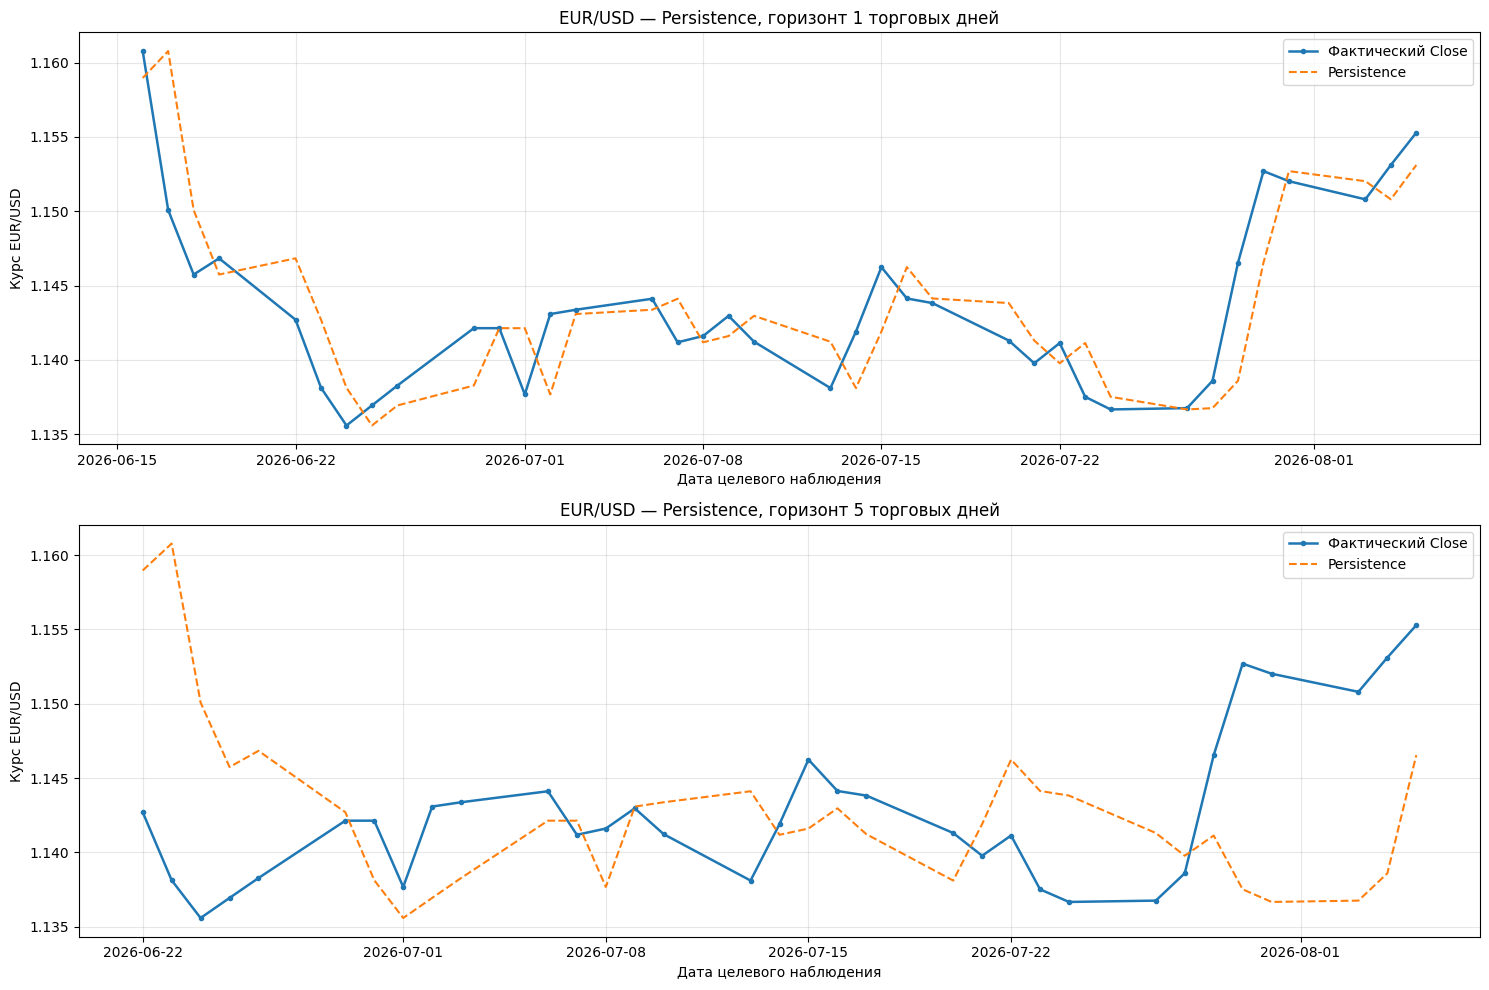

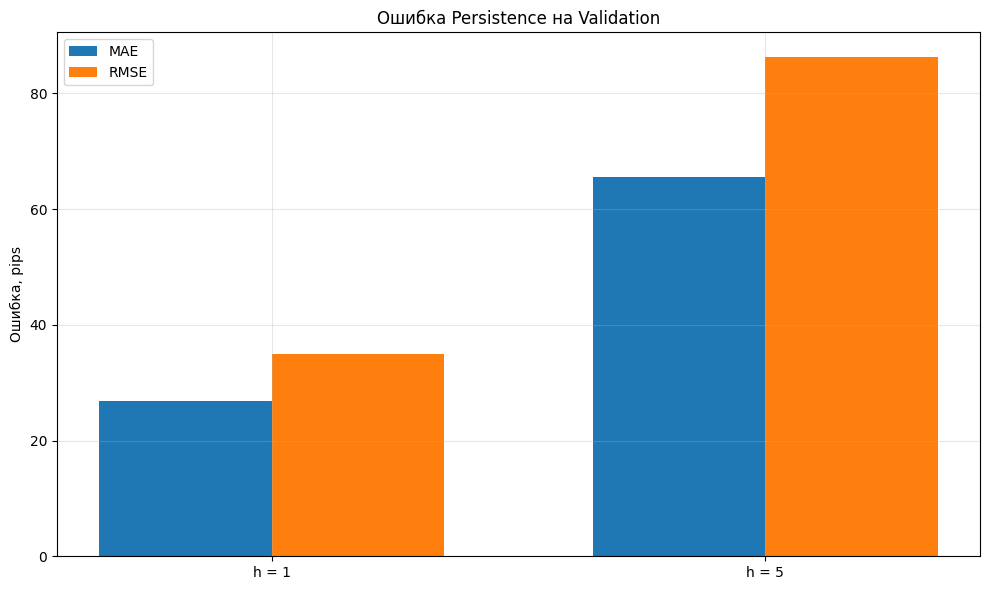

## 11.4. Предварительный аналитический вывод

Проведено наивное прогнозирование EUR/USD на двух горизонтах с использованием Validation.


### Горизонт 1 торговых дней

Число оценённых прогнозов: **37**.

Результаты Persistence:

- MAE: **0.002678**
  (**26.778 pips**).
- RMSE: **0.003498**
  (**34.980 pips**).
- sMAPE: **0.2340%**.
- Directional Accuracy:
  **2.70%**.
- Directional Coverage:
  **0.00%**.

Число случаев фактического отсутствия изменения:
**1**.

Наиболее распространённое направление на Train:
**-1**
(-1 — снижение; 0 — без изменения; +1 — повышение).

Точность стратегии большинства,
определённой исключительно по Train,
на Validation:

**45.95%**.

Persistence остаётся базовым ориентиром
по ошибкам прогнозирования цены.

Направленные стратегии служат отдельными
ориентирами для оценки способности модели
предсказывать повышение или снижение EUR/USD.



### Горизонт 5 торговых дней

Число оценённых прогнозов: **33**.

Результаты Persistence:

- MAE: **0.006552**
  (**65.521 pips**).
- RMSE: **0.008623**
  (**86.233 pips**).
- sMAPE: **0.5726%**.
- Directional Accuracy:
  **0.00%**.
- Directional Coverage:
  **0.00%**.

Число случаев фактического отсутствия изменения:
**0**.

Наиболее распространённое направление на Train:
**-1**
(-1 — снижение; 0 — без изменения; +1 — повышение).

Точность стратегии большинства,
определённой исключительно по Train,
на Validation:

**48.48%**.

Persistence остаётся базовым ориентиром
по ошибкам прогнозирования цены.

Направленные стратегии служат отдельными
ориентирами для оценки способности модели
предсказывать повышение или снижение EUR/USD.



### Методологическое ограничение

Результаты получены на Validation,
а не на независимом финальном Test.

Число наблюдений различается между горизонтами,
поэтому различия ошибок следует трактовать
с учётом разных дат и объёмов выборок.

Сложные модели будут сравниваться
с Persistence на тех же датах
внутри каждого горизонта.

После выбора гиперпараметров
окончательные результаты будут рассчитаны
на отложенном тестовом периоде.

**Первый базовый эксперимент завершён.
Его результаты используются как контрольный ориентир,
а не как доказательство прогнозируемости курса.**


In [ ]:
# ============================================================
# БЛОК 16. ВИЗУАЛИЗАЦИЯ И ПРЕДВАРИТЕЛЬНЫЙ ОТЧЁТ PERSISTENCE
# ============================================================

# ============================================================
# 1. ВИЗУАЛЬНОЕ СРАВНЕНИЕ ФАКТИЧЕСКИХ И ПРОГНОЗНЫХ ЦЕН
# ============================================================

# Создание двух графиков, соответствующих разным горизонтам.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10)
)


# Последовательный перебор горизонтов и соответствующих осей.
for axis, horizon in zip(
    axes,
    FORECAST_HORIZONS
):

    # Получение сохранённой таблицы прогнозов.
    predictions_table = persistence_validation_predictions[
        horizon
    ]


    # Получение дат фактических целевых наблюдений.
    target_dates = pd.to_datetime(
        predictions_table["Дата цели"]
    )


    # Построение фактических значений цены закрытия.
    axis.plot(
        target_dates,
        predictions_table["Фактический Close"],
        linewidth=1.8,
        marker="o",
        markersize=3,
        label="Фактический Close"
    )


    # Построение прогнозных значений Persistence.
    axis.plot(
        target_dates,
        predictions_table["Прогноз Persistence"],
        linewidth=1.5,
        linestyle="--",
        label="Persistence"
    )


    # Установка заголовка текущего графика.
    axis.set_title(
        f"EUR/USD — Persistence, горизонт {horizon} "
        f"торговых дней"
    )


    # Подпись вертикальной оси.
    axis.set_ylabel(
        "Курс EUR/USD"
    )


    # Подпись горизонтальной оси.
    axis.set_xlabel(
        "Дата целевого наблюдения"
    )


    # Добавление координатной сетки.
    axis.grid(
        True,
        alpha=0.3
    )


    # Добавление легенды.
    axis.legend()


# Оптимизация расположения элементов.
plt.tight_layout()


# Вывод сравнительных графиков.
plt.show()


# ============================================================
# 2. ВИЗУАЛИЗАЦИЯ МЕТРИК В СТАНДАРТНЫХ ПУНКТАХ
# ============================================================

# Получение результатов по обоим горизонтам в заданном порядке.
persistence_plot_table = (
    persistence_validation_metrics_table
    .set_index("Горизонт")
    .loc[FORECAST_HORIZONS]
)


# Формирование числовых позиций категорий диаграммы.
bar_positions = np.arange(
    len(FORECAST_HORIZONS)
)


# Определение ширины одного столбца.
BAR_WIDTH = 0.35


# Создание фигуры сравнения ошибок.
figure, axis = plt.subplots(
    figsize=(10, 6)
)


# Построение столбцов MAE.
axis.bar(
    bar_positions - BAR_WIDTH / 2,
    persistence_plot_table["MAE, pips"],
    width=BAR_WIDTH,
    label="MAE"
)


# Построение столбцов RMSE.
axis.bar(
    bar_positions + BAR_WIDTH / 2,
    persistence_plot_table["RMSE, pips"],
    width=BAR_WIDTH,
    label="RMSE"
)


# Установка названий сравниваемых горизонтов.
axis.set_xticks(
    bar_positions,
    [
        f"h = {horizon}"
        for horizon in FORECAST_HORIZONS
    ]
)


# Установка заголовка диаграммы.
axis.set_title(
    "Ошибка Persistence на Validation"
)


# Подпись вертикальной оси.
axis.set_ylabel(
    "Ошибка, pips"
)


# Добавление сетки по вертикальной оси.
axis.grid(
    axis="y",
    alpha=0.3
)


# Добавление легенды.
axis.legend()


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Вывод диаграммы.
plt.show()


# ============================================================
# 3. АВТОМАТИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ
# ============================================================

# Создание списка разделов предварительного заключения.
persistence_conclusion_parts = [
    "## 11.4. Предварительный аналитический вывод",
    (
        "Проведено наивное прогнозирование EUR/USD "
        "на двух горизонтах с использованием Validation."
    )
]


# Последовательный анализ обоих горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение строки метрик текущего горизонта.
    metrics_row = (
        persistence_validation_metrics_table
        .loc[
            persistence_validation_metrics_table[
                "Горизонт"
            ] == horizon
        ]
        .iloc[0]
    )


    # Получение индивидуальных прогнозов текущего горизонта.
    predictions_table = persistence_validation_predictions[
        horizon
    ]


    # Подсчёт фактических случаев нулевого изменения курса.
    unchanged_actual_count = int(
        (
            predictions_table["Фактическое направление"]
            == 0
        ).sum()
    )


    # Получение распределения фактических направлений на Train.
    train_direction_subset = (
        training_direction_distribution_table
        .loc[
            training_direction_distribution_table[
                "Горизонт"
            ] == horizon
        ]
    )


    # Определение наиболее распространённого направления Train.
    majority_direction = int(
        train_direction_subset
        .sort_values(
            "Количество",
            ascending=False
        )
        .iloc[0]["Направление"]
    )


    # Получение точности стратегии большинства на Validation.
    majority_reference_accuracy = float(
        direction_reference_table.loc[
            (
                direction_reference_table["Горизонт"]
                == horizon
            )
            &
            (
                direction_reference_table["Стратегия"]
                == "Большинство на Train"
            ),
            "Directional Accuracy, %"
        ].iloc[0]
    )


    # Формирование отдельного раздела для текущего горизонта.
    horizon_conclusion = f"""
### Горизонт {horizon} торговых дней

Число оценённых прогнозов: **{int(metrics_row['N'])}**.

Результаты Persistence:

- MAE: **{float(metrics_row['MAE']):.6f}**
  (**{float(metrics_row['MAE, pips']):.3f} pips**).
- RMSE: **{float(metrics_row['RMSE']):.6f}**
  (**{float(metrics_row['RMSE, pips']):.3f} pips**).
- sMAPE: **{float(metrics_row['sMAPE, %']):.4f}%**.
- Directional Accuracy:
  **{float(metrics_row['Directional Accuracy, %']):.2f}%**.
- Directional Coverage:
  **{float(metrics_row['Directional Coverage, %']):.2f}%**.

Число случаев фактического отсутствия изменения:
**{unchanged_actual_count}**.

Наиболее распространённое направление на Train:
**{majority_direction}**
(-1 — снижение; 0 — без изменения; +1 — повышение).

Точность стратегии большинства,
определённой исключительно по Train,
на Validation:

**{majority_reference_accuracy:.2f}%**.

Persistence остаётся базовым ориентиром
по ошибкам прогнозирования цены.

Направленные стратегии служат отдельными
ориентирами для оценки способности модели
предсказывать повышение или снижение EUR/USD.
"""


    # Добавление раздела в общее заключение.
    persistence_conclusion_parts.append(
        horizon_conclusion
    )


# Добавление методологического ограничения.
persistence_conclusion_parts.append(
    """
### Методологическое ограничение

Результаты получены на Validation,
а не на независимом финальном Test.

Число наблюдений различается между горизонтами,
поэтому различия ошибок следует трактовать
с учётом разных дат и объёмов выборок.

Сложные модели будут сравниваться
с Persistence на тех же датах
внутри каждого горизонта.

После выбора гиперпараметров
окончательные результаты будут рассчитаны
на отложенном тестовом периоде.

**Первый базовый эксперимент завершён.
Его результаты используются как контрольный ориентир,
а не как доказательство прогнозируемости курса.**
"""
)


# Объединение всех разделов в Markdown.
persistence_preliminary_conclusion = "\n\n".join(
    persistence_conclusion_parts
)


# Отображение автоматически сформированного заключения.
display(
    Markdown(
        persistence_preliminary_conclusion
    )
)

## 12. Классический статистический метод — ARIMA

### 12.1. Назначение метода

ARIMA (Autoregressive Integrated Moving Average) является классическим статистическим методом моделирования и прогнозирования временных рядов.

Метод объединяет следующие инструменты:

- AR(p) — авторегрессионная компонента;
- I(d) — дифференцирование временного ряда;
- MA(q) — компонента скользящего среднего ошибок.

### 12.2. Математическая постановка

Пусть

$$
z_t=\ln(C_t),
$$

где $C_t$ — цена закрытия EUR/USD, тогда модель ARIMA имеет следующий вид:

$$
\phi(B)(1-B)^d z_t
=
c+\theta(B)\varepsilon_t,
$$

где:

- $B$ — оператор временного сдвига;
- $p$ — порядок авторегрессии;
- $d$ — порядок дифференцирования;
- $q$ — порядок скользящего среднего ошибок;
- $\varepsilon_t$ — инновация модели;
- $\phi(B)$ и $\theta(B)$ — соответствующие лаговые полиномы.

Для $d=1$ получается, что

$$
(1-B)z_t=z_t-z_{t-1}
=
\ln\left(\frac{C_t}{C_{t-1}}\right).
$$

Таким образом, первое дифференцирование логарифма курса соответствует логарифмической доходности.

### 12.3. Обоснование выбора ARIMA

Результаты ADF/KPSS показали, что логарифмические доходности согласуются с предположением о стационарности относительно уровня.

При этом для исходного Close и его логарифма получены неоднозначные результаты.

Поэтому основными кандидатами становятся модели ARIMA с $d=1$.

Дополнительно рассматривается модель ARIMA(1,0,0) как представитель спецификаций без дифференцирования.

### 12.4. Исследуемые конфигурации

| Модель | Параметры | Особенность |
|---|---|---|
| ARIMA(0,1,0) | Без дрейфа | Случайное блуждание; контрольный аналог Persistence |
| ARIMA(1,1,0) | Без дрейфа | Авторегрессия первых разностей |
| ARIMA(0,1,1) | Без дрейфа | Скользящее среднее ошибок первых разностей |
| ARIMA(1,1,1) | Без дрейфа | Комбинация AR и MA |
| ARIMA(2,1,0) | Без дрейфа | Авторегрессия второго порядка |
| ARIMA(0,1,2) | Без дрейфа | Скользящее среднее ошибок второго порядка |
| ARIMA(0,1,0) | С дрейфом | Случайное блуждание с линейным трендом |
| ARIMA(1,0,0) | С константой | Авторегрессия уровня логарифма курса |

Набор ограничен моделями небольшой сложности, поскольку доступно только 181 обучающее наблюдение.

### 12.5. Прогнозирование на два горизонта

После завершения торговой сессии $t$ получается прогноз логарифма цены:

$$
\hat z_{t+h|t},\qquad h\in\{1,5\}.
$$

Преобразование в исходный масштаб происходит следующим образом:

$$
\hat C_{t+h|t}
=
\exp(\hat z_{t+h|t}).
$$

Экспоненцирование прогнозного логарифма формирует точечный прогноз цены в исходных единицах. Оно не является автоматической поправкой на смещение при оценивании математического ожидания цены в логнормальной модели.

### 12.6. Схема rolling-origin validation

Модель первоначально обучается на Train, после чего для каждой завершённой сессии Validation выполняются следующие 5 действий:

1. В состояние модели добавляется фактически наблюдённый Close.
2. Параметры модели остаются неизменными.
3. Формируются прогнозы на 1 и 5 торговых дней.
4. Сохраняются только прогнозы с целевыми датами
   внутри Validation.
5. Следующая сессия обрабатывается аналогично.

Такой подход соответствует последовательному обновлению доступной рыночной истории.

**Важно:** Фактические наблюдения Validation используются только после завершения соответствующей торговой сессии, т.к. параметры ARIMA внутри Validation не переоцениваются.

### 12.7. Подбор модели

Для каждого горизонта отдельно выбирается конфигурация с минимальным RMSE на Validation.

Дополнительно анализируются следующие метрики:

- MAE;
- sMAPE;
- Directional Accuracy;
- информационный критерий AIC;
- предупреждения оптимизации;
- вычислительные затраты.

AIC используется как диагностический показатель, но не заменяет оценку качества будущих прогнозов.

### 12.8. Контроль корректности

ARIMA(0,1,0) без дрейфа должна воспроизводить наивный прогноз:

$$
\hat C_{t+h}=C_t.
$$

Данное равенство используется как дополнительный программный тест корректности реализации. Финальная тестовая выборка не используется для настройки или выбора порядка ARIMA.

In [ ]:
# ============================================================
# БЛОК 18. КОНФИГУРАЦИИ И ФУНКЦИИ ПРОГНОЗИРОВАНИЯ ARIMA
# ============================================================

# Импорт статистической модели ARIMA.
from statsmodels.tsa.arima.model import ARIMA

# Импорт предупреждения о проблемах сходимости оптимизатора.
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Импорт механизма измерения времени выполнения.
from time import perf_counter

# Импорт библиотеки обработки предупреждений Python.
import warnings


# ============================================================
# 1. КАНДИДАТНЫЕ МОДЕЛИ
# ============================================================

# Определение словаря ограниченного набора конфигураций ARIMA.
ARIMA_CANDIDATES = {
    "ARIMA(0,1,0)-n": ((0, 1, 0), "n"),
    "ARIMA(1,1,0)-n": ((1, 1, 0), "n"),
    "ARIMA(0,1,1)-n": ((0, 1, 1), "n"),
    "ARIMA(1,1,1)-n": ((1, 1, 1), "n"),
    "ARIMA(2,1,0)-n": ((2, 1, 0), "n"),
    "ARIMA(0,1,2)-n": ((0, 1, 2), "n"),
    "ARIMA(0,1,0)-t": ((0, 1, 0), "t"),
    "ARIMA(1,0,0)-c": ((1, 0, 0), "c")
}


# Определение максимального исследуемого горизонта.
ARIMA_MAX_HORIZON = max(
    FORECAST_HORIZONS
)


# Получение логарифмов обучающих цен закрытия.
arima_train_log_close = np.log(
    eda_train["close"].to_numpy(
        dtype=np.float64
    )
)


# Получение фактических цен закрытия валидационного периода.
arima_validation_close = (
    eda_validation["close"]
    .astype(np.float64)
    .copy()
)


# Проверка объёма исходного обучения.
assert len(arima_train_log_close) == len(eda_train)


# Проверка непрерывности числового представления.
assert np.isfinite(arima_train_log_close).all()


# Проверка количества валидационных сессий.
assert len(arima_validation_close) == len(eda_validation)


# ============================================================
# 2. ФУНКЦИЯ ОБУЧЕНИЯ КОНФИГУРАЦИИ ARIMA
# ============================================================

# Определение функции подгонки ARIMA на обучающем периоде.
def fit_arima_configuration(
    training_log_close,
    order,
    trend
):

    # Фиксация времени начала обучения.
    fit_start_time = perf_counter()


    # Создание контекста для регистрации предупреждений оптимизации.
    with warnings.catch_warnings(record=True) as captured_warnings:

        # Включение регистрации предупреждений о сходимости.
        warnings.simplefilter(
            "always",
            ConvergenceWarning
        )


        # Создание статистической модели указанного порядка.
        arima_model = ARIMA(
            training_log_close,
            order=order,
            trend=trend,
            enforce_stationarity=True,
            enforce_invertibility=True
        )


        # Оценивание параметров только по Train.
        fitted_model = arima_model.fit(
            method_kwargs={
                "maxiter": 200
            }
        )


    # Расчёт времени подгонки модели.
    fit_elapsed_time = (
        perf_counter() - fit_start_time
    )


    # Подсчёт предупреждений о сходимости оптимизатора.
    convergence_warning_count = sum(
        isinstance(
            warning_item.message,
            ConvergenceWarning
        )
        for warning_item in captured_warnings
    )


    # Возврат обученной модели и диагностических характеристик.
    return (
        fitted_model,
        fit_elapsed_time,
        convergence_warning_count
    )


# ============================================================
# 3. ФУНКЦИЯ ROLLING-ORIGIN ПРОГНОЗИРОВАНИЯ
# ============================================================

# Определение функции последовательного обновления ARIMA.
def generate_arima_rolling_predictions(
    fitted_model,
    observed_close,
    horizons
):

    # Формирование списка всех прогнозов.
    predictions_rows = []


    # Получение максимального горизонта прогнозирования.
    maximum_horizon = max(
        horizons
    )


    # Инициализация состояния обученной модели.
    current_model_state = fitted_model


    # Последовательная обработка фактических торговых сессий.
    for origin_date, observed_price in observed_close.items():

        # Преобразование наблюдённой цены в числовой тип.
        observed_price = float(
            observed_price
        )


        # Проверка положительности текущей цены.
        assert observed_price > 0.0


        # Расчёт логарифма фактически наблюдённой цены.
        observed_log_price = np.array(
            [
                np.log(observed_price)
            ],
            dtype=np.float64
        )


        # Обновление состояния модели новым известным наблюдением.
        # Параметры модели при этом не переоцениваются.
        current_model_state = current_model_state.append(
            observed_log_price,
            refit=False
        )


        # Формирование многогоризонтного прогноза логарифма курса.
        predicted_log_prices = np.asarray(
            current_model_state.forecast(
                steps=maximum_horizon
            ),
            dtype=np.float64
        ).reshape(-1)


        # Преобразование прогнозов в исходный масштаб EUR/USD.
        predicted_prices = np.exp(
            predicted_log_prices
        )


        # Проверка конечности и положительности прогнозных цен.
        assert (
            np.isfinite(predicted_prices).all()
            and
            np.all(predicted_prices > 0.0)
        )


        # Формирование строки текущей даты прогноза.
        prediction_row = {
            "Дата прогноза": pd.Timestamp(origin_date),
            "Close на дату прогноза": observed_price
        }


        # Последовательное сохранение прогнозов исследуемых горизонтов.
        for horizon in horizons:

            # Сохранение прогноза будущего Close на текущий горизонт.
            prediction_row[f"Прогноз h={horizon}"] = float(
                predicted_prices[horizon - 1]
            )


        # Добавление текущей строки в список результатов.
        predictions_rows.append(
            prediction_row
        )


    # Создание таблицы последовательных прогнозов.
    predictions_table = pd.DataFrame(
        predictions_rows
    )


    # Установка даты формирования прогноза в качестве индекса.
    predictions_table = predictions_table.set_index(
        "Дата прогноза"
    )


    # Проверка совпадения дат с исходными наблюдениями.
    assert predictions_table.index.equals(
        observed_close.index
    )


    # Возврат таблицы прогнозов.
    return predictions_table


# ============================================================
# 4. ДИАГНОСТИКА ГОТОВНОСТИ
# ============================================================

# Вывод количества кандидатных моделей.
print(
    "Количество конфигураций ARIMA:",
    len(ARIMA_CANDIDATES)
)


# Вывод размера исходного обучения.
print(
    "Длина обучающего ряда:",
    len(arima_train_log_close)
)


# Вывод числа последовательных обновлений Validation.
print(
    "Сессий для rolling-origin:",
    len(arima_validation_close)
)


# Вывод максимального прогнозного горизонта.
print(
    "Максимальный горизонт:",
    ARIMA_MAX_HORIZON
)

Количество конфигураций ARIMA: 8
Длина обучающего ряда: 181
Сессий для rolling-origin: 38
Максимальный горизонт: 5


In [ ]:
# ============================================================
# БЛОК 19. ПОДБОР ARIMA НА VALIDATION
# ============================================================

# Создание списка результатов всех кандидатных моделей.
arima_candidate_metrics_rows = []


# Создание словаря прогнозов каждой конфигурации.
arima_candidate_predictions = {}


# Создание словаря диагностических характеристик обучения.
arima_fit_diagnostics = {}


# ============================================================
# 1. ОБУЧЕНИЕ И ПРОГНОЗИРОВАНИЕ
# ============================================================

# Последовательный перебор кандидатных конфигураций.
for candidate_name, (order, trend) in ARIMA_CANDIDATES.items():

    # Вывод названия текущей конфигурации.
    print(f"\nИсследуется: {candidate_name}")


    # Подгонка текущей модели на Train.
    (
        fitted_arima,
        fit_elapsed_time,
        convergence_warning_count
    ) = fit_arima_configuration(
        training_log_close=arima_train_log_close,
        order=order,
        trend=trend
    )


    # Фиксация начала последовательного прогнозирования.
    rolling_start_time = perf_counter()


    # Генерация прогнозов с обновлением состояния модели.
    rolling_predictions = generate_arima_rolling_predictions(
        fitted_model=fitted_arima,
        observed_close=arima_validation_close,
        horizons=FORECAST_HORIZONS
    )


    # Расчёт времени последовательного прогнозирования.
    rolling_elapsed_time = (
        perf_counter() - rolling_start_time
    )


    # Сохранение всех прогнозов текущей конфигурации.
    arima_candidate_predictions[candidate_name] = (
        rolling_predictions
    )


    # Сохранение диагностических характеристик модели.
    arima_fit_diagnostics[candidate_name] = {
        "Порядок": order,
        "Тренд": trend,
        "AIC": float(fitted_arima.aic),
        "Время обучения, с": fit_elapsed_time,
        "Время rolling, с": rolling_elapsed_time,
        "Предупреждения сходимости": convergence_warning_count
    }


    # ========================================================
    # 2. РАСЧЁТ МЕТРИК НА ДВУХ ГОРИЗОНТАХ
    # ========================================================

    # Последовательный перебор горизонтов прогнозирования.
    for horizon in FORECAST_HORIZONS:

        # Получение исходной валидационной выборки.
        validation_partition = forecast_splits[horizon][
            "validation"
        ]


        # Получение имени фактической будущей цены.
        target_close_column = forecast_splits[horizon][
            "target_close_column"
        ]


        # Отбор прогнозов только на разрешённые даты Validation.
        aligned_predictions = rolling_predictions.loc[
            validation_partition.index
        ]


        # Проверка совпадения количества прогнозных наблюдений.
        assert len(aligned_predictions) == len(
            validation_partition
        )


        # Получение фактического будущего Close.
        actual_close = validation_partition[
            target_close_column
        ].to_numpy(
            dtype=np.float64
        )


        # Получение курса в момент формирования прогнозов.
        origin_close = validation_partition[
            "close"
        ].to_numpy(
            dtype=np.float64
        )


        # Получение соответствующих прогнозов ARIMA.
        predicted_close = aligned_predictions[
            f"Прогноз h={horizon}"
        ].to_numpy(
            dtype=np.float64
        )


        # Проверка совпадения известных исходных цен.
        assert np.allclose(
            aligned_predictions[
                "Close на дату прогноза"
            ].to_numpy(dtype=np.float64),
            origin_close,
            rtol=0.0,
            atol=1e-12
        )


        # Расчёт общих метрик прогнозирования.
        current_metrics = calculate_forecast_metrics(
            actual_close=actual_close,
            predicted_close=predicted_close,
            origin_close=origin_close
        )


        # Добавление результатов текущего кандидата и горизонта.
        arima_candidate_metrics_rows.append(
            {
                "Конфигурация": candidate_name,
                "Горизонт": horizon,
                "Порядок": str(order),
                "Тренд": trend,
                **current_metrics,
                "MAE, pips": (
                    current_metrics["MAE"] / EURUSD_PIP_SIZE
                ),
                "RMSE, pips": (
                    current_metrics["RMSE"] / EURUSD_PIP_SIZE
                ),
                "AIC": float(fitted_arima.aic),
                "Время обучения, с": fit_elapsed_time,
                "Время rolling, с": rolling_elapsed_time,
                "Предупреждения сходимости": (
                    convergence_warning_count
                ),
                "Сложность": (
                    order[0]
                    + order[2]
                    + int(trend != "n")
                )
            }
        )


    # Вывод краткой диагностики завершённого кандидата.
    print(
        f"AIC: {fitted_arima.aic:.3f}; "
        f"обучение: {fit_elapsed_time:.3f} с; "
        f"rolling: {rolling_elapsed_time:.3f} с; "
        f"предупреждений сходимости: "
        f"{convergence_warning_count}"
    )


# ============================================================
# 3. ОБЩАЯ ТАБЛИЦА КАЧЕСТВА
# ============================================================

# Формирование таблицы всех результатов Validation.
arima_validation_results_table = pd.DataFrame(
    arima_candidate_metrics_rows
)


# Сортировка результатов по горизонту, RMSE и MAE.
arima_validation_results_table = (
    arima_validation_results_table
    .sort_values(
        by=[
            "Горизонт",
            "RMSE",
            "MAE",
            "Сложность"
        ],
        kind="stable"
    )
    .reset_index(drop=True)
)


# Вывод компактного рейтинга конфигураций.
print("\nРезультаты всех ARIMA на Validation:")

display(
    arima_validation_results_table[
        [
            "Конфигурация",
            "Горизонт",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "AIC",
            "Предупреждения сходимости"
        ]
    ].round(5)
)


# ============================================================
# 4. КОНТРОЛЬ ARIMA(0,1,0) = PERSISTENCE
# ============================================================

# Последовательная проверка обоих горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение соответствующих дат Validation.
    validation_indices = forecast_splits[horizon][
        "validation"
    ].index


    # Получение прогнозов случайного блуждания без дрейфа.
    random_walk_predictions = (
        arima_candidate_predictions["ARIMA(0,1,0)-n"]
        .loc[
            validation_indices,
            f"Прогноз h={horizon}"
        ]
        .to_numpy(dtype=np.float64)
    )


    # Получение наивных прогнозов из блока 14.
    persistence_predictions = (
        persistence_validation_predictions[horizon][
            "Прогноз Persistence"
        ].to_numpy(dtype=np.float64)
    )


    # Проверка математического совпадения обоих прогнозов.
    assert np.allclose(
        random_walk_predictions,
        persistence_predictions,
        rtol=0.0,
        atol=1e-9
    ), (
        f"ARIMA(0,1,0) и Persistence расходятся "
        f"на горизонте {horizon}."
    )


# Вывод результата проверки.
print(
    "\nКонтроль пройден: ARIMA(0,1,0) без дрейфа "
    "воспроизводит Persistence."
)


# ============================================================
# 5. ВЫБОР ЛУЧШЕЙ КОНФИГУРАЦИИ ДЛЯ КАЖДОГО ГОРИЗОНТА
# ============================================================

# Создание словаря выбранных конфигураций.
arima_best_configurations = {}


# Создание словаря прогнозов выбранных моделей.
arima_best_validation_predictions = {}


# Создание списка итоговых метрик победителей.
arima_best_validation_rows = []


# Последовательный выбор модели для каждого горизонта.
for horizon in FORECAST_HORIZONS:

    # Получение упорядоченных результатов текущего горизонта.
    horizon_ranking = (
        arima_validation_results_table.loc[
            arima_validation_results_table["Горизонт"]
            == horizon
        ]
        .sort_values(
            by=["RMSE", "MAE", "Сложность"]
        )
    )


    # Получение первой строки — модели с минимальным RMSE.
    best_row = horizon_ranking.iloc[0]


    # Получение названия победившей конфигурации.
    best_candidate_name = str(
        best_row["Конфигурация"]
    )


    # Получение порядка и тренда из исходного словаря кандидатов.
    best_order, best_trend = ARIMA_CANDIDATES[
        best_candidate_name
    ]


    # Сохранение окончательной конфигурации текущего горизонта.
    arima_best_configurations[horizon] = {
        "name": best_candidate_name,
        "order": best_order,
        "trend": best_trend
    }


    # Получение валидационной выборки данного горизонта.
    validation_partition = forecast_splits[horizon][
        "validation"
    ]


    # Получение названий столбцов фактической цели и её даты.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]

    target_date_column = forecast_splits[horizon][
        "target_date_column"
    ]


    # Получение прогнозов победившей модели на нужные даты.
    selected_predictions = arima_candidate_predictions[
        best_candidate_name
    ].loc[
        validation_partition.index
    ]


    # Формирование таблицы индивидуальных прогнозов победителя.
    best_predictions_table = pd.DataFrame(
        {
            "Дата цели": validation_partition[
                target_date_column
            ].to_numpy(),

            "Close на дату прогноза": validation_partition[
                "close"
            ].to_numpy(dtype=np.float64),

            "Фактический Close": validation_partition[
                target_close_column
            ].to_numpy(dtype=np.float64),

            "Прогноз ARIMA": selected_predictions[
                f"Прогноз h={horizon}"
            ].to_numpy(dtype=np.float64)
        },
        index=validation_partition.index
    )


    # Установка имени индекса дат формирования прогнозов.
    best_predictions_table.index.name = "Дата прогноза"


    # Расчёт ошибки выбранной ARIMA в единицах котировки.
    best_predictions_table["Ошибка"] = (
        best_predictions_table["Фактический Close"]
        -
        best_predictions_table["Прогноз ARIMA"]
    )


    # Расчёт абсолютной ошибки в пунктах EUR/USD.
    best_predictions_table["Абсолютная ошибка, pips"] = (
        best_predictions_table["Ошибка"].abs()
        /
        EURUSD_PIP_SIZE
    )


    # Сохранение индивидуальных прогнозов.
    arima_best_validation_predictions[horizon] = (
        best_predictions_table
    )


    # Сохранение строки метрик победившей конфигурации.
    arima_best_validation_rows.append(
        best_row.to_dict()
    )


# Формирование таблицы лучших конфигураций ARIMA.
arima_best_validation_metrics_table = pd.DataFrame(
    arima_best_validation_rows
).sort_values(
    "Горизонт"
).reset_index(
    drop=True
)


# Вывод результатов выбора конфигураций.
print("\nЛучшие конфигурации ARIMA по Validation RMSE:")

display(
    arima_best_validation_metrics_table[
        [
            "Горизонт",
            "Конфигурация",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Предупреждения сходимости"
        ]
    ].round(6)
)


# Вывод предупреждения, если выбранная модель имела проблемы сходимости.
for _, best_row in arima_best_validation_metrics_table.iterrows():

    # Проверка наличия предупреждений оптимизатора.
    if int(best_row["Предупреждения сходимости"]) > 0:

        # Вывод рекомендации о дополнительной диагностике модели.
        print(
            f"Внимание: {best_row['Конфигурация']} "
            f"для h={int(best_row['Горизонт'])} "
            "имеет предупреждения сходимости. "
            "Перед финальным использованием нужна проверка."
        )


Исследуется: ARIMA(0,1,0)-n
AIC: -1518.839; обучение: 0.072 с; rolling: 0.147 с; предупреждений сходимости: 0

Исследуется: ARIMA(1,1,0)-n
AIC: -1516.904; обучение: 0.028 с; rolling: 0.146 с; предупреждений сходимости: 0

Исследуется: ARIMA(0,1,1)-n
AIC: -1516.894; обучение: 0.033 с; rolling: 0.204 с; предупреждений сходимости: 0

Исследуется: ARIMA(1,1,1)-n
AIC: -1514.815; обучение: 0.034 с; rolling: 0.219 с; предупреждений сходимости: 0

Исследуется: ARIMA(2,1,0)-n
AIC: -1515.609; обучение: 0.046 с; rolling: 0.202 с; предупреждений сходимости: 0

Исследуется: ARIMA(0,1,2)-n
AIC: -1515.933; обучение: 0.041 с; rolling: 0.175 с; предупреждений сходимости: 0

Исследуется: ARIMA(0,1,0)-t
AIC: -1516.913; обучение: 0.044 с; rolling: 0.239 с; предупреждений сходимости: 0

Исследуется: ARIMA(1,0,0)-c
AIC: -1528.538; обучение: 0.044 с; rolling: 0.178 с; предупреждений сходимости: 0

Результаты всех ARIMA на Validation:


,Конфигурация,Горизонт,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %",AIC,Предупреждения сходимости
0,"ARIMA(1,1,0)-n",1,37,26.695930,34.847890,0.233240,54.054050,97.297300,-1516.904090,0
1,"ARIMA(0,1,1)-n",1,37,26.717530,34.884280,0.233430,56.756760,100.000000,-1516.894310,0
2,"ARIMA(1,1,1)-n",1,37,26.830060,34.930930,0.234410,43.243240,100.000000,-1514.814670,0
3,"ARIMA(0,1,0)-t",1,37,26.848780,34.964290,0.234580,45.945950,100.000000,-1516.913440,0
4,"ARIMA(0,1,0)-n",1,37,26.778380,34.979890,0.233960,2.702700,0.000000,-1518.839160,0
5,"ARIMA(2,1,0)-n",1,37,27.625190,35.327640,0.241350,29.729730,100.000000,-1515.608740,0
6,"ARIMA(0,1,2)-n",1,37,28.142210,35.651190,0.245860,24.324320,100.000000,-1515.933330,0
7,"ARIMA(1,0,0)-c",1,37,30.314620,37.943420,0.264800,51.351350,100.000000,-1528.538480,0
8,"ARIMA(0,1,2)-n",5,33,65.647900,86.060420,0.573740,39.393940,100.000000,-1515.933330,0
9,"ARIMA(2,1,0)-n",5,33,65.646320,86.139830,0.573720,39.393940,100.000000,-1515.608740,0



Контроль пройден: ARIMA(0,1,0) без дрейфа воспроизводит Persistence.

Лучшие конфигурации ARIMA по Validation RMSE:


,Горизонт,Конфигурация,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %",Предупреждения сходимости
0,1,"ARIMA(1,1,0)-n",37,26.695927,34.847888,0.233240,54.054054,97.297297,0
1,5,"ARIMA(0,1,2)-n",33,65.647900,86.060421,0.573737,39.393939,100.000000,0


## 13. Сравнение ARIMA с наивным прогнозом

### 13.1. Цель сравнительного анализа

Определить, обеспечивает ли классическая статистическая модель ARIMA улучшение
по сравнению с Persistence. Сравнение выполняется отдельно для горизонтов 1 и 5 торговых дней.

### 13.2. Относительное улучшение

Для произвольной метрики ошибки $E$ вычисляется следующий показатель:

$$
\Delta E=
100\left(
1-\frac{E_{\mathrm{ARIMA}}}
{E_{\mathrm{Persistence}}}
\right).
$$

Положительное значение показывает снижение ошибки ARIMA относительно baseline.
Отрицательное значение показывает, что ARIMA уступает Persistence.

### 13.3. Принципы интерпретации

Все модели сравниваются на одинаковых датах Validation внутри каждого горизонта.

Дополнительно учитываются следующие факторы:

- сложность выбранной конфигурации;
- точность определения направления;
- предупреждения оптимизатора;
- вычислительные затраты;
- размер контрольной выборки.

Улучшение на Validation не является независимым доказательством обобщающей способности, поэтому окончательное сравнение моделей будет выполнено на финальном Test после завершения настройки всех методов.

Сравнение ARIMA и Persistence на Validation:


,Горизонт,Лучшая ARIMA,"Persistence MAE, pips","ARIMA MAE, pips","Улучшение MAE, %","Persistence RMSE, pips","ARIMA RMSE, pips","Улучшение RMSE, %","ARIMA Directional Accuracy, %","ARIMA Directional Coverage, %"
0,1,"ARIMA(1,1,0)-n",26.778380,26.695930,0.307900,34.979890,34.847890,0.377380,54.054050,97.297300
1,5,"ARIMA(0,1,2)-n",65.521210,65.647900,-0.193350,86.233270,86.060420,0.200450,39.393940,100.000000


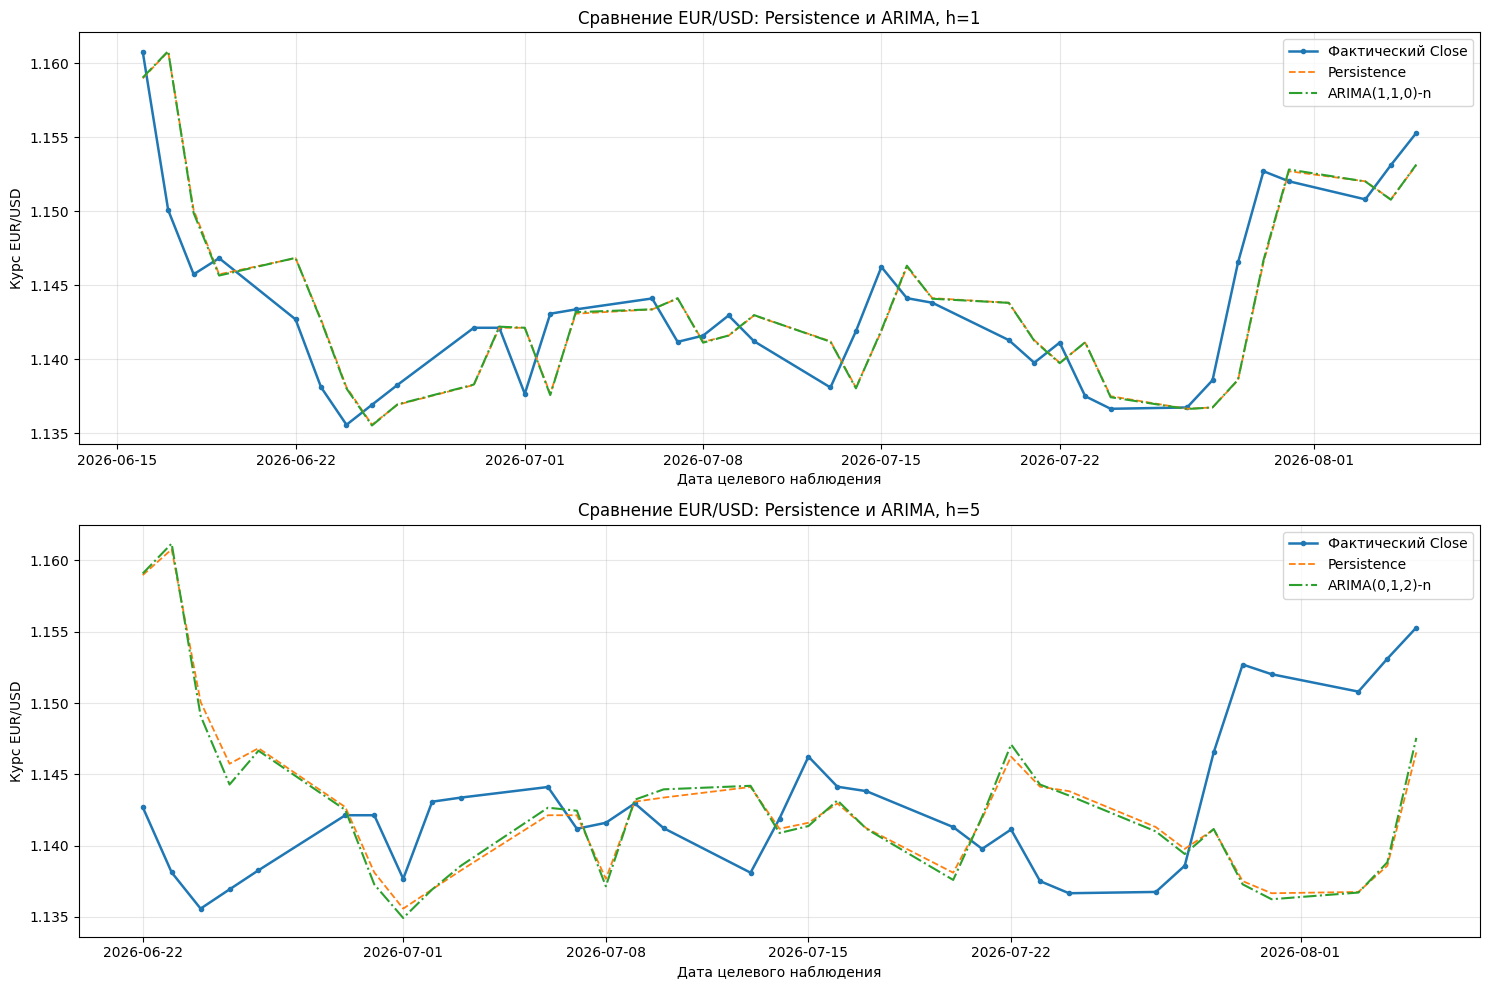

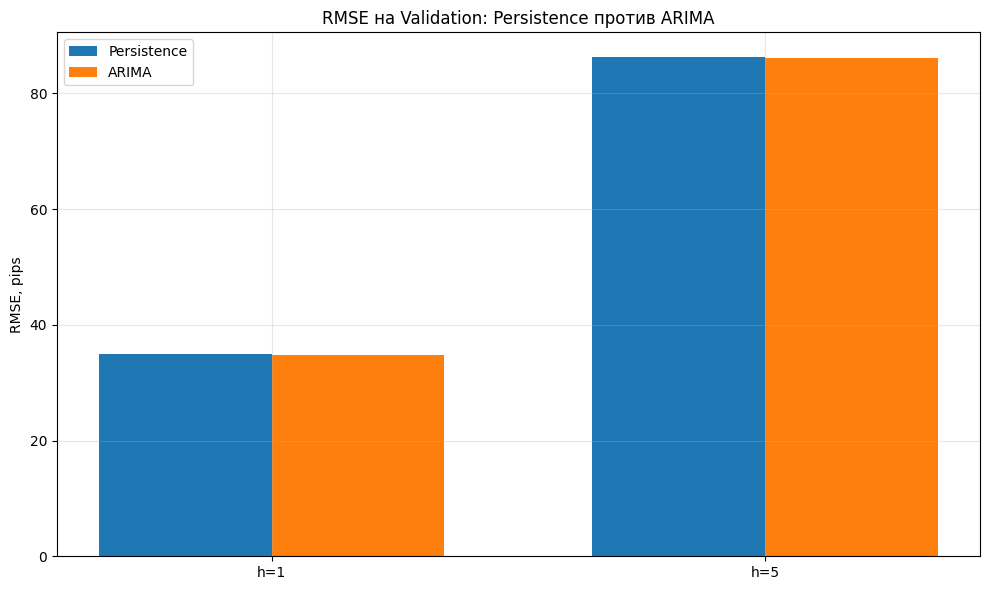

## 13.4. Предварительный аналитический вывод

Исследованы восемь конфигураций ARIMA на логарифме дневной цены закрытия EUR/USD. Подбор осуществлялся по RMSE на Validation.


### Горизонт 1 торговых дней

Выбранная модель:
**ARIMA(1,1,0)-n**.

Ошибка Persistence:

- MAE: **26.778 pips**.
- RMSE: **34.980 pips**.

Ошибка ARIMA:

- MAE: **26.696 pips**.
- RMSE: **34.848 pips**.

Относительное изменение:

- Улучшение MAE: **+0.308%**.
- Улучшение RMSE: **+0.377%**.

Directional Accuracy:
**54.05%**.

Directional Coverage:
**97.30%**.

**Интерпретация:** ARIMA уменьшила RMSE относительно Persistence.

**Диагностика:** Предупреждений сходимости при обучении не зарегистрировано.



### Горизонт 5 торговых дней

Выбранная модель:
**ARIMA(0,1,2)-n**.

Ошибка Persistence:

- MAE: **65.521 pips**.
- RMSE: **86.233 pips**.

Ошибка ARIMA:

- MAE: **65.648 pips**.
- RMSE: **86.060 pips**.

Относительное изменение:

- Улучшение MAE: **-0.193%**.
- Улучшение RMSE: **+0.200%**.

Directional Accuracy:
**39.39%**.

Directional Coverage:
**100.00%**.

**Интерпретация:** ARIMA уменьшила RMSE относительно Persistence.

**Диагностика:** Предупреждений сходимости при обучении не зарегистрировано.



### Общий методологический вывод

ARIMA представляет собой классический статистический
подход к прогнозированию финансовых временных рядов.

Для всех исследованных конфигураций использовались:

- одинаковый обучающий временной период;
- одинаковые даты Validation внутри каждого горизонта;
- последовательное обновление состояния модели;
- фиксированные параметры во время прогнозирования;
- единая функция расчёта метрик.

Результаты не позволяют заранее утверждать,
что ARIMA универсально превосходит наивный прогноз.

Выбор конфигурации по Validation создаёт
определённый риск оптимистической оценки качества.

Для независимого подтверждения результатов
необходима финальная проверка на Test.

До её выполнения текущие выводы
считаются предварительными.


In [ ]:
# ============================================================
# БЛОК 20. СРАВНЕНИЕ ARIMA И PERSISTENCE
# ============================================================

# Создание списка результатов попарного сравнения.
arima_comparison_rows = []


# ============================================================
# 1. ЧИСЛОВОЕ СРАВНЕНИЕ МЕТРИК
# ============================================================

# Последовательный перебор двух горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение метрик Persistence на текущем горизонте.
    persistence_row = persistence_validation_metrics_table.loc[
        persistence_validation_metrics_table["Горизонт"]
        == horizon
    ].iloc[0]


    # Получение метрик лучшей ARIMA на текущем горизонте.
    arima_row = arima_best_validation_metrics_table.loc[
        arima_best_validation_metrics_table["Горизонт"]
        == horizon
    ].iloc[0]


    # Проверка совпадения количества контрольных примеров.
    assert int(persistence_row["N"]) == int(arima_row["N"])


    # Получение MAE базового метода.
    persistence_mae = float(
        persistence_row["MAE"]
    )


    # Получение RMSE базового метода.
    persistence_rmse = float(
        persistence_row["RMSE"]
    )


    # Получение MAE выбранной ARIMA.
    arima_mae = float(
        arima_row["MAE"]
    )


    # Получение RMSE выбранной ARIMA.
    arima_rmse = float(
        arima_row["RMSE"]
    )


    # Расчёт относительного улучшения MAE.
    mae_improvement_pct = (
        100.0
        *
        (
            1.0 - arima_mae / persistence_mae
        )
    )


    # Расчёт относительного улучшения RMSE.
    rmse_improvement_pct = (
        100.0
        *
        (
            1.0 - arima_rmse / persistence_rmse
        )
    )


    # Добавление характеристик сравнения в общую таблицу.
    arima_comparison_rows.append(
        {
            "Горизонт": horizon,
            "Лучшая ARIMA": arima_row["Конфигурация"],
            "Persistence MAE, pips": (
                persistence_mae / EURUSD_PIP_SIZE
            ),
            "ARIMA MAE, pips": (
                arima_mae / EURUSD_PIP_SIZE
            ),
            "Улучшение MAE, %": mae_improvement_pct,
            "Persistence RMSE, pips": (
                persistence_rmse / EURUSD_PIP_SIZE
            ),
            "ARIMA RMSE, pips": (
                arima_rmse / EURUSD_PIP_SIZE
            ),
            "Улучшение RMSE, %": rmse_improvement_pct,
            "ARIMA Directional Accuracy, %": float(
                arima_row["Directional Accuracy, %"]
            ),
            "ARIMA Directional Coverage, %": float(
                arima_row["Directional Coverage, %"]
            )
        }
    )


# Формирование итоговой сравнительной таблицы.
arima_comparison_table = pd.DataFrame(
    arima_comparison_rows
)


# Вывод числовых результатов.
print("Сравнение ARIMA и Persistence на Validation:")

display(
    arima_comparison_table.round(5)
)


# ============================================================
# 2. ВИЗУАЛИЗАЦИЯ ФАКТИЧЕСКИХ И ПРОГНОЗНЫХ ЗНАЧЕНИЙ
# ============================================================

# Создание фигуры с двумя графиками.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10)
)


# Последовательное построение графиков обоих горизонтов.
for axis, horizon in zip(
    axes,
    FORECAST_HORIZONS
):

    # Получение прогнозов выбранной ARIMA.
    arima_predictions = arima_best_validation_predictions[
        horizon
    ]


    # Получение соответствующих прогнозов Persistence.
    persistence_predictions = persistence_validation_predictions[
        horizon
    ]


    # Проверка совпадения дат формирования прогнозов.
    assert arima_predictions.index.equals(
        persistence_predictions.index
    )


    # Проверка совпадения фактических будущих курсов.
    assert np.allclose(
        arima_predictions["Фактический Close"],
        persistence_predictions["Фактический Close"]
    )


    # Получение дат фактических целевых наблюдений.
    target_dates = pd.to_datetime(
        arima_predictions["Дата цели"]
    )


    # Отображение фактической цены закрытия.
    axis.plot(
        target_dates,
        arima_predictions["Фактический Close"],
        linewidth=1.8,
        marker="o",
        markersize=3,
        label="Фактический Close"
    )


    # Отображение базового наивного прогноза.
    axis.plot(
        target_dates,
        persistence_predictions["Прогноз Persistence"],
        linewidth=1.3,
        linestyle="--",
        label="Persistence"
    )


    # Отображение прогнозов выбранной статистической модели.
    axis.plot(
        target_dates,
        arima_predictions["Прогноз ARIMA"],
        linewidth=1.5,
        linestyle="-.",
        label=arima_best_configurations[horizon]["name"]
    )


    # Установка заголовка текущего графика.
    axis.set_title(
        f"Сравнение EUR/USD: Persistence и ARIMA, h={horizon}"
    )


    # Установка подписи вертикальной оси.
    axis.set_ylabel(
        "Курс EUR/USD"
    )


    # Установка подписи горизонтальной оси.
    axis.set_xlabel(
        "Дата целевого наблюдения"
    )


    # Добавление сетки и легенды.
    axis.grid(True, alpha=0.3)
    axis.legend()


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Вывод сравнительных графиков.
plt.show()


# ============================================================
# 3. СРАВНЕНИЕ ОШИБОК В ПУНКТАХ EUR/USD
# ============================================================

# Создание фигуры для сравнения RMSE.
figure, axis = plt.subplots(
    figsize=(10, 6)
)


# Формирование позиций сравниваемых горизонтов.
bar_positions = np.arange(
    len(arima_comparison_table)
)


# Определение ширины столбцов.
BAR_WIDTH = 0.35


# Построение RMSE Persistence.
axis.bar(
    bar_positions - BAR_WIDTH / 2,
    arima_comparison_table["Persistence RMSE, pips"],
    width=BAR_WIDTH,
    label="Persistence"
)


# Построение RMSE ARIMA.
axis.bar(
    bar_positions + BAR_WIDTH / 2,
    arima_comparison_table["ARIMA RMSE, pips"],
    width=BAR_WIDTH,
    label="ARIMA"
)


# Установка подписей горизонтов.
axis.set_xticks(
    bar_positions,
    [
        f"h={horizon}"
        for horizon in arima_comparison_table["Горизонт"]
    ]
)


# Установка заголовка диаграммы.
axis.set_title(
    "RMSE на Validation: Persistence против ARIMA"
)


# Установка подписи вертикальной оси.
axis.set_ylabel(
    "RMSE, pips"
)


# Добавление легенды и координатной сетки.
axis.legend()
axis.grid(axis="y", alpha=0.3)


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Отображение диаграммы.
plt.show()


# ============================================================
# 4. АВТОМАТИЧЕСКОЕ ПРЕДВАРИТЕЛЬНОЕ ЗАКЛЮЧЕНИЕ
# ============================================================

# Создание списка разделов аналитического заключения.
arima_conclusion_parts = [
    "## 13.4. Предварительный аналитический вывод",
    (
        "Исследованы восемь конфигураций ARIMA на логарифме "
        "дневной цены закрытия EUR/USD. "
        "Подбор осуществлялся по RMSE на Validation."
    )
]


# Последовательное формирование выводов по обоим горизонтам.
for _, comparison_row in arima_comparison_table.iterrows():

    # Получение числового значения горизонта.
    horizon = int(
        comparison_row["Горизонт"]
    )


    # Получение относительного улучшения RMSE.
    improvement_rmse = float(
        comparison_row["Улучшение RMSE, %"]
    )


    # Получение относительного улучшения MAE.
    improvement_mae = float(
        comparison_row["Улучшение MAE, %"]
    )


    # Определение характера изменения RMSE.
    if improvement_rmse > 1e-8:

        # Формирование вывода о снижении ошибки.
        rmse_interpretation = (
            "ARIMA уменьшила RMSE относительно Persistence."
        )

    elif improvement_rmse < -1e-8:

        # Формирование вывода об увеличении ошибки.
        rmse_interpretation = (
            "ARIMA уступила Persistence по RMSE."
        )

    else:

        # Формирование вывода о практически одинаковой ошибке.
        rmse_interpretation = (
            "ARIMA и Persistence имеют практически "
            "одинаковую RMSE."
        )


    # Получение количества предупреждений выбранной модели.
    selected_warning_count = int(
        arima_best_validation_metrics_table.loc[
            arima_best_validation_metrics_table["Горизонт"]
            == horizon,
            "Предупреждения сходимости"
        ].iloc[0]
    )


    # Формирование пояснения о сходимости оптимизации.
    convergence_note = (
        "Зарегистрированы предупреждения сходимости; "
        "необходима дополнительная проверка параметров."
        if selected_warning_count > 0
        else "Предупреждений сходимости при обучении не зарегистрировано."
    )


    # Формирование Markdown-раздела текущего горизонта.
    current_conclusion = f"""
### Горизонт {horizon} торговых дней

Выбранная модель:
**{comparison_row['Лучшая ARIMA']}**.

Ошибка Persistence:

- MAE: **{comparison_row['Persistence MAE, pips']:.3f} pips**.
- RMSE: **{comparison_row['Persistence RMSE, pips']:.3f} pips**.

Ошибка ARIMA:

- MAE: **{comparison_row['ARIMA MAE, pips']:.3f} pips**.
- RMSE: **{comparison_row['ARIMA RMSE, pips']:.3f} pips**.

Относительное изменение:

- Улучшение MAE: **{improvement_mae:+.3f}%**.
- Улучшение RMSE: **{improvement_rmse:+.3f}%**.

Directional Accuracy:
**{comparison_row['ARIMA Directional Accuracy, %']:.2f}%**.

Directional Coverage:
**{comparison_row['ARIMA Directional Coverage, %']:.2f}%**.

**Интерпретация:** {rmse_interpretation}

**Диагностика:** {convergence_note}
"""


    # Добавление сформированного раздела в общий отчёт.
    arima_conclusion_parts.append(
        current_conclusion
    )


# Добавление общего методологического вывода.
arima_conclusion_parts.append(
    """
### Общий методологический вывод

ARIMA представляет собой классический статистический
подход к прогнозированию финансовых временных рядов.

Для всех исследованных конфигураций использовались:

- одинаковый обучающий временной период;
- одинаковые даты Validation внутри каждого горизонта;
- последовательное обновление состояния модели;
- фиксированные параметры во время прогнозирования;
- единая функция расчёта метрик.

Результаты не позволяют заранее утверждать,
что ARIMA универсально превосходит наивный прогноз.

Выбор конфигурации по Validation создаёт
определённый риск оптимистической оценки качества.

Для независимого подтверждения результатов
необходима финальная проверка на Test.

До её выполнения текущие выводы
считаются предварительными.
"""
)


# Объединение разделов в единый Markdown-документ.
arima_preliminary_conclusion = "\n\n".join(
    arima_conclusion_parts
)


# Отображение автоматически сформированного заключения.
display(
    Markdown(
        arima_preliminary_conclusion
    )
)

## 14. Машинное обучение — Gradient Boosting

### 14.1. Назначение метода

Gradient Boosting является ансамблевым методом машинного обучения, в котором несколько последовательно обучаемых деревьев решений формируют общую прогнозную функцию.

В отличие от ARIMA, метод не требует заранее задавать линейную вторегрессионную структуру временного ряда.

Нелинейные зависимости извлекаются из подготовленных числовых признаков.

### 14.2. Математическая постановка

Для каждого торгового дня $t$ известен вектор причинно корректных признаков:

$$
\mathbf{x}_t \in \mathbb{R}^{13}.
$$

Целевой переменной для горизонта $h$ выступает будущая логарифмическая доходность:

$$
g_{t,h}=
\ln\left(\frac{C_{t+h}}{C_t}\right).
$$

Обученная модель формирует прогноз:

$$
\widehat g_{t,h}=F_h(\mathbf{x}_t).
$$

Прогноз курса восстанавливается по следующей формуле:

$$
\widehat C_{t+h}
=
C_t\exp(\widehat g_{t,h}).
$$

Для горизонтов $h=1$ и $h=5$ обучаются отдельные модели.

### 14.3. Принцип градиентного бустинга

Ансамбль формируется последовательно следующим образом:

$$
F_m(\mathbf{x})=
F_{m-1}(\mathbf{x})+
\eta T_m(\mathbf{x}),
$$

где:

- $F_m$ — ансамбль после $m$ итераций;
- $T_m$ — очередное дерево решений;
- $\eta$ — коэффициент скорости обучения;
- $m$ — номер итерации.

Каждое новое дерево обучается улучшать текущий прогноз ансамбля относительно
выбранной функции потерь.

### 14.4. Исследуемые параметры

В исследовании рассматриваются 8 компактных конфигураций и изменяются следующие параметры Gradient Boosting:

- количество деревьев;
- максимальная глубина дерева;
- скорость обучения;
- минимальное количество объектов в листе;
- доля обучающих наблюдений для каждого дерева;
- функция потерь.

В процессе используются 2 функции потерь:

1) **Squared Error** — квадратичная ошибка.
2) **Huber Loss** — сочетание квадратичного и линейного штрафа, снижающее влияние отдельных больших отклонений.

### 14.5. Ограничение сложности

Поскольку обучающая выборка небольшая, то основное внимание уделяется неглубоким деревьям.

Ограничения глубины и размера листьев уменьшают вероятность формирования
чрезмерно специфических правил.

Стохастическое обучение и небольшая скорость обучения используются
как дополнительные механизмы регуляризации, однако наличие регуляризации не гарантирует отсутствие переобучения.

### 14.6. Протокол обучения и проверки

Для каждого горизонта воспроизводятся следующие 7 шагов:

1. Используется подготовленная выборка Train.
2. Обучаются восемь конфигураций Gradient Boosting.
3. На Validation формируются прямые прогнозы.
4. Прогнозы доходности переводятся в цену EUR/USD.
5. Рассчитываются общие метрики качества.
6. Выбирается конфигурация с минимальным RMSE.
7. Результат сравнивается с Persistence и ARIMA.

Столбцы с будущими целевыми значениями не включаются во входные признаки.

Даты Validation используются только для оценки качества и выбора конфигурации.
Финальный Test не используется.

### 14.7. Сопоставимость с ARIMA

ARIMA применяет rolling-origin прогнозирование с обновлением состояния по известным наблюдениям.

Gradient Boosting использует фиксированные обученные параметры и готовые признаки, доступные на дату формирования прогноза.

Оба подхода получают одинаковую историческую информацию к моменту $t$
и оцениваются на одинаковых целевых датах.

### 14.8. Исследовательская гипотеза

Предполагается, что Gradient Boosting может использовать нелинейные зависимости
между характеристиками дневных свечей, доходностями и волатильностью. Однако из-за ограниченного объёма данных более высокая сложность модели может привести к переобучению, поэтому превосходство над Persistence и ARIMA должно быть установлено экспериментально.

In [ ]:
# ============================================================
# БЛОК 22. ОБУЧЕНИЕ И ОЦЕНКА GRADIENT BOOSTING
# ============================================================

# Импорт ансамблевой регрессионной модели Gradient Boosting.
from sklearn.ensemble import GradientBoostingRegressor

# Импорт функции измерения времени выполнения.
from time import perf_counter

# Импорт библиотеки scikit-learn для фиксации версии.
import sklearn


# ============================================================
# 1. КОНФИГУРАЦИИ КАНДИДАТНЫХ МОДЕЛЕЙ
# ============================================================

# Формирование ограниченного набора конфигураций модели.
GRADIENT_BOOSTING_CANDIDATES = {
    "GBR_01_Stump_80": {
        "n_estimators": 80,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_samples_leaf": 8,
        "subsample": 1.0,
        "loss": "squared_error"
    },

    "GBR_02_Stump_160": {
        "n_estimators": 160,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_samples_leaf": 8,
        "subsample": 1.0,
        "loss": "squared_error"
    },

    "GBR_03_Stump_Huber": {
        "n_estimators": 100,
        "learning_rate": 0.04,
        "max_depth": 1,
        "min_samples_leaf": 10,
        "subsample": 0.9,
        "loss": "huber"
    },

    "GBR_04_Depth2_80": {
        "n_estimators": 80,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 10,
        "subsample": 1.0,
        "loss": "squared_error"
    },

    "GBR_05_Depth2_Huber": {
        "n_estimators": 120,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 12,
        "subsample": 0.85,
        "loss": "huber"
    },

    "GBR_06_Depth2_160": {
        "n_estimators": 160,
        "learning_rate": 0.02,
        "max_depth": 2,
        "min_samples_leaf": 12,
        "subsample": 0.85,
        "loss": "squared_error"
    },

    "GBR_07_Depth3_Huber": {
        "n_estimators": 80,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_samples_leaf": 15,
        "subsample": 0.85,
        "loss": "huber"
    },

    "GBR_08_Depth2_60": {
        "n_estimators": 60,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 15,
        "subsample": 1.0,
        "loss": "huber"
    }
}


# Вывод установленной версии scikit-learn.
print("Версия scikit-learn:", sklearn.__version__)


# Вывод количества исследуемых конфигураций.
print(
    "Конфигураций Gradient Boosting:",
    len(GRADIENT_BOOSTING_CANDIDATES)
)


# Вывод общего количества обучаемых моделей.
print(
    "Всего обучений:",
    len(GRADIENT_BOOSTING_CANDIDATES)
    * len(FORECAST_HORIZONS)
)


# ============================================================
# 2. ПОДГОТОВКА ХРАНИЛИЩ РЕЗУЛЬТАТОВ
# ============================================================

# Создание словаря для сохранения обученных моделей.
gradient_boosting_candidate_models = {}


# Создание словаря индивидуальных прогнозов Validation.
gradient_boosting_candidate_predictions = {}


# Создание списка строк сравнительной таблицы.
gradient_boosting_candidate_metrics_rows = []


# ============================================================
# 3. ОБУЧЕНИЕ ДЛЯ КАЖДОГО ГОРИЗОНТА
# ============================================================

# Последовательный перебор горизонтов прогнозирования.
for horizon in FORECAST_HORIZONS:

    # Вывод заголовка текущего горизонта.
    print(f"\n{'=' * 55}")
    print(f"Горизонт прогнозирования: {horizon}")


    # Получение обучающей выборки.
    train_partition = forecast_splits[horizon]["train"]


    # Получение валидационной выборки.
    validation_partition = forecast_splits[horizon]["validation"]


    # Получение имени целевого столбца будущей доходности.
    target_return_column = forecast_splits[horizon][
        "target_return_column"
    ]


    # Получение имени столбца фактического будущего Close.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]


    # Получение имени столбца даты целевого наблюдения.
    target_date_column = forecast_splits[horizon][
        "target_date_column"
    ]


    # Формирование матрицы обучающих признаков.
    X_train_gb = train_partition[
        MODEL_FEATURE_COLUMNS
    ].copy()


    # Формирование матрицы валидационных признаков.
    X_validation_gb = validation_partition[
        MODEL_FEATURE_COLUMNS
    ].copy()


    # Получение обучающих целевых логарифмических доходностей.
    y_train_gb = train_partition[
        target_return_column
    ].to_numpy(dtype=np.float64)


    # Получение цен закрытия в начале обучающих прогнозов.
    origin_train_gb = train_partition[
        "close"
    ].to_numpy(dtype=np.float64)


    # Получение фактических будущих цен на Train.
    actual_train_gb = train_partition[
        target_close_column
    ].to_numpy(dtype=np.float64)


    # Получение цен закрытия в начале прогнозов Validation.
    origin_validation_gb = validation_partition[
        "close"
    ].to_numpy(dtype=np.float64)


    # Получение фактических будущих цен на Validation.
    actual_validation_gb = validation_partition[
        target_close_column
    ].to_numpy(dtype=np.float64)


    # Проверка одинакового состава признаков Train и Validation.
    assert X_train_gb.columns.equals(
        X_validation_gb.columns
    )


    # Проверка отсутствия пропущенных или бесконечных признаков.
    assert np.isfinite(
        X_train_gb.to_numpy(dtype=np.float64)
    ).all()


    # Проверка корректности валидационных признаков.
    assert np.isfinite(
        X_validation_gb.to_numpy(dtype=np.float64)
    ).all()


    # Проверка конечности обучающей целевой переменной.
    assert np.isfinite(y_train_gb).all()


    # Вывод количества обучающих и валидационных примеров.
    print(
        f"Train: {len(X_train_gb)}; "
        f"Validation: {len(X_validation_gb)}"
    )


    # ========================================================
    # 4. ПЕРЕБОР ГИПЕРПАРАМЕТРОВ
    # ========================================================

    # Последовательное исследование кандидатных конфигураций.
    for candidate_name, candidate_parameters in (
        GRADIENT_BOOSTING_CANDIDATES.items()
    ):

        # Создание модели с заданными параметрами.
        candidate_model = GradientBoostingRegressor(
            **candidate_parameters,
            random_state=RANDOM_STATE,
            n_iter_no_change=None
        )


        # Фиксация времени начала обучения.
        training_start_time = perf_counter()


        # Обучение модели исключительно на Train.
        candidate_model.fit(
            X_train_gb,
            y_train_gb
        )


        # Расчёт времени обучения.
        training_elapsed_time = (
            perf_counter() - training_start_time
        )


        # Фиксация времени начала прогнозирования Validation.
        prediction_start_time = perf_counter()


        # Прогнозирование будущих логарифмических доходностей.
        predicted_validation_returns = (
            candidate_model.predict(
                X_validation_gb
            )
        )


        # Преобразование доходностей в будущие цены EUR/USD.
        predicted_validation_close = (
            origin_validation_gb
            *
            np.exp(predicted_validation_returns)
        )


        # Расчёт времени прогнозирования Validation.
        prediction_elapsed_time = (
            perf_counter() - prediction_start_time
        )


        # Проверка конечности и положительности прогнозных цен.
        assert (
            np.isfinite(predicted_validation_close).all()
            and
            np.all(predicted_validation_close > 0.0)
        )


        # Расчёт универсальных метрик на Validation.
        validation_metrics = calculate_forecast_metrics(
            actual_close=actual_validation_gb,
            predicted_close=predicted_validation_close,
            origin_close=origin_validation_gb
        )


        # ====================================================
        # 5. ДИАГНОСТИКА ОБУЧАЮЩЕЙ ОШИБКИ
        # ====================================================

        # Получение прогнозных доходностей на обучающих примерах.
        predicted_training_returns = (
            candidate_model.predict(
                X_train_gb
            )
        )


        # Восстановление прогнозных цен обучающих примеров.
        predicted_training_close = (
            origin_train_gb
            *
            np.exp(predicted_training_returns)
        )


        # Расчёт метрик на обучающих примерах.
        training_metrics = calculate_forecast_metrics(
            actual_close=actual_train_gb,
            predicted_close=predicted_training_close,
            origin_close=origin_train_gb
        )


        # Расчёт разности RMSE между Validation и Train в pips.
        rmse_gap_pips = (
            validation_metrics["RMSE"]
            -
            training_metrics["RMSE"]
        ) / EURUSD_PIP_SIZE


        # ====================================================
        # 6. СОХРАНЕНИЕ МОДЕЛИ И ИНДИВИДУАЛЬНЫХ ПРОГНОЗОВ
        # ====================================================

        # Формирование уникального ключа модели.
        candidate_key = (
            horizon,
            candidate_name
        )


        # Сохранение обученного экземпляра модели.
        gradient_boosting_candidate_models[
            candidate_key
        ] = candidate_model


        # Создание таблицы валидационных прогнозов.
        predictions_table = pd.DataFrame(
            {
                "Дата цели": validation_partition[
                    target_date_column
                ].to_numpy(),

                "Close на дату прогноза": origin_validation_gb,

                "Фактический Close": actual_validation_gb,

                "Прогноз Gradient Boosting": (
                    predicted_validation_close
                ),

                "Прогноз логарифмической доходности": (
                    predicted_validation_returns
                )
            },
            index=validation_partition.index
        )


        # Установка имени индекса дат формирования прогнозов.
        predictions_table.index.name = "Дата прогноза"


        # Расчёт ошибки прогноза в единицах котировки.
        predictions_table["Ошибка"] = (
            predictions_table["Фактический Close"]
            -
            predictions_table["Прогноз Gradient Boosting"]
        )


        # Расчёт абсолютной ошибки в пунктах EUR/USD.
        predictions_table["Абсолютная ошибка, pips"] = (
            predictions_table["Ошибка"].abs()
            /
            EURUSD_PIP_SIZE
        )


        # Сохранение прогнозов текущей конфигурации.
        gradient_boosting_candidate_predictions[
            candidate_key
        ] = predictions_table


        # ====================================================
        # 7. СОХРАНЕНИЕ МЕТРИК КОНФИГУРАЦИИ
        # ====================================================

        # Добавление результатов в сводную таблицу.
        gradient_boosting_candidate_metrics_rows.append(
            {
                "Конфигурация": candidate_name,
                "Горизонт": horizon,
                "N": validation_metrics["N"],
                "MAE": validation_metrics["MAE"],
                "RMSE": validation_metrics["RMSE"],
                "MAE, pips": (
                    validation_metrics["MAE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "RMSE, pips": (
                    validation_metrics["RMSE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "sMAPE, %": validation_metrics["sMAPE, %"],
                "Directional Accuracy, %": (
                    validation_metrics["Directional Accuracy, %"]
                ),
                "Directional Coverage, %": (
                    validation_metrics["Directional Coverage, %"]
                ),
                "Active Direction Accuracy, %": (
                    validation_metrics["Active Direction Accuracy, %"]
                ),
                "Train RMSE, pips": (
                    training_metrics["RMSE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "Validation-Train RMSE gap, pips": rmse_gap_pips,
                "Деревьев": candidate_parameters["n_estimators"],
                "Глубина": candidate_parameters["max_depth"],
                "Размер листа": candidate_parameters["min_samples_leaf"],
                "Learning rate": candidate_parameters["learning_rate"],
                "Subsample": candidate_parameters["subsample"],
                "Loss": candidate_parameters["loss"],
                "Время обучения, с": training_elapsed_time,
                "Время прогноза, с": prediction_elapsed_time,
                "Сложность": (
                    candidate_parameters["n_estimators"]
                    *
                    candidate_parameters["max_depth"]
                )
            }
        )


        # Вывод краткой информации о завершённой конфигурации.
        print(
            f"{candidate_name}: "
            f"RMSE = {validation_metrics['RMSE'] / EURUSD_PIP_SIZE:.3f} pips; "
            f"Train RMSE = {training_metrics['RMSE'] / EURUSD_PIP_SIZE:.3f} pips; "
            f"время = {training_elapsed_time:.3f} с"
        )


# ============================================================
# 8. ИТОГОВАЯ ТАБЛИЦА КАНДИДАТНЫХ МОДЕЛЕЙ
# ============================================================

# Формирование таблицы всех результатов Gradient Boosting.
gradient_boosting_validation_results_table = pd.DataFrame(
    gradient_boosting_candidate_metrics_rows
)


# Сортировка результатов по горизонту и качеству Validation.
gradient_boosting_validation_results_table = (
    gradient_boosting_validation_results_table
    .sort_values(
        [
            "Горизонт",
            "RMSE",
            "MAE",
            "Сложность"
        ],
        kind="stable"
    )
    .reset_index(drop=True)
)


# Вывод сравнительной таблицы.
print("\nРезультаты Gradient Boosting на Validation:")

display(
    gradient_boosting_validation_results_table[
        [
            "Конфигурация",
            "Горизонт",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Train RMSE, pips",
            "Validation-Train RMSE gap, pips",
            "Время обучения, с"
        ]
    ].round(5)
)


# Проверка общего количества исследованных конфигураций.
assert len(
    gradient_boosting_validation_results_table
) == (
    len(GRADIENT_BOOSTING_CANDIDATES)
    *
    len(FORECAST_HORIZONS)
)


# Вывод подтверждения завершения эксперимента.
print(
    "\nВсе конфигурации обучены на Train "
    "и оценены на Validation."
)

Версия scikit-learn: 1.6.1
Конфигураций Gradient Boosting: 8
Всего обучений: 16

Горизонт прогнозирования: 1
Train: 160; Validation: 37
GBR_01_Stump_80: RMSE = 42.167 pips; Train RMSE = 39.051 pips; время = 0.077 с
GBR_02_Stump_160: RMSE = 45.167 pips; Train RMSE = 37.723 pips; время = 0.150 с
GBR_03_Stump_Huber: RMSE = 38.610 pips; Train RMSE = 38.130 pips; время = 0.185 с
GBR_04_Depth2_80: RMSE = 37.743 pips; Train RMSE = 36.894 pips; время = 0.127 с
GBR_05_Depth2_Huber: RMSE = 37.602 pips; Train RMSE = 35.366 pips; время = 0.300 с
GBR_06_Depth2_160: RMSE = 38.133 pips; Train RMSE = 35.305 pips; время = 0.205 с
GBR_07_Depth3_Huber: RMSE = 35.823 pips; Train RMSE = 37.056 pips; время = 0.270 с
GBR_08_Depth2_60: RMSE = 36.058 pips; Train RMSE = 36.888 pips; время = 0.133 с

Горизонт прогнозирования: 5
Train: 156; Validation: 33
GBR_01_Stump_80: RMSE = 94.918 pips; Train RMSE = 82.083 pips; время = 0.067 с
GBR_02_Stump_160: RMSE = 99.618 pips; Train RMSE = 75.944 pips; время = 0.108 с
G

,Конфигурация,Горизонт,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Train RMSE, pips","Validation-Train RMSE gap, pips","Время обучения, с"
0,GBR_07_Depth3_Huber,1,37,28.138370,35.823500,0.245810,54.054050,100.000000,37.055850,-1.232350,0.270060
1,GBR_08_Depth2_60,1,37,28.325800,36.058380,0.247450,56.756760,100.000000,36.888250,-0.829860,0.132980
2,GBR_05_Depth2_Huber,1,37,30.744340,37.601690,0.268540,54.054050,100.000000,35.365720,2.235970,0.299540
3,GBR_04_Depth2_80,1,37,30.687590,37.742970,0.268040,51.351350,100.000000,36.894280,0.848690,0.126760
4,GBR_06_Depth2_160,1,37,31.013930,38.132920,0.270910,54.054050,100.000000,35.305030,2.827890,0.204840
5,GBR_03_Stump_Huber,1,37,31.493510,38.610350,0.275060,54.054050,100.000000,38.130330,0.480030,0.185240
6,GBR_01_Stump_80,1,37,35.286040,42.166930,0.308210,51.351350,100.000000,39.051380,3.115540,0.077320
7,GBR_02_Stump_160,1,37,38.329530,45.167000,0.334760,51.351350,100.000000,37.722750,7.444250,0.149600
8,GBR_01_Stump_80,5,33,76.527160,94.917790,0.668000,57.575760,100.000000,82.083000,12.834790,0.067220
9,GBR_07_Depth3_Huber,5,33,79.386620,96.088370,0.692950,57.575760,100.000000,70.699650,25.388720,0.171620



Все конфигурации обучены на Train и оценены на Validation.


In [ ]:
# ============================================================
# БЛОК 23. ВЫБОР GRADIENT BOOSTING И СРАВНЕНИЕ МОДЕЛЕЙ
# ============================================================

# Создание словаря выбранных конфигураций.
gradient_boosting_best_configurations = {}


# Создание словаря выбранных обученных моделей.
gradient_boosting_best_models = {}


# Создание словаря прогнозов победителей.
gradient_boosting_best_validation_predictions = {}


# Создание списка строк метрик победителей.
gradient_boosting_best_rows = []


# Создание списка сравнительных результатов трёх семейств.
gradient_boosting_comparison_rows = []


# ============================================================
# 1. ВЫБОР ЛУЧШЕЙ КОНФИГУРАЦИИ ПО КАЖДОМУ ГОРИЗОНТУ
# ============================================================

# Последовательный перебор горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение результатов всех конфигураций текущего горизонта.
    horizon_results = (
        gradient_boosting_validation_results_table
        .loc[
            gradient_boosting_validation_results_table[
                "Горизонт"
            ] == horizon
        ]
        .sort_values(
            ["RMSE", "MAE", "Сложность"],
            kind="stable"
        )
    )


    # Выбор строки с минимальным RMSE.
    best_row = horizon_results.iloc[0]


    # Получение названия оптимальной конфигурации.
    best_name = str(
        best_row["Конфигурация"]
    )


    # Получение параметров исходной конфигурации.
    best_parameters = (
        GRADIENT_BOOSTING_CANDIDATES[best_name].copy()
    )


    # Сохранение выбранной конфигурации текущего горизонта.
    gradient_boosting_best_configurations[horizon] = {
        "name": best_name,
        "parameters": best_parameters
    }


    # Сохранение соответствующей обученной модели.
    gradient_boosting_best_models[horizon] = (
        gradient_boosting_candidate_models[
            (horizon, best_name)
        ]
    )


    # Сохранение индивидуальных прогнозов победителя.
    gradient_boosting_best_validation_predictions[horizon] = (
        gradient_boosting_candidate_predictions[
            (horizon, best_name)
        ].copy()
    )


    # Добавление метрик победителя в общую таблицу.
    gradient_boosting_best_rows.append(
        best_row.to_dict()
    )


    # ========================================================
    # 2. ПОЛУЧЕНИЕ МЕТРИК PERSISTENCE И ARIMA
    # ========================================================

    # Получение результата Persistence.
    persistence_row = (
        persistence_validation_metrics_table
        .loc[
            persistence_validation_metrics_table[
                "Горизонт"
            ] == horizon
        ]
        .iloc[0]
    )


    # Получение результата оптимальной ARIMA.
    arima_row = (
        arima_best_validation_metrics_table
        .loc[
            arima_best_validation_metrics_table[
                "Горизонт"
            ] == horizon
        ]
        .iloc[0]
    )


    # Проверка одинакового объёма контрольной выборки.
    assert (
        int(best_row["N"])
        ==
        int(persistence_row["N"])
        ==
        int(arima_row["N"])
    )


    # ========================================================
    # 3. ПРОВЕРКА СОВПАДЕНИЯ ВРЕМЕННЫХ ДАТ
    # ========================================================

    # Получение прогнозов Gradient Boosting.
    gb_predictions = (
        gradient_boosting_best_validation_predictions[horizon]
    )


    # Получение прогнозов Persistence.
    persistence_predictions = (
        persistence_validation_predictions[horizon]
    )


    # Получение прогнозов ARIMA.
    arima_predictions = (
        arima_best_validation_predictions[horizon]
    )


    # Проверка совпадения дат формирования прогнозов.
    assert (
        gb_predictions.index.equals(
            persistence_predictions.index
        )
        and
        gb_predictions.index.equals(
            arima_predictions.index
        )
    )


    # Проверка совпадения дат целевых наблюдений.
    assert np.array_equal(
        gb_predictions["Дата цели"].to_numpy(),
        persistence_predictions["Дата цели"].to_numpy()
    )


    # Проверка совпадения фактических цен.
    assert np.allclose(
        gb_predictions["Фактический Close"],
        arima_predictions["Фактический Close"],
        rtol=0.0,
        atol=1e-12
    )


    # Проверка совпадения цен на даты формирования прогнозов.
    assert np.allclose(
        gb_predictions["Close на дату прогноза"],
        persistence_predictions["Close на дату прогноза"],
        rtol=0.0,
        atol=1e-12
    )


    # ========================================================
    # 4. РАСЧЁТ ОТНОСИТЕЛЬНОГО УЛУЧШЕНИЯ
    # ========================================================

    # Получение значения RMSE Persistence.
    persistence_rmse = float(
        persistence_row["RMSE"]
    )


    # Получение значения MAE Persistence.
    persistence_mae = float(
        persistence_row["MAE"]
    )


    # Получение значения RMSE Gradient Boosting.
    gb_rmse = float(
        best_row["RMSE"]
    )


    # Получение значения MAE Gradient Boosting.
    gb_mae = float(
        best_row["MAE"]
    )


    # Расчёт улучшения RMSE относительно Persistence.
    rmse_improvement_vs_persistence = (
        100.0 * (1.0 - gb_rmse / persistence_rmse)
    )


    # Расчёт улучшения MAE относительно Persistence.
    mae_improvement_vs_persistence = (
        100.0 * (1.0 - gb_mae / persistence_mae)
    )


    # Расчёт улучшения RMSE относительно ARIMA.
    rmse_improvement_vs_arima = (
        100.0
        *
        (1.0 - gb_rmse / float(arima_row["RMSE"]))
    )


    # Добавление результатов сравнения.
    gradient_boosting_comparison_rows.append(
        {
            "Горизонт": horizon,
            "Лучшая GBR": best_name,
            "N": int(best_row["N"]),
            "Persistence RMSE, pips": (
                persistence_rmse / EURUSD_PIP_SIZE
            ),
            "ARIMA RMSE, pips": (
                float(arima_row["RMSE"]) / EURUSD_PIP_SIZE
            ),
            "GBR RMSE, pips": (
                gb_rmse / EURUSD_PIP_SIZE
            ),
            "Persistence MAE, pips": (
                persistence_mae / EURUSD_PIP_SIZE
            ),
            "ARIMA MAE, pips": (
                float(arima_row["MAE"]) / EURUSD_PIP_SIZE
            ),
            "GBR MAE, pips": (
                gb_mae / EURUSD_PIP_SIZE
            ),
            "Улучшение RMSE vs Persistence, %": (
                rmse_improvement_vs_persistence
            ),
            "Улучшение MAE vs Persistence, %": (
                mae_improvement_vs_persistence
            ),
            "Улучшение RMSE vs ARIMA, %": (
                rmse_improvement_vs_arima
            ),
            "GBR Directional Accuracy, %": float(
                best_row["Directional Accuracy, %"]
            ),
            "GBR Directional Coverage, %": float(
                best_row["Directional Coverage, %"]
            )
        }
    )


# ============================================================
# 5. ИТОГОВЫЕ ТАБЛИЦЫ
# ============================================================

# Формирование таблицы выбранных моделей Gradient Boosting.
gradient_boosting_best_validation_metrics_table = (
    pd.DataFrame(gradient_boosting_best_rows)
    .sort_values("Горизонт")
    .reset_index(drop=True)
)


# Формирование сравнительной таблицы трёх семейств моделей.
gradient_boosting_comparison_table = (
    pd.DataFrame(gradient_boosting_comparison_rows)
    .sort_values("Горизонт")
    .reset_index(drop=True)
)


# Вывод лучших конфигураций Gradient Boosting.
print("Лучшие конфигурации Gradient Boosting:")

display(
    gradient_boosting_best_validation_metrics_table[
        [
            "Горизонт",
            "Конфигурация",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Train RMSE, pips",
            "Validation-Train RMSE gap, pips"
        ]
    ].round(5)
)


# Вывод сравнения Gradient Boosting с двумя базовыми семействами.
print("\nСравнение Persistence, ARIMA и Gradient Boosting:")

display(
    gradient_boosting_comparison_table.round(5)
)


# Вывод выбранных параметров отдельно для каждого горизонта.
for horizon in FORECAST_HORIZONS:

    # Получение сохранённой конфигурации.
    selected_configuration = (
        gradient_boosting_best_configurations[horizon]
    )


    # Вывод названия выбранной модели.
    print(
        f"\nГоризонт {horizon}: "
        f"{selected_configuration['name']}"
    )


    # Вывод набора параметров.
    print(
        "Параметры:",
        selected_configuration["parameters"]
    )


# Вывод подтверждения завершения выбора моделей.
print(
    "\nПобедители зафиксированы по Validation RMSE. "
    "Test не использовался."
)

Лучшие конфигурации Gradient Boosting:


,Горизонт,Конфигурация,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Train RMSE, pips","Validation-Train RMSE gap, pips"
0,1,GBR_07_Depth3_Huber,37,28.138370,35.823500,0.245810,54.054050,100.000000,37.055850,-1.232350
1,5,GBR_01_Stump_80,33,76.527160,94.917790,0.668000,57.575760,100.000000,82.083000,12.834790



Сравнение Persistence, ARIMA и Gradient Boosting:


,Горизонт,Лучшая GBR,N,"Persistence RMSE, pips","ARIMA RMSE, pips","GBR RMSE, pips","Persistence MAE, pips","ARIMA MAE, pips","GBR MAE, pips","Улучшение RMSE vs Persistence, %","Улучшение MAE vs Persistence, %","Улучшение RMSE vs ARIMA, %","GBR Directional Accuracy, %","GBR Directional Coverage, %"
0,1,GBR_07_Depth3_Huber,37,34.979890,34.847890,35.823500,26.778380,26.695930,28.138370,-2.411680,-5.078690,-2.799620,54.054050,100.000000
1,5,GBR_01_Stump_80,33,86.233270,86.060420,94.917790,65.521210,65.647900,76.527160,-10.070960,-16.797540,-10.292040,57.575760,100.000000



Горизонт 1: GBR_07_Depth3_Huber
Параметры: {'n_estimators': 80, 'learning_rate': 0.02, 'max_depth': 3, 'min_samples_leaf': 15, 'subsample': 0.85, 'loss': 'huber'}

Горизонт 5: GBR_01_Stump_80
Параметры: {'n_estimators': 80, 'learning_rate': 0.03, 'max_depth': 1, 'min_samples_leaf': 8, 'subsample': 1.0, 'loss': 'squared_error'}

Победители зафиксированы по Validation RMSE. Test не использовался.


## 15. Анализ результатов Gradient Boosting

### 15.1. Сравнение прогнозов

Для обоих горизонтов визуально сопоставляются следующие метрики:

- фактические цены EUR/USD;
- прогноз Persistence;
- прогноз оптимальной ARIMA;
- прогноз оптимального Gradient Boosting.

Все методы оцениваются на одинаковых датах целевых наблюдений внутри соответствующего горизонта.

### 15.2. Интерпретация признаков

Gradient Boosting предоставляет показатель `feature_importances_`.
Он характеризует относительный вклад признаков в уменьшение критерия разбиения деревьев. Этот показатель является внутренней характеристикой обученного ансамбля.

Он не доказывает причинного влияния отдельного рыночного параметра на будущий курс. Особенно важно учитывать корреляции между Open, High, Low, Close и производными признаками.

### 15.3. Анализ переобучения

Сопоставляются RMSE на Train и Validation. Существенное превышение валидационной ошибки над обучающей может указывать на переобучение, однако различие периодов также способно влиять на статистические характеристики ряда.

### 15.4. Ограничения выводов

Оптимальная конфигурация выбрана по Validation. Следовательно, полученный результат имеет определённую оптимистическую смещённость как оценка будущего качества. Независимая проверка будет выполнена на Test после настройки всех семейств моделей.

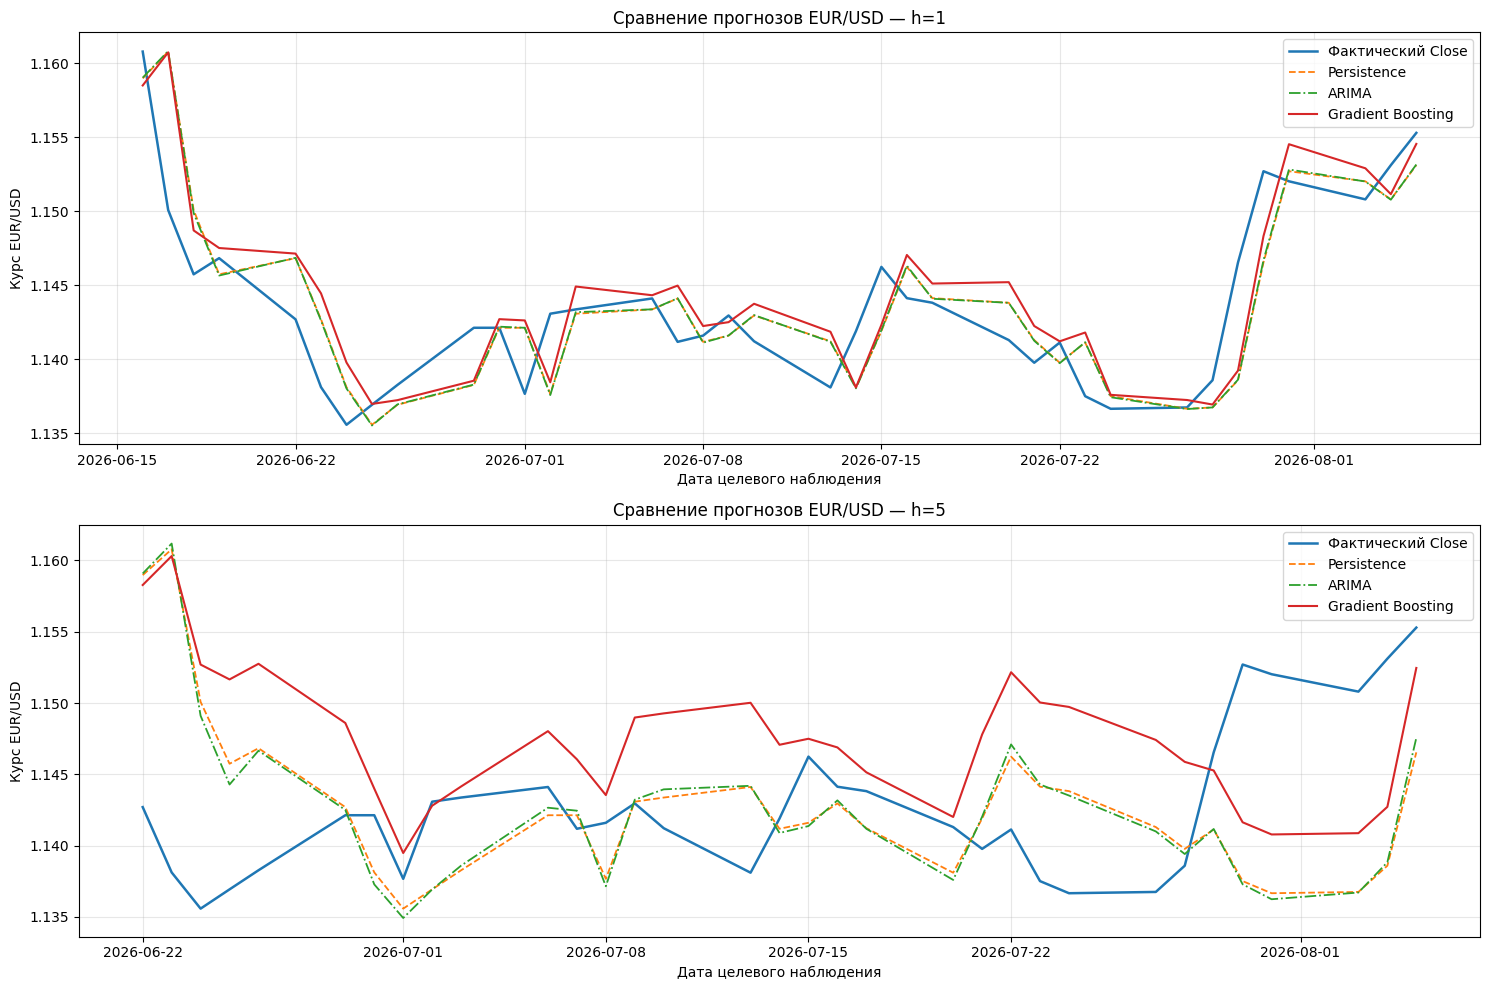

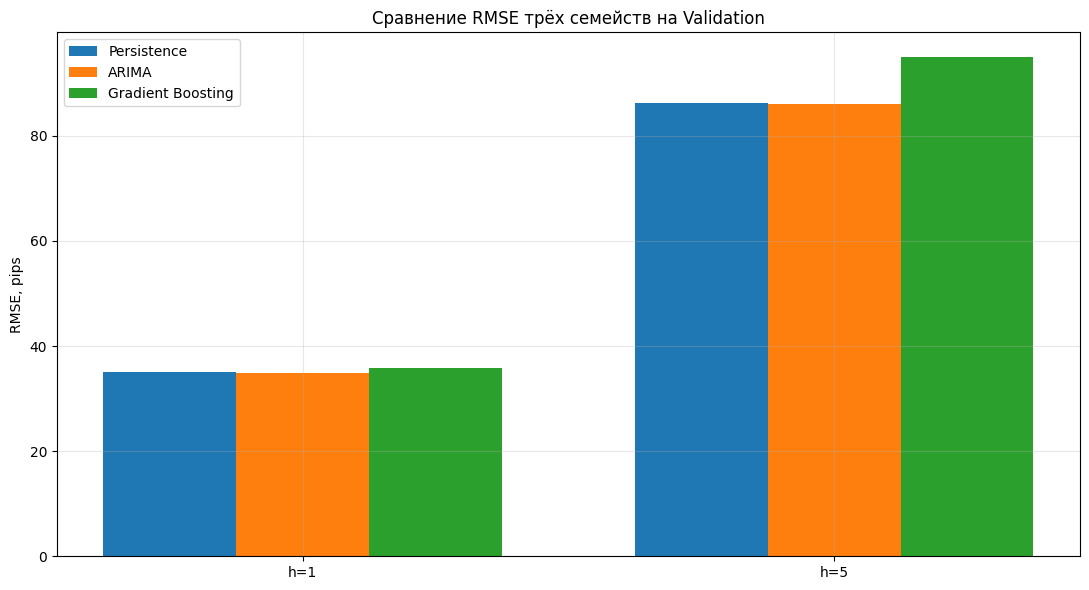

Внутренняя важность признаков Gradient Boosting:


,h=1,h=5,Средняя важность
Признак,,,
low,0.088590,0.381106,0.234848
rolling_volatility_5,0.126855,0.162798,0.144826
high,0.077977,0.202441,0.140209
close,0.036392,0.188358,0.112375
rolling_volatility_20,0.069996,0.058760,0.064378
open,0.108008,0.006536,0.057272
log_return_5,0.105747,0.000000,0.052873
log_return_1,0.100315,0.000000,0.050158
rolling_return_mean_5,0.099063,0.000000,0.049532


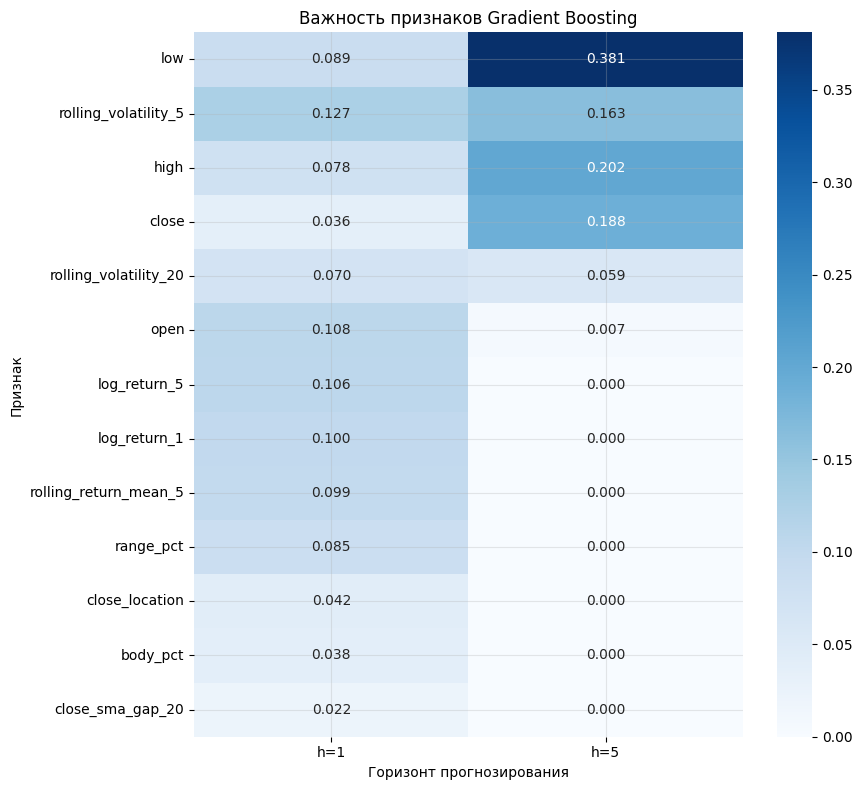

## 15.5. Предварительное аналитическое заключение

Проведено сравнительное исследование восьми конфигураций Gradient Boosting для каждого из горизонтов 1 и 5 торговых дней. Использованы 13 причинно корректных признаков и прогнозирование будущей логарифмической доходности.


### Горизонт 1 торговых дней

Выбранная модель: **GBR_07_Depth3_Huber**.

Количество контрольных прогнозов:
**37**.

Результаты Gradient Boosting:

- MAE: **28.138 pips**.
- RMSE: **35.823 pips**.
- sMAPE: **0.2458%**.
- Directional Accuracy:
  **54.05%**.
- Directional Coverage:
  **100.00%**.

Сравнение RMSE:

- Persistence:
  **34.980 pips**.
- ARIMA:
  **34.848 pips**.
- Gradient Boosting:
  **35.823 pips**.

Изменение RMSE относительно Persistence:
**-2.412%**.

Изменение RMSE относительно ARIMA:
**-2.800%**.

RMSE на обучающей выборке:
**37.056 pips**.

Разность RMSE Validation и Train:
**-1.232 pips**.

Наиболее важный признак внутри выбранного ансамбля:
**rolling_volatility_5**.

**Интерпретация:** Gradient Boosting уступил Persistence по RMSE.



### Горизонт 5 торговых дней

Выбранная модель: **GBR_01_Stump_80**.

Количество контрольных прогнозов:
**33**.

Результаты Gradient Boosting:

- MAE: **76.527 pips**.
- RMSE: **94.918 pips**.
- sMAPE: **0.6680%**.
- Directional Accuracy:
  **57.58%**.
- Directional Coverage:
  **100.00%**.

Сравнение RMSE:

- Persistence:
  **86.233 pips**.
- ARIMA:
  **86.060 pips**.
- Gradient Boosting:
  **94.918 pips**.

Изменение RMSE относительно Persistence:
**-10.071%**.

Изменение RMSE относительно ARIMA:
**-10.292%**.

RMSE на обучающей выборке:
**82.083 pips**.

Разность RMSE Validation и Train:
**+12.835 pips**.

Наиболее важный признак внутри выбранного ансамбля:
**low**.

**Интерпретация:** Gradient Boosting уступил Persistence по RMSE.



### Общий методологический вывод

Gradient Boosting применён как представитель
ансамблевых нелинейных методов машинного обучения.

В отличие от ARIMA, модель использует
табличное представление рыночных характеристик.

Для горизонтов 1 и 5 дней
выполнена независимая настройка конфигураций.

Сравнение с Persistence и ARIMA
проводилось на одинаковых целевых датах
внутри соответствующего горизонта.

Внутренняя важность признаков
используется только для описания
обученных ансамблей и не трактуется
как доказательство причинных зависимостей.

Небольшой размер выборки
создаёт риск переобучения,
особенно для более глубоких деревьев.

Результаты получены на Validation
и поэтому являются предварительными.

**Окончательное заключение о преимуществе
Gradient Boosting возможно только после
сравнения всех четырёх семейств моделей
на независимом Test.**


In [ ]:
# ============================================================
# БЛОК 24. ВИЗУАЛИЗАЦИЯ И ВЫВОДЫ GRADIENT BOOSTING
# ============================================================

# ============================================================
# 1. СРАВНЕНИЕ ПРОГНОЗОВ ТРЁХ СЕМЕЙСТВ
# ============================================================

# Создание фигуры с отдельным графиком для каждого горизонта.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10)
)


# Последовательный перебор исследуемых горизонтов.
for axis, horizon in zip(
    axes,
    FORECAST_HORIZONS
):

    # Получение прогнозов выбранного Gradient Boosting.
    gb_predictions = (
        gradient_boosting_best_validation_predictions[horizon]
    )


    # Получение прогнозов выбранной ARIMA.
    arima_predictions = (
        arima_best_validation_predictions[horizon]
    )


    # Получение прогнозов Persistence.
    persistence_predictions = (
        persistence_validation_predictions[horizon]
    )


    # Получение дат фактических целевых наблюдений.
    target_dates = pd.to_datetime(
        gb_predictions["Дата цели"]
    )


    # Построение графика фактических цен закрытия.
    axis.plot(
        target_dates,
        gb_predictions["Фактический Close"],
        linewidth=1.8,
        label="Фактический Close"
    )


    # Построение графика Persistence.
    axis.plot(
        target_dates,
        persistence_predictions["Прогноз Persistence"],
        linestyle="--",
        linewidth=1.3,
        label="Persistence"
    )


    # Построение графика выбранной ARIMA.
    axis.plot(
        target_dates,
        arima_predictions["Прогноз ARIMA"],
        linestyle="-.",
        linewidth=1.3,
        label="ARIMA"
    )


    # Построение графика выбранного Gradient Boosting.
    axis.plot(
        target_dates,
        gb_predictions["Прогноз Gradient Boosting"],
        linewidth=1.5,
        label="Gradient Boosting"
    )


    # Установка заголовка графика.
    axis.set_title(
        f"Сравнение прогнозов EUR/USD — h={horizon}"
    )


    # Установка подписи вертикальной оси.
    axis.set_ylabel("Курс EUR/USD")


    # Установка подписи горизонтальной оси.
    axis.set_xlabel("Дата целевого наблюдения")


    # Добавление легенды и координатной сетки.
    axis.legend()
    axis.grid(True, alpha=0.3)


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Отображение графиков.
plt.show()


# ============================================================
# 2. СРАВНЕНИЕ RMSE ТРЁХ СЕМЕЙСТВ
# ============================================================

# Получение названий категорий на горизонтальной оси.
horizon_labels = [
    f"h={horizon}"
    for horizon in FORECAST_HORIZONS
]


# Формирование позиций столбцов.
bar_positions = np.arange(
    len(FORECAST_HORIZONS)
)


# Определение ширины столбца.
BAR_WIDTH = 0.25


# Создание сравнительной фигуры.
figure, axis = plt.subplots(
    figsize=(11, 6)
)


# Построение RMSE Persistence.
axis.bar(
    bar_positions - BAR_WIDTH,
    gradient_boosting_comparison_table[
        "Persistence RMSE, pips"
    ],
    width=BAR_WIDTH,
    label="Persistence"
)


# Построение RMSE ARIMA.
axis.bar(
    bar_positions,
    gradient_boosting_comparison_table[
        "ARIMA RMSE, pips"
    ],
    width=BAR_WIDTH,
    label="ARIMA"
)


# Построение RMSE Gradient Boosting.
axis.bar(
    bar_positions + BAR_WIDTH,
    gradient_boosting_comparison_table[
        "GBR RMSE, pips"
    ],
    width=BAR_WIDTH,
    label="Gradient Boosting"
)


# Установка подписей горизонтов.
axis.set_xticks(
    bar_positions,
    horizon_labels
)


# Установка заголовка диаграммы.
axis.set_title(
    "Сравнение RMSE трёх семейств на Validation"
)


# Установка подписи вертикальной оси.
axis.set_ylabel("RMSE, pips")


# Добавление легенды и сетки.
axis.legend()
axis.grid(axis="y", alpha=0.3)


# Вывод диаграммы.
plt.tight_layout()
plt.show()


# ============================================================
# 3. ВАЖНОСТЬ ПРИЗНАКОВ ОБУЧЕННЫХ АНСАМБЛЕЙ
# ============================================================

# Создание словаря значений важности для обоих горизонтов.
feature_importance_columns = {}


# Последовательный перебор выбранных моделей.
for horizon in FORECAST_HORIZONS:

    # Получение обученной модели соответствующего горизонта.
    selected_model = (
        gradient_boosting_best_models[horizon]
    )


    # Получение внутренних оценок важности признаков.
    feature_importance_columns[
        f"h={horizon}"
    ] = selected_model.feature_importances_


# Формирование таблицы с названиями признаков.
gradient_boosting_feature_importance_table = pd.DataFrame(
    feature_importance_columns,
    index=MODEL_FEATURE_COLUMNS
)


# Установка имени индекса таблицы.
gradient_boosting_feature_importance_table.index.name = (
    "Признак"
)


# Расчёт средней важности по двум выбранным моделям.
gradient_boosting_feature_importance_table[
    "Средняя важность"
] = (
    gradient_boosting_feature_importance_table.mean(axis=1)
)


# Сортировка признаков по средней важности.
gradient_boosting_feature_importance_table = (
    gradient_boosting_feature_importance_table
    .sort_values(
        "Средняя важность",
        ascending=False
    )
)


# Вывод таблицы важности признаков.
print("Внутренняя важность признаков Gradient Boosting:")

display(
    gradient_boosting_feature_importance_table.round(6)
)


# Создание тепловой карты важности по двум горизонтам.
plt.figure(figsize=(9, 8))


# Отображение тепловой карты без среднего столбца.
sns.heatmap(
    gradient_boosting_feature_importance_table[
        [f"h={horizon}" for horizon in FORECAST_HORIZONS]
    ],
    annot=True,
    fmt=".3f",
    cmap="Blues"
)


# Установка заголовка тепловой карты.
plt.title(
    "Важность признаков Gradient Boosting"
)


# Установка подписей осей.
plt.xlabel("Горизонт прогнозирования")
plt.ylabel("Признак")


# Вывод тепловой карты.
plt.tight_layout()
plt.show()


# ============================================================
# 4. АВТОМАТИЧЕСКИЙ ПРЕДВАРИТЕЛЬНЫЙ ВЫВОД
# ============================================================

# Создание списка текстовых разделов заключения.
gradient_boosting_conclusion_parts = [
    "## 15.5. Предварительное аналитическое заключение",
    (
        "Проведено сравнительное исследование восьми "
        "конфигураций Gradient Boosting для каждого "
        "из горизонтов 1 и 5 торговых дней. "
        "Использованы 13 причинно корректных признаков "
        "и прогнозирование будущей логарифмической доходности."
    )
]


# Последовательное формирование выводов для каждого горизонта.
for horizon in FORECAST_HORIZONS:

    # Получение строки выбранной конфигурации.
    selected_row = (
        gradient_boosting_best_validation_metrics_table
        .loc[
            gradient_boosting_best_validation_metrics_table[
                "Горизонт"
            ] == horizon
        ]
        .iloc[0]
    )


    # Получение строки сравнения с Persistence и ARIMA.
    comparison_row = (
        gradient_boosting_comparison_table
        .loc[
            gradient_boosting_comparison_table[
                "Горизонт"
            ] == horizon
        ]
        .iloc[0]
    )


    # Получение названия наиболее важного признака.
    most_important_feature = (
        gradient_boosting_feature_importance_table[
            f"h={horizon}"
        ].idxmax()
    )


    # Получение относительного улучшения RMSE.
    rmse_improvement = float(
        comparison_row[
            "Улучшение RMSE vs Persistence, %"
        ]
    )


    # Определение характера улучшения относительно baseline.
    if rmse_improvement > 1e-8:

        # Формирование пояснения о снижении ошибки.
        accuracy_interpretation = (
            "Gradient Boosting уменьшил RMSE "
            "относительно Persistence."
        )

    elif rmse_improvement < -1e-8:

        # Формирование пояснения об ухудшении качества.
        accuracy_interpretation = (
            "Gradient Boosting уступил Persistence по RMSE."
        )

    else:

        # Формирование пояснения о практически одинаковом качестве.
        accuracy_interpretation = (
            "Gradient Boosting и Persistence "
            "показали практически одинаковую RMSE."
        )


    # Получение величины разрыва обучающей и валидационной RMSE.
    training_validation_gap = float(
        selected_row[
            "Validation-Train RMSE gap, pips"
        ]
    )


    # Формирование Markdown-раздела текущего горизонта.
    current_conclusion = f"""
### Горизонт {horizon} торговых дней

Выбранная модель: **{selected_row['Конфигурация']}**.

Количество контрольных прогнозов:
**{int(selected_row['N'])}**.

Результаты Gradient Boosting:

- MAE: **{float(selected_row['MAE, pips']):.3f} pips**.
- RMSE: **{float(selected_row['RMSE, pips']):.3f} pips**.
- sMAPE: **{float(selected_row['sMAPE, %']):.4f}%**.
- Directional Accuracy:
  **{float(selected_row['Directional Accuracy, %']):.2f}%**.
- Directional Coverage:
  **{float(selected_row['Directional Coverage, %']):.2f}%**.

Сравнение RMSE:

- Persistence:
  **{float(comparison_row['Persistence RMSE, pips']):.3f} pips**.
- ARIMA:
  **{float(comparison_row['ARIMA RMSE, pips']):.3f} pips**.
- Gradient Boosting:
  **{float(comparison_row['GBR RMSE, pips']):.3f} pips**.

Изменение RMSE относительно Persistence:
**{rmse_improvement:+.3f}%**.

Изменение RMSE относительно ARIMA:
**{float(comparison_row['Улучшение RMSE vs ARIMA, %']):+.3f}%**.

RMSE на обучающей выборке:
**{float(selected_row['Train RMSE, pips']):.3f} pips**.

Разность RMSE Validation и Train:
**{training_validation_gap:+.3f} pips**.

Наиболее важный признак внутри выбранного ансамбля:
**{most_important_feature}**.

**Интерпретация:** {accuracy_interpretation}
"""


    # Добавление сформированного раздела в общий текст.
    gradient_boosting_conclusion_parts.append(
        current_conclusion
    )


# Добавление общего методологического заключения.
gradient_boosting_conclusion_parts.append(
    """
### Общий методологический вывод

Gradient Boosting применён как представитель
ансамблевых нелинейных методов машинного обучения.

В отличие от ARIMA, модель использует
табличное представление рыночных характеристик.

Для горизонтов 1 и 5 дней
выполнена независимая настройка конфигураций.

Сравнение с Persistence и ARIMA
проводилось на одинаковых целевых датах
внутри соответствующего горизонта.

Внутренняя важность признаков
используется только для описания
обученных ансамблей и не трактуется
как доказательство причинных зависимостей.

Небольшой размер выборки
создаёт риск переобучения,
особенно для более глубоких деревьев.

Результаты получены на Validation
и поэтому являются предварительными.

**Окончательное заключение о преимуществе
Gradient Boosting возможно только после
сравнения всех четырёх семейств моделей
на независимом Test.**
"""
)


# Объединение разделов в Markdown-текст.
gradient_boosting_preliminary_conclusion = "\n\n".join(
    gradient_boosting_conclusion_parts
)


# Отображение заключения.
display(
    Markdown(
        gradient_boosting_preliminary_conclusion
    )
)

## 16. Нейросетевой метод прогнозирования — GRU

### 16.1. Назначение метода

GRU (Gated Recurrent Unit) — разновидность рекуррентных нейронных сетей, предназначенная для обработки последовательных наблюдений.

В отличие от Gradient Boosting, который получает отдельный табличный вектор признаков, GRU непосредственно обрабатывает последовательность векторов характеристик торговых сессий.

### 16.2. Входная последовательность

Для каждой даты формирования прогноза $t$ используются 10 последовательных торговых сессий:

$$
\mathbf{S}_t=
(\mathbf{x}_{t-9},\ldots,\mathbf{x}_t).
$$

Каждый вектор содержит 13 признаков:

$$
\mathbf{x}_t\in\mathbb{R}^{13}.
$$

Таким образом, размер входного представления:

$$
\mathbf{S}_t\in\mathbb{R}^{10\times13}.
$$

Последняя сессия последовательности — текущая завершённая сессия $t$. Будущие наблюдения в последовательности отсутствуют.

### 16.3. Целевая переменная

Отдельная сеть обучается для каждого горизонта:

$$
h\in\{1,5\}.
$$

Целевой величиной выступает будущая логарифмическая доходность:

$$
g_{t,h}=\ln\left(\frac{C_{t+h}}{C_t}\right).
$$

Прогноз нейросети:

$$
\widehat g_{t,h}=F_h(\mathbf{S}_t;\theta_h).
$$

Восстановление цены закрытия:

$$
\widehat C_{t+h}
=
C_t\exp(\widehat g_{t,h}).
$$

Это обеспечивает сопоставимость результатов с Persistence, ARIMA и Gradient Boosting.

### 16.4. Принцип работы GRU

Для очередного вектора входных признаков GRU вычисляет управляющие механизмы обновления скрытого состояния.

Упрощённый вид:

$$
\mathbf{z}_t=
\sigma(W_z\mathbf{x}_t+U_z\mathbf{h}_{t-1}+b_z),
$$

$$
\mathbf{r}_t=
\sigma(W_r\mathbf{x}_t+U_r\mathbf{h}_{t-1}+b_r),
$$

где:

- $\mathbf{z}_t$ — механизм обновления;
- $\mathbf{r}_t$ — механизм сброса;
- $\mathbf{h}_{t-1}$ — предыдущее скрытое состояние;
- $\sigma$ — сигмоидальная функция.

Управляющие механизмы позволяют модели адаптивно учитывать предыдущие наблюдения.

### 16.5. Ограничение сложности

На каждый горизонт имеется менее 200 обучающих наблюдений, поэтому используеьтся следующая конфигурация параметров:

- одна рекуррентная GRU-слой;
- небольшое число скрытых нейронов;
- регуляризация L2;
- Dropout после рекуррентного слоя;
- ранняя остановка обучения;
- ограниченное число кандидатных архитектур.

Это снижает риск чрезмерной подгонки модели под конкретный исторический период.

### 16.6. Масштабирование

Признаки приводятся к сопоставимому масштабу с помощью StandardScaler.

Целевая логарифмическая доходность также стандартизируется для устойчивого обучения.

Параметры масштабирования вычисляются только на соответствующей обучающей части.

Для Validation используются уже определённые параметры преобразования.

### 16.7. Внутренняя временная проверка

Обучающие последовательности располагаются в хронологическом порядке.

Последние 20% обучающих примеров используются для выбора числа эпох.

На этом этапе вводится дополнительный разрыв между внутренним обучением и
внутренней проверкой, чтобы будущие целевые значения внутренних обучающих примеров не попадали в период Early Stopping.

Затем модель с выбранным количеством эпох обучается повторно на полном Train.

Основная Validation используется для выбора конфигурации нейросети по RMSE.

### 16.8. Критерии сравнения

Для каждого горизонта рассчитываются следующие метрики:

- MAE;
- RMSE;
- sMAPE;
- Directional Accuracy;
- Directional Coverage;
- ошибка на обучающей выборке;
- количество параметров нейросети;
- количество эпох обучения;
- вычислительные затраты.

Test не используется для настройки модели.

### 16.9. Основное ограничение

Нейросетевая модель обладает более высокой параметрической сложностью, чем Persistence и некоторые статистические модели.

Небольшая выборка может оказаться недостаточной для надёжного обучения
многих параметров, поэтому более высокая сложность GRU не означает её обязательного превосходства по качеству прогноза.

In [ ]:
# ============================================================
# БЛОК 26. ПОДГОТОВКА ВРЕМЕННЫХ ПОСЛЕДОВАТЕЛЬНОСТЕЙ GRU
# ============================================================

# Импорт StandardScaler для нормирования входов и целей.
from sklearn.preprocessing import StandardScaler


# Определение количества торговых сессий во входной последовательности.
GRU_LOOKBACK = 10


# Определение доли начальных последовательностей для внутреннего обучения.
GRU_INNER_TRAIN_SHARE = 0.80


# Создание общей матрицы разрешённых причинных признаков.
gru_feature_history = forecasting_data[
    MODEL_FEATURE_COLUMNS
].copy()


# Проверка хронологического порядка исходной истории.
assert gru_feature_history.index.is_monotonic_increasing


# Проверка уникальности торговых дат.
assert gru_feature_history.index.is_unique


# ============================================================
# 1. ФУНКЦИЯ ФОРМИРОВАНИЯ ПОСЛЕДОВАТЕЛЬНОСТЕЙ
# ============================================================

# Определение функции подготовки временных окон и соответствующих целей.
def create_gru_sequences(
    partition,
    feature_history,
    target_return_column,
    target_close_column,
    target_date_column,
    lookback
):

    # Создание списка входных временных окон.
    sequence_list = []


    # Создание списка целевых логарифмических доходностей.
    target_list = []


    # Создание списка дат формирования прогнозов.
    origin_date_list = []


    # Создание списка целевых дат.
    target_date_list = []


    # Создание списка известных цен на момент прогноза.
    origin_close_list = []


    # Создание списка фактических будущих цен.
    actual_close_list = []


    # Поиск позиций дат текущей выборки в общей временной истории.
    origin_positions = feature_history.index.get_indexer(
        partition.index
    )


    # Проверка присутствия всех дат прогнозов в общей истории.
    assert np.all(origin_positions >= 0)


    # Последовательный перебор исходных дат и позиций.
    for origin_date, origin_position in zip(
        partition.index,
        origin_positions
    ):

        # Пропуск наблюдений с недостаточной предшествующей историей.
        if origin_position < lookback - 1:

            # Переход к следующей дате прогноза.
            continue


        # Получение окна из текущей и предыдущих торговых сессий.
        current_window = feature_history.iloc[
            origin_position - lookback + 1:
            origin_position + 1
        ].to_numpy(
            dtype=np.float32
        )


        # Проверка отсутствия пропусков и бесконечных значений в окне.
        if not np.isfinite(current_window).all():

            # Исключение окна с недоступными историческими признаками.
            continue


        # Получение исходной строки с прогнозной целью.
        current_row = partition.loc[
            origin_date
        ]


        # Сохранение входной последовательности.
        sequence_list.append(
            current_window
        )


        # Сохранение будущей логарифмической доходности.
        target_list.append(
            float(current_row[target_return_column])
        )


        # Сохранение даты формирования прогноза.
        origin_date_list.append(
            pd.Timestamp(origin_date)
        )


        # Сохранение даты фактического целевого наблюдения.
        target_date_list.append(
            pd.Timestamp(current_row[target_date_column])
        )


        # Сохранение известного Close на текущую дату.
        origin_close_list.append(
            float(current_row["close"])
        )


        # Сохранение фактического будущего Close.
        actual_close_list.append(
            float(current_row[target_close_column])
        )


    # Проверка существования пригодных последовательностей.
    if not sequence_list:

        # Генерация ошибки при отсутствии допустимых окон.
        raise ValueError(
            "Не удалось сформировать входные последовательности GRU."
        )


    # Формирование итогового словаря связанных числовых данных.
    result = {
        "X": np.stack(sequence_list).astype(np.float32),
        "y": np.asarray(target_list, dtype=np.float32),
        "origin_dates": pd.DatetimeIndex(origin_date_list),
        "target_dates": pd.DatetimeIndex(target_date_list),
        "origin_close": np.asarray(
            origin_close_list,
            dtype=np.float64
        ),
        "actual_close": np.asarray(
            actual_close_list,
            dtype=np.float64
        )
    }


    # Проверка количества временных шагов внутри каждого окна.
    assert result["X"].shape[1] == lookback


    # Проверка числа признаков в каждой торговой сессии.
    assert result["X"].shape[2] == len(MODEL_FEATURE_COLUMNS)


    # Проверка одинакового количества входных и целевых объектов.
    assert len(result["X"]) == len(result["y"])


    # Проверка, что каждое целевое наблюдение следует после прогноза.
    assert np.all(
        result["target_dates"].to_numpy()
        >
        result["origin_dates"].to_numpy()
    )


    # Возврат согласованного набора последовательностей.
    return result


# ============================================================
# 2. ФОРМИРОВАНИЕ TRAIN И VALIDATION
# ============================================================

# Создание словаря последовательностей для двух горизонтов.
gru_sequences_by_horizon = {}


# Создание списка диагностических характеристик выборок.
gru_sequence_audit_rows = []


# Последовательный перебор исследуемых горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение информации о временных выборках данного горизонта.
    horizon_split = forecast_splits[horizon]


    # Создание отдельного словаря последовательностей.
    gru_sequences_by_horizon[horizon] = {}


    # Последовательная обработка Train и Validation.
    for partition_name in ["train", "validation"]:

        # Получение исходной выборки текущего этапа.
        current_partition = horizon_split[
            partition_name
        ]


        # Формирование входных окон и будущих целевых значений.
        sequence_data = create_gru_sequences(
            partition=current_partition,
            feature_history=gru_feature_history,
            target_return_column=horizon_split[
                "target_return_column"
            ],
            target_close_column=horizon_split[
                "target_close_column"
            ],
            target_date_column=horizon_split[
                "target_date_column"
            ],
            lookback=GRU_LOOKBACK
        )


        # Сохранение подготовленной выборки.
        gru_sequences_by_horizon[horizon][
            partition_name
        ] = sequence_data


        # Добавление диагностической информации.
        gru_sequence_audit_rows.append(
            {
                "Горизонт": horizon,
                "Выборка": partition_name,
                "Исходных примеров": len(current_partition),
                "Последовательностей GRU": len(
                    sequence_data["X"]
                ),
                "Первый прогноз": (
                    sequence_data["origin_dates"].min().date()
                ),
                "Последний прогноз": (
                    sequence_data["origin_dates"].max().date()
                ),
                "Форма X": str(sequence_data["X"].shape)
            }
        )


    # ========================================================
    # 3. ПРОВЕРКА СОВПАДЕНИЯ ДАТ VALIDATION
    # ========================================================

    # Получение подготовленных последовательностей Validation.
    gru_validation_data = gru_sequences_by_horizon[
        horizon
    ]["validation"]


    # Получение исходной валидационной выборки.
    original_validation = forecast_splits[horizon][
        "validation"
    ]


    # Проверка, что все исходные даты Validation сохранены.
    assert gru_validation_data["origin_dates"].equals(
        original_validation.index
    ), (
        f"GRU потеряла часть валидационных дат при h={horizon}."
    )


    # Проверка совпадения всех фактических будущих цен.
    assert np.allclose(
        gru_validation_data["actual_close"],
        original_validation[
            horizon_split["target_close_column"]
        ].to_numpy(dtype=np.float64),
        rtol=0.0,
        atol=1e-12
    )


# ============================================================
# 4. ТАБЛИЦА КОНТРОЛЯ ПОДГОТОВКИ
# ============================================================

# Формирование диагностической таблицы.
gru_sequence_audit_table = pd.DataFrame(
    gru_sequence_audit_rows
)


# Вывод таблицы подготовленных последовательностей.
print("Контроль временных последовательностей GRU:")

display(
    gru_sequence_audit_table
)


# Вывод подтверждения сохранения контрольных дат.
print(
    "\nВсе даты Validation сохранены. "
    "Последовательности не содержат будущих признаков."
)

Контроль временных последовательностей GRU:


,Горизонт,Выборка,Исходных примеров,Последовательностей GRU,Первый прогноз,Последний прогноз,Форма X
0,1,train,160,151,2025-11-12,2026-06-11,"(151, 10, 13)"
1,1,validation,37,37,2026-06-15,2026-08-04,"(37, 10, 13)"
2,5,train,156,147,2025-11-12,2026-06-05,"(147, 10, 13)"
3,5,validation,33,33,2026-06-15,2026-07-29,"(33, 10, 13)"



Все даты Validation сохранены. Последовательности не содержат будущих признаков.


In [ ]:
# ============================================================
# БЛОК 27. ОБУЧЕНИЕ И НАСТРОЙКА НЕЙРОСЕТЕЙ GRU
# ============================================================

# Импорт TensorFlow для построения и обучения нейросетей.
import tensorflow as tf

# Импорт функции измерения продолжительности вычислений.
from time import perf_counter


# ============================================================
# 1. ПАРАМЕТРЫ ЭКСПЕРИМЕНТА
# ============================================================

# Определение максимального числа эпох внутреннего обучения.
GRU_MAX_EPOCHS = 90


# Определение размера обучающего пакета.
GRU_BATCH_SIZE = 16


# Определение числа эпох без улучшения для ранней остановки.
GRU_EARLY_STOPPING_PATIENCE = 12


# Определение набора компактных нейросетевых конфигураций.
GRU_CANDIDATES = {
    "GRU_01_Units8": {
        "units": 8,
        "dropout": 0.0,
        "l2": 0.001,
        "learning_rate": 0.001,
        "loss": "mse"
    },

    "GRU_02_Units16": {
        "units": 16,
        "dropout": 0.10,
        "l2": 0.001,
        "learning_rate": 0.001,
        "loss": "mse"
    },

    "GRU_03_Units24": {
        "units": 24,
        "dropout": 0.20,
        "l2": 0.003,
        "learning_rate": 0.0005,
        "loss": "mse"
    },

    "GRU_04_Huber16": {
        "units": 16,
        "dropout": 0.15,
        "l2": 0.001,
        "learning_rate": 0.001,
        "loss": "huber"
    }
}


# Вывод установленной версии TensorFlow.
print("Версия TensorFlow:", tf.__version__)


# Вывод количества конфигураций GRU.
print("Конфигураций GRU:", len(GRU_CANDIDATES))


# Вывод числа горизонтов прогнозирования.
print("Горизонтов:", len(FORECAST_HORIZONS))


# ============================================================
# 2. ФУНКЦИЯ СОЗДАНИЯ GRU
# ============================================================

# Определение функции построения компактной рекуррентной сети.
def build_gru_model(
    configuration,
    lookback,
    feature_count
):

    # Создание последовательной архитектуры Keras.
    model = tf.keras.Sequential(
        [
            # Определение формы входных последовательностей.
            tf.keras.layers.Input(
                shape=(lookback, feature_count)
            ),

            # Добавление рекуррентного слоя GRU.
            tf.keras.layers.GRU(
                units=configuration["units"],
                dropout=0.0,
                recurrent_dropout=0.0,
                kernel_regularizer=tf.keras.regularizers.l2(
                    configuration["l2"]
                )
            ),

            # Добавление регуляризирующего слоя Dropout.
            tf.keras.layers.Dropout(
                rate=configuration["dropout"]
            ),

            # Добавление линейного выхода для прогноза доходности.
            tf.keras.layers.Dense(
                units=1
            )
        ]
    )


    # Определение функции потерь текущей конфигурации.
    if configuration["loss"] == "huber":

        # Использование устойчивой к крупным ошибкам функции Huber.
        loss_function = tf.keras.losses.Huber(
            delta=1.0
        )

    else:

        # Использование среднеквадратической функции потерь.
        loss_function = "mse"


    # Настройка оптимизатора и функции потерь сети.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=configuration["learning_rate"]
        ),
        loss=loss_function
    )


    # Возврат готовой к обучению модели.
    return model


# ============================================================
# 3. ХРАНИЛИЩА ЭКСПЕРИМЕНТАЛЬНЫХ РЕЗУЛЬТАТОВ
# ============================================================

# Создание списка итоговых метрик кандидатных моделей.
gru_candidate_metrics_rows = []


# Создание словаря индивидуальных прогнозов.
gru_candidate_predictions = {}


# Создание словаря историй внутреннего обучения.
gru_inner_training_histories = {}


# Создание словаря историй обучения на полном Train.
gru_full_training_histories = {}


# ============================================================
# 4. ПОСЛЕДОВАТЕЛЬНОЕ ОБУЧЕНИЕ ПО ГОРИЗОНТАМ
# ============================================================

# Последовательный перебор прогнозных горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение полных обучающих последовательностей.
    train_data = gru_sequences_by_horizon[horizon]["train"]


    # Получение внешних валидационных последовательностей.
    validation_data = gru_sequences_by_horizon[horizon][
        "validation"
    ]


    # Получение числовых входных массивов.
    X_train_raw = train_data["X"]
    X_validation_raw = validation_data["X"]


    # Получение обучающих и валидационных целевых доходностей.
    y_train_raw = train_data["y"]
    y_validation_raw = validation_data["y"]


    # Получение числа признаков в каждой временной точке.
    feature_count = X_train_raw.shape[2]


    # ========================================================
    # 5. ВНУТРЕННЕЕ ХРОНОЛОГИЧЕСКОЕ РАЗДЕЛЕНИЕ
    # ========================================================

    # Расчёт позиции начала внутреннего валидационного периода.
    inner_validation_start_position = int(
        np.floor(
            len(X_train_raw) * GRU_INNER_TRAIN_SHARE
        )
    )


    # Получение первой даты внутреннего контроля.
    inner_validation_start_date = (
        train_data["origin_dates"][
            inner_validation_start_position
        ]
    )


    # Формирование маски внутреннего обучения с учётом целевых дат.
    inner_train_mask = (
        train_data["target_dates"]
        <
        inner_validation_start_date
    )


    # Формирование маски внутренней валидации.
    inner_validation_mask = np.arange(
        len(X_train_raw)
    ) >= inner_validation_start_position


    # Отбор внутреннего обучающего периода.
    X_inner_train_raw = X_train_raw[
        inner_train_mask
    ]


    # Отбор внутреннего валидационного периода.
    X_inner_validation_raw = X_train_raw[
        inner_validation_mask
    ]


    # Отбор соответствующих обучающих целей.
    y_inner_train_raw = y_train_raw[
        inner_train_mask
    ]


    # Отбор соответствующих внутренних валидационных целей.
    y_inner_validation_raw = y_train_raw[
        inner_validation_mask
    ]


    # Проверка достаточного числа внутренних обучающих примеров.
    assert len(X_inner_train_raw) >= 50


    # Проверка наличия достаточного числа внутренних контрольных примеров.
    assert len(X_inner_validation_raw) >= 15


    # Проверка отсутствия пересечений целевых дат с внутренней проверкой.
    assert (
        train_data["target_dates"][inner_train_mask].max()
        <
        inner_validation_start_date
    )


    # ========================================================
    # 6. МАСШТАБИРОВАНИЕ ДЛЯ ВНУТРЕННЕЙ НАСТРОЙКИ
    # ========================================================

    # Создание масштабировщика входных признаков внутреннего обучения.
    inner_feature_scaler = StandardScaler()


    # Оценка параметров масштаба только на внутреннем Train.
    inner_feature_scaler.fit(
        X_inner_train_raw.reshape(-1, feature_count)
    )


    # Нормирование внутренних обучающих последовательностей.
    X_inner_train_scaled = (
        inner_feature_scaler.transform(
            X_inner_train_raw.reshape(-1, feature_count)
        )
        .reshape(X_inner_train_raw.shape)
        .astype(np.float32)
    )


    # Нормирование внутренней валидации тем же масштабировщиком.
    X_inner_validation_scaled = (
        inner_feature_scaler.transform(
            X_inner_validation_raw.reshape(-1, feature_count)
        )
        .reshape(X_inner_validation_raw.shape)
        .astype(np.float32)
    )


    # Создание масштабировщика целевой доходности.
    inner_target_scaler = StandardScaler()


    # Подгонка масштаба только по внутренним обучающим целям.
    y_inner_train_scaled = (
        inner_target_scaler.fit_transform(
            y_inner_train_raw.reshape(-1, 1)
        )
        .astype(np.float32)
    )


    # Применение масштаба к внутренним контрольным целям.
    y_inner_validation_scaled = (
        inner_target_scaler.transform(
            y_inner_validation_raw.reshape(-1, 1)
        )
        .astype(np.float32)
    )


    # ========================================================
    # 7. МАСШТАБИРОВАНИЕ ДЛЯ ПОЛНОГО TRAIN
    # ========================================================

    # Создание масштабировщика входов полного обучающего периода.
    full_feature_scaler = StandardScaler()


    # Оценка параметров только по полному Train.
    full_feature_scaler.fit(
        X_train_raw.reshape(-1, feature_count)
    )


    # Нормирование полного обучающего периода.
    X_train_scaled = (
        full_feature_scaler.transform(
            X_train_raw.reshape(-1, feature_count)
        )
        .reshape(X_train_raw.shape)
        .astype(np.float32)
    )


    # Нормирование внешней Validation с параметрами полного Train.
    X_validation_scaled = (
        full_feature_scaler.transform(
            X_validation_raw.reshape(-1, feature_count)
        )
        .reshape(X_validation_raw.shape)
        .astype(np.float32)
    )


    # Создание масштабировщика целевой доходности полного Train.
    full_target_scaler = StandardScaler()


    # Обучение масштабировщика только по целям полного Train.
    y_train_scaled = (
        full_target_scaler.fit_transform(
            y_train_raw.reshape(-1, 1)
        )
        .astype(np.float32)
    )


    # ========================================================
    # 8. ПЕРЕБОР НЕЙРОСЕТЕВЫХ КОНФИГУРАЦИЙ
    # ========================================================

    # Вывод характеристик текущего горизонта.
    print(
        f"\nГоризонт {horizon}: "
        f"Train={len(X_train_raw)}, "
        f"Inner Train={len(X_inner_train_raw)}, "
        f"Inner Validation={len(X_inner_validation_raw)}, "
        f"Validation={len(X_validation_raw)}"
    )


    # Последовательный перебор кандидатных архитектур.
    for candidate_index, (
        candidate_name,
        candidate_parameters
    ) in enumerate(
        GRU_CANDIDATES.items()
    ):

        # Определение фиксированного начального состояния генераторов.
        candidate_seed = (
            RANDOM_STATE
            +
            100 * horizon
            +
            candidate_index
        )


        # Очистка ранее созданных вычислительных графов Keras.
        tf.keras.backend.clear_session()


        # Установка начального состояния случайных генераторов.
        tf.keras.utils.set_random_seed(
            candidate_seed
        )


        # Создание модели для внутренней проверки числа эпох.
        inner_model = build_gru_model(
            configuration=candidate_parameters,
            lookback=GRU_LOOKBACK,
            feature_count=feature_count
        )


        # Создание механизма ранней остановки обучения.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=GRU_EARLY_STOPPING_PATIENCE,
            min_delta=1e-4,
            restore_best_weights=True
        )


        # Фиксация времени начала внутреннего обучения.
        inner_training_start = perf_counter()


        # Обучение на внутреннем Train с отдельным контролем.
        inner_history = inner_model.fit(
            X_inner_train_scaled,
            y_inner_train_scaled,
            validation_data=(
                X_inner_validation_scaled,
                y_inner_validation_scaled
            ),
            epochs=GRU_MAX_EPOCHS,
            batch_size=GRU_BATCH_SIZE,
            shuffle=False,
            verbose=0,
            callbacks=[
                early_stopping,
                tf.keras.callbacks.TerminateOnNaN()
            ]
        )


        # Расчёт времени внутренней настройки.
        inner_training_time = (
            perf_counter() - inner_training_start
        )


        # Преобразование истории внутреннего обучения в таблицу.
        inner_history_table = pd.DataFrame(
            inner_history.history
        )


        # Определение эпохи с наименьшей внутренней Validation Loss.
        best_epoch = int(
            inner_history_table["val_loss"].idxmin() + 1
        )


        # Сохранение истории внутренней настройки.
        gru_inner_training_histories[
            (horizon, candidate_name)
        ] = inner_history_table


        # ====================================================
        # 9. ПОВТОРНОЕ ОБУЧЕНИЕ НА ПОЛНОМ TRAIN
        # ====================================================

        # Очистка графа внутренней модели.
        tf.keras.backend.clear_session()


        # Повторная установка исходного состояния генераторов.
        tf.keras.utils.set_random_seed(
            candidate_seed
        )


        # Создание новой модели той же конфигурации.
        full_model = build_gru_model(
            configuration=candidate_parameters,
            lookback=GRU_LOOKBACK,
            feature_count=feature_count
        )


        # Получение числа обучаемых параметров сети.
        model_parameters_count = int(
            full_model.count_params()
        )


        # Фиксация времени начала полного обучения.
        full_training_start = perf_counter()


        # Обучение на полном Train с ранее определённым числом эпох.
        full_history = full_model.fit(
            X_train_scaled,
            y_train_scaled,
            epochs=best_epoch,
            batch_size=GRU_BATCH_SIZE,
            shuffle=False,
            verbose=0,
            callbacks=[
                tf.keras.callbacks.TerminateOnNaN()
            ]
        )


        # Расчёт времени полного обучения.
        full_training_time = (
            perf_counter() - full_training_start
        )


        # Сохранение истории обучения на полном Train.
        gru_full_training_histories[
            (horizon, candidate_name)
        ] = pd.DataFrame(
            full_history.history
        )


        # ====================================================
        # 10. ПРОГНОЗИРОВАНИЕ НА VALIDATION
        # ====================================================

        # Фиксация начала валидационного прогнозирования.
        prediction_start = perf_counter()


        # Получение нормированных прогнозов будущей доходности.
        predicted_validation_scaled = full_model.predict(
            X_validation_scaled,
            verbose=0
        )


        # Восстановление исходного масштаба логарифмических доходностей.
        predicted_validation_returns = (
            full_target_scaler.inverse_transform(
                predicted_validation_scaled.reshape(-1, 1)
            )
            .reshape(-1)
        )


        # Расчёт прогнозируемой цены закрытия EUR/USD.
        predicted_validation_close = (
            validation_data["origin_close"]
            *
            np.exp(predicted_validation_returns)
        )


        # Расчёт времени прогнозирования.
        prediction_time = (
            perf_counter() - prediction_start
        )


        # ====================================================
        # 11. РАСЧЁТ МЕТРИК VALIDATION И TRAIN
        # ====================================================

        # Расчёт общих валидационных метрик.
        validation_metrics = calculate_forecast_metrics(
            actual_close=validation_data["actual_close"],
            predicted_close=predicted_validation_close,
            origin_close=validation_data["origin_close"]
        )


        # Получение прогнозов на полном Train в нормированном масштабе.
        predicted_train_scaled = full_model.predict(
            X_train_scaled,
            verbose=0
        )


        # Восстановление обучающих прогнозов логарифмической доходности.
        predicted_train_returns = (
            full_target_scaler.inverse_transform(
                predicted_train_scaled.reshape(-1, 1)
            )
            .reshape(-1)
        )


        # Восстановление обучающих прогнозов цены закрытия.
        predicted_train_close = (
            train_data["origin_close"]
            *
            np.exp(predicted_train_returns)
        )


        # Расчёт обучающих метрик.
        train_metrics = calculate_forecast_metrics(
            actual_close=train_data["actual_close"],
            predicted_close=predicted_train_close,
            origin_close=train_data["origin_close"]
        )


        # ====================================================
        # 12. СОХРАНЕНИЕ ПРОГНОЗОВ
        # ====================================================

        # Формирование таблицы индивидуальных валидационных прогнозов.
        prediction_table = pd.DataFrame(
            {
                "Дата цели": validation_data["target_dates"],

                "Close на дату прогноза": (
                    validation_data["origin_close"]
                ),

                "Фактический Close": (
                    validation_data["actual_close"]
                ),

                "Прогноз GRU": predicted_validation_close,

                "Прогноз логарифмической доходности": (
                    predicted_validation_returns
                )
            },
            index=validation_data["origin_dates"]
        )


        # Установка имени индекса прогнозных дат.
        prediction_table.index.name = "Дата прогноза"


        # Расчёт ошибки будущей цены закрытия.
        prediction_table["Ошибка"] = (
            prediction_table["Фактический Close"]
            -
            prediction_table["Прогноз GRU"]
        )


        # Расчёт абсолютной ошибки в пунктах EUR/USD.
        prediction_table["Абсолютная ошибка, pips"] = (
            prediction_table["Ошибка"].abs()
            /
            EURUSD_PIP_SIZE
        )


        # Сохранение таблицы текущего эксперимента.
        gru_candidate_predictions[
            (horizon, candidate_name)
        ] = prediction_table


        # ====================================================
        # 13. СОХРАНЕНИЕ МЕТРИК И ХАРАКТЕРИСТИК СЕТИ
        # ====================================================

        # Формирование строки текущего эксперимента.
        gru_candidate_metrics_rows.append(
            {
                "Горизонт": horizon,
                "Конфигурация": candidate_name,
                "N": validation_metrics["N"],
                "Train N": len(X_train_raw),
                "Inner Train N": len(X_inner_train_raw),
                "Inner Validation N": len(
                    X_inner_validation_raw
                ),
                "MAE": validation_metrics["MAE"],
                "RMSE": validation_metrics["RMSE"],
                "MAE, pips": (
                    validation_metrics["MAE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "RMSE, pips": (
                    validation_metrics["RMSE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "sMAPE, %": validation_metrics["sMAPE, %"],
                "Directional Accuracy, %": (
                    validation_metrics["Directional Accuracy, %"]
                ),
                "Directional Coverage, %": (
                    validation_metrics["Directional Coverage, %"]
                ),
                "Active Direction Accuracy, %": (
                    validation_metrics["Active Direction Accuracy, %"]
                ),
                "Train RMSE, pips": (
                    train_metrics["RMSE"]
                    /
                    EURUSD_PIP_SIZE
                ),
                "Validation-Train RMSE gap, pips": (
                    validation_metrics["RMSE"]
                    -
                    train_metrics["RMSE"]
                ) / EURUSD_PIP_SIZE,
                "Число параметров": model_parameters_count,
                "Эпох": best_epoch,
                "Эпох внутренней настройки": len(
                    inner_history_table
                ),
                "Время внутренней настройки, с": (
                    inner_training_time
                ),
                "Время полного обучения, с": (
                    full_training_time
                ),
                "Время прогноза, с": prediction_time,
                "Seed": candidate_seed
            }
        )


        # Вывод характеристик завершённого эксперимента.
        print(
            f"{candidate_name}: "
            f"эпох={best_epoch}, "
            f"RMSE={validation_metrics['RMSE'] / EURUSD_PIP_SIZE:.3f} pips, "
            f"Train RMSE={train_metrics['RMSE'] / EURUSD_PIP_SIZE:.3f} pips, "
            f"параметров={model_parameters_count}"
        )


# ============================================================
# 14. ИТОГОВАЯ ТАБЛИЦА НЕЙРОСЕТЕВЫХ ЭКСПЕРИМЕНТОВ
# ============================================================

# Формирование DataFrame со всеми результатами.
gru_validation_results_table = pd.DataFrame(
    gru_candidate_metrics_rows
)


# Сортировка по горизонту и RMSE Validation.
gru_validation_results_table = (
    gru_validation_results_table
    .sort_values(
        ["Горизонт", "RMSE", "MAE", "Число параметров"],
        kind="stable"
    )
    .reset_index(drop=True)
)


# Вывод итоговых результатов GRU.
print("\nРезультаты всех конфигураций GRU на Validation:")

display(
    gru_validation_results_table[
        [
            "Горизонт",
            "Конфигурация",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Train RMSE, pips",
            "Validation-Train RMSE gap, pips",
            "Число параметров",
            "Эпох",
            "Время полного обучения, с"
        ]
    ].round(5)
)


# Проверка ожидаемого количества экспериментальных результатов.
assert len(gru_validation_results_table) == (
    len(GRU_CANDIDATES)
    *
    len(FORECAST_HORIZONS)
)


# Вывод сообщения об успешном завершении обучения.
print(
    "\nВсе нейросетевые конфигурации обучены "
    "и оценены без использования Test."
)

Версия TensorFlow: 2.21.0
Конфигураций GRU: 4
Горизонтов: 2

Горизонт 1: Train=151, Inner Train=119, Inner Validation=31, Validation=37
GRU_01_Units8: эпох=7, RMSE=34.205 pips, Train RMSE=42.053 pips, параметров=561
GRU_02_Units16: эпох=19, RMSE=37.470 pips, Train RMSE=39.402 pips, параметров=1505


GRU_03_Units24: эпох=4, RMSE=39.969 pips, Train RMSE=43.189 pips, параметров=2833


GRU_04_Huber16: эпох=29, RMSE=38.302 pips, Train RMSE=39.728 pips, параметров=1505

Горизонт 5: Train=147, Inner Train=112, Inner Validation=30, Validation=33
GRU_01_Units8: эпох=4, RMSE=117.286 pips, Train RMSE=86.052 pips, параметров=561
GRU_02_Units16: эпох=25, RMSE=119.420 pips, Train RMSE=72.406 pips, параметров=1505
GRU_03_Units24: эпох=26, RMSE=122.033 pips, Train RMSE=76.603 pips, параметров=2833
GRU_04_Huber16: эпох=25, RMSE=116.452 pips, Train RMSE=74.705 pips, параметров=1505

Результаты всех конфигураций GRU на Validation:


,Горизонт,Конфигурация,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Train RMSE, pips","Validation-Train RMSE gap, pips",Число параметров,Эпох,"Время полного обучения, с"
0,1,GRU_01_Units8,37,25.498220,34.204790,0.222720,64.864860,100.000000,42.052880,-7.848090,561,7,1.710470
1,1,GRU_02_Units16,37,28.587390,37.469880,0.249680,51.351350,100.000000,39.401600,-1.931720,1505,19,3.094290
2,1,GRU_04_Huber16,37,30.057010,38.302040,0.262560,51.351350,100.000000,39.727990,-1.425950,1505,29,3.183380
3,1,GRU_03_Units24,37,31.982640,39.969480,0.279310,51.351350,100.000000,43.189090,-3.219610,2833,4,1.520620
4,5,GRU_04_Huber16,33,95.741340,116.451990,0.834470,51.515150,100.000000,74.705310,41.746670,1505,25,3.004820
5,5,GRU_01_Units8,33,99.037560,117.285850,0.863340,51.515150,100.000000,86.052020,31.233830,561,4,1.472710
6,5,GRU_02_Units16,33,104.331280,119.420000,0.909420,51.515150,100.000000,72.406330,47.013670,1505,25,2.952280
7,5,GRU_03_Units24,33,103.717090,122.033050,0.903970,51.515150,100.000000,76.602720,45.430330,2833,26,2.929280



Все нейросетевые конфигурации обучены и оценены без использования Test.


## 17. Сравнение четырёх семейств прогнозных моделей

### 17.1. Состав исследованных подходов

В работе рассмотрены 4 семейства:

1. Persistence — наивный прогноз.
2. ARIMA — классический статистический метод.
3. Gradient Boosting — ансамблевое машинное обучение.
4. GRU — рекуррентная нейронная сеть.

Каждое семейство оценивается на горизонтах 1 и 5 торговых дней.

### 17.2. Принцип сравнения

Для каждого горизонта все модели используют одинаковые даты формирования прогнозов и фактические будущие цены закрытия.

Основной критерий — RMSE.

Дополнительные характеристики:

- MAE;
- sMAPE;
- Directional Accuracy;
- Directional Coverage;
- время обучения;
- сложность и ограничения метода.

### 17.3. Особенности нейросетевого обучения

Для GRU количество эпох определяется на внутреннем хронологическом контрольном периоде. Затем конфигурация повторно обучается на полном Train.

Внешняя Validation применяется для сравнения кандидатных архитектур.

Таким образом, финальная проверка по-прежнему остаётся независимой от настройки.

### 17.4. Ограничения текущих результатов

Победитель на Validation не обязательно будет победителем на Test.

На данном этапе нельзя утверждать статистическое превосходство модели по одному небольшому контрольному периоду.

Окончательная оценка будет выполнена после фиксации всех конфигураций.

Лучшие конфигурации GRU:


,Горизонт,Конфигурация,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %",Число параметров,Эпох
0,1,GRU_01_Units8,37,25.498220,34.204790,0.222720,64.864860,100.000000,561,7
1,5,GRU_04_Huber16,33,95.741340,116.451990,0.834470,51.515150,100.000000,1505,25



Контроль пройден: все четыре метода используют одинаковые даты и фактические значения.

Сравнение четырёх семейств на Validation:


,Горизонт,Семейство,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Улучшение RMSE vs Persistence, %"
0,1,GRU,37,25.498220,34.204790,0.222720,64.864860,100.000000,2.215850
1,1,ARIMA,37,26.695930,34.847890,0.233240,54.054050,97.297300,0.377380
2,1,Persistence,37,26.778380,34.979890,0.233960,2.702700,0.000000,0.000000
3,1,Gradient Boosting,37,28.138370,35.823500,0.245810,54.054050,100.000000,-2.411680
4,5,ARIMA,33,65.647900,86.060420,0.573740,39.393940,100.000000,0.200450
5,5,Persistence,33,65.521210,86.233270,0.572590,0.000000,0.000000,0.000000
6,5,Gradient Boosting,33,76.527160,94.917790,0.668000,57.575760,100.000000,-10.070960
7,5,GRU,33,95.741340,116.451990,0.834470,51.515150,100.000000,-35.042980


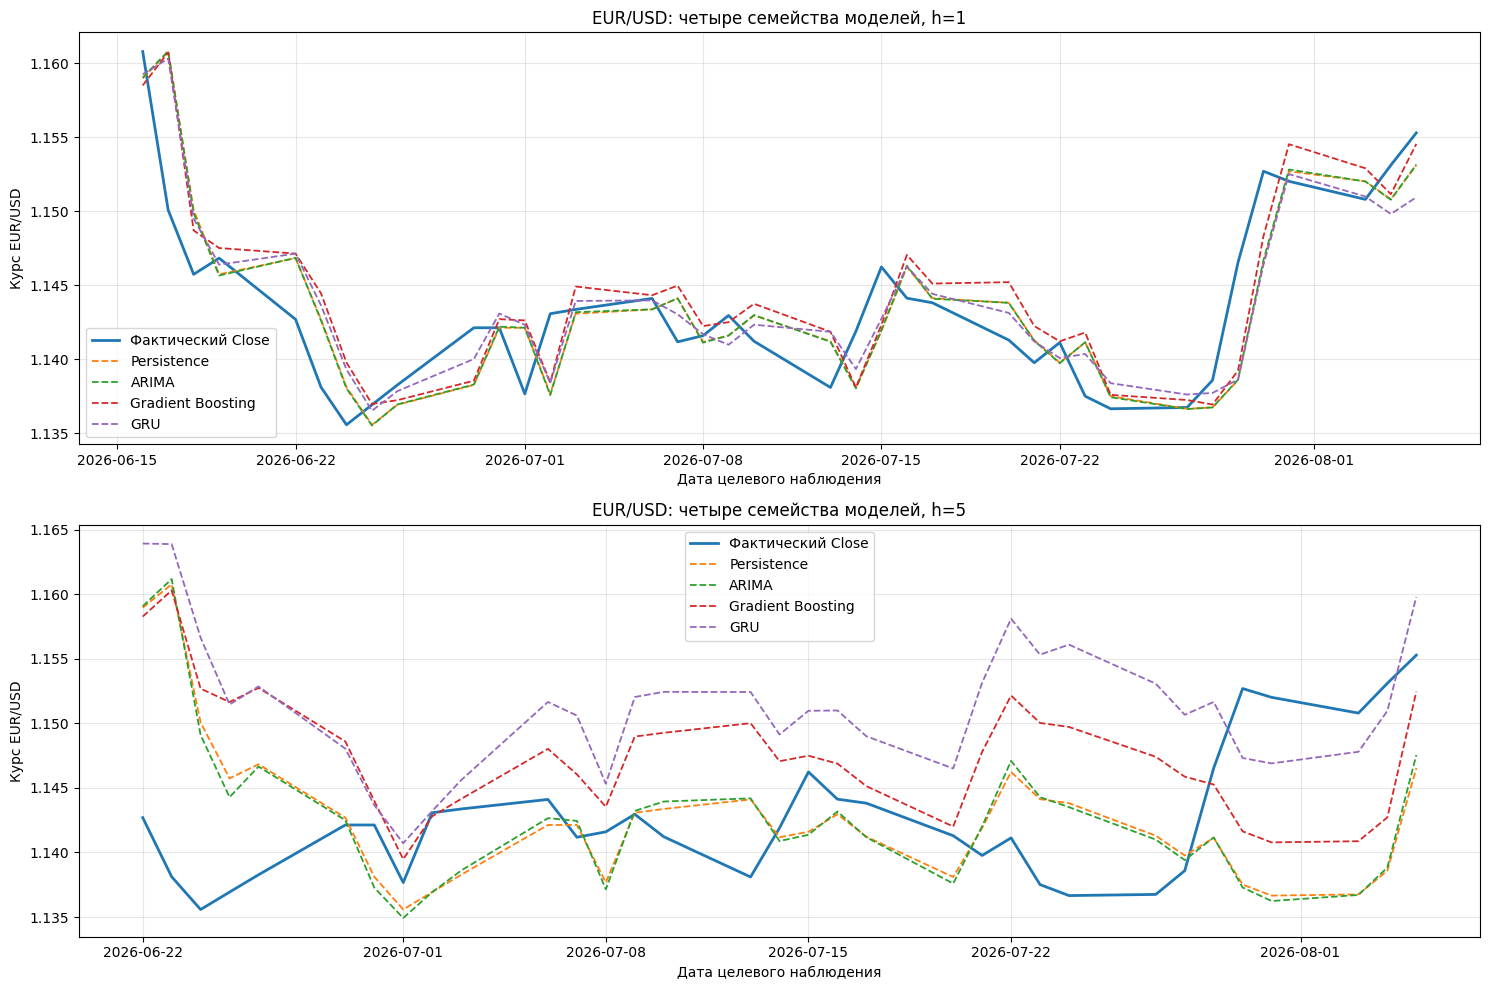

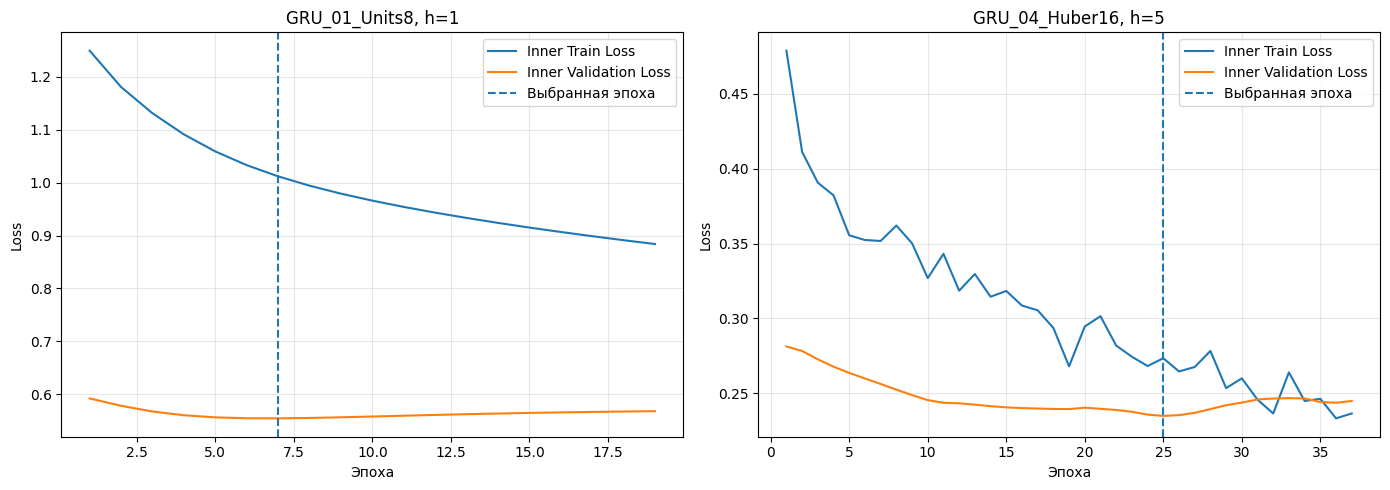

## 17.5. Предварительное комплексное заключение

Проведено исследование четырёх семейств прогнозных моделей EUR/USD: Persistence, ARIMA, Gradient Boosting и GRU. Для нейросетей выполнена внутренняя хронологическая настройка числа эпох с последующим обучением на полном Train.


### Горизонт 1 торговых дней

Количество валидационных прогнозов:
**37**.

Выбранная GRU:
**GRU_01_Units8**.

Количество эпох:
**7**.

Сравнение четырёх семейств:

- GRU: RMSE = 34.205 pips; MAE = 25.498 pips; Directional Accuracy = 64.86%.
- ARIMA: RMSE = 34.848 pips; MAE = 26.696 pips; Directional Accuracy = 54.05%.
- Persistence: RMSE = 34.980 pips; MAE = 26.778 pips; Directional Accuracy = 2.70%.
- Gradient Boosting: RMSE = 35.823 pips; MAE = 28.138 pips; Directional Accuracy = 54.05%.

Лучший метод по валидационному RMSE:
**GRU**.

Его RMSE:
**34.205 pips**.

RMSE Persistence:
**34.980 pips**.

Изменение RMSE GRU относительно Persistence:
**+2.216%**.

Полученные результаты характеризуют
конкретный валидационный период
и не являются независимой оценкой
будущей точности модели.



### Горизонт 5 торговых дней

Количество валидационных прогнозов:
**33**.

Выбранная GRU:
**GRU_04_Huber16**.

Количество эпох:
**25**.

Сравнение четырёх семейств:

- ARIMA: RMSE = 86.060 pips; MAE = 65.648 pips; Directional Accuracy = 39.39%.
- Persistence: RMSE = 86.233 pips; MAE = 65.521 pips; Directional Accuracy = 0.00%.
- Gradient Boosting: RMSE = 94.918 pips; MAE = 76.527 pips; Directional Accuracy = 57.58%.
- GRU: RMSE = 116.452 pips; MAE = 95.741 pips; Directional Accuracy = 51.52%.

Лучший метод по валидационному RMSE:
**ARIMA**.

Его RMSE:
**86.060 pips**.

RMSE Persistence:
**86.233 pips**.

Изменение RMSE GRU относительно Persistence:
**-35.043%**.

Полученные результаты характеризуют
конкретный валидационный период
и не являются независимой оценкой
будущей точности модели.



### Общий методологический вывод

4 семейства реализуют различные
принципы прогнозирования:

- Persistence сохраняет последний известный курс.
- ARIMA моделирует статистическую временную структуру.
- Gradient Boosting использует нелинейные зависимости признаков.
- GRU обрабатывает последовательности рыночных характеристик.

Нейросетевая модель обучалась на небольшом наборе данных.

Для уменьшения риска утечек выполнены следующие шаги:

1. Разделение наблюдений по времени.
2. Формирование причинно корректных входных окон.
3. Масштабирование только по обучающим наблюдениям.
4. Внутренняя настройка числа эпох.
5. Сравнение архитектур только на Validation.
6. Сохранение независимого Test.

**Валидационный лидер не объявляется окончательным.**

Для подтверждения качества необходимо
переобучить выбранные конфигурации
на Train + Validation и провести
единственную независимую оценку на Test.

После неё также потребуется исследовать
устойчивость, вычислительные затраты
и возможные ограничения сравнения моделей.


In [ ]:
# ============================================================
# БЛОК 28. СРАВНЕНИЕ PERSISTENCE, ARIMA, GBR И GRU
# ============================================================

# Создание словаря выбранных конфигураций GRU.
gru_best_configurations = {}


# Создание словаря индивидуальных прогнозов выбранных GRU.
gru_best_validation_predictions = {}


# Создание списка результатов лучших GRU.
gru_best_validation_rows = []


# Создание списка результатов всех четырёх семейств.
four_model_comparison_rows = []


# ============================================================
# 1. ВЫБОР ЛУЧШИХ НЕЙРОСЕТЕВЫХ КОНФИГУРАЦИЙ
# ============================================================

# Последовательный перебор исследуемых горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение рейтинга GRU текущего горизонта.
    horizon_results = (
        gru_validation_results_table
        .loc[
            gru_validation_results_table["Горизонт"] == horizon
        ]
        .sort_values(
            ["RMSE", "MAE", "Число параметров"],
            kind="stable"
        )
    )


    # Выбор модели с минимальным RMSE.
    best_gru_row = horizon_results.iloc[0]


    # Получение названия выбранной конфигурации.
    best_gru_name = str(
        best_gru_row["Конфигурация"]
    )


    # Сохранение параметров и числа эпох выбранной сети.
    gru_best_configurations[horizon] = {
        "name": best_gru_name,
        "parameters": GRU_CANDIDATES[best_gru_name].copy(),
        "epochs": int(best_gru_row["Эпох"]),
        "seed": int(best_gru_row["Seed"])
    }


    # Сохранение прогнозов выбранной сети.
    gru_best_validation_predictions[horizon] = (
        gru_candidate_predictions[
            (horizon, best_gru_name)
        ].copy()
    )


    # Сохранение метрик победившей нейросети.
    gru_best_validation_rows.append(
        best_gru_row.to_dict()
    )


# Формирование таблицы лучших GRU.
gru_best_validation_metrics_table = pd.DataFrame(
    gru_best_validation_rows
).sort_values(
    "Горизонт"
).reset_index(
    drop=True
)


# Вывод выбранных нейросетевых конфигураций.
print("Лучшие конфигурации GRU:")

display(
    gru_best_validation_metrics_table[
        [
            "Горизонт",
            "Конфигурация",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Число параметров",
            "Эпох"
        ]
    ].round(5)
)


# ============================================================
# 2. ПРОВЕРКА СОПОСТАВИМОСТИ ПРОГНОЗОВ
# ============================================================

# Последовательная проверка обоих горизонтов.
for horizon in FORECAST_HORIZONS:

    # Формирование словаря таблиц прогнозов четырёх семейств.
    model_predictions = {
        "Persistence": persistence_validation_predictions[horizon],
        "ARIMA": arima_best_validation_predictions[horizon],
        "Gradient Boosting": (
            gradient_boosting_best_validation_predictions[horizon]
        ),
        "GRU": gru_best_validation_predictions[horizon]
    }


    # Получение контрольной таблицы Persistence.
    reference_table = model_predictions["Persistence"]


    # Последовательная проверка каждого семейства.
    for model_name, prediction_table in model_predictions.items():

        # Проверка полного совпадения дат формирования прогнозов.
        assert prediction_table.index.equals(
            reference_table.index
        ), (
            f"Не совпадают даты прогнозов {model_name}, h={horizon}."
        )


        # Проверка совпадения дат целевых наблюдений.
        assert np.array_equal(
            pd.to_datetime(
                prediction_table["Дата цели"]
            ).to_numpy(),
            pd.to_datetime(
                reference_table["Дата цели"]
            ).to_numpy()
        )


        # Проверка совпадения фактических будущих цен.
        assert np.allclose(
            prediction_table["Фактический Close"],
            reference_table["Фактический Close"],
            rtol=0.0,
            atol=1e-12
        )


        # Проверка совпадения известных цен на момент прогноза.
        assert np.allclose(
            prediction_table["Close на дату прогноза"],
            reference_table["Close на дату прогноза"],
            rtol=0.0,
            atol=1e-12
        )


# Вывод подтверждения сопоставимости.
print(
    "\nКонтроль пройден: все четыре метода "
    "используют одинаковые даты и фактические значения."
)


# ============================================================
# 3. ФОРМИРОВАНИЕ СРАВНИТЕЛЬНОГО РЕЙТИНГА
# ============================================================

# Последовательный перебор обоих горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение результата Persistence.
    persistence_row = persistence_validation_metrics_table.loc[
        persistence_validation_metrics_table["Горизонт"] == horizon
    ].iloc[0]


    # Получение результата ARIMA.
    arima_row = arima_best_validation_metrics_table.loc[
        arima_best_validation_metrics_table["Горизонт"] == horizon
    ].iloc[0]


    # Получение результата Gradient Boosting.
    gradient_boosting_row = (
        gradient_boosting_best_validation_metrics_table.loc[
            gradient_boosting_best_validation_metrics_table[
                "Горизонт"
            ] == horizon
        ].iloc[0]
    )


    # Получение результата GRU.
    gru_row = gru_best_validation_metrics_table.loc[
        gru_best_validation_metrics_table["Горизонт"] == horizon
    ].iloc[0]


    # Объединение результатов четырёх семейств.
    family_results = {
        "Persistence": persistence_row,
        "ARIMA": arima_row,
        "Gradient Boosting": gradient_boosting_row,
        "GRU": gru_row
    }


    # Получение базового значения RMSE.
    baseline_rmse = float(
        persistence_row["RMSE"]
    )


    # Последовательное формирование строк сравнительной таблицы.
    for family_name, metrics_row in family_results.items():

        # Получение значения MAE текущего семейства.
        current_mae = float(
            metrics_row["MAE"]
        )


        # Получение значения RMSE текущего семейства.
        current_rmse = float(
            metrics_row["RMSE"]
        )


        # Добавление строки сравнительного анализа.
        four_model_comparison_rows.append(
            {
                "Горизонт": horizon,
                "Семейство": family_name,
                "N": int(metrics_row["N"]),
                "MAE, pips": (
                    current_mae / EURUSD_PIP_SIZE
                ),
                "RMSE, pips": (
                    current_rmse / EURUSD_PIP_SIZE
                ),
                "sMAPE, %": float(
                    metrics_row["sMAPE, %"]
                ),
                "Directional Accuracy, %": float(
                    metrics_row["Directional Accuracy, %"]
                ),
                "Directional Coverage, %": float(
                    metrics_row["Directional Coverage, %"]
                ),
                "Улучшение RMSE vs Persistence, %": (
                    100.0
                    *
                    (1.0 - current_rmse / baseline_rmse)
                )
            }
        )


# Формирование сравнительной таблицы четырёх семейств.
four_model_validation_comparison_table = pd.DataFrame(
    four_model_comparison_rows
)


# Сортировка результатов по горизонту и RMSE.
four_model_validation_comparison_table = (
    four_model_validation_comparison_table
    .sort_values(
        ["Горизонт", "RMSE, pips"],
        kind="stable"
    )
    .reset_index(drop=True)
)


# Вывод итогового валидационного рейтинга.
print("\nСравнение четырёх семейств на Validation:")

display(
    four_model_validation_comparison_table.round(5)
)


# ============================================================
# 4. ВИЗУАЛИЗАЦИЯ ПРОГНОЗОВ
# ============================================================

# Создание фигуры с отдельным графиком для каждого горизонта.
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10)
)


# Последовательная визуализация обоих горизонтов.
for axis, horizon in zip(
    axes,
    FORECAST_HORIZONS
):

    # Получение контрольного набора прогнозов Persistence.
    reference = persistence_validation_predictions[horizon]


    # Получение дат фактических целевых наблюдений.
    target_dates = pd.to_datetime(
        reference["Дата цели"]
    )


    # Построение графика фактических будущих цен.
    axis.plot(
        target_dates,
        reference["Фактический Close"],
        linewidth=2.0,
        label="Фактический Close"
    )


    # Формирование перечня прогнозов четырёх методов.
    forecast_curves = {
        "Persistence": (
            persistence_validation_predictions[horizon][
                "Прогноз Persistence"
            ]
        ),
        "ARIMA": (
            arima_best_validation_predictions[horizon][
                "Прогноз ARIMA"
            ]
        ),
        "Gradient Boosting": (
            gradient_boosting_best_validation_predictions[horizon][
                "Прогноз Gradient Boosting"
            ]
        ),
        "GRU": (
            gru_best_validation_predictions[horizon][
                "Прогноз GRU"
            ]
        )
    }


    # Последовательное построение прогнозных линий.
    for family_name, predicted_close in forecast_curves.items():

        # Отображение прогнозов выбранного семейства.
        axis.plot(
            target_dates,
            predicted_close,
            linewidth=1.3,
            linestyle="--",
            label=family_name
        )


    # Установка заголовка текущего графика.
    axis.set_title(
        f"EUR/USD: четыре семейства моделей, h={horizon}"
    )


    # Подпись вертикальной оси.
    axis.set_ylabel("Курс EUR/USD")


    # Подпись горизонтальной оси.
    axis.set_xlabel("Дата целевого наблюдения")


    # Добавление сетки и легенды.
    axis.grid(True, alpha=0.3)
    axis.legend()


# Автоматическое выравнивание графиков.
plt.tight_layout()


# Отображение сравнительной фигуры.
plt.show()


# ============================================================
# 5. КРИВЫЕ ВНУТРЕННЕГО ОБУЧЕНИЯ ЛУЧШИХ GRU
# ============================================================

# Создание отдельной фигуры для обоих горизонтов.
figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)


# Последовательный анализ выбранных моделей.
for axis, horizon in zip(
    axes,
    FORECAST_HORIZONS
):

    # Получение названия выбранной нейросети.
    selected_name = gru_best_configurations[horizon]["name"]


    # Получение истории внутреннего обучения.
    history_table = gru_inner_training_histories[
        (horizon, selected_name)
    ]


    # Построение обучающей функции потерь.
    axis.plot(
        np.arange(1, len(history_table) + 1),
        history_table["loss"],
        label="Inner Train Loss"
    )


    # Построение валидационной функции потерь.
    axis.plot(
        np.arange(1, len(history_table) + 1),
        history_table["val_loss"],
        label="Inner Validation Loss"
    )


    # Выделение выбранного количества эпох.
    axis.axvline(
        gru_best_configurations[horizon]["epochs"],
        linestyle="--",
        label="Выбранная эпоха"
    )


    # Установка заголовка графика.
    axis.set_title(
        f"{selected_name}, h={horizon}"
    )


    # Установка подписей осей.
    axis.set_xlabel("Эпоха")
    axis.set_ylabel("Loss")


    # Добавление координатной сетки.
    axis.grid(True, alpha=0.3)


    # Добавление легенды.
    axis.legend()


# Автоматическое выравнивание элементов.
plt.tight_layout()


# Вывод диагностической фигуры.
plt.show()


# ============================================================
# 6. АВТОМАТИЧЕСКОЕ ПРЕДВАРИТЕЛЬНОЕ ЗАКЛЮЧЕНИЕ
# ============================================================

# Создание списка текстовых разделов заключения.
gru_conclusion_parts = [
    "## 17.5. Предварительное комплексное заключение",
    (
        "Проведено исследование четырёх семейств прогнозных "
        "моделей EUR/USD: Persistence, ARIMA, Gradient Boosting и GRU. "
        "Для нейросетей выполнена внутренняя хронологическая "
        "настройка числа эпох с последующим обучением на полном Train."
    )
]


# Последовательное формирование выводов по обоим горизонтам.
for horizon in FORECAST_HORIZONS:

    # Получение сравнительных результатов текущего горизонта.
    horizon_results = (
        four_model_validation_comparison_table
        .loc[
            four_model_validation_comparison_table[
                "Горизонт"
            ] == horizon
        ]
        .sort_values(
            "RMSE, pips"
        )
    )


    # Получение лучшего семейства по RMSE.
    best_family_row = horizon_results.iloc[0]


    # Получение результатов GRU.
    gru_row = horizon_results.loc[
        horizon_results["Семейство"] == "GRU"
    ].iloc[0]


    # Получение контрольного значения RMSE Persistence.
    baseline_rmse = float(
        horizon_results.loc[
            horizon_results["Семейство"] == "Persistence",
            "RMSE, pips"
        ].iloc[0]
    )


    # Формирование сравнительной строки для текущего горизонта.
    family_comparison_lines = [
        (
            f"- {row['Семейство']}: "
            f"RMSE = {float(row['RMSE, pips']):.3f} pips; "
            f"MAE = {float(row['MAE, pips']):.3f} pips; "
            f"Directional Accuracy = "
            f"{float(row['Directional Accuracy, %']):.2f}%."
        )
        for _, row in horizon_results.iterrows()
    ]


    # Объединение строк сравнительного списка.
    family_comparison_text = "\n".join(
        family_comparison_lines
    )


    # Формирование Markdown-раздела текущего горизонта.
    horizon_conclusion = f"""
### Горизонт {horizon} торговых дней

Количество валидационных прогнозов:
**{int(gru_row['N'])}**.

Выбранная GRU:
**{gru_best_configurations[horizon]['name']}**.

Количество эпох:
**{gru_best_configurations[horizon]['epochs']}**.

Сравнение четырёх семейств:

{family_comparison_text}

Лучший метод по валидационному RMSE:
**{best_family_row['Семейство']}**.

Его RMSE:
**{float(best_family_row['RMSE, pips']):.3f} pips**.

RMSE Persistence:
**{baseline_rmse:.3f} pips**.

Изменение RMSE GRU относительно Persistence:
**{float(gru_row['Улучшение RMSE vs Persistence, %']):+.3f}%**.

Полученные результаты характеризуют
конкретный валидационный период
и не являются независимой оценкой
будущей точности модели.
"""


    # Добавление раздела текущего горизонта.
    gru_conclusion_parts.append(
        horizon_conclusion
    )


# Добавление общего методологического вывода.
gru_conclusion_parts.append(
    """
### Общий методологический вывод

4 семейства реализуют различные
принципы прогнозирования:

- Persistence сохраняет последний известный курс.
- ARIMA моделирует статистическую временную структуру.
- Gradient Boosting использует нелинейные зависимости признаков.
- GRU обрабатывает последовательности рыночных характеристик.

Нейросетевая модель обучалась на небольшом наборе данных.

Для уменьшения риска утечек выполнены следующие шаги:

1. Разделение наблюдений по времени.
2. Формирование причинно корректных входных окон.
3. Масштабирование только по обучающим наблюдениям.
4. Внутренняя настройка числа эпох.
5. Сравнение архитектур только на Validation.
6. Сохранение независимого Test.

**Валидационный лидер не объявляется окончательным.**

Для подтверждения качества необходимо
переобучить выбранные конфигурации
на Train + Validation и провести
единственную независимую оценку на Test.

После неё также потребуется исследовать
устойчивость, вычислительные затраты
и возможные ограничения сравнения моделей.
"""
)


# Объединение разделов в единый Markdown-текст.
gru_preliminary_conclusion = "\n\n".join(
    gru_conclusion_parts
)


# Отображение предварительного заключения.
display(
    Markdown(
        gru_preliminary_conclusion
    )
)

## 18. Финальный эксперимент на независимом Test

### 18.1. Цель финальной проверки

Оценить обобщающую способность 4 семейств моделей прогнозирования EUR/USD на ранее не использовавшемся тестовом периоде.

Исследуются горизонты $h\in\{1,5\}$. Основной критерий сравнения — RMSE.
Дополнительно анализируются MAE, sMAPE, Directional Accuracy и вычислительные затраты.

### 18.2. Зафиксированные конфигурации

По результатам настройки на Validation выбраны следующие модели:

| Семейство | Горизонт 1 день | Горизонт 5 дней |
|---|---|---|
| Persistence | Последний известный Close | Последний известный Close |
| ARIMA | ARIMA(1,1,0), без дрейфа | ARIMA(0,1,2), без дрейфа |
| Gradient Boosting | GBR_07_Depth3_Huber | GBR_01_Stump_80 |
| GRU | GRU_01_Units8, 7 эпох | GRU_04_Huber16, 25 эпох |

Параметры моделей не изменяются по результатам Test.

### 18.3. Финальное обучение

Обучающие и валидационные периоды объединяются следующим образом:

$$
D_{\mathrm{final\ train}}
=
D_{\mathrm{train}}\cup D_{\mathrm{validation}}.
$$

Прогнозирование выполняется на следующем хронологически независимом периоде Test. Для ARIMA оцениваются параметры на полном ряде Train + Validation.

Во время Test состояние ARIMA последовательно обновляется по фактически завершённым сессиям, но параметры модели не переоцениваются.

Для Gradient Boosting выполняется новое обучение на объединённой выборке причинно корректных признаков.

Для GRU заново определяются масштабировщики по Train + Validation, после чего сеть обучается с заранее зафиксированным количеством эпох. Persistence не требует обучения.

### 18.4. Информационная доступность

Прогноз после завершения сессии $t$ может использовать только значения,
известные на момент $t$.

При последовательном тестировании допускается использовать фактически наблюдавшиеся предыдущие тестовые сессии. Например, прогноз, сформированный 10 августа, может использовать котировки 6–7 августа, если эти сессии уже завершены, однако прогноз на 5 дней вперёд не должен использовать фактические цены будущих 5 торговых сессий.

Таким образом, используется rolling-origin evaluation с обновлением доступной истории.

### 18.5. Разделение данных

Период обучения и настройки:

02.10.2025 — 05.08.2026.

Тестовый период:

06.08.2026 — 30.09.2026.

Для горизонта 1 дня предусмотрено 39 тестовых прогнозов.

Для горизонта 5 дней предусмотрено 35 тестовых прогнозов.

Все 4 семейства должны иметь одинаковые даты прогнозов и цели внутри каждого горизонта.

### 18.6. Правило окончательной оценки

Запреты, накладымаемые после проведения расчёта Test:

- менять гиперпараметры по тестовым метрикам;
- повторять обучение с разными случайными
  инициализациями ради выбора лучшего результата;
- изменять признаки на основании тестовых ошибок;
- исключать неудобные наблюдения;
- объявлять валидационные результаты
  независимыми тестовыми результатами.

Допустимы диагностический анализ, построение графиков и оценка устойчивости при условии, что конфигурации остаются зафиксированными.

### 18.7. Ограничения интерпретации

Тест содержит относительно небольшое количество наблюдений. Пятидневные прогнозы формируются на перекрывающихся временных горизонтах, поэтому их ошибки статистически зависимы.

Полученные результаты характеризуют конкретный исторический период и не гарантируют сохранения качества в будущем.

In [ ]:
# ============================================================
# БЛОК 30.1. ПОДГОТОВКА ФИНАЛЬНОГО ТЕСТИРОВАНИЯ
# ============================================================

# Импорт функции измерения продолжительности вычислений.
from time import perf_counter


# Создание словаря для индивидуальных тестовых прогнозов.
final_test_predictions = {}


# Создание списка итоговых метрик тестирования.
final_test_metrics_rows = []


# Создание списка сведений о вычислительных затратах.
final_test_computation_rows = []


# Создание словаря финально обученных моделей.
final_trained_models = {}


# Определение названий четырёх обязательных семейств.
FORECAST_MODEL_FAMILIES = [
    "Persistence",
    "ARIMA",
    "Gradient Boosting",
    "GRU"
]


# ============================================================
# 1. КОНТРОЛЬ ГРАНИЦ ЭКСПЕРИМЕНТА
# ============================================================

# Проверка хронологической последовательности периодов.
assert (
    TRAIN_END_DATE
    <
    VALIDATION_START_DATE
    <=
    VALIDATION_END_DATE
    <
    TEST_START_DATE
    <=
    TEST_END_DATE
)


# Проверка существования выбранных конфигураций ARIMA.
assert set(arima_best_configurations) == set(
    FORECAST_HORIZONS
)


# Проверка существования выбранных конфигураций Gradient Boosting.
assert set(gradient_boosting_best_configurations) == set(
    FORECAST_HORIZONS
)


# Проверка существования выбранных конфигураций GRU.
assert set(gru_best_configurations) == set(
    FORECAST_HORIZONS
)


# ============================================================
# 2. ФУНКЦИЯ РЕГИСТРАЦИИ ФИНАЛЬНОГО РЕЗУЛЬТАТА
# ============================================================

# Определение функции единого сохранения прогнозов и метрик.
def register_final_test_result(
    horizon,
    family_name,
    predicted_close,
    training_seconds,
    prediction_seconds,
    training_samples,
    configuration_name
):

    # Формирование уникального ключа результата.
    result_key = (
        horizon,
        family_name
    )


    # Проверка отсутствия повторной регистрации той же модели.
    if result_key in final_test_predictions:

        # Генерация ошибки при попытке подменить уже полученный результат.
        raise ValueError(
            f"Результат {result_key} уже зарегистрирован."
        )


    # Получение исходной тестовой выборки текущего горизонта.
    test_partition = forecast_splits[horizon][
        "test"
    ]


    # Получение имени столбца будущего фактического Close.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]


    # Получение имени столбца даты будущего наблюдения.
    target_date_column = forecast_splits[horizon][
        "target_date_column"
    ]


    # Получение фактических будущих цен.
    actual_close = test_partition[
        target_close_column
    ].to_numpy(
        dtype=np.float64
    )


    # Получение известных цен на момент формирования прогноза.
    origin_close = test_partition[
        "close"
    ].to_numpy(
        dtype=np.float64
    )


    # Преобразование прогнозов модели в одномерный числовой массив.
    predicted_close = np.asarray(
        predicted_close,
        dtype=np.float64
    ).reshape(-1)


    # Проверка совпадения количества прогнозов и фактических значений.
    assert len(predicted_close) == len(
        actual_close
    )


    # Проверка конечности и положительности всех прогнозов.
    assert (
        np.isfinite(predicted_close).all()
        and
        np.all(predicted_close > 0.0)
    )


    # Расчёт общих метрик качества на Test.
    current_metrics = calculate_forecast_metrics(
        actual_close=actual_close,
        predicted_close=predicted_close,
        origin_close=origin_close
    )


    # ========================================================
    # 3. СОХРАНЕНИЕ ИНДИВИДУАЛЬНЫХ ПРОГНОЗОВ
    # ========================================================

    # Формирование таблицы тестовых прогнозов модели.
    prediction_table = pd.DataFrame(
        {
            "Дата цели": test_partition[
                target_date_column
            ].to_numpy(),

            "Close на дату прогноза": origin_close,

            "Фактический Close": actual_close,

            "Прогноз Close": predicted_close
        },
        index=test_partition.index
    )


    # Установка имени индекса для дат формирования прогнозов.
    prediction_table.index.name = "Дата прогноза"


    # Расчёт индивидуальной ошибки прогнозирования.
    prediction_table["Ошибка"] = (
        prediction_table["Фактический Close"]
        -
        prediction_table["Прогноз Close"]
    )


    # Расчёт абсолютной ошибки в пунктах EUR/USD.
    prediction_table["Абсолютная ошибка, pips"] = (
        prediction_table["Ошибка"].abs()
        /
        EURUSD_PIP_SIZE
    )


    # Расчёт фактического направления изменения курса.
    prediction_table["Фактическое направление"] = (
        calculate_price_direction(
            actual_close - origin_close
        )
    )


    # Расчёт прогнозируемого направления изменения курса.
    prediction_table["Прогнозируемое направление"] = (
        calculate_price_direction(
            predicted_close - origin_close
        )
    )


    # Проверка отсутствия целевых дат за концом тестового периода.
    assert (
        prediction_table["Дата цели"].max()
        <=
        TEST_END_DATE
    )


    # Сохранение согласованной таблицы индивидуальных прогнозов.
    final_test_predictions[result_key] = prediction_table


    # ========================================================
    # 4. СОХРАНЕНИЕ ИТОГОВЫХ МЕТРИК
    # ========================================================

    # Добавление текущей строки в общую таблицу качества.
    final_test_metrics_rows.append(
        {
            "Горизонт": horizon,
            "Семейство": family_name,
            "Конфигурация": configuration_name,
            **current_metrics,
            "MAE, pips": (
                current_metrics["MAE"] / EURUSD_PIP_SIZE
            ),
            "RMSE, pips": (
                current_metrics["RMSE"] / EURUSD_PIP_SIZE
            )
        }
    )


    # Добавление характеристик вычислительных затрат.
    final_test_computation_rows.append(
        {
            "Горизонт": horizon,
            "Семейство": family_name,
            "Конфигурация": configuration_name,
            "Обучающих примеров": int(training_samples),
            "Время обучения, с": float(training_seconds),
            "Время прогнозирования, с": float(
                prediction_seconds
            ),
            "Количество прогнозов": len(
                prediction_table
            )
        }
    )


    # Вывод краткого результата текущего семейства.
    print(
        f"{family_name}, h={horizon}: "
        f"RMSE={current_metrics['RMSE'] / EURUSD_PIP_SIZE:.3f} pips; "
        f"MAE={current_metrics['MAE'] / EURUSD_PIP_SIZE:.3f} pips; "
        f"DA={current_metrics['Directional Accuracy, %']:.2f}%"
    )


# Вывод подтверждения готовности протокола.
print(
    "Протокол финального тестирования подготовлен. "
    "Конфигурации и временные границы зафиксированы."
)

Протокол финального тестирования подготовлен. Конфигурации и временные границы зафиксированы.


In [ ]:
# ============================================================
# БЛОК 30.2. ФИНАЛЬНОЕ ОБУЧЕНИЕ 4 СЕМЕЙСТВ
# ============================================================

# Последовательное выполнение эксперимента для каждого горизонта.
for horizon in FORECAST_HORIZONS:

    # Вывод заголовка исследуемого горизонта.
    print(f"\n{'=' * 65}")
    print(f"ФИНАЛЬНЫЙ TEST: ГОРИЗОНТ {horizon} ТОРГОВЫХ ДНЕЙ")
    print(f"{'=' * 65}")


    # Получение объединённой обучающей выборки.
    train_validation_partition = forecast_splits[horizon][
        "train_validation"
    ]


    # Получение независимой тестовой выборки.
    test_partition = forecast_splits[horizon][
        "test"
    ]


    # Получение имени целевой логарифмической доходности.
    target_return_column = forecast_splits[horizon][
        "target_return_column"
    ]


    # Получение имени будущего фактического Close.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]


    # Получение имени даты целевого наблюдения.
    target_date_column = forecast_splits[horizon][
        "target_date_column"
    ]


    # Проверка хронологического разделения.
    assert (
        train_validation_partition.index.max()
        <
        test_partition.index.min()
    )


    # Проверка доступности всех обучающих целевых значений до Test.
    assert (
        train_validation_partition[target_date_column].max()
        <
        TEST_START_DATE
    )


    # ========================================================
    # 1. PERSISTENCE
    # ========================================================

    # Фиксация времени начала базового прогнозирования.
    persistence_start_time = perf_counter()


    # Прогнозирование последней известной цены на весь горизонт.
    persistence_test_close = predict_persistence(
        test_partition["close"].to_numpy(
            dtype=np.float64
        )
    )


    # Расчёт времени формирования прогнозов Persistence.
    persistence_prediction_time = (
        perf_counter() - persistence_start_time
    )


    # Регистрация результата на независимом тестовом периоде.
    register_final_test_result(
        horizon=horizon,
        family_name="Persistence",
        predicted_close=persistence_test_close,
        training_seconds=0.0,
        prediction_seconds=persistence_prediction_time,
        training_samples=0,
        configuration_name="No-change"
    )


    # ========================================================
    # 2. ARIMA
    # ========================================================

    # Получение заранее выбранной конфигурации ARIMA.
    selected_arima_configuration = (
        arima_best_configurations[horizon]
    )


    # Формирование полной истории Train + Validation.
    arima_final_training_close = market_data.loc[
        :VALIDATION_END_DATE,
        "close"
    ].to_numpy(
        dtype=np.float64
    )


    # Проверка объёма полной истории.
    assert len(arima_final_training_close) == (
        len(eda_train) + len(eda_validation)
    )


    # Преобразование полной истории в логарифмы цены.
    arima_final_training_log_close = np.log(
        arima_final_training_close
    )


    # Повторное обучение ARIMA с фиксированными параметрами порядка.
    (
        final_arima_model,
        arima_training_time,
        arima_convergence_warnings
    ) = fit_arima_configuration(
        training_log_close=arima_final_training_log_close,
        order=selected_arima_configuration["order"],
        trend=selected_arima_configuration["trend"]
    )


    # Сохранение обученной статистической модели.
    final_trained_models[
        (horizon, "ARIMA")
    ] = final_arima_model


    # Получение последовательных фактических Close периода Test.
    arima_test_observed_close = market_data.loc[
        TEST_START_DATE:TEST_END_DATE,
        "close"
    ].copy()


    # Фиксация времени начала последовательного прогнозирования.
    arima_prediction_start = perf_counter()


    # Расчёт rolling-origin прогнозов на тестовых сессиях.
    arima_all_test_predictions = (
        generate_arima_rolling_predictions(
            fitted_model=final_arima_model,
            observed_close=arima_test_observed_close,
            horizons=FORECAST_HORIZONS
        )
    )


    # Расчёт времени последовательного прогнозирования.
    arima_prediction_time = (
        perf_counter() - arima_prediction_start
    )


    # Отбор прогнозов только с допустимыми целевыми датами.
    arima_test_predictions = arima_all_test_predictions.loc[
        test_partition.index,
        f"Прогноз h={horizon}"
    ].to_numpy(
        dtype=np.float64
    )


    # Проверка совпадения известных исходных цен.
    assert np.allclose(
        arima_all_test_predictions.loc[
            test_partition.index,
            "Close на дату прогноза"
        ].to_numpy(dtype=np.float64),
        test_partition["close"].to_numpy(dtype=np.float64),
        rtol=0.0,
        atol=1e-12
    )


    # Регистрация результатов выбранной ARIMA на Test.
    register_final_test_result(
        horizon=horizon,
        family_name="ARIMA",
        predicted_close=arima_test_predictions,
        training_seconds=arima_training_time,
        prediction_seconds=arima_prediction_time,
        training_samples=len(arima_final_training_close),
        configuration_name=selected_arima_configuration["name"]
    )


    # Вывод дополнительной информации об оптимизации.
    print(
        "Предупреждений сходимости ARIMA:",
        arima_convergence_warnings
    )


    # ========================================================
    # 3. GRADIENT BOOSTING
    # ========================================================

    # Получение выбранной конфигурации Gradient Boosting.
    selected_gb_configuration = (
        gradient_boosting_best_configurations[horizon]
    )


    # Получение обучающих входных признаков.
    X_final_gb = train_validation_partition[
        MODEL_FEATURE_COLUMNS
    ].copy()


    # Получение тестовых входных признаков.
    X_test_gb = test_partition[
        MODEL_FEATURE_COLUMNS
    ].copy()


    # Получение обучающих будущих логарифмических доходностей.
    y_final_gb = train_validation_partition[
        target_return_column
    ].to_numpy(
        dtype=np.float64
    )


    # Проверка совпадения структуры обучающих и тестовых признаков.
    assert X_final_gb.columns.equals(
        X_test_gb.columns
    )


    # Проверка конечности обучающих и тестовых признаков.
    assert (
        np.isfinite(
            X_final_gb.to_numpy(dtype=np.float64)
        ).all()
        and
        np.isfinite(
            X_test_gb.to_numpy(dtype=np.float64)
        ).all()
    )


    # Фиксация начала обучения финального ансамбля.
    gb_training_start = perf_counter()


    # Создание новой модели с зафиксированными гиперпараметрами.
    final_gb_model = GradientBoostingRegressor(
        **selected_gb_configuration["parameters"],
        random_state=RANDOM_STATE,
        n_iter_no_change=None
    )


    # Обучение модели на объединённой Train + Validation.
    final_gb_model.fit(
        X_final_gb,
        y_final_gb
    )


    # Расчёт времени обучения ансамбля.
    gb_training_time = (
        perf_counter() - gb_training_start
    )


    # Сохранение финально обученного ансамбля.
    final_trained_models[
        (horizon, "Gradient Boosting")
    ] = final_gb_model


    # Фиксация начала прогнозирования Gradient Boosting.
    gb_prediction_start = perf_counter()


    # Прогнозирование будущих логарифмических доходностей.
    gb_predicted_returns = final_gb_model.predict(
        X_test_gb
    )


    # Восстановление будущих цен EUR/USD.
    gb_predicted_close = (
        test_partition["close"].to_numpy(
            dtype=np.float64
        )
        *
        np.exp(gb_predicted_returns)
    )


    # Расчёт времени прогнозирования Gradient Boosting.
    gb_prediction_time = (
        perf_counter() - gb_prediction_start
    )


    # Регистрация результатов Gradient Boosting.
    register_final_test_result(
        horizon=horizon,
        family_name="Gradient Boosting",
        predicted_close=gb_predicted_close,
        training_seconds=gb_training_time,
        prediction_seconds=gb_prediction_time,
        training_samples=len(X_final_gb),
        configuration_name=selected_gb_configuration["name"]
    )


    # ========================================================
    # 4. GRU — ФОРМИРОВАНИЕ ВРЕМЕННЫХ ПОСЛЕДОВАТЕЛЬНОСТЕЙ
    # ========================================================

    # Получение заранее выбранной нейросетевой конфигурации.
    selected_gru_configuration = (
        gru_best_configurations[horizon]
    )


    # Создание последовательностей для полного Train + Validation.
    gru_final_training_data = create_gru_sequences(
        partition=train_validation_partition,
        feature_history=gru_feature_history,
        target_return_column=target_return_column,
        target_close_column=target_close_column,
        target_date_column=target_date_column,
        lookback=GRU_LOOKBACK
    )


    # Создание последовательностей независимого Test.
    gru_final_test_data = create_gru_sequences(
        partition=test_partition,
        feature_history=gru_feature_history,
        target_return_column=target_return_column,
        target_close_column=target_close_column,
        target_date_column=target_date_column,
        lookback=GRU_LOOKBACK
    )


    # Проверка сохранения всех тестовых дат формирования прогнозов.
    assert gru_final_test_data["origin_dates"].equals(
        test_partition.index
    )


    # Проверка совпадения фактических будущих цен Test.
    assert np.allclose(
        gru_final_test_data["actual_close"],
        test_partition[target_close_column].to_numpy(
            dtype=np.float64
        ),
        rtol=0.0,
        atol=1e-12
    )


    # Получение числовых обучающих последовательностей.
    X_final_gru_raw = gru_final_training_data[
        "X"
    ]


    # Получение числовых тестовых последовательностей.
    X_test_gru_raw = gru_final_test_data[
        "X"
    ]


    # Получение числа входных признаков GRU.
    gru_feature_count = X_final_gru_raw.shape[2]


    # ========================================================
    # 5. GRU — МАСШТАБИРОВАНИЕ
    # ========================================================

    # Фиксация времени начала подготовки и обучения GRU.
    gru_training_start = perf_counter()


    # Создание нового масштабировщика входных признаков.
    final_gru_feature_scaler = StandardScaler()


    # Оценка масштаба по последовательностям Train + Validation.
    final_gru_feature_scaler.fit(
        X_final_gru_raw.reshape(
            -1,
            gru_feature_count
        )
    )


    # Нормирование обучающих последовательностей.
    X_final_gru_scaled = (
        final_gru_feature_scaler.transform(
            X_final_gru_raw.reshape(
                -1,
                gru_feature_count
            )
        )
        .reshape(X_final_gru_raw.shape)
        .astype(np.float32)
    )


    # Нормирование тестовых последовательностей тем же масштабом.
    X_test_gru_scaled = (
        final_gru_feature_scaler.transform(
            X_test_gru_raw.reshape(
                -1,
                gru_feature_count
            )
        )
        .reshape(X_test_gru_raw.shape)
        .astype(np.float32)
    )


    # Создание нового масштабировщика целевых доходностей.
    final_gru_target_scaler = StandardScaler()


    # Оценка масштаба только по целям Train + Validation.
    y_final_gru_scaled = (
        final_gru_target_scaler.fit_transform(
            gru_final_training_data["y"].reshape(-1, 1)
        )
        .astype(np.float32)
    )


    # ========================================================
    # 6. GRU — ОБУЧЕНИЕ С ЗАФИКСИРОВАННЫМИ ЭПОХАМИ
    # ========================================================

    # Очистка ранее созданных вычислительных графов Keras.
    tf.keras.backend.clear_session()


    # Установка ранее зафиксированного случайного состояния.
    tf.keras.utils.set_random_seed(
        selected_gru_configuration["seed"]
    )


    # Создание сети с выбранными на Validation параметрами.
    final_gru_model = build_gru_model(
        configuration=selected_gru_configuration["parameters"],
        lookback=GRU_LOOKBACK,
        feature_count=gru_feature_count
    )


    # Получение числа эпох, ранее выбранных на внутреннем Train.
    final_gru_epochs = int(
        selected_gru_configuration["epochs"]
    )


    # Полное обучение GRU без просмотра тестовых потерь.
    final_gru_history = final_gru_model.fit(
        X_final_gru_scaled,
        y_final_gru_scaled,
        epochs=final_gru_epochs,
        batch_size=GRU_BATCH_SIZE,
        shuffle=False,
        verbose=0,
        callbacks=[
            tf.keras.callbacks.TerminateOnNaN()
        ]
    )


    # Проверка выполнения запланированного количества эпох.
    assert len(
        final_gru_history.history["loss"]
    ) == final_gru_epochs


    # Расчёт общего времени подготовки и обучения GRU.
    gru_training_time = (
        perf_counter() - gru_training_start
    )


    # Сохранение обученной нейросети и масштабировщиков.
    final_trained_models[
        (horizon, "GRU")
    ] = {
        "model": final_gru_model,
        "feature_scaler": final_gru_feature_scaler,
        "target_scaler": final_gru_target_scaler
    }


    # ========================================================
    # 7. GRU — ПРОГНОЗИРОВАНИЕ TEST
    # ========================================================

    # Фиксация времени начала нейросетевого прогнозирования.
    gru_prediction_start = perf_counter()


    # Получение прогнозов в стандартизированном масштабе.
    gru_predicted_scaled = (
        final_gru_model(
            X_test_gru_scaled,
            training=False
        )
        .numpy()
        .reshape(-1, 1)
    )


    # Возвращение к исходному масштабу логарифмической доходности.
    gru_predicted_returns = (
        final_gru_target_scaler.inverse_transform(
            gru_predicted_scaled
        )
        .reshape(-1)
    )


    # Преобразование доходностей в прогнозируемые цены EUR/USD.
    gru_predicted_close = (
        gru_final_test_data["origin_close"]
        *
        np.exp(gru_predicted_returns)
    )


    # Расчёт времени тестового нейросетевого прогнозирования.
    gru_prediction_time = (
        perf_counter() - gru_prediction_start
    )


    # Регистрация результатов выбранной GRU.
    register_final_test_result(
        horizon=horizon,
        family_name="GRU",
        predicted_close=gru_predicted_close,
        training_seconds=gru_training_time,
        prediction_seconds=gru_prediction_time,
        training_samples=len(X_final_gru_raw),
        configuration_name=selected_gru_configuration["name"]
    )


    # Вывод фактически выполненного количества эпох.
    print(
        f"GRU обучена за {final_gru_epochs} эпох; "
        f"обучающих последовательностей: "
        f"{len(X_final_gru_raw)}."
    )


# ============================================================
# 8. КОНТРОЛЬ ЗАВЕРШЕНИЯ ЭКСПЕРИМЕНТА
# ============================================================

# Определение ожидаемого количества итоговых результатов.
expected_result_count = (
    len(FORECAST_HORIZONS)
    *
    len(FORECAST_MODEL_FAMILIES)
)


# Проверка получения всех необходимых комбинаций.
assert len(final_test_predictions) == expected_result_count


# Проверка количества строк с рассчитанными метриками.
assert len(final_test_metrics_rows) == expected_result_count


# Проверка количества строк вычислительной диагностики.
assert len(final_test_computation_rows) == expected_result_count


# Вывод сообщения о завершении тестирования.
print(
    "\nФинальное обучение и прогнозирование завершены "
    "для всех четырёх семейств и обоих горизонтов."
)


ФИНАЛЬНЫЙ TEST: ГОРИЗОНТ 1 ТОРГОВЫХ ДНЕЙ
Persistence, h=1: RMSE=31.624 pips; MAE=21.667 pips; DA=0.00%
ARIMA, h=1: RMSE=31.757 pips; MAE=21.877 pips; DA=48.72%
Предупреждений сходимости ARIMA: 0
Gradient Boosting, h=1: RMSE=31.591 pips; MAE=22.494 pips; DA=53.85%
GRU, h=1: RMSE=31.635 pips; MAE=22.074 pips; DA=46.15%
GRU обучена за 7 эпох; обучающих последовательностей: 189.

ФИНАЛЬНЫЙ TEST: ГОРИЗОНТ 5 ТОРГОВЫХ ДНЕЙ
Persistence, h=5: RMSE=83.060 pips; MAE=70.377 pips; DA=0.00%
ARIMA, h=5: RMSE=82.612 pips; MAE=70.186 pips; DA=51.43%
Предупреждений сходимости ARIMA: 0
Gradient Boosting, h=5: RMSE=84.612 pips; MAE=71.173 pips; DA=65.71%
GRU, h=5: RMSE=81.096 pips; MAE=67.236 pips; DA=54.29%
GRU обучена за 25 эпох; обучающих последовательностей: 185.

Финальное обучение и прогнозирование завершены для всех четырёх семейств и обоих горизонтов.


## 19. Результаты независимого тестирования

### 19.1. Состав финального сравнения

Оценены 4 семейства прогнозных методов:

1. Persistence.
2. ARIMA.
3. Gradient Boosting.
4. GRU.

Для каждого семейства рассчитаны прогнозы на 1 и 5 торговых дней.
Все гиперпараметры зафиксированы до начала финального тестирования.

### 19.2. Основные критерии

По каждому горизонту сравниваются следующие метрики качества:

- MAE — средняя абсолютная ошибка;
- RMSE — среднеквадратическая ошибка;
- sMAPE — симметричная относительная ошибка;
- Directional Accuracy — точность направления;
- Directional Coverage — доля ненулевых прогнозов направления.

Основной критерий описательного ранжирования — минимальный RMSE на Test.
Это ранжирование не используется для последующего изменения конфигураций.

### 19.3. Относительное улучшение

Улучшение относительно Persistence:

$$
I_{RMSE}=
100\left(
1-\frac{RMSE_{\mathrm{model}}}
{RMSE_{\mathrm{Persistence}}}
\right).
$$

Положительное значение означает снижение ошибки относительно baseline.
Отрицательное значение означает увеличение ошибки относительно baseline.

### 19.4. Сопоставление Validation и Test

Для каждого метода дополнительно сопоставляются
предыдущие валидационные и новые тестовые метрики.

Напоминание:

- на Validation модель обучалась по Train;
- на Test модель переобучена по Train + Validation;
- контрольные даты отличаются.

Отсюда следует, что разность ошибок между периодами не является чистой оценкой переобучения, т.к. она отражает совокупное влияние изменения модели, обучающих данных и тестового временного периода.

### 19.5. Вычислительные затраты

Для каждого метода фиксируются следующие показатели:

- время финального обучения;
- время формирования прогнозов;
- количество фактически использованных обучающих примеров.

Время зависит от программной среды, процессора, графического ускорителя
и особенностей реализации. Полученные значения характеризуют данный запуск эксперимента.

In [ ]:
# ============================================================
# БЛОК 31. СРАВНЕНИЕ ЧЕТЫРЁХ МЕТОДОВ НА TEST
# ============================================================

# ============================================================
# 1. ПРОВЕРКА СОПОСТАВИМОСТИ ТЕСТОВЫХ ПРОГНОЗОВ
# ============================================================

# Последовательный перебор двух горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение контрольной таблицы прогнозов Persistence.
    reference_predictions = final_test_predictions[
        (horizon, "Persistence")
    ]


    # Последовательная проверка четырёх семейств.
    for family_name in FORECAST_MODEL_FAMILIES:

        # Получение прогнозов проверяемого семейства.
        current_predictions = final_test_predictions[
            (horizon, family_name)
        ]


        # Проверка идентичности дат формирования прогнозов.
        assert current_predictions.index.equals(
            reference_predictions.index
        ), (
            f"Различаются даты прогнозов: {family_name}, h={horizon}."
        )


        # Проверка совпадения целевых дат.
        assert np.array_equal(
            pd.to_datetime(
                current_predictions["Дата цели"]
            ).to_numpy(),
            pd.to_datetime(
                reference_predictions["Дата цели"]
            ).to_numpy()
        )


        # Проверка совпадения фактических будущих цен.
        assert np.allclose(
            current_predictions["Фактический Close"],
            reference_predictions["Фактический Close"],
            rtol=0.0,
            atol=1e-12
        )


        # Проверка совпадения известных цен на момент прогноза.
        assert np.allclose(
            current_predictions["Close на дату прогноза"],
            reference_predictions["Close на дату прогноза"],
            rtol=0.0,
            atol=1e-12
        )


# Вывод подтверждения сопоставимости всех тестовых прогнозов.
print(
    "Контроль пройден: все семейства используют "
    "одинаковые даты и фактические значения."
)


# ============================================================
# 2. ФОРМИРОВАНИЕ ИТОГОВОЙ ТАБЛИЦЫ TEST
# ============================================================

# Объединение сохранённых результатов в одну таблицу.
final_test_metrics_table = pd.DataFrame(
    final_test_metrics_rows
)


# Сортировка результатов по горизонту и точности RMSE.
final_test_metrics_table = (
    final_test_metrics_table
    .sort_values(
        ["Горизонт", "RMSE", "MAE"],
        kind="stable"
    )
    .reset_index(drop=True)
)


# Расчёт ранга RMSE отдельно для каждого горизонта.
final_test_metrics_table["Ранг RMSE"] = (
    final_test_metrics_table
    .groupby("Горизонт")["RMSE"]
    .rank(method="min", ascending=True)
    .astype(int)
)


# Создание столбца относительного улучшения RMSE.
final_test_metrics_table[
    "Улучшение RMSE vs Persistence, %"
] = np.nan


# Создание столбца относительного улучшения MAE.
final_test_metrics_table[
    "Улучшение MAE vs Persistence, %"
] = np.nan


# Последовательный расчёт улучшений по каждому горизонту.
for horizon in FORECAST_HORIZONS:

    # Получение маски строк текущего горизонта.
    horizon_mask = (
        final_test_metrics_table["Горизонт"] == horizon
    )


    # Получение результата Persistence текущего горизонта.
    baseline_row = final_test_metrics_table.loc[
        horizon_mask
        &
        (
            final_test_metrics_table["Семейство"]
            == "Persistence"
        )
    ].iloc[0]


    # Получение базовой RMSE.
    baseline_rmse = float(
        baseline_row["RMSE"]
    )


    # Получение базовой MAE.
    baseline_mae = float(
        baseline_row["MAE"]
    )


    # Проверка положительности ошибок baseline.
    assert baseline_rmse > 0.0 and baseline_mae > 0.0


    # Расчёт улучшения RMSE относительно Persistence.
    final_test_metrics_table.loc[
        horizon_mask,
        "Улучшение RMSE vs Persistence, %"
    ] = (
        100.0
        *
        (
            1.0
            -
            final_test_metrics_table.loc[
                horizon_mask,
                "RMSE"
            ]
            /
            baseline_rmse
        )
    )


    # Расчёт улучшения MAE относительно Persistence.
    final_test_metrics_table.loc[
        horizon_mask,
        "Улучшение MAE vs Persistence, %"
    ] = (
        100.0
        *
        (
            1.0
            -
            final_test_metrics_table.loc[
                horizon_mask,
                "MAE"
            ]
            /
            baseline_mae
        )
    )


# Вывод итогового рейтинга по независимому Test.
print("\nФинальное сравнение четырёх семейств на Test:")

display(
    final_test_metrics_table[
        [
            "Горизонт",
            "Ранг RMSE",
            "Семейство",
            "Конфигурация",
            "N",
            "MAE, pips",
            "RMSE, pips",
            "sMAPE, %",
            "Directional Accuracy, %",
            "Directional Coverage, %",
            "Улучшение RMSE vs Persistence, %",
            "Улучшение MAE vs Persistence, %"
        ]
    ].round(5)
)


# ============================================================
# 3. СОПОСТАВЛЕНИЕ VALIDATION И TEST
# ============================================================

# Подготовка ранее полученного рейтинга Validation.
validation_summary = (
    four_model_validation_comparison_table[
        [
            "Горизонт",
            "Семейство",
            "RMSE, pips",
            "MAE, pips",
            "Directional Accuracy, %"
        ]
    ]
    .rename(
        columns={
            "RMSE, pips": "Validation RMSE, pips",
            "MAE, pips": "Validation MAE, pips",
            "Directional Accuracy, %": (
                "Validation Directional Accuracy, %"
            )
        }
    )
)


# Подготовка нового рейтинга Test.
test_summary = (
    final_test_metrics_table[
        [
            "Горизонт",
            "Семейство",
            "RMSE, pips",
            "MAE, pips",
            "Directional Accuracy, %"
        ]
    ]
    .rename(
        columns={
            "RMSE, pips": "Test RMSE, pips",
            "MAE, pips": "Test MAE, pips",
            "Directional Accuracy, %": (
                "Test Directional Accuracy, %"
            )
        }
    )
)


# Объединение результатов по горизонту и семейству.
validation_test_comparison_table = pd.merge(
    validation_summary,
    test_summary,
    on=["Горизонт", "Семейство"],
    how="inner",
    validate="one_to_one"
)


# Расчёт изменения RMSE между периодами.
validation_test_comparison_table[
    "Test - Validation RMSE, pips"
] = (
    validation_test_comparison_table["Test RMSE, pips"]
    -
    validation_test_comparison_table["Validation RMSE, pips"]
)


# Сортировка таблицы сравнения периодов.
validation_test_comparison_table = (
    validation_test_comparison_table
    .sort_values(
        ["Горизонт", "Test RMSE, pips"]
    )
    .reset_index(drop=True)
)


# Проверка наличия всех восьми сопоставляемых результатов.
assert len(validation_test_comparison_table) == (
    len(FORECAST_HORIZONS)
    *
    len(FORECAST_MODEL_FAMILIES)
)


# Вывод сравнительной таблицы Validation и Test.
print("\nСопоставление валидационного и тестового периодов:")

display(
    validation_test_comparison_table.round(5)
)


# ============================================================
# 4. СРАВНЕНИЕ ВЫЧИСЛИТЕЛЬНЫХ ЗАТРАТ
# ============================================================

# Формирование таблицы времени обучения и прогнозирования.
final_test_computation_table = pd.DataFrame(
    final_test_computation_rows
)


# Сортировка вычислительных характеристик.
final_test_computation_table = (
    final_test_computation_table
    .sort_values(
        ["Горизонт", "Семейство"]
    )
    .reset_index(drop=True)
)


# Вывод характеристик вычислительной сложности.
print("\nВычислительные затраты финального эксперимента:")

display(
    final_test_computation_table.round(5)
)


# ============================================================
# 5. ПРОВЕРКА ИТОГОВОЙ ЦЕЛОСТНОСТИ
# ============================================================

# Проверка наличия четырёх моделей для каждого горизонта.
assert final_test_metrics_table.groupby(
    "Горизонт"
)["Семейство"].nunique().eq(
    len(FORECAST_MODEL_FAMILIES)
).all()


# Проверка отсутствия некорректных числовых метрик.
assert np.isfinite(
    final_test_metrics_table[
        ["MAE", "RMSE", "sMAPE, %"]
    ].to_numpy(dtype=np.float64)
).all()


# Проверка одинакового объёма Test внутри каждого горизонта.
assert final_test_metrics_table.groupby(
    "Горизонт"
)["N"].nunique().eq(1).all()


# Вывод подтверждения завершения итогового сравнения.
print(
    "\nИтоговая проверка завершена. "
    "Все восемь тестовых результатов согласованы."
)

Контроль пройден: все семейства используют одинаковые даты и фактические значения.

Финальное сравнение четырёх семейств на Test:


,Горизонт,Ранг RMSE,Семейство,Конфигурация,N,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Directional Coverage, %","Улучшение RMSE vs Persistence, %","Улучшение MAE vs Persistence, %"
0,1,1,Gradient Boosting,GBR_07_Depth3_Huber,39,22.494350,31.591060,0.194780,53.846150,100.000000,0.103540,-3.820080
1,1,2,Persistence,No-change,39,21.666670,31.623810,0.187620,0.000000,0.000000,0.000000,0.000000
2,1,3,GRU,GRU_01_Units8,39,22.073680,31.634860,0.191330,46.153850,100.000000,-0.034960,-1.878510
3,1,4,ARIMA,"ARIMA(1,1,0)-n",39,21.876970,31.757460,0.189420,48.717950,100.000000,-0.422630,-0.970640
4,5,1,GRU,GRU_04_Huber16,35,67.235910,81.095770,0.582690,54.285710,100.000000,2.365190,4.463430
5,5,2,ARIMA,"ARIMA(0,1,2)-n",35,70.186200,82.612390,0.607660,51.428570,100.000000,0.539260,0.271310
6,5,3,Persistence,No-change,35,70.377140,83.060310,0.609370,0.000000,0.000000,0.000000,0.000000
7,5,4,Gradient Boosting,GBR_01_Stump_80,35,71.172520,84.611850,0.616710,65.714290,100.000000,-1.867970,-1.130170



Сопоставление валидационного и тестового периодов:


,Горизонт,Семейство,"Validation RMSE, pips","Validation MAE, pips","Validation Directional Accuracy, %","Test RMSE, pips","Test MAE, pips","Test Directional Accuracy, %","Test - Validation RMSE, pips"
0,1,Gradient Boosting,35.823500,28.138370,54.054050,31.591060,22.494350,53.846150,-4.232430
1,1,Persistence,34.979890,26.778380,2.702700,31.623810,21.666670,0.000000,-3.356090
2,1,GRU,34.204790,25.498220,64.864860,31.634860,22.073680,46.153850,-2.569930
3,1,ARIMA,34.847890,26.695930,54.054050,31.757460,21.876970,48.717950,-3.090430
4,5,GRU,116.451990,95.741340,51.515150,81.095770,67.235910,54.285710,-35.356210
5,5,ARIMA,86.060420,65.647900,39.393940,82.612390,70.186200,51.428570,-3.448030
6,5,Persistence,86.233270,65.521210,0.000000,83.060310,70.377140,0.000000,-3.172970
7,5,Gradient Boosting,94.917790,76.527160,57.575760,84.611850,71.172520,65.714290,-10.305950



Вычислительные затраты финального эксперимента:


,Горизонт,Семейство,Конфигурация,Обучающих примеров,"Время обучения, с","Время прогнозирования, с",Количество прогнозов
0,1,ARIMA,"ARIMA(1,1,0)-n",219,0.025320,0.176530,39
1,1,GRU,GRU_01_Units8,189,2.385740,0.075420,39
2,1,Gradient Boosting,GBR_07_Depth3_Huber,198,0.184400,0.001230,39
3,1,Persistence,No-change,0,0.000000,0.000110,39
4,5,ARIMA,"ARIMA(0,1,2)-n",219,0.126370,0.388980,35
5,5,GRU,GRU_04_Huber16,185,4.005420,0.056950,35
6,5,Gradient Boosting,GBR_01_Stump_80,194,0.115820,0.001540,35
7,5,Persistence,No-change,0,0.000000,0.000080,35



Итоговая проверка завершена. Все восемь тестовых результатов согласованы.


## 20. Анализ точности прогнозирования направления

### 20.1. Цель исследования

Проверить, обеспечивают ли прогнозные модели преимущество по направлению относительно простых контрольных стратегий.

В исследовании рассматриваются 3 следующих состояния:

- $-1$ — снижение курса;
- $0$ — отсутствие изменения;
- $+1$ — повышение курса.

### 20.2. Контрольные стратегии

В исследовании используются 5 заранее определённых правил:

1. Persistence — отсутствие изменения.
2. Всегда повышение.
3. Всегда снижение.
4. Наиболее распространённое направление
   на объединённой Train + Validation.
5. Повторение последнего известного дневного движения.

При определении большинства используются исключительно доступные обучающие цели.
Для последнего дневного движения используются только завершённые торговые сессии.

### 20.3. Показатели качества

Для каждой стратегии рассчитываются следующие метрики:

- Directional Accuracy;
- Directional Coverage;
- Active Direction Accuracy.

Кроме того, исследуется фактическая частота повышений, снижений и неизменных котировок на тестовом периоде.

### 20.4. Методологическое ограничение

Анализ выполняется после фиксации всех прогнозных моделей.

Полученные результаты используются для объяснения качества определения направления.

Тестовые частоты не применяются для изменения гиперпараметров или выбора новых обучаемых моделей.

Высокая точность направления не является доказательством прибыльности торговой стратегии.

In [ ]:
# ============================================================
# БЛОК 32. КОНТРОЛЬ НАПРАВЛЕННЫХ ПРОГНОЗОВ НА TEST
# ============================================================

# Создание списка результатов направленных стратегий.
test_direction_reference_rows = []

# Создание списка фактических частот направлений.
test_direction_distribution_rows = []

# Создание словаря контрольных прогнозов направлений.
test_direction_reference_predictions = {}


# Определение функции оценки массива прогнозируемых направлений.
def evaluate_direction_predictions(
    actual_directions,
    predicted_directions
):

    # Преобразование фактических направлений в массив.
    actual = np.asarray(
        actual_directions,
        dtype=int
    ).reshape(-1)

    # Преобразование прогнозных направлений в массив.
    predicted = np.asarray(
        predicted_directions,
        dtype=int
    ).reshape(-1)

    # Проверка одинакового количества наблюдений.
    assert len(actual) == len(predicted)

    # Проверка допустимых значений направлений.
    assert np.isin(
        actual,
        [-1, 0, 1]
    ).all()

    # Проверка допустимых прогнозируемых направлений.
    assert np.isin(
        predicted,
        [-1, 0, 1]
    ).all()

    # Определение совпадений фактических и прогнозных направлений.
    correct = actual == predicted

    # Определение прогнозов с ненулевым направлением.
    active = predicted != 0

    # Расчёт общей точности направления.
    directional_accuracy = float(
        np.mean(correct) * 100.0
    )

    # Расчёт доли прогнозов с направлением роста или снижения.
    directional_coverage = float(
        np.mean(active) * 100.0
    )

    # Если существуют ненулевые прогнозы, то рассчитываем их точность.
    if np.any(active):

        # Расчёт точности только среди направленных прогнозов.
        active_accuracy = float(
            np.mean(correct[active]) * 100.0
        )

    # Если ненулевых прогнозов нет, то точность не определена.
    else:

        # Фиксация отсутствующего показателя.
        active_accuracy = np.nan

    # Возврат согласованных метрик направленного прогнозирования.
    return {
        "N": len(actual),
        "Directional Accuracy, %": directional_accuracy,
        "Directional Coverage, %": directional_coverage,
        "Active Direction Accuracy, %": active_accuracy
    }


# Последовательный перебор обоих прогнозных горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение финальной обучающей выборки.
    training_partition = forecast_splits[horizon][
        "train_validation"
    ]

    # Получение независимой тестовой выборки.
    test_partition = forecast_splits[horizon][
        "test"
    ]

    # Получение названия столбца будущей цены.
    target_close_column = forecast_splits[horizon][
        "target_close_column"
    ]

    # Определение направлений на полном обучающем периоде.
    training_directions = calculate_price_direction(
        training_partition[target_close_column].to_numpy(
            dtype=np.float64
        )
        -
        training_partition["close"].to_numpy(
            dtype=np.float64
        )
    )

    # Определение фактических направлений на Test.
    actual_test_directions = calculate_price_direction(
        test_partition[target_close_column].to_numpy(
            dtype=np.float64
        )
        -
        test_partition["close"].to_numpy(
            dtype=np.float64
        )
    )

    # Подсчёт частот направлений на обучающей выборке.
    training_labels, training_counts = np.unique(
        training_directions,
        return_counts=True
    )

    # Определение наиболее распространённого направления Train + Validation.
    majority_training_direction = int(
        training_labels[np.argmax(training_counts)]
    )

    # Определение количества тестовых наблюдений.
    test_count = len(test_partition)

    # Формирование пяти заранее установленных стратегий.
    reference_strategies = {
        "Persistence": np.zeros(
            test_count,
            dtype=int
        ),
        "Всегда повышение": np.ones(
            test_count,
            dtype=int
        ),
        "Всегда снижение": -np.ones(
            test_count,
            dtype=int
        ),
        "Большинство Train + Validation": np.full(
            test_count,
            majority_training_direction,
            dtype=int
        ),
        "Последнее дневное движение": (
            calculate_price_direction(
                test_partition["log_return_1"].to_numpy(
                    dtype=np.float64
                )
            )
        )
    }

    # Сохранение прогнозов контрольных направленных стратегий.
    test_direction_reference_predictions[horizon] = (
        reference_strategies
    )

    # Последовательная обработка трёх фактических направлений.
    for direction_value in [-1, 0, 1]:

        # Подсчёт наблюдений заданного фактического направления.
        direction_count = int(
            np.sum(actual_test_directions == direction_value)
        )

        # Сохранение численности и доли текущего направления.
        test_direction_distribution_rows.append(
            {
                "Горизонт": horizon,
                "Направление": direction_value,
                "Количество": direction_count,
                "Доля, %": (
                    100.0 * direction_count / test_count
                )
            }
        )

    # Последовательная оценка контрольных направленных правил.
    for strategy_name, predictions in reference_strategies.items():

        # Расчёт показателей текущей контрольной стратегии.
        strategy_metrics = evaluate_direction_predictions(
            actual_test_directions,
            predictions
        )

        # Сохранение результатов текущей стратегии.
        test_direction_reference_rows.append(
            {
                "Горизонт": horizon,
                "Стратегия": strategy_name,
                **strategy_metrics
            }
        )


# Формирование таблицы фактического распределения направлений.
test_direction_distribution_table = pd.DataFrame(
    test_direction_distribution_rows
)

# Формирование таблицы контрольных направленных стратегий.
test_direction_reference_table = pd.DataFrame(
    test_direction_reference_rows
)

# Вывод распределения направлений Test.
print("Фактическое распределение направлений на Test:")

display(
    test_direction_distribution_table.round(3)
)

# Вывод результатов контрольных направленных стратегий.
print("\nКонтрольные стратегии направления на Test:")

display(
    test_direction_reference_table.round(3)
)


# ============================================================
# СОПОСТАВЛЕНИЕ С ЧЕТЫРЬМЯ ПРОГНОЗНЫМИ МОДЕЛЯМИ
# ============================================================

# Получение метрик направления четырёх прогнозных семейств.
model_direction_table = final_test_metrics_table[
    [
        "Горизонт",
        "Семейство",
        "N",
        "Directional Accuracy, %",
        "Directional Coverage, %"
    ]
].rename(
    columns={
        "Семейство": "Метод"
    }
).copy()

# Указание типа наблюдения для прогнозных моделей.
model_direction_table["Категория"] = "Прогнозная модель"

# Получение контрольных направленных стратегий.
reference_direction_table = test_direction_reference_table[
    [
        "Горизонт",
        "Стратегия",
        "N",
        "Directional Accuracy, %",
        "Directional Coverage, %"
    ]
].rename(
    columns={
        "Стратегия": "Метод"
    }
).copy()

# Указание типа для простых контрольных стратегий.
reference_direction_table["Категория"] = "Контрольная стратегия"

# Объединение моделей и контрольных стратегий.
test_direction_comparison_table = pd.concat(
    [
        model_direction_table,
        reference_direction_table
    ],
    ignore_index=True
)

# Сортировка общей таблицы по горизонту и точности направления.
test_direction_comparison_table = (
    test_direction_comparison_table
    .sort_values(
        [
            "Горизонт",
            "Directional Accuracy, %",
            "Метод"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

# Вывод полного сопоставления направленных результатов.
print("\nСопоставление моделей и контрольных стратегий:")

display(
    test_direction_comparison_table.round(3)
)


# Проверка соответствия Persistence ранее рассчитанным результатам.
for horizon in FORECAST_HORIZONS:

    # Получение контрольной точности Persistence.
    reference_accuracy = (
        test_direction_reference_table.loc[
            (test_direction_reference_table["Горизонт"] == horizon)
            &
            (test_direction_reference_table["Стратегия"] == "Persistence"),
            "Directional Accuracy, %"
        ].iloc[0]
    )

    # Получение итоговой точности Persistence.
    final_accuracy = (
        final_test_metrics_table.loc[
            (final_test_metrics_table["Горизонт"] == horizon)
            &
            (final_test_metrics_table["Семейство"] == "Persistence"),
            "Directional Accuracy, %"
        ].iloc[0]
    )

    # Проверка равенства двух независимых результатов.
    assert np.isclose(
        reference_accuracy,
        final_accuracy
    )

# Вывод подтверждения корректности сравнения.
print(
    "\nКонтрольные стратегии проверены. "
    "Тестовые направления не использовались для их настройки."
)

Фактическое распределение направлений на Test:


,Горизонт,Направление,Количество,"Доля, %"
0,1,-1,22,56.410000
1,1,0,0,0.000000
2,1,1,17,43.590000
3,5,-1,22,62.857000
4,5,0,0,0.000000
5,5,1,13,37.143000



Контрольные стратегии направления на Test:


,Горизонт,Стратегия,N,"Directional Accuracy, %","Directional Coverage, %","Active Direction Accuracy, %"
0,1,Persistence,39,0.000000,0.000000,NaN
1,1,Всегда повышение,39,43.590000,100.000000,43.590000
2,1,Всегда снижение,39,56.410000,100.000000,56.410000
3,1,Большинство Train + Validation,39,56.410000,100.000000,56.410000
4,1,Последнее дневное движение,39,48.718000,100.000000,48.718000
5,5,Persistence,35,0.000000,0.000000,NaN
6,5,Всегда повышение,35,37.143000,100.000000,37.143000
7,5,Всегда снижение,35,62.857000,100.000000,62.857000
8,5,Большинство Train + Validation,35,62.857000,100.000000,62.857000
9,5,Последнее дневное движение,35,45.714000,100.000000,45.714000



Сопоставление моделей и контрольных стратегий:


,Горизонт,Метод,N,"Directional Accuracy, %","Directional Coverage, %",Категория
0,1,Большинство Train + Validation,39,56.410000,100.000000,Контрольная стратегия
1,1,Всегда снижение,39,56.410000,100.000000,Контрольная стратегия
2,1,Gradient Boosting,39,53.846000,100.000000,Прогнозная модель
3,1,ARIMA,39,48.718000,100.000000,Прогнозная модель
4,1,Последнее дневное движение,39,48.718000,100.000000,Контрольная стратегия
5,1,GRU,39,46.154000,100.000000,Прогнозная модель
6,1,Всегда повышение,39,43.590000,100.000000,Контрольная стратегия
7,1,Persistence,39,0.000000,0.000000,Прогнозная модель
8,1,Persistence,39,0.000000,0.000000,Контрольная стратегия
9,5,Gradient Boosting,35,65.714000,100.000000,Прогнозная модель



Контрольные стратегии проверены. Тестовые направления не использовались для их настройки.


## 21. Временная устойчивость качества прогнозирования

### 21.1. Постановка задачи

Итоговые MAE и RMSE описывают среднюю точность по всему тестовому периоду, однако качество модели может существенно различаться между временными участками.

Для дополнительной диагностики Test делится на 2 последовательные части:

1. Первая половина тестового периода.
2. Вторая половина тестового периода.

### 21.2. Принцип сравнения

Для каждой части рассчитываются следующие показатели и метрики качества:

- число прогнозов;
- MAE;
- RMSE;
- sMAPE;
- Directional Accuracy;
- улучшение RMSE относительно Persistence.

Внутри каждого горизонта все 4 семейства оцениваются на одинаковых датах.

### 21.3. Интерпретация устойчивости

Если одна модель лидирует на обеих частях, это является дополнительным описательным свидетельством устойчивости её качества.

Если лидер меняется между частями Test, то итоговый рейтинг может быть чувствителен к конкретному временному интервалу.

### 21.4. Ограничения

Каждая половина содержит сравнительно небольшое количество наблюдений.

Для пятидневного горизонта прогнозы соседних дат имеют перекрывающиеся
периоды изменения курса.

Поэтому две половины не следует рассматривать как независимые эксперименты.

Результаты используются исключительно для анализа устойчивости уже зафиксированных прогнозов, а не для повторного выбора моделей.

In [ ]:
# ============================================================
# БЛОК 33. ВРЕМЕННАЯ УСТОЙЧИВОСТЬ МОДЕЛЕЙ НА TEST
# ============================================================

# Создание списка результатов отдельных временных частей.
test_temporal_stability_rows = []


# Последовательный перебор исследуемых горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение контрольных прогнозов Persistence.
    reference_predictions = final_test_predictions[
        (horizon, "Persistence")
    ]

    # Определение количества тестовых прогнозов.
    total_test_count = len(reference_predictions)

    # Расчёт границы между двумя хронологическими половинами.
    midpoint = total_test_count // 2

    # Определение двух непересекающихся групп позиций.
    temporal_segments = {
        "Первая половина": slice(0, midpoint),
        "Вторая половина": slice(midpoint, total_test_count)
    }

    # Последовательная обработка двух временных интервалов.
    for segment_name, segment_slice in temporal_segments.items():

        # Получение дат формирования прогнозов текущей части.
        segment_dates = reference_predictions.index[
            segment_slice
        ]

        # Получение базового прогноза на выбранных датах.
        baseline_segment = reference_predictions.loc[
            segment_dates
        ]

        # Расчёт метрик Persistence для текущей части Test.
        baseline_metrics = calculate_forecast_metrics(
            actual_close=baseline_segment["Фактический Close"],
            predicted_close=baseline_segment["Прогноз Close"],
            origin_close=baseline_segment["Close на дату прогноза"]
        )

        # Получение базового значения RMSE.
        baseline_rmse = float(
            baseline_metrics["RMSE"]
        )

        # Проверка положительности базовой ошибки.
        assert baseline_rmse > 0.0

        # Последовательная оценка всех четырёх семейств.
        for family_name in FORECAST_MODEL_FAMILIES:

            # Получение уже зафиксированных прогнозов семейства.
            family_predictions = final_test_predictions[
                (horizon, family_name)
            ]

            # Отбор прогнозов тех же дат текущей части.
            family_segment = family_predictions.loc[
                segment_dates
            ]

            # Проверка совпадения фактических целевых значений.
            assert np.allclose(
                family_segment["Фактический Close"],
                baseline_segment["Фактический Close"],
                rtol=0.0,
                atol=1e-12
            )

            # Расчёт метрик для текущей части и семейства.
            segment_metrics = calculate_forecast_metrics(
                actual_close=family_segment["Фактический Close"],
                predicted_close=family_segment["Прогноз Close"],
                origin_close=family_segment["Close на дату прогноза"]
            )

            # Расчёт улучшения RMSE относительно Persistence.
            rmse_improvement_pct = 100.0 * (
                1.0
                -
                segment_metrics["RMSE"] / baseline_rmse
            )

            # Сохранение характеристик текущего результата.
            test_temporal_stability_rows.append(
                {
                    "Горизонт": horizon,
                    "Часть Test": segment_name,
                    "Семейство": family_name,
                    "N": segment_metrics["N"],
                    "Начало прогнозов": segment_dates.min().date(),
                    "Конец прогнозов": segment_dates.max().date(),
                    "MAE, pips": (
                        segment_metrics["MAE"] / EURUSD_PIP_SIZE
                    ),
                    "RMSE, pips": (
                        segment_metrics["RMSE"] / EURUSD_PIP_SIZE
                    ),
                    "sMAPE, %": segment_metrics["sMAPE, %"],
                    "Directional Accuracy, %": (
                        segment_metrics["Directional Accuracy, %"]
                    ),
                    "Улучшение RMSE vs Persistence, %": (
                        rmse_improvement_pct
                    )
                }
            )


# ============================================================
# 1. ФОРМИРОВАНИЕ ИТОГОВОЙ ТАБЛИЦЫ
# ============================================================

# Преобразование результатов в аналитический DataFrame.
test_temporal_stability_table = pd.DataFrame(
    test_temporal_stability_rows
)

# Определение порядка отображения временных частей.
segment_order = {
    "Первая половина": 0,
    "Вторая половина": 1
}

# Добавление временного порядкового индекса.
test_temporal_stability_table["Порядок части"] = (
    test_temporal_stability_table["Часть Test"].map(
        segment_order
    )
)

# Сортировка внутри каждой части по возрастанию RMSE.
test_temporal_stability_table = (
    test_temporal_stability_table
    .sort_values(
        [
            "Горизонт",
            "Порядок части",
            "RMSE, pips"
        ]
    )
    .drop(columns="Порядок части")
    .reset_index(drop=True)
)

# Вывод результатов временной устойчивости.
print("Качество моделей на двух частях Test:")

display(
    test_temporal_stability_table.round(4)
)


# ============================================================
# 2. ОПРЕДЕЛЕНИЕ ЛИДЕРОВ ВРЕМЕННЫХ ЧАСТЕЙ
# ============================================================

# Получение строк с минимальной RMSE в каждой группе.
test_temporal_leaders_table = (
    test_temporal_stability_table
    .sort_values("RMSE, pips")
    .groupby(
        ["Горизонт", "Часть Test"],
        as_index=False
    )
    .first()
)


# Вывод лидеров отдельных временных частей.
print("\nЛидеры по RMSE на каждой части Test:")

display(
    test_temporal_leaders_table[
        [
            "Горизонт",
            "Часть Test",
            "Семейство",
            "N",
            "RMSE, pips",
            "Улучшение RMSE vs Persistence, %"
        ]
    ].round(4)
)


# ============================================================
# 3. ПРОВЕРКА ПОЛНОТЫ СРАВНЕНИЯ
# ============================================================

# Проверка наличия двух частей для каждого горизонта.
assert test_temporal_stability_table.groupby(
    "Горизонт"
)["Часть Test"].nunique().eq(2).all()

# Проверка наличия всех четырёх методов в каждой части.
assert test_temporal_stability_table.groupby(
    ["Горизонт", "Часть Test"]
)["Семейство"].nunique().eq(
    len(FORECAST_MODEL_FAMILIES)
).all()

# Проверка сохранения общего объёма Test для Persistence.
for horizon in FORECAST_HORIZONS:

    # Получение размеров двух частей Persistence.
    partition_counts = test_temporal_stability_table.loc[
        (
            test_temporal_stability_table["Горизонт"] == horizon
        )
        &
        (
            test_temporal_stability_table["Семейство"] == "Persistence"
        ),
        "N"
    ]

    # Проверка отсутствия потерь или дублирования наблюдений.
    assert partition_counts.sum() == len(
        forecast_splits[horizon]["test"]
    )

# Вывод подтверждения корректности временного сравнения.
print(
    "\nВременное разделение выполнено корректно. "
    "Обученные модели и прогнозы не изменялись."
)

Качество моделей на двух частях Test:


,Горизонт,Часть Test,Семейство,N,Начало прогнозов,Конец прогнозов,"MAE, pips","RMSE, pips","sMAPE, %","Directional Accuracy, %","Улучшение RMSE vs Persistence, %"
0,1,Первая половина,GRU,19,2026-08-06,2026-09-01,20.829400,32.609400,0.179600,47.368400,2.502500
1,1,Первая половина,Gradient Boosting,19,2026-08-06,2026-09-01,22.868300,32.719100,0.197000,63.157900,2.174600
2,1,Первая половина,Persistence,19,2026-08-06,2026-09-01,21.542100,33.446400,0.185700,0.000000,0.000000
3,1,Первая половина,ARIMA,19,2026-08-06,2026-09-01,22.059700,33.811200,0.190100,36.842100,-1.090500
4,1,Вторая половина,ARIMA,20,2026-09-02,2026-09-29,21.703400,29.675100,0.188800,60.000000,0.383100
5,1,Вторая половина,Persistence,20,2026-09-02,2026-09-29,21.785000,29.789200,0.189500,0.000000,0.000000
6,1,Вторая половина,Gradient Boosting,20,2026-09-02,2026-09-29,22.139100,30.480800,0.192600,45.000000,-2.321600
7,1,Вторая половина,GRU,20,2026-09-02,2026-09-29,23.255700,30.680400,0.202500,45.000000,-2.991500
8,5,Первая половина,GRU,17,2026-08-06,2026-08-28,48.096000,60.234700,0.413400,70.588200,22.416800
9,5,Первая половина,Gradient Boosting,17,2026-08-06,2026-08-28,54.684700,66.187900,0.470500,88.235300,14.748900



Лидеры по RMSE на каждой части Test:


,Горизонт,Часть Test,Семейство,N,"RMSE, pips","Улучшение RMSE vs Persistence, %"
0,1,Вторая половина,ARIMA,20,29.675100,0.383100
1,1,Первая половина,GRU,19,32.609400,2.502500
2,5,Вторая половина,ARIMA,18,87.017000,0.975300
3,5,Первая половина,GRU,17,60.234700,22.416800



Временное разделение выполнено корректно. Обученные модели и прогнозы не изменялись.


## 22. Оценка неопределённости выигрыша относительно Persistence

### 22.1. Постановка задачи

Небольшие различия ошибок моделей не обязательно свидетельствуют об устойчивом
превосходстве одного метода над другим.

Для количественной оценки неопределённости используется блочный бутстрэп.

### 22.2. Парное сравнение

Для каждого момента формирования прогноза известны ошибки Persistence и конкурирующей модели:

$$
e_t^{(P)}=C_{t+h}-\hat C_{t+h}^{(P)},
$$

$$
e_t^{(M)}=C_{t+h}-\hat C_{t+h}^{(M)}.
$$

Ошибки сравниваются попарно, поскольку обе модели прогнозировали одно и то же фактическое значение.

### 22.3. Относительное улучшение

Для RMSE:

$$
I_{RMSE}=
100\left(
1-\frac{RMSE_M}{RMSE_P}
\right).
$$

Для MAE:

$$
I_{MAE}=
100\left(
1-\frac{MAE_M}{MAE_P}
\right).
$$

Положительное значение соответствует уменьшению ошибки конкурирующей модели.

### 22.4. Круговой блочный бутстрэп

Вместо независимого выбора отдельных наблюдений пересэмплируются группы последовательных ошибок.

Для каждой повторной выборки выполняется алгоритм, состоящий из следующего набора действий:

1. Случайно выбираются начальные позиции блоков.
2. Из каждой позиции выбирается несколько
   последовательных наблюдений.
3. При достижении конца исходного массива
   индекс продолжается с его начала.
4. Блоки объединяются до первоначального
   количества тестовых наблюдений.
5. Одни и те же индексы применяются
   к ошибкам обеих сравниваемых моделей.
6. Повторно рассчитываются RMSE, MAE
   и относительные улучшения.

Число повторных выборок $B=4000$.

### 22.5. Чувствительность к длине блока

Для горизонта 1 день используются длины блоков 3 и 5 наблюдений.

Для горизонта 5 дней используются длины блоков 5 и 10 наблюдений.

Это позволяет дополнительно оценить чувствительность результатов к выбору
длины последовательного фрагмента.

### 22.6. Интервальные оценки

Для каждой модели рассчитываются приближённые 95%-е процентильные интервалы
относительного улучшения RMSE и MAE.

Если интервал включает ноль, полученные данные не дают устойчивого
свидетельства положительного улучшения по выбранной процедуре.

Если интервал целиком положителен, это является дополнительным свидетельством
преимущества в рассматриваемом периоде.

### 22.7. Методологические ограничения

Блочный бутстрэп предполагает, что зависимость ошибок достаточно хорошо
аппроксимируется повторным выбором блоков.

При 35–39 тестовых прогнозах интервальные оценки могут быть нестабильны.

Круговое соединение конца и начала ряда является вычислительной аппроксимацией.

Процедура не учитывает всю неопределённость оценивания параметров моделей и выбора конфигураций на Validation.

Интервалы используются для описания чувствительности результатов, а не как безусловное доказательство универсального превосходства метода.

Дополнительное обучение или изменение гиперпараметров по результатам Test
не выполняется.

In [ ]:
# ============================================================
# БЛОК 34. ПАРНЫЙ КРУГОВОЙ БЛОЧНЫЙ БУТСТРЭП ОШИБОК TEST
# ============================================================

# Определение количества бутстрэп-повторений.
BOOTSTRAP_ITERATIONS = 4000

# Определение нижнего квантиля интервальной оценки.
BOOTSTRAP_LOWER_QUANTILE = 0.025

# Определение верхнего квантиля интервальной оценки.
BOOTSTRAP_UPPER_QUANTILE = 0.975

# Определение исследуемых длин блоков для обоих горизонтов.
BOOTSTRAP_BLOCK_LENGTHS = {
    1: [3, 5],
    5: [5, 10]
}

# Создание списка результатов оценки неопределённости.
bootstrap_uncertainty_rows = []


# ============================================================
# 1. ФУНКЦИЯ ГЕНЕРАЦИИ БЛОЧНЫХ ИНДЕКСОВ
# ============================================================

# Определение функции построения круговых блоков наблюдений.
def generate_circular_block_indices(
    sample_count,
    block_length,
    iteration_count,
    random_generator
):

    # Проверка допустимости длины блока.
    assert 1 <= block_length <= sample_count

    # Расчёт количества блоков для одной повторной выборки.
    blocks_per_iteration = int(
        np.ceil(sample_count / block_length)
    )

    # Генерация случайных начальных позиций всех блоков.
    block_starts = random_generator.integers(
        low=0,
        high=sample_count,
        size=(iteration_count, blocks_per_iteration)
    )

    # Формирование последовательных сдвигов внутри блока.
    block_offsets = np.arange(
        block_length,
        dtype=int
    )

    # Получение круговых индексов через остаток от деления.
    circular_indices = (
        block_starts[:, :, None]
        +
        block_offsets[None, None, :]
    ) % sample_count

    # Объединение выбранных блоков в повторные выборки.
    resampled_indices = circular_indices.reshape(
        iteration_count,
        -1
    )[:, :sample_count]

    # Проверка окончательной формы матрицы индексов.
    assert resampled_indices.shape == (
        iteration_count,
        sample_count
    )

    # Возврат матрицы индексов пересэмплирования.
    return resampled_indices


# ============================================================
# 2. ФУНКЦИЯ РАСЧЁТА УЛУЧШЕНИЙ И ИНТЕРВАЛОВ
# ============================================================

# Определение функции сравнения парных ошибок двух моделей.
def evaluate_bootstrap_improvement(
    baseline_errors,
    candidate_errors,
    resampled_indices
):

    # Преобразование базовых ошибок в одномерный массив.
    baseline = np.asarray(
        baseline_errors,
        dtype=np.float64
    ).reshape(-1)

    # Преобразование ошибок сравниваемой модели.
    candidate = np.asarray(
        candidate_errors,
        dtype=np.float64
    ).reshape(-1)

    # Проверка одинакового количества ошибок.
    assert len(baseline) == len(candidate)

    # Проверка соответствия числа столбцов матрицы индексов.
    assert resampled_indices.shape[1] == len(baseline)

    # Расчёт исходной RMSE Persistence.
    original_baseline_rmse = float(
        np.sqrt(np.mean(baseline ** 2))
    )

    # Расчёт исходной RMSE сравниваемой модели.
    original_candidate_rmse = float(
        np.sqrt(np.mean(candidate ** 2))
    )

    # Расчёт исходной MAE Persistence.
    original_baseline_mae = float(
        np.mean(np.abs(baseline))
    )

    # Расчёт исходной MAE сравниваемой модели.
    original_candidate_mae = float(
        np.mean(np.abs(candidate))
    )

    # Проверка положительности базовых метрик.
    assert (
        original_baseline_rmse > 0.0
        and
        original_baseline_mae > 0.0
    )

    # Расчёт исходного относительного улучшения RMSE.
    original_rmse_improvement = (
        100.0
        *
        (
            1.0
            -
            original_candidate_rmse / original_baseline_rmse
        )
    )

    # Расчёт исходного относительного улучшения MAE.
    original_mae_improvement = (
        100.0
        *
        (
            1.0
            -
            original_candidate_mae / original_baseline_mae
        )
    )

    # Получение повторных выборок ошибок Persistence.
    baseline_resampled = baseline[
        resampled_indices
    ]

    # Получение парных повторных выборок ошибок кандидата.
    candidate_resampled = candidate[
        resampled_indices
    ]

    # Расчёт RMSE Persistence в каждом бутстрэп-повторении.
    baseline_bootstrap_rmse = np.sqrt(
        np.mean(
            baseline_resampled ** 2,
            axis=1
        )
    )

    # Расчёт RMSE кандидата в каждом повторении.
    candidate_bootstrap_rmse = np.sqrt(
        np.mean(
            candidate_resampled ** 2,
            axis=1
        )
    )

    # Расчёт MAE Persistence в каждом повторении.
    baseline_bootstrap_mae = np.mean(
        np.abs(baseline_resampled),
        axis=1
    )

    # Расчёт MAE кандидата в каждом повторении.
    candidate_bootstrap_mae = np.mean(
        np.abs(candidate_resampled),
        axis=1
    )

    # Проверка отсутствия нулевых базовых ошибок в повторениях.
    assert (
        np.all(baseline_bootstrap_rmse > 0.0)
        and
        np.all(baseline_bootstrap_mae > 0.0)
    )

    # Расчёт повторных оценок улучшения RMSE.
    bootstrap_rmse_improvement = (
        100.0
        *
        (
            1.0
            -
            candidate_bootstrap_rmse / baseline_bootstrap_rmse
        )
    )

    # Расчёт повторных оценок улучшения MAE.
    bootstrap_mae_improvement = (
        100.0
        *
        (
            1.0
            -
            candidate_bootstrap_mae / baseline_bootstrap_mae
        )
    )

    # Расчёт границ процентильного интервала улучшения RMSE.
    rmse_interval = np.quantile(
        bootstrap_rmse_improvement,
        [
            BOOTSTRAP_LOWER_QUANTILE,
            BOOTSTRAP_UPPER_QUANTILE
        ]
    )

    # Расчёт границ процентильного интервала улучшения MAE.
    mae_interval = np.quantile(
        bootstrap_mae_improvement,
        [
            BOOTSTRAP_LOWER_QUANTILE,
            BOOTSTRAP_UPPER_QUANTILE
        ]
    )

    # Возврат исходных улучшений и приближённых интервалов.
    return {
        "Улучшение RMSE, %": original_rmse_improvement,
        "RMSE нижняя граница, %": float(rmse_interval[0]),
        "RMSE верхняя граница, %": float(rmse_interval[1]),
        "Улучшение MAE, %": original_mae_improvement,
        "MAE нижняя граница, %": float(mae_interval[0]),
        "MAE верхняя граница, %": float(mae_interval[1]),
        "Интервал RMSE целиком положительный": bool(
            rmse_interval[0] > 0.0
        ),
        "Интервал RMSE включает ноль": bool(
            rmse_interval[0] <= 0.0 <= rmse_interval[1]
        )
    }


# ============================================================
# 3. БУТСТРЭП ДЛЯ КАЖДОГО ГОРИЗОНТА
# ============================================================

# Последовательный перебор прогнозных горизонтов.
for horizon in FORECAST_HORIZONS:

    # Получение уже рассчитанных ошибок Persistence.
    baseline_errors = final_test_predictions[
        (horizon, "Persistence")
    ]["Ошибка"].to_numpy(
        dtype=np.float64
    )

    # Получение количества доступных тестовых прогнозов.
    sample_count = len(baseline_errors)

    # Последовательная обработка заданных длин блоков.
    for block_length in BOOTSTRAP_BLOCK_LENGTHS[horizon]:

        # Создание локального генератора случайных чисел.
        random_generator = np.random.default_rng(
            RANDOM_STATE + 1000 + horizon * 10 + block_length
        )

        # Формирование одинаковых бутстрэп-индексов для всех моделей.
        resampled_indices = generate_circular_block_indices(
            sample_count=sample_count,
            block_length=block_length,
            iteration_count=BOOTSTRAP_ITERATIONS,
            random_generator=random_generator
        )

        # Последовательное сравнение трёх моделей с Persistence.
        for family_name in [
            "ARIMA",
            "Gradient Boosting",
            "GRU"
        ]:

            # Получение ошибок текущей прогнозной модели.
            candidate_errors = final_test_predictions[
                (horizon, family_name)
            ]["Ошибка"].to_numpy(
                dtype=np.float64
            )

            # Расчёт парных оценок и процентильных интервалов.
            bootstrap_metrics = evaluate_bootstrap_improvement(
                baseline_errors=baseline_errors,
                candidate_errors=candidate_errors,
                resampled_indices=resampled_indices
            )

            # Сохранение итоговой строки статистической диагностики.
            bootstrap_uncertainty_rows.append(
                {
                    "Горизонт": horizon,
                    "Семейство": family_name,
                    "N": sample_count,
                    "Длина блока": block_length,
                    "Повторений": BOOTSTRAP_ITERATIONS,
                    **bootstrap_metrics
                }
            )


# ============================================================
# 4. ФОРМИРОВАНИЕ ТАБЛИЦЫ НЕОПРЕДЕЛЁННОСТИ
# ============================================================

# Создание итоговой таблицы результатов бутстрэпа.
bootstrap_uncertainty_table = pd.DataFrame(
    bootstrap_uncertainty_rows
)

# Сортировка по горизонту, семейству и длине блока.
bootstrap_uncertainty_table = (
    bootstrap_uncertainty_table
    .sort_values(
        [
            "Горизонт",
            "Семейство",
            "Длина блока"
        ]
    )
    .reset_index(drop=True)
)

# Вывод основных результатов сравнения по RMSE.
print("Блочный бутстрэп: улучшение RMSE относительно Persistence:")

display(
    bootstrap_uncertainty_table[
        [
            "Горизонт",
            "Семейство",
            "N",
            "Длина блока",
            "Улучшение RMSE, %",
            "RMSE нижняя граница, %",
            "RMSE верхняя граница, %",
            "Интервал RMSE включает ноль",
            "Интервал RMSE целиком положительный"
        ]
    ].round(4)
)

# Вывод результатов интервальной оценки MAE.
print("\nБлочный бутстрэп: улучшение MAE относительно Persistence:")

display(
    bootstrap_uncertainty_table[
        [
            "Горизонт",
            "Семейство",
            "Длина блока",
            "Улучшение MAE, %",
            "MAE нижняя граница, %",
            "MAE верхняя граница, %"
        ]
    ].round(4)
)


# ============================================================
# 5. КОНТРОЛЬ РАСЧЁТНЫХ РЕЗУЛЬТАТОВ
# ============================================================

# Последовательная проверка исходных улучшений моделей.
for _, bootstrap_row in bootstrap_uncertainty_table.iterrows():

    # Получение соответствующего горизонта.
    horizon = int(
        bootstrap_row["Горизонт"]
    )

    # Получение названия текущего семейства.
    family_name = str(
        bootstrap_row["Семейство"]
    )

    # Получение ранее рассчитанного улучшения из блока 31.
    reference_improvement = final_test_metrics_table.loc[
        (
            final_test_metrics_table["Горизонт"] == horizon
        )
        &
        (
            final_test_metrics_table["Семейство"] == family_name
        ),
        "Улучшение RMSE vs Persistence, %"
    ].iloc[0]

    # Проверка совпадения первоначальной оценки RMSE skill.
    assert np.isclose(
        bootstrap_row["Улучшение RMSE, %"],
        reference_improvement,
        rtol=0.0,
        atol=1e-8
    )


# Проверка наличия результатов для трёх семейств и двух длин блоков.
assert len(bootstrap_uncertainty_table) == (
    len(FORECAST_HORIZONS) * 3 * 2
)

# Вывод сообщения о завершении статистической диагностики.
print(
    "\nБлочный бутстрэп завершён. "
    "Прогнозные модели и их параметры не изменялись."
)

Блочный бутстрэп: улучшение RMSE относительно Persistence:


,Горизонт,Семейство,N,Длина блока,"Улучшение RMSE, %","RMSE нижняя граница, %","RMSE верхняя граница, %",Интервал RMSE включает ноль,Интервал RMSE целиком положительный
0,1,ARIMA,39,3,-0.422600,-1.565900,0.359000,True,False
1,1,ARIMA,39,5,-0.422600,-1.552700,0.351800,True,False
2,1,GRU,39,3,-0.035000,-11.746000,9.850200,True,False
3,1,GRU,39,5,-0.035000,-12.304000,11.079800,True,False
4,1,Gradient Boosting,39,3,0.103500,-5.912900,3.609900,True,False
5,1,Gradient Boosting,39,5,0.103500,-5.581200,3.744300,True,False
6,5,ARIMA,35,5,0.539300,-0.248000,1.264100,True,False
7,5,ARIMA,35,10,0.539300,-0.280300,1.282200,True,False
8,5,GRU,35,5,2.365200,-22.427200,23.110200,True,False
9,5,GRU,35,10,2.365200,-20.832800,23.503600,True,False



Блочный бутстрэп: улучшение MAE относительно Persistence:


,Горизонт,Семейство,Длина блока,"Улучшение MAE, %","MAE нижняя граница, %","MAE верхняя граница, %"
0,1,ARIMA,3,-0.970600,-2.636300,0.655000
1,1,ARIMA,5,-0.970600,-2.465300,0.515900
2,1,GRU,3,-1.878500,-15.197400,8.891500
3,1,GRU,5,-1.878500,-15.378600,9.595700
4,1,Gradient Boosting,3,-3.820100,-14.093700,3.460200
5,1,Gradient Boosting,5,-3.820100,-13.284300,3.673300
6,5,ARIMA,5,0.271300,-1.071700,1.284500
7,5,ARIMA,10,0.271300,-1.148200,1.412000
8,5,GRU,5,4.463400,-18.868100,25.848700
9,5,GRU,10,4.463400,-16.891900,25.141400



Блочный бутстрэп завершён. Прогнозные модели и их параметры не изменялись.


## 23. Итоговая визуализация сравнительного эксперимента

### 23.1. Сравнение качества моделей

Для каждого прогнозного горизонта формируется итоговая диаграмма RMSE 4 семейств. Меньшая RMSE соответствует более точному прогнозированию цены закрытия EUR/USD.

### 23.2. Неопределённость результатов

Дополнительно визуализируются приближённые 95%-е интервалы улучшения RMSE
относительно Persistence.

Положительные значения соответствуют снижению ошибки относительно baseline.

Отрицательные значения соответствуют увеличению ошибки.

Вертикальная линия нулевого улучшения используется как контрольный ориентир.

### 23.3. Ограничения

Визуализация не изменяет зафиксированные гиперпараметры, прогнозы или метрики.

Интервалы получены методом блочного бутстрэпа и могут зависеть от выбранной длины блока.

Итоговые графики предназначены для аналитической интерпретации и защиты исследования.

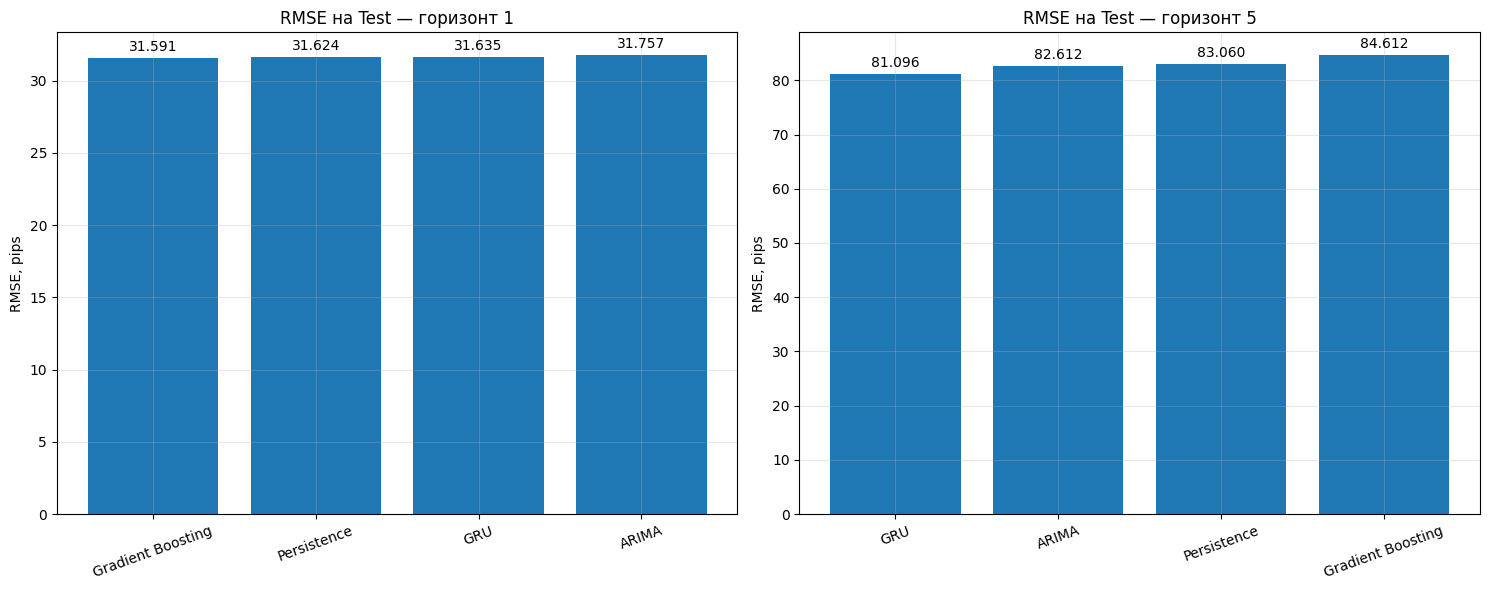

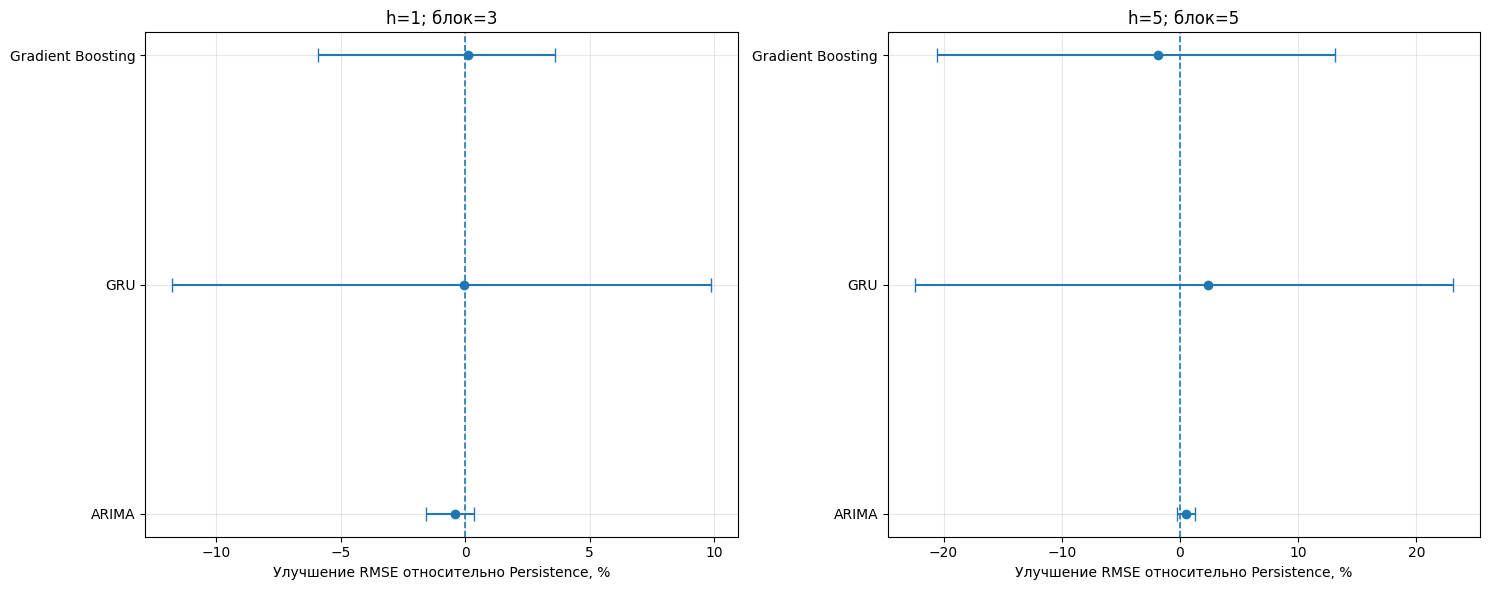

Итоговые графики сформированы. Модели и результаты Test не изменялись.


In [ ]:
# ============================================================
# БЛОК 35. ИТОГОВЫЕ ГРАФИКИ КАЧЕСТВА И НЕОПРЕДЕЛЁННОСТИ
# ============================================================

# Импорт NumPy для формирования координат графиков.
import numpy as np

# Импорт Matplotlib для визуализации сравнительных результатов.
import matplotlib.pyplot as plt


# ============================================================
# 1. СРАВНЕНИЕ RMSE ЧЕТЫРЁХ СЕМЕЙСТВ
# ============================================================

# Создание фигуры с отдельным графиком для каждого горизонта.
figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6)
)

# Последовательный перебор двух горизонтов.
for axis, horizon in zip(axes, FORECAST_HORIZONS):

    # Получение тестовых результатов текущего горизонта.
    horizon_results = (
        final_test_metrics_table.loc[
            final_test_metrics_table["Горизонт"] == horizon
        ]
        .sort_values("RMSE, pips")
    )

    # Построение столбчатой диаграммы RMSE.
    bars = axis.bar(
        horizon_results["Семейство"],
        horizon_results["RMSE, pips"]
    )

    # Подпись значений RMSE над соответствующими столбцами.
    axis.bar_label(
        bars,
        fmt="%.3f",
        padding=3
    )

    # Установка названия исследуемого горизонта.
    axis.set_title(
        f"RMSE на Test — горизонт {horizon}"
    )

    # Установка подписи вертикальной оси.
    axis.set_ylabel("RMSE, pips")

    # Небольшой наклон названий методов для читаемости.
    axis.tick_params(axis="x", labelrotation=20)

    # Добавление координатной сетки.
    axis.grid(axis="y", alpha=0.3)

# Автоматическое выравнивание элементов.
plt.tight_layout()

# Отображение итоговой диаграммы.
plt.show()


# ============================================================
# 2. ИНТЕРВАЛЫ УЛУЧШЕНИЯ RMSE ПО БЛОЧНОМУ БУТСТРЭПУ
# ============================================================

# Выбор основной длины блока для каждого горизонта.
PRIMARY_BOOTSTRAP_BLOCK_LENGTH = {
    1: 3,
    5: 5
}

# Создание фигуры для интервальных оценок.
figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6)
)

# Последовательный перебор двух горизонтов.
for axis, horizon in zip(axes, FORECAST_HORIZONS):

    # Получение результатов бутстрэпа текущего горизонта.
    horizon_bootstrap = (
        bootstrap_uncertainty_table.loc[
            (
                bootstrap_uncertainty_table["Горизонт"]
                == horizon
            )
            &
            (
                bootstrap_uncertainty_table["Длина блока"]
                == PRIMARY_BOOTSTRAP_BLOCK_LENGTH[horizon]
            )
        ]
        .sort_values("Семейство")
    )

    # Проверка наличия трёх сравниваемых моделей.
    assert len(horizon_bootstrap) == 3

    # Получение точечных оценок улучшения.
    improvements = horizon_bootstrap[
        "Улучшение RMSE, %"
    ].to_numpy(dtype=float)

    # Получение нижних границ интервалов.
    lower_bounds = horizon_bootstrap[
        "RMSE нижняя граница, %"
    ].to_numpy(dtype=float)

    # Получение верхних границ интервалов.
    upper_bounds = horizon_bootstrap[
        "RMSE верхняя граница, %"
    ].to_numpy(dtype=float)

    # Формирование асимметричных расстояний до границ.
    interval_errors = np.vstack(
        [
            improvements - lower_bounds,
            upper_bounds - improvements
        ]
    )

    # Формирование вертикальных позиций моделей.
    positions = np.arange(
        len(horizon_bootstrap)
    )

    # Отображение точечных оценок с интервальными границами.
    axis.errorbar(
        improvements,
        positions,
        xerr=interval_errors,
        fmt="o",
        capsize=5
    )

    # Отображение вертикальной линии нулевого улучшения.
    axis.axvline(
        0.0,
        linestyle="--",
        linewidth=1.2
    )

    # Установка названий сравниваемых семейств.
    axis.set_yticks(
        positions,
        horizon_bootstrap["Семейство"]
    )

    # Установка заголовка с характеристиками пересэмплирования.
    axis.set_title(
        f"h={horizon}; блок="
        f"{PRIMARY_BOOTSTRAP_BLOCK_LENGTH[horizon]}"
    )

    # Установка подписи горизонтальной оси.
    axis.set_xlabel(
        "Улучшение RMSE относительно Persistence, %"
    )

    # Добавление координатной сетки.
    axis.grid(axis="x", alpha=0.3)

# Автоматическое выравнивание элементов.
plt.tight_layout()

# Отображение графиков статистической неопределённости.
plt.show()


# ============================================================
# 3. КОНТРОЛЬ ЧИСЛА ИССЛЕДОВАННЫХ РЕЗУЛЬТАТОВ
# ============================================================

# Проверка наличия восьми итоговых тестовых результатов.
assert len(final_test_metrics_table) == 8

# Проверка наличия двенадцати интервальных оценок.
assert len(bootstrap_uncertainty_table) == 12

# Вывод сообщения о завершении графического анализа.
print(
    "Итоговые графики сформированы. "
    "Модели и результаты Test не изменялись."
)

## 24. Краткий паспорт аналитического исследования

### 24.1. Назначение документа

Краткий аналитический паспорт предназначен для демонстрации результатов исследования EUR/USD на защите практических работ № 8–9.

В документ включены следующие разделы:

1. Паспорт временного ряда.
2. Постановка задачи прогнозирования.
3. Краткое описание четырёх семейств моделей.
4. Результаты независимого Test.
5. Сравнение точности определения направления.
6. Анализ временной устойчивости.
7. Оценка неопределённости различий.
8. Вычислительные затраты.
9. Основные результаты и ограничения.

### 24.2. Правила автоматической сборки

Все числовые показатели извлекаются из результатов выполненных предыдущих блоков.

Новые модели не обучаются. Новые прогнозы не формируются. Итоговые конфигурации не изменяются.

### 24.3. Форматы представления

Краткий паспорт формируется в 2 следующих форматах:

- Markdown — для чтения и защиты;
- CSV — для табличного использования.

Markdown-версия также отображается в заключительной части исследовательского ноутбука. Обе версии создаются в одной процедуре из общих вычисленных результатов.

In [ ]:
# ============================================================
# БЛОК 36. ГЕНЕРАЦИЯ КРАТКОГО АНАЛИТИЧЕСКОГО ПАСПОРТА
# ============================================================

# Импорт класса Path для работы с путями файлов.
from pathlib import Path

# Импорт CSV-модуля для настройки табличного экспорта.
import csv

# Импорт инструментов представления Markdown в ноутбуке.
from IPython.display import display, Markdown


# ============================================================
# 1. КАТАЛОГ И ИМЕНА ЭКСПОРТИРУЕМЫХ ФАЙЛОВ
# ============================================================

# Определение каталога, содержащего итоговые паспорта.
REPORT_EXPORT_DIRECTORY = (
    research_results_directory
)

# Создание каталога экспорта при его отсутствии.
REPORT_EXPORT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

# Определение пути к краткому паспорту в формате CSV.
SHORT_REPORT_CSV_PATH = (
    REPORT_EXPORT_DIRECTORY
    / "Паспорт исследования (Краткий АО).csv"
)

# Определение пути к краткому паспорту в формате Markdown.
SHORT_REPORT_MD_PATH = (
    REPORT_EXPORT_DIRECTORY
    / "Паспорт исследования (Краткий АО).md"
)


# ============================================================
# 2. УНИВЕРСАЛЬНОЕ ПРЕДСТАВЛЕНИЕ DATAFRAME В MARKDOWN
# ============================================================

# Определение функции преобразования таблицы в Markdown.
def render_report_markdown_table(source_table):

    # Создание копии таблицы без изменения исходных данных.
    table = source_table.copy()

    # Попытка использовать стандартный форматтер Pandas.
    try:

        # Преобразование DataFrame в таблицу Markdown.
        return table.to_markdown(
            index=False,
            floatfmt=".3f"
        )

    # Если дополнительная библиотека tabulate не установлена.
    except ImportError:

        # Формирование списка названий столбцов.
        column_names = [
            str(column_name)
            for column_name in table.columns
        ]

        # Формирование заголовка таблицы Markdown.
        markdown_lines = [
            "| " + " | ".join(column_names) + " |",
            "| " + " | ".join(
                ["---"] * len(column_names)
            ) + " |"
        ]

        # Последовательное преобразование строк таблицы.
        for table_row in table.itertuples(
            index=False,
            name=None
        ):

            # Преобразование значений строки в текст.
            formatted_cells = [
                (
                    "—"
                    if pd.isna(value)
                    else (
                        f"{float(value):.3f}"
                        if isinstance(
                            value,
                            (float, np.floating)
                        )
                        else str(value)
                    )
                )
                .replace("|", r"\|")
                .replace("\n", " ")
                for value in table_row
            ]

            # Добавление строки в Markdown-таблицу.
            markdown_lines.append(
                "| " + " | ".join(formatted_cells) + " |"
            )

        # Возврат готовой Markdown-таблицы.
        return "\n".join(markdown_lines)


# ============================================================
# 3. ПОДГОТОВКА ОСНОВНОЙ ТАБЛИЦЫ КАЧЕСТВА
# ============================================================

# Определение отображаемых столбцов сравнительного исследования.
SHORT_METRIC_COLUMNS = [
    "Горизонт",
    "Семейство",
    "Конфигурация",
    "N",
    "MAE, pips",
    "RMSE, pips",
    "sMAPE, %",
    "Directional Accuracy, %",
    "Улучшение RMSE vs Persistence, %"
]

# Создание компактной таблицы восьми тестовых результатов.
short_test_metrics_table = (
    final_test_metrics_table[
        SHORT_METRIC_COLUMNS
    ]
    .sort_values(
        ["Горизонт", "RMSE, pips"]
    )
    .reset_index(drop=True)
)


# ============================================================
# 4. ПОДГОТОВКА ДОПОЛНИТЕЛЬНЫХ ТАБЛИЦ
# ============================================================

# Выбор компактных характеристик временной устойчивости.
short_temporal_table = (
    test_temporal_leaders_table[
        [
            "Горизонт",
            "Часть Test",
            "Семейство",
            "N",
            "RMSE, pips",
            "Улучшение RMSE vs Persistence, %"
        ]
    ]
    .sort_values(
        ["Горизонт", "Часть Test"]
    )
)

# Отбор основной длины блока для бутстрэп-сравнения.
short_bootstrap_table = (
    bootstrap_uncertainty_table.loc[
        bootstrap_uncertainty_table.apply(
            lambda row: (
                row["Длина блока"]
                ==
                PRIMARY_BOOTSTRAP_BLOCK_LENGTH[
                    int(row["Горизонт"])
                ]
            ),
            axis=1
        ),
        [
            "Горизонт",
            "Семейство",
            "Улучшение RMSE, %",
            "RMSE нижняя граница, %",
            "RMSE верхняя граница, %",
            "Интервал RMSE включает ноль"
        ]
    ]
    .sort_values(
        ["Горизонт", "Семейство"]
    )
)

# Получение компактной таблицы вычислительных затрат.
short_computation_table = (
    final_test_computation_table[
        [
            "Горизонт",
            "Семейство",
            "Время обучения, с",
            "Время прогнозирования, с"
        ]
    ]
    .sort_values(
        ["Горизонт", "Семейство"]
    )
)


# ============================================================
# 5. АВТОМАТИЧЕСКОЕ ФОРМИРОВАНИЕ ВЫВОДОВ
# ============================================================

# Создание списка текстовых аналитических выводов.
short_report_findings = []

# Последовательный анализ горизонтов прогнозирования.
for horizon in FORECAST_HORIZONS:

    # Получение результатов четырёх моделей текущего горизонта.
    horizon_results = (
        final_test_metrics_table.loc[
            final_test_metrics_table["Горизонт"] == horizon
        ]
        .sort_values("RMSE, pips")
    )

    # Определение лидера по минимальной RMSE.
    price_leader = horizon_results.iloc[0]

    # Определение лидера по максимальной точности направления.
    direction_leader = (
        horizon_results
        .sort_values(
            "Directional Accuracy, %",
            ascending=False
        )
        .iloc[0]
    )

    # Получение результатов контрольных направленных стратегий.
    reference_directions = (
        test_direction_reference_table.loc[
            (
                test_direction_reference_table["Горизонт"]
                == horizon
            )
            &
            (
                test_direction_reference_table["Стратегия"]
                != "Persistence"
            )
        ]
        .sort_values(
            "Directional Accuracy, %",
            ascending=False
        )
    )

    # Определение наиболее точной контрольной стратегии.
    direction_reference_leader = reference_directions.iloc[0]

    # Получение лидеров двух временных частей Test.
    temporal_leaders = (
        test_temporal_leaders_table.loc[
            test_temporal_leaders_table["Горизонт"]
            == horizon
        ]
        .sort_values("Часть Test")
    )

    # Формирование текстового перечня временных лидеров.
    temporal_leaders_text = "; ".join(
        (
            f"{row['Часть Test']}: {row['Семейство']}"
        )
        for _, row in temporal_leaders.iterrows()
    )

    # Формирование вывода по текущему горизонту.
    current_finding = (
        f"Горизонт {horizon}: "
        f"лидер по RMSE — {price_leader['Семейство']} "
        f"({float(price_leader['RMSE, pips']):.3f} pips); "
        f"улучшение относительно Persistence — "
        f"{float(price_leader['Улучшение RMSE vs Persistence, %']):+.3f}%. "
        f"Лидер по направлению — "
        f"{direction_leader['Семейство']} "
        f"({float(direction_leader['Directional Accuracy, %']):.2f}%). "
        f"Лучшая простая стратегия — "
        f"{direction_reference_leader['Стратегия']} "
        f"({float(direction_reference_leader['Directional Accuracy, %']):.2f}%). "
        f"Лидеры частей Test: {temporal_leaders_text}."
    )

    # Сохранение автоматически сформированного вывода.
    short_report_findings.append(
        current_finding
    )


# ============================================================
# 6. ФОРМИРОВАНИЕ MARKDOWN-ПАСПОРТА
# ============================================================

# Создание списка разделов краткого аналитического отчёта.
short_report_sections = [
    "# Паспорт исследования — краткий аналитический отчёт",

    "## 1. Общая характеристика",

    (
        "**Предмет:** прогнозирование дневного курса EUR/USD "
        "в рамках практических работ № 8–9 по АДиМО."
    ),

    (
        f"**Источник подготовленных данных:** "
        f"`{dataset_path.name}`; "
        f"наблюдений: **{len(market_data)}**; "
        f"фактический период: "
        f"**{market_data.index.min().date()} — "
        f"{market_data.index.max().date()}**."
    ),

    (
        "**Горизонты:** 1 и 5 торговых дней. "
        "**Методы:** Persistence, ARIMA, Gradient Boosting, GRU."
    ),

    (
        "**Протокол:** хронологический Train / Validation / Test, "
        "фиксация гиперпараметров до независимого тестирования, "
        "последующее обучение на Train + Validation."
    ),

    "## 2. Финальные результаты на Test",

    render_report_markdown_table(
        short_test_metrics_table.round(3)
    ),

    (
        "Основной критерий сравнения цены — RMSE. "
        "Directional Accuracy оценивает направление отдельно."
    ),

    "## 3. Временная устойчивость",

    render_report_markdown_table(
        short_temporal_table.round(3)
    ),

    "## 4. Интервалы улучшения RMSE",

    render_report_markdown_table(
        short_bootstrap_table.round(3)
    ),

    (
        "Интервалы являются приближёнными процентильными "
        "оценками кругового блочного бутстрэпа. "
        "Полные результаты для двух длин блоков "
        "содержатся в исследовательском ноутбуке."
    ),

    "## 5. Вычислительные затраты",

    render_report_markdown_table(
        short_computation_table.round(3)
    ),

    (
        "Время измерено для конкретного запуска. "
        "ARIMA прогнозирует последовательно, "
        "а Gradient Boosting и GRU — пакетно."
    ),

    "## 6. Основные выводы"
]

# Добавление автоматически вычисленных выводов.
for finding in short_report_findings:

    # Добавление очередного вывода в Markdown.
    short_report_sections.append(
        f"- {finding}"
    )

# Добавление методологических ограничений исследования.
short_report_sections.extend(
    [
        "## 7. Ограничения",

        (
            "Тестовые выборки содержат 39 и 35 прогнозов. "
            "Пятидневные прогнозные горизонты перекрываются. "
            "Оценки чувствительны к рыночному периоду, "
            "а интервалы бутстрэпа — к длине блока."
        ),

        (
            "Результаты не устанавливают универсального "
            "статистического превосходства какой-либо модели "
            "на будущих рыночных периодах и не являются "
            "оценкой прибыльности торговой стратегии."
        ),

        (
            "**Статус исследования:** все четыре семейства "
            "реализованы, настроены на Validation и независимо "
            "проверены на Test; последующий анализ "
            "не изменял модели или прогнозы."
        )
    ]
)

# Объединение разделов в цельный Markdown-документ.
short_report_markdown = "\n\n".join(
    short_report_sections
)


# ============================================================
# 7. ПОДГОТОВКА ТАБЛИЧНОГО CSV-ПАСПОРТА
# ============================================================

# Создание списка строк структурированного краткого паспорта.
short_csv_rows = []

# Добавление метаданных об исследуемом наборе данных.
short_csv_rows.append(
    {
        "Раздел": "Паспорт данных",
        "Комментарий": (
            f"Файл: {dataset_path.name}; "
            f"наблюдений: {len(market_data)}; "
            f"период: {market_data.index.min().date()} — "
            f"{market_data.index.max().date()}"
        )
    }
)

# Последовательное добавление финальных тестовых результатов.
for _, result_row in short_test_metrics_table.iterrows():

    # Добавление результатов текущего семейства и горизонта.
    short_csv_rows.append(
        {
            "Раздел": "Результаты Test",
            **result_row.to_dict()
        }
    )

# Последовательное добавление временных лидеров.
for _, result_row in short_temporal_table.iterrows():

    # Добавление строки временной устойчивости.
    short_csv_rows.append(
        {
            "Раздел": "Временная устойчивость",
            "Горизонт": result_row["Горизонт"],
            "Семейство": result_row["Семейство"],
            "N": result_row["N"],
            "RMSE, pips": result_row["RMSE, pips"],
            "Улучшение RMSE vs Persistence, %": (
                result_row["Улучшение RMSE vs Persistence, %"]
            ),
            "Комментарий": result_row["Часть Test"]
        }
    )

# Последовательное добавление интервальных оценок.
for _, result_row in short_bootstrap_table.iterrows():

    # Добавление строки неопределённости улучшения RMSE.
    short_csv_rows.append(
        {
            "Раздел": "Бутстрэп",
            **result_row.to_dict()
        }
    )

# Последовательное добавление вычислительных характеристик.
for _, result_row in short_computation_table.iterrows():

    # Добавление строки затрат на обучение и прогнозирование.
    short_csv_rows.append(
        {
            "Раздел": "Вычислительные затраты",
            **result_row.to_dict()
        }
    )

# Последовательное добавление основных текстовых выводов.
for finding in short_report_findings:

    # Добавление аналитического вывода в табличный паспорт.
    short_csv_rows.append(
        {
            "Раздел": "Основной вывод",
            "Комментарий": finding
        }
    )

# Добавление ограничений исследования.
short_csv_rows.append(
    {
        "Раздел": "Ограничения",
        "Комментарий": (
            "Небольшой Test; зависимые пятидневные ошибки; "
            "неустойчивость результатов по периодам; "
            "чувствительность бутстрэпа к длине блока."
        )
    }
)

# Формирование итоговой таблицы краткого паспорта.
short_report_csv_table = pd.DataFrame(
    short_csv_rows
)


# ============================================================
# 8. ЭКСПОРТ КРАТКОГО ПАСПОРТА
# ============================================================

# Сохранение Markdown-паспорта в кодировке UTF-8.
SHORT_REPORT_MD_PATH.write_text(
    short_report_markdown + "\n",
    encoding="utf-8"
)

# Сохранение CSV с BOM для удобного открытия в Excel.
short_report_csv_table.to_csv(
    SHORT_REPORT_CSV_PATH,
    index=False,
    encoding="utf-8-sig",
    quoting=csv.QUOTE_ALL
)


# ============================================================
# 9. ОТОБРАЖЕНИЕ ПАСПОРТА В GOOGLE COLAB
# ============================================================

# Отображение итогового краткого отчёта в Markdown.
display(
    Markdown(short_report_markdown)
)

# Вывод путей к успешно сформированным документам.
print("\nКраткий аналитический паспорт экспортирован:")

print(SHORT_REPORT_CSV_PATH)
print(SHORT_REPORT_MD_PATH)

# Паспорт исследования — краткий аналитический отчёт

## 1. Общая характеристика

**Предмет:** прогнозирование дневного курса EUR/USD в рамках практических работ № 8–9 по АДиМО.

**Источник подготовленных данных:** `eurusd_d1_bid_final.csv`; наблюдений: **259**; фактический период: **2025-10-02 — 2026-09-30**.

**Горизонты:** 1 и 5 торговых дней. **Методы:** Persistence, ARIMA, Gradient Boosting, GRU.

**Протокол:** хронологический Train / Validation / Test, фиксация гиперпараметров до независимого тестирования, последующее обучение на Train + Validation.

## 2. Финальные результаты на Test

|   Горизонт | Семейство         | Конфигурация        |   N |   MAE, pips |   RMSE, pips |   sMAPE, % |   Directional Accuracy, % |   Улучшение RMSE vs Persistence, % |
|-----------:|:------------------|:--------------------|----:|------------:|-------------:|-----------:|--------------------------:|-----------------------------------:|
|          1 | Gradient Boosting | GBR_07_Depth3_Huber |  39 |      22.494 |       31.591 |      0.195 |                    53.846 |                              0.104 |
|          1 | Persistence       | No-change           |  39 |      21.667 |       31.624 |      0.188 |                     0.000 |                              0.000 |
|          1 | GRU               | GRU_01_Units8       |  39 |      22.074 |       31.635 |      0.191 |                    46.154 |                             -0.035 |
|          1 | ARIMA             | ARIMA(1,1,0)-n      |  39 |      21.877 |       31.757 |      0.189 |                    48.718 |                             -0.423 |
|          5 | GRU               | GRU_04_Huber16      |  35 |      67.236 |       81.096 |      0.583 |                    54.286 |                              2.365 |
|          5 | ARIMA             | ARIMA(0,1,2)-n      |  35 |      70.186 |       82.612 |      0.608 |                    51.429 |                              0.539 |
|          5 | Persistence       | No-change           |  35 |      70.377 |       83.060 |      0.609 |                     0.000 |                              0.000 |
|          5 | Gradient Boosting | GBR_01_Stump_80     |  35 |      71.173 |       84.612 |      0.617 |                    65.714 |                             -1.868 |

Основной критерий сравнения цены — RMSE. Directional Accuracy оценивает направление отдельно.

## 3. Временная устойчивость

|   Горизонт | Часть Test      | Семейство   |   N |   RMSE, pips |   Улучшение RMSE vs Persistence, % |
|-----------:|:----------------|:------------|----:|-------------:|-----------------------------------:|
|          1 | Вторая половина | ARIMA       |  20 |       29.675 |                              0.383 |
|          1 | Первая половина | GRU         |  19 |       32.609 |                              2.502 |
|          5 | Вторая половина | ARIMA       |  18 |       87.017 |                              0.975 |
|          5 | Первая половина | GRU         |  17 |       60.235 |                             22.417 |

## 4. Интервалы улучшения RMSE

|   Горизонт | Семейство         |   Улучшение RMSE, % |   RMSE нижняя граница, % |   RMSE верхняя граница, % | Интервал RMSE включает ноль   |
|-----------:|:------------------|--------------------:|-------------------------:|--------------------------:|:------------------------------|
|          1 | ARIMA             |              -0.423 |                   -1.566 |                     0.359 | True                          |
|          1 | GRU               |              -0.035 |                  -11.746 |                     9.850 | True                          |
|          1 | Gradient Boosting |               0.104 |                   -5.913 |                     3.610 | True                          |
|          5 | ARIMA             |               0.539 |                   -0.248 |                     1.264 | True                          |
|          5 | GRU               |               2.365 |                  -22.427 |                    23.110 | True                          |
|          5 | Gradient Boosting |              -1.868 |                  -20.567 |                    13.102 | True                          |

Интервалы являются приближёнными процентильными оценками кругового блочного бутстрэпа. Полные результаты для двух длин блоков содержатся в исследовательском ноутбуке.

## 5. Вычислительные затраты

|   Горизонт | Семейство         |   Время обучения, с |   Время прогнозирования, с |
|-----------:|:------------------|--------------------:|---------------------------:|
|          1 | ARIMA             |               0.025 |                      0.177 |
|          1 | GRU               |               2.386 |                      0.075 |
|          1 | Gradient Boosting |               0.184 |                      0.001 |
|          1 | Persistence       |               0.000 |                      0.000 |
|          5 | ARIMA             |               0.126 |                      0.389 |
|          5 | GRU               |               4.005 |                      0.057 |
|          5 | Gradient Boosting |               0.116 |                      0.002 |
|          5 | Persistence       |               0.000 |                      0.000 |

Время измерено для конкретного запуска. ARIMA прогнозирует последовательно, а Gradient Boosting и GRU — пакетно.

## 6. Основные выводы

- Горизонт 1: лидер по RMSE — Gradient Boosting (31.591 pips); улучшение относительно Persistence — +0.104%. Лидер по направлению — Gradient Boosting (53.85%). Лучшая простая стратегия — Всегда снижение (56.41%). Лидеры частей Test: Вторая половина: ARIMA; Первая половина: GRU.

- Горизонт 5: лидер по RMSE — GRU (81.096 pips); улучшение относительно Persistence — +2.365%. Лидер по направлению — Gradient Boosting (65.71%). Лучшая простая стратегия — Всегда снижение (62.86%). Лидеры частей Test: Вторая половина: ARIMA; Первая половина: GRU.

## 7. Ограничения

Тестовые выборки содержат 39 и 35 прогнозов. Пятидневные прогнозные горизонты перекрываются. Оценки чувствительны к рыночному периоду, а интервалы бутстрэпа — к длине блока.

Результаты не устанавливают универсального статистического превосходства какой-либо модели на будущих рыночных периодах и не являются оценкой прибыльности торговой стратегии.

**Статус исследования:** все четыре семейства реализованы, настроены на Validation и независимо проверены на Test; последующий анализ не изменял модели или прогнозы.


Краткий аналитический паспорт экспортирован:
/content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/results/Паспорт исследования (Краткий АО).csv
/content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/results/Паспорт исследования (Краткий АО).md


## 25. Подробный аналитический паспорт исследования

### 25.1. Назначение документа

Подробный аналитический паспорт предназначен для документирования всего вычислительного исследования EUR/USD в исходной последовательности.

Он представляет собой воспроизводимый исследовательский протокол, содержащий
постановку задачи, исходный код, методологические пояснения и сохранённые результаты.

### 25.2. Источник формирования

Основным источником подробного паспорта является сохранённый файл Jupyter Notebook в формате `.ipynb`

Документ содержит последовательность Markdown- и Code-ячеек. Для Code-ячеек при наличии сохраняются результаты их выполнения.

### 25.3. Состав сохраняемых материалов

В подробный паспорт включаются следующие компоненты:

1. Исходные Markdown-ячейки.
2. Исходный Python-код.
3. Порядок расположения ячеек.
4. Номера выполнения, если они сохранены.
5. Текстовые сообщения и результаты вычислений.
6. Таблицы в формате HTML.
7. Статические графические изображения.
8. Сообщения об ошибках и диагностике.
9. Ссылки на дополнительные данные результатов.

### 25.4. Формат .CSV

.CSV представляет собой структурированный реестр ячеек и результатов выполнения.

Каждая запись содержит следующую информацию:

- номер ячейки;
- тип ячейки;
- номер выполнения;
- номер вывода;
- тип результата;
- MIME-формат;
- текст или содержимое результата;
- путь к внешнему ресурсу при необходимости.

Изображения не помещаются в .CSV как бинарные объекты, поэтому .CSV содержит относительные пути к сохранённым иллюстрациям.

### 25.5. Формат Markdown

Markdown представляет собой последовательный исследовательский документ.

Каждая ячейка получает отдельный заголовок.

Python-код помещается в программный блок.

Результаты выполнения размещаются непосредственно после соответствующего кода.

Изображения сохраняются отдельно и включаются в документ относительными Markdown-ссылками.

Таблицы HTML сохраняются как фрагменты HTML, которые поддерживаются многими Markdown-просмотрщиками.

### 25.6. Ограничения экспорта

Подробный паспорт отражает содержимое сохранённой версии ноутбука.

Если результаты выполнения не были сохранены, экспорт не сможет восстановить их автоматически.

Интерактивные виджеты и внешние визуализации могут не иметь полноценного статического представления в Markdown и CSV.

В таких случаях сохраняются доступные данные результата, но оригинальный `.ipynb` остаётся основным источником исследования.

Повторное обучение или вычисление прогнозов во время формирования паспорта не выполняется.

In [ ]:
# ============================================================
# БЛОК 37. ЭКСПОРТ ПОЛНОЙ ХРОНОЛОГИИ ИССЛЕДОВАТЕЛЬСКОГО NOTEBOOK
# ============================================================

# Импорт библиотеки чтения и анализа Jupyter Notebook.
import nbformat

# Импорт модуля декодирования графических данных.
import base64

# Импорт модуля регулярных выражений.
import re

# Импорт модуля сериализации дополнительных структурированных данных.
import json

# Импорт класса Path для работы с файлами и каталогами.
from pathlib import Path

# Импорт CSV-модуля для структурированного экспорта.
import csv


# ============================================================
# 1. ОПРЕДЕЛЕНИЕ ИСХОДНОГО NOTEBOOK
# ============================================================

# Определение необязательного точного имени исходного ноутбука.
# Если в проектной папке находится один .ipynb, оставляем None.
SOURCE_NOTEBOOK_FILENAME = None


# Поиск файлов Jupyter Notebook в папке проекта.
notebook_candidates = sorted(
    notebook_directory.glob("*.ipynb")
)


# Если имя задано явно, то используем указанную копию.
if SOURCE_NOTEBOOK_FILENAME is not None:

    # Формирование пути к явно выбранному ноутбуку.
    source_notebook_path = (
        notebook_directory / SOURCE_NOTEBOOK_FILENAME
    )

# Если в проекте найден только один ноутбук, то выбираем его.
elif len(notebook_candidates) == 1:

    # Получение единственного доступного пути.
    source_notebook_path = notebook_candidates[0]

# Если доступно несколько файлов или не найдено ни одного.
else:

    # Генерация ошибки неоднозначного выбора.
    raise RuntimeError(
        "Необходимо указать SOURCE_NOTEBOOK_FILENAME.\n"
        "Найденные ноутбуки:\n"
        +
        "\n".join(
            str(candidate)
            for candidate in notebook_candidates
        )
    )


# Проверка существования файла исходного исследования.
if not source_notebook_path.is_file():

    # Генерация исключения при отсутствии файла.
    raise FileNotFoundError(
        f"Не найден исходный notebook: {source_notebook_path}"
    )


# Чтение сохранённого ноутбука в формате Jupyter Notebook версии 4.
source_notebook = nbformat.read(
    str(source_notebook_path),
    as_version=4
)


# ============================================================
# 2. СОЗДАНИЕ КАТАЛОГОВ И ОПРЕДЕЛЕНИЕ ПУТЕЙ
# ============================================================

# Определение пути подробного отчёта в формате CSV.
DETAILED_REPORT_CSV_PATH = (
    REPORT_EXPORT_DIRECTORY
    / "Паспорт исследования (Подробный АО).csv"
)

# Определение пути подробного отчёта в формате Markdown.
DETAILED_REPORT_MD_PATH = (
    REPORT_EXPORT_DIRECTORY
    / "Паспорт исследования (Подробный АО).md"
)

# Определение папки для извлечённых графиков и вложений.
DETAILED_REPORT_ASSETS_DIRECTORY = (
    REPORT_EXPORT_DIRECTORY
    / "Иллюстрации паспорта исследования (Подробный АО)"
)

# Создание каталога иллюстраций при отсутствии.
DETAILED_REPORT_ASSETS_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

# Определение функции объединения текстовых строк ноутбука.
def normalize_notebook_text(value):

    # Если текст представлен списком строк, то объединяем его.
    if isinstance(value, list):

        # Возврат восстановленного исходного текста.
        return "".join(
            str(fragment)
            for fragment in value
        )

    # Если значение отсутствует, то возвращаем пустую строку.
    if value is None:

        # Возврат пустого текстового результата.
        return ""

    # Преобразование одиночного значения в строку.
    return str(value)


# Определение функции удаления управляющих ANSI-последовательностей.
def clean_notebook_output(value):

    # Получение исходного текстового представления.
    result_text = normalize_notebook_text(
        value
    )

    # Удаление цветовых ANSI-кодов из сообщений терминала.
    return re.sub(
        r"\x1b\[[0-9;]*[A-Za-z]",
        "",
        result_text
    )


# Определение функции формирования безопасного Markdown-кодового блока.
def create_report_code_block(source_text, language="text"):

    # Поиск всех последовательностей обратных апострофов в исходном тексте.
    existing_fences = re.findall(
        r"`+",
        source_text
    )

    # Определение максимальной длины найденного разделителя.
    maximum_fence_length = max(
        (
            len(fence)
            for fence in existing_fences
        ),
        default=0
    )

    # Формирование достаточно длинного разделителя Markdown.
    markdown_fence = "`" * max(
        4,
        maximum_fence_length + 1
    )

    # Возврат форматированного блока исходного текста.
    return (
        f"{markdown_fence}{language}\n"
        f"{source_text.rstrip()}\n"
        f"{markdown_fence}"
    )


# Определение функции извлечения изображения из результата Notebook.
def save_notebook_image(
    image_data,
    mime_type,
    cell_number,
    output_number
):

    # Определение соответствующего расширения графического файла.
    image_extensions = {
        "image/png": ".png",
        "image/jpeg": ".jpg",
        "image/svg+xml": ".svg"
    }

    # Проверка поддержки графического MIME-формата.
    if mime_type not in image_extensions:

        # Генерация исключения для неизвестного типа изображения.
        raise ValueError(
            f"Неподдерживаемый формат изображения: {mime_type}"
        )

    # Формирование говорящего имени извлечённого изображения.
    image_filename = (
        f"Иллюстрация_ячейка_{cell_number:04d}"
        f"_вывод_{output_number:03d}"
        f"{image_extensions[mime_type]}"
    )

    # Формирование абсолютного пути к изображению.
    image_path = (
        DETAILED_REPORT_ASSETS_DIRECTORY
        / image_filename
    )

    # Если изображение сохранено в формате SVG.
    if mime_type == "image/svg+xml":

        # Сохранение текстового представления SVG.
        image_path.write_text(
            normalize_notebook_text(image_data),
            encoding="utf-8"
        )

    # Если изображение представлено двоичными данными Base64.
    else:

        # Удаление пробельных символов из Base64-представления.
        encoded_image = "".join(
            normalize_notebook_text(image_data).split()
        )

        # Декодирование графического изображения.
        decoded_image = base64.b64decode(
            encoded_image
        )

        # Сохранение исходного изображения без перекодирования.
        image_path.write_bytes(
            decoded_image
        )

    # Формирование относительного пути для Markdown и CSV.
    relative_image_path = (
        f"{DETAILED_REPORT_ASSETS_DIRECTORY.name}/"
        f"{image_filename}"
    )

    # Возврат относительного пути к изображению.
    return relative_image_path


# ============================================================
# 4. ПОДГОТОВКА ХРАНИЛИЩ РЕЗУЛЬТАТОВ
# ============================================================

# Создание списка строк подробного CSV-паспорта.
detailed_csv_rows = []

# Создание списка частей хронологического Markdown-документа.
detailed_markdown_parts = []

# Создание счётчика сохранённых результатов выполнения.
saved_output_count = 0

# Создание счётчика извлечённых графических объектов.
saved_image_count = 0

# Создание счётчика сохранённых HTML-результатов.
saved_html_count = 0

# Создание счётчика результатов без статического представления.
unhandled_output_count = 0


# ============================================================
# 5. ПОСЛЕДОВАТЕЛЬНЫЙ ОБХОД ЯЧЕЕК ИСХОДНОГО NOTEBOOK
# ============================================================

# Последовательный перебор ячеек в порядке исходного документа.
for cell_number, notebook_cell in enumerate(
    source_notebook.cells,
    start=1
):

    # Получение типа текущей ячейки.
    cell_type = notebook_cell.get(
        "cell_type",
        "unknown"
    )

    # Получение исходного текста ячейки.
    cell_source = normalize_notebook_text(
        notebook_cell.get(
            "source",
            ""
        )
    )

    # Получение номера выполнения, если он сохранён.
    execution_count = notebook_cell.get(
        "execution_count"
    )

    # ========================================================
    # 6. ВОССТАНОВЛЕНИЕ ВЛОЖЕНИЙ MARKDOWN-ЯЧЕЕК
    # ========================================================

    # Получение списка вложений текущей ячейки.
    attachments = notebook_cell.get(
        "attachments",
        {}
    )

    # Последовательное извлечение вложенных изображений.
    for attachment_number, (
        attachment_filename,
        attachment_data
    ) in enumerate(
        attachments.items(),
        start=1
    ):

        # Последовательный поиск поддерживаемого графического MIME.
        for mime_type in [
            "image/png",
            "image/jpeg",
            "image/svg+xml"
        ]:

            # Проверка наличия изображения заданного формата.
            if mime_type in attachment_data:

                # Сохранение вложенного изображения на диск.
                attachment_relative_path = save_notebook_image(
                    image_data=attachment_data[mime_type],
                    mime_type=mime_type,
                    cell_number=cell_number,
                    output_number=1000 + attachment_number
                )

                # Замена встроенной ссылки Notebook на относительный путь.
                cell_source = cell_source.replace(
                    f"attachment:{attachment_filename}",
                    attachment_relative_path
                )

                # Добавление вложения в подробный CSV-реестр.
                detailed_csv_rows.append(
                    {
                        "Номер ячейки": cell_number,
                        "Тип ячейки": cell_type,
                        "Номер выполнения": execution_count,
                        "Номер вывода": attachment_number,
                        "Тип записи": "Вложенное изображение",
                        "MIME": mime_type,
                        "Содержимое": attachment_filename,
                        "Путь ресурса": attachment_relative_path
                    }
                )

                # Увеличение счётчика извлечённых изображений.
                saved_image_count += 1

                # Завершение поиска формата текущего вложения.
                break


    # ========================================================
    # 7. СОХРАНЕНИЕ ИСХОДНОГО СОДЕРЖИМОГО ЯЧЕЙКИ
    # ========================================================

    # Добавление исходного текста ячейки в CSV-реестр.
    detailed_csv_rows.append(
        {
            "Номер ячейки": cell_number,
            "Тип ячейки": cell_type,
            "Номер выполнения": execution_count,
            "Номер вывода": 0,
            "Тип записи": "Исходная ячейка",
            "MIME": (
                "text/x-python"
                if cell_type == "code"
                else "text/markdown"
            ),
            "Содержимое": cell_source,
            "Путь ресурса": ""
        }
    )

    # Формирование заголовка текущей ячейки.
    detailed_markdown_parts.append(
        f"\n---\n\n## Ячейка {cell_number:04d} — {cell_type}"
    )

    # Если текущая ячейка содержит исполняемый Python-код.
    if cell_type == "code":

        # Добавление исходного кода в отдельном программном блоке.
        detailed_markdown_parts.append(
            create_report_code_block(
                cell_source,
                language="python"
            )
        )

    # Если текущая ячейка содержит Markdown или сырой текст.
    else:

        # Добавление содержимого без изменения его структуры.
        detailed_markdown_parts.append(
            cell_source
        )


    # ========================================================
    # 8. ОБРАБОТКА РЕЗУЛЬТАТОВ CODE-ЯЧЕЙКИ
    # ========================================================

    # Получение сохранённых результатов выполнения текущей ячейки.
    notebook_outputs = notebook_cell.get(
        "outputs",
        []
    )

    # Последовательный обход сохранённых результатов.
    for output_number, notebook_output in enumerate(
        notebook_outputs,
        start=1
    ):

        # Увеличение общего счётчика результатов.
        saved_output_count += 1

        # Получение типа результата выполнения.
        output_type = notebook_output.get(
            "output_type",
            "unknown"
        )

        # Формирование заголовка отдельного результата.
        detailed_markdown_parts.append(
            f"### Результат {output_number}"
        )

        # Определение полей будущей CSV-записи.
        result_mime = ""
        result_content = ""
        result_resource_path = ""

        # ====================================================
        # 9. ТЕКСТОВЫЕ РЕЗУЛЬТАТЫ STDOUT И STDERR
        # ====================================================

        # Если результат является текстовым потоком.
        if output_type == "stream":

            # Получение текста вывода программы.
            result_content = clean_notebook_output(
                notebook_output.get("text", "")
            )

            # Определение MIME текстового результата.
            result_mime = "text/plain"

            # Добавление текста в Markdown-протокол.
            detailed_markdown_parts.append(
                create_report_code_block(
                    result_content,
                    language="text"
                )
            )

        # ====================================================
        # 10. СОХРАНЁННЫЕ СООБЩЕНИЯ ОБ ОШИБКАХ
        # ====================================================

        # Если результат содержит исключение Python.
        elif output_type == "error":

            # Получение исходного traceback ошибки.
            result_content = clean_notebook_output(
                notebook_output.get("traceback", [])
            )

            # Установка формата текстового вывода ошибки.
            result_mime = "text/plain"

            # Добавление диагностического traceback в Markdown.
            detailed_markdown_parts.append(
                create_report_code_block(
                    result_content,
                    language="text"
                )
            )

        # ====================================================
        # 11. ГРАФИЧЕСКИЕ И ТАБЛИЧНЫЕ РЕЗУЛЬТАТЫ
        # ====================================================

        # Если результат содержит структурированные данные отображения.
        elif output_type in [
            "display_data",
            "execute_result"
        ]:

            # Получение сохранённых MIME-представлений.
            output_data = notebook_output.get(
                "data",
                {}
            )

            # Определение доступных графических представлений.
            image_mime = next(
                (
                    mime_type
                    for mime_type in [
                        "image/png",
                        "image/jpeg",
                        "image/svg+xml"
                    ]
                    if mime_type in output_data
                ),
                None
            )

            # Если результат содержит графическое изображение.
            if image_mime is not None:

                # Сохранение изображения в отдельный файл.
                result_resource_path = save_notebook_image(
                    image_data=output_data[image_mime],
                    mime_type=image_mime,
                    cell_number=cell_number,
                    output_number=output_number
                )

                # Установка MIME сохранённого графика.
                result_mime = image_mime

                # Сохранение подписи графического результата.
                result_content = (
                    f"Изображение результата {output_number}"
                )

                # Добавление изображения в Markdown-протокол.
                detailed_markdown_parts.append(
                    f"![График ячейки {cell_number}, "
                    f"результат {output_number}]"
                    f"({result_resource_path})"
                )

                # Увеличение счётчика графиков.
                saved_image_count += 1

            # Если результат содержит HTML-представление таблицы.
            elif "text/html" in output_data:

                # Получение оригинального HTML-результата.
                result_content = normalize_notebook_text(
                    output_data["text/html"]
                )

                # Установка MIME табличного представления.
                result_mime = "text/html"

                # Добавление HTML непосредственно в Markdown-документ.
                detailed_markdown_parts.append(
                    result_content
                )

                # Увеличение счётчика HTML-результатов.
                saved_html_count += 1

            # Если результат представлен непосредственно как Markdown.
            elif "text/markdown" in output_data:

                # Получение исходного Markdown-вывода.
                result_content = normalize_notebook_text(
                    output_data["text/markdown"]
                )

                # Установка MIME исходного результата.
                result_mime = "text/markdown"

                # Добавление Markdown-результата в документ.
                detailed_markdown_parts.append(
                    result_content
                )

            # Если сохранён обычный текстовый результат.
            elif "text/plain" in output_data:

                # Получение текстового представления результата.
                result_content = clean_notebook_output(
                    output_data["text/plain"]
                )

                # Установка текстового MIME.
                result_mime = "text/plain"

                # Добавление результата в программный блок Markdown.
                detailed_markdown_parts.append(
                    create_report_code_block(
                        result_content,
                        language="text"
                    )
                )

            # Если сохранён иной структурированный тип данных.
            else:

                # Сериализация исходного MIME-словаря в JSON.
                result_content = json.dumps(
                    dict(output_data),
                    ensure_ascii=False,
                    indent=2,
                    default=str
                )

                # Установка MIME резервного JSON-представления.
                result_mime = "application/json"

                # Добавление JSON-данных результата.
                detailed_markdown_parts.append(
                    create_report_code_block(
                        result_content,
                        language="json"
                    )
                )

                # Увеличение счётчика нетиповых результатов.
                unhandled_output_count += 1

        # ====================================================
        # 12. РЕЗЕРВНАЯ ОБРАБОТКА НЕИЗВЕСТНОГО ВЫВОДА
        # ====================================================

        # Если формат результата не соответствует известным типам.
        else:

            # Сериализация неизвестного результата в JSON.
            result_content = json.dumps(
                dict(notebook_output),
                ensure_ascii=False,
                indent=2,
                default=str
            )

            # Установка резервного MIME.
            result_mime = "application/json"

            # Добавление результата в Markdown-протокол.
            detailed_markdown_parts.append(
                create_report_code_block(
                    result_content,
                    language="json"
                )
            )

            # Увеличение счётчика нестандартных выводов.
            unhandled_output_count += 1


        # ====================================================
        # 13. РЕГИСТРАЦИЯ РЕЗУЛЬТАТА В CSV
        # ====================================================

        # Сохранение всех сведений о текущем выводе.
        detailed_csv_rows.append(
            {
                "Номер ячейки": cell_number,
                "Тип ячейки": cell_type,
                "Номер выполнения": execution_count,
                "Номер вывода": output_number,
                "Тип записи": output_type,
                "MIME": result_mime,
                "Содержимое": result_content,
                "Путь ресурса": result_resource_path
            }
        )


# ============================================================
# 14. ФОРМИРОВАНИЕ ИТОГОВОГО MARKDOWN-ДОКУМЕНТА
# ============================================================

# Определение заголовка полного исследовательского паспорта.
detailed_report_header = f"""
# Паспорт исследования — подробный аналитический отчёт

**Исследование:** прогнозирование финансового временного ряда EUR/USD.

**Исходный документ:** `{source_notebook_path.name}`.

**Количество ячеек:** {len(source_notebook.cells)}.

**Сохранённых результатов выполнения:** {saved_output_count}.

**Извлечённых изображений:** {saved_image_count}.

**Сохранённых HTML-результатов:** {saved_html_count}.

**Нестандартных результатов:** {unhandled_output_count}.

## Принцип формирования

Документ воспроизводит исходную последовательность ячеек
сохранённого Jupyter Notebook.

Для каждой Code-ячейки приводятся исходный код
и доступные сохранённые результаты выполнения.

Графики хранятся в сопутствующей папке
«Иллюстрации подробного АО».

Номера ячеек соответствуют порядку в документе,
а не обязательно фактическому порядку повторных запусков.

Экспорт не выполняет повторного обучения моделей
или пересчёта результатов.

---
"""

# Объединение заголовка и хронологических разделов.
detailed_report_markdown = (
    detailed_report_header
    +
    "\n\n".join(detailed_markdown_parts)
    +
    "\n"
)


# ============================================================
# 15. СОХРАНЕНИЕ ПОДРОБНОГО ПАСПОРТА
# ============================================================

# Сохранение Markdown-версии подробного исследования.
DETAILED_REPORT_MD_PATH.write_text(
    detailed_report_markdown,
    encoding="utf-8"
)

# Формирование структурированного CSV-реестра.
detailed_report_csv_table = pd.DataFrame(
    detailed_csv_rows
)

# Экспорт CSV с кодировкой, совместимой с Excel.
detailed_report_csv_table.to_csv(
    DETAILED_REPORT_CSV_PATH,
    index=False,
    encoding="utf-8-sig",
    quoting=csv.QUOTE_ALL
)


# ============================================================
# 16. КОНТРОЛЬ ПОЛНОТЫ ЭКСПОРТА
# ============================================================

# Проверка сохранения всех исходных ячеек.
assert (
    detailed_report_csv_table[
        "Тип записи"
    ].eq("Исходная ячейка").sum()
    ==
    len(source_notebook.cells)
)

# Проверка наличия сохранённых результатов выполнения.
assert saved_output_count > 0, (
    "В исходном .ipynb не обнаружены сохранённые результаты. "
    "Проверьте настройки сохранения Colab."
)

# Проверка извлечения хотя бы одного графического изображения.
assert saved_image_count > 0, (
    "В сохранённом .ipynb не обнаружено графических результатов. "
    "Проверьте, сохранены ли выводы ячеек с графиками."
)

# Вывод характеристик сформированного отчёта.
print("Подробный аналитический паспорт создан.")
print("Исходный notebook:", source_notebook_path)
print("Количество ячеек:", len(source_notebook.cells))
print("Сохранённых выводов:", saved_output_count)
print("Изображений:", saved_image_count)
print("HTML-результатов:", saved_html_count)
print("Нестандартных выводов:", unhandled_output_count)

# Вывод путей к двум основным документам.
print("\nCSV:", DETAILED_REPORT_CSV_PATH)
print("Markdown:", DETAILED_REPORT_MD_PATH)

# Вывод пути к каталогу иллюстраций.
print("Иллюстрации:", DETAILED_REPORT_ASSETS_DIRECTORY)

Подробный аналитический паспорт создан.
Исходный notebook: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/notebooks/Практика_8-9_Задание_1_Группа_2.ipynb
Количество ячеек: 61
Сохранённых выводов: 85
Изображений: 10
HTML-результатов: 29
Нестандартных выводов: 0

CSV: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/results/Паспорт исследования (Подробный АО).csv
Markdown: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/results/Паспорт исследования (Подробный АО).md
Иллюстрации: /content/drive/MyDrive/Colab Notebooks/АДиМО/ПР 8-9/results/Иллюстрации паспорта исследования (Подробный АО)


## 26. Контроль итоговых аналитических паспортов

### 26.1. Цель проверки

Подтвердить корректность автоматического экспорта краткого и подробного аналитических паспортов.

### 26.2. Критерии контроля

1. Существование четырёх основных документов.
2. Доступность файлов для повторного чтения.
3. Наличие всех исходных ячеек в подробном CSV.
4. Наличие сохранённых результатов выполнения.
5. Доступность извлечённых иллюстраций.
6. Корректность структуры файлов CSV.
7. Возможность передачи полного комплекта коллегам.

### 26.3. Состав передаваемого комплекта

- краткий паспорт CSV;
- краткий паспорт Markdown;
- подробный паспорт CSV;
- подробный паспорт Markdown;
- каталог графических материалов;
- копию исходного исследовательского ноутбука.

Исходный `.ipynb` необходим для проверки программной реализации и повторного выполнения исследования.

### 26.4. Правило завершения

Комплект считается подготовленным к передаче только после успешного выполнения
всех предусмотренных проверок.

Проверка экспорта не изменяет исследовательские результаты.

In [41]:
# ============================================================
# БЛОК 38. ПРОВЕРКА ПАСПОРТОВ И ПОДГОТОВКА ZIP-КОМПЛЕКТА
# ============================================================

# Импорт инструментов формирования ZIP-архивов.
from zipfile import ZipFile, ZIP_DEFLATED

# Импорт класса Path для проверки ресурсов.
from pathlib import Path


# ============================================================
# 1. ОПРЕДЕЛЕНИЕ ОБЯЗАТЕЛЬНЫХ ДОКУМЕНТОВ
# ============================================================

# Формирование перечня четырёх основных файлов.
required_report_files = [
    SHORT_REPORT_CSV_PATH,
    SHORT_REPORT_MD_PATH,
    DETAILED_REPORT_CSV_PATH,
    DETAILED_REPORT_MD_PATH
]

# Последовательная проверка существования каждого файла.
for report_file in required_report_files:

    # Проверка наличия документа в файловой системе.
    assert report_file.is_file(), (
        f"Отсутствует итоговый документ: {report_file}"
    )

    # Проверка ненулевого размера документа.
    assert report_file.stat().st_size > 0, (
        f"Документ оказался пустым: {report_file}"
    )


# ============================================================
# 2. ПОВТОРНОЕ ЧТЕНИЕ ЭКСПОРТИРОВАННЫХ CSV
# ============================================================

# Загрузка краткого паспорта для проверки структуры.
verified_short_csv = pd.read_csv(
    SHORT_REPORT_CSV_PATH,
    encoding="utf-8-sig"
)

# Загрузка подробного паспорта для проверки хронологии.
verified_detailed_csv = pd.read_csv(
    DETAILED_REPORT_CSV_PATH,
    encoding="utf-8-sig"
)

# Проверка соответствия числа строк краткого паспорта.
assert len(verified_short_csv) == len(
    short_report_csv_table
)

# Проверка соответствия числа записей подробного паспорта.
assert len(verified_detailed_csv) == len(
    detailed_report_csv_table
)

# Проверка наличия всех исходных ячеек.
assert (
    verified_detailed_csv["Тип записи"]
    .eq("Исходная ячейка")
    .sum()
    ==
    len(source_notebook.cells)
)


# ============================================================
# 3. ПРОВЕРКА ПОСЛЕДОВАТЕЛЬНОСТИ ЗАПИСЕЙ CSV
# ============================================================

# Определение порядка представления записей внутри ячейки.
record_priority = {
    "Исходная ячейка": 0,
    "Вложенное изображение": 1
}

# Создание вспомогательной копии CSV-реестра.
ordered_detailed_table = detailed_report_csv_table.copy()

# Определение порядка записей внутри соответствующих ячеек.
ordered_detailed_table["_Порядок"] = (
    ordered_detailed_table["Тип записи"]
    .map(record_priority)
    .fillna(2)
)

# Сортировка по номеру ячейки и типу записи.
ordered_detailed_table = (
    ordered_detailed_table
    .sort_values(
        ["Номер ячейки", "_Порядок", "Номер вывода"],
        kind="stable"
    )
    .drop(columns="_Порядок")
    .reset_index(drop=True)
)

# Повторное сохранение подробного CSV в окончательном порядке.
ordered_detailed_table.to_csv(
    DETAILED_REPORT_CSV_PATH,
    index=False,
    encoding="utf-8-sig",
    quoting=csv.QUOTE_ALL
)

# Проверка хронологического порядка номеров ячеек.
assert ordered_detailed_table[
    "Номер ячейки"
].is_monotonic_increasing


# ============================================================
# 4. ПРОВЕРКА ГРАФИЧЕСКИХ РЕСУРСОВ
# ============================================================

# Получение относительных путей графиков из подробного CSV.
image_resource_paths = sorted(
    {
        resource_path
        for resource_path in (
            detailed_report_csv_table["Путь ресурса"]
            .dropna()
            .astype(str)
        )
        if resource_path.strip()
    }
)

# Последовательная проверка каждого графического ресурса.
for relative_resource_path in image_resource_paths:

    # Получение абсолютного пути к графику.
    resource_path = (
        REPORT_EXPORT_DIRECTORY
        / relative_resource_path
    )

    # Проверка существования графического файла.
    assert resource_path.is_file(), (
        f"Не найден графический ресурс: {resource_path}"
    )

    # Проверка наличия сохранённых данных изображения.
    assert resource_path.stat().st_size > 0


# Проверка совпадения числа ресурсов и извлечённых изображений.
assert len(image_resource_paths) == saved_image_count


# ============================================================
# 5. ФОРМИРОВАНИЕ ПЕРЕНОСИМОГО ZIP-КОМПЛЕКТА
# ============================================================

# Определение имени дополнительного командного архива.
REPORT_ARCHIVE_PATH = (
    REPORT_EXPORT_DIRECTORY
    / "Паспорта исследования.zip"
)

# Создание ZIP-архива со сжатием.
with ZipFile(
    REPORT_ARCHIVE_PATH,
    mode="w",
    compression=ZIP_DEFLATED
) as report_archive:

    # Последовательное включение четырёх паспортов.
    for report_file in required_report_files:

        # Добавление документа с сохранением исходного имени.
        report_archive.write(
            report_file,
            arcname=report_file.name
        )

    # Последовательное включение всех извлечённых иллюстраций.
    for relative_resource_path in image_resource_paths:

        # Добавление графика с сохранением относительного пути.
        report_archive.write(
            REPORT_EXPORT_DIRECTORY / relative_resource_path,
            arcname=relative_resource_path
        )

    # Добавление исходного исследовательского ноутбука.
    report_archive.write(
        source_notebook_path,
        arcname=(
            "Исходный ноутбук/"
            +
            source_notebook_path.name
        )
    )


# ============================================================
# 6. ПРОВЕРКА ZIP-АРХИВА
# ============================================================

# Повторное открытие собранного архива.
with ZipFile(
    REPORT_ARCHIVE_PATH,
    mode="r"
) as report_archive:

    # Проверка целостности всех архивных записей.
    corrupted_archive_member = report_archive.testzip()

    # Проверка отсутствия повреждённых файлов.
    assert corrupted_archive_member is None, (
        f"Повреждён архивный файл: {corrupted_archive_member}"
    )

    # Получение перечня содержимого ZIP.
    archived_file_names = report_archive.namelist()

    # Проверка присутствия четырёх основных паспортов.
    for report_file in required_report_files:

        # Проверка существования документа внутри архива.
        assert report_file.name in archived_file_names


# ============================================================
# 7. ФИНАЛЬНАЯ СВОДКА ФАЙЛОВ
# ============================================================

# Формирование списка всех основных результатов экспорта.
report_manifest_rows = []

# Последовательный перебор четырёх паспортов и ZIP-комплекта.
for report_file in required_report_files + [REPORT_ARCHIVE_PATH]:

    # Добавление характеристик текущего файла.
    report_manifest_rows.append(
        {
            "Имя файла": report_file.name,
            "Формат": report_file.suffix.lower(),
            "Размер, КБ": (
                report_file.stat().st_size / 1024.0
            ),
            "Путь": str(report_file)
        }
    )

# Формирование итоговой таблицы файлов.
report_manifest_table = pd.DataFrame(
    report_manifest_rows
)

# Вывод характеристик подготовленного комплекта.
print("Итоговый комплект аналитического исследования:")

display(
    report_manifest_table.round(2)
)

# Вывод количества извлечённых графических материалов.
print(
    "\nИзвлечено графических ресурсов:",
    len(image_resource_paths)
)

# Вывод количества ячеек исходного документа.
print(
    "Ячеек исходного Notebook:",
    len(source_notebook.cells)
)

# Вывод количества сохранённых результатов выполнения.
print(
    "Результатов выполнения:",
    saved_output_count
)

# Вывод сообщения об успешном завершении экспорта.
print(
    "\nПроверка завершена. "
    "Краткий и подробный форматы аналитического паспорта (АО) "
    "сформированы и подготовлены."
)

Итоговый комплект аналитического исследования:


,Имя файла,Формат,"Размер, КБ",Путь
0,Паспорт исследования (Краткий АО).csv,.csv,5.890000,/content/drive/MyDrive/Colab Notebooks/АДиМО/П...
1,Паспорт исследования (Краткий АО).md,.md,7.970000,/content/drive/MyDrive/Colab Notebooks/АДиМО/П...
2,Паспорт исследования (Подробный АО).csv,.csv,658.030000,/content/drive/MyDrive/Colab Notebooks/АДиМО/П...
3,Паспорт исследования (Подробный АО).md,.md,651.540000,/content/drive/MyDrive/Colab Notebooks/АДиМО/П...
4,Паспорта исследования.zip,.zip,3048.700000,/content/drive/MyDrive/Colab Notebooks/АДиМО/П...



Извлечено графических ресурсов: 10
Ячеек исходного Notebook: 61
Результатов выполнения: 85

Проверка завершена. Краткий и подробный форматы аналитического паспорта (АО) сформированы и подготовлены.
